In [ ]:
import re
import random
import torch
import math
import pandas as pd
import numpy as np
import textwrap
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt
import torch.nn.functional as F
from scipy.stats import gaussian_kde


from data_loader import CXRClipInferenceDataset


from pipelines.biovil_t_pipeline import (
load_or_extract_biovil_t_single_embeddings,        
load_or_extract_biovil_t_temporal_embeddings,
run_biovil_t_single_extraction,
run_biovil_t_temporal_extraction,
load_single_samples,
load_temporal_samples,
select_single_samples,
select_temporal_samples,
get_device
)


from pipelines.cxr_clip_pipeline import (
    init_cxr_clip_pipeline,
    run_cxr_clip_calibration_and_evaluation,
    predict_sample
)


from interpretability.biovil_t.attention.attention_rollout import (
    attention_rollout,
    split_temporal_rollout,
    mean_patch_heatmap,
    row_to_patch_heatmap,
    upsample_heatmap
)
from interpretability.biovil_t.attention.cross_modal_alignment import (
    token_heatmap,
    phrase_heatmap,
    topk_tokens_for_patch,
    topk_patches_for_token,
)

from interpretability.biovil_t.attribution.grad_cam import (
    init_grad_cam,
    init_grad_cam_pp
)

from interpretability.biovil_t.concept_example.tcav import (
    build_cav_from_samples,
    tcav_score_from_embeddings,
    similarity_tcav_score,
    retrieve_prototypes,
)
from interpretability.biovil_t.concept_example.prototype_retrieval import(
    retrieve_prototypes,
    retrieve_reports
)
from interpretability.biovil_t.counterfactual.counterfactuals import (
    init_biovilt_counterfactuals,
    load_grayscale_image_tensor,
    evaluate_true_attention_suppression_counterfactual_single,
    evaluate_true_attention_suppression_counterfactual_temporal,
    get_temporal_report_text,
    get_temporal_attentions_with_optional_suppression,
    biovilt_temporal_similarity_score_with_attention_suppression,
    tokenize_text,
    choose_random_samples,
    build_matched_single_samples,
    build_matched_temporal_samples,
    AttentionSuppressionConfig,
    make_attention_suppressor,
    run_true_attention_suppression_single_random,
    run_true_attention_suppression_temporal_random,
    run_textual_counterfactuals_random,
    run_temporal_counterfactuals_random,
    run_latent_counterfactuals_random,
    summarize_counterfactual_df
)
from interpretability.biovil_t.counterfactual.attention_control import (
    use_attention_suppressor,
)







from interpretability.cxr_clip.similarity_relevance import (
    generate_similarity_relevance_map,
    show_similarity_relevance_map,
)

from interpretability.cxr_clip.grad_cam import (
    generate_gradcam,
    generate_gradcam_plus_plus,
    show_cam_overlay,
)

from interpretability.cxr_clip.counterfactuals import (
    evaluate_prompt_counterfactual,
    evaluate_negation_counterfactual,
    evaluate_generic_prompt_counterfactual,
    cxr_clip_latent_counterfactual,
    evaluate_masking_counterfactual,
    run_negation_counterfactuals,
    run_generic_prompt_counterfactuals,
    run_cxr_clip_latent_counterfactuals,
    plot_cxr_clip_negation_counterfactuals,
    plot_cxr_clip_generic_counterfactuals,
    plot_cxr_clip_latent_counterfactuals,
)


from evaluation.semantic_alignment import (
    build_cxr_clip_samples,
    select_samples_by_label,
    build_tcav_concepts,
    build_balanced_tcav_comparison,
    tcav_comparison_to_dataframe,
    tcav_single_model_to_dataframe,
    plot_tcav_comparison_bar,
    plot_tcav_table_figure,
    plot_semantic_alignment_heatmap_comparison,
    build_semantic_alignment_summary,
    evaluate_cxr_clip_heatmap_quality,
)

from evaluation.localisation_quality import (
    collect_needed_dicom_ids,
    load_chexmask_mimic_csv,
    build_chexmask_lookup,
    build_proxy_mask,
    attach_chexmask_to_samples,
    attach_chexmask_to_temporal_samples,
    evaluate_dataset_with_masks,
    summarize_results_by_method,
    summarize_results_by_pathology,
    index_single_samples_by_image_path,
    match_cases_by_label_to_biovil_t_samples,
    build_biovil_t_selected_cam_pointing_records,
    evaluate_biovil_t_selected_cam_pointing_game,
    plot_biovil_t_selected_cam_pointing_game_figure,
    build_pathology_mask,
    patch_records_with_pathology_masks,
    PATHOLOGY_TO_ANATOMY,
    evaluate_cxr_clip_pointing_game,
    plot_cxr_clip_pointing_game_figure,
)

from evaluation.faithfulness import (
    make_biovilt_scorer,
    make_cxr_clip_scorer,
    compute_biovilt_integrated_gradients,
    compute_cxr_clip_integrated_gradients,
    evaluate_faithfulness_for_heatmap,
    run_biovilt_faithfulness,
    run_cxr_clip_faithfulness,
    run_biovilt_integrated_gradients,
    run_cxr_clip_integrated_gradients,
    summarize_faithfulness,
    plot_ig_result,
    plot_deletion_insertion,
    plot_masking_comparison,
    plot_faithfulness_comparison_table,
)

from evaluation.clinical_plausibility import (
    run_all_artefact_checks,
    evaluate_artefact_checks_batch,
    summarize_artefact_checks,
    plot_clinical_plausibility_panel,
    plot_artefact_summary_table,
    plot_artefact_comparison,
)


/home/links/mtm211/.conda/envs/biovil_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/links/mtm211/.conda/envs/biovil_env/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [2]:
# Add near OUTPUT_ROOT definition at the top
import datetime

OUTPUT_ROOT = Path(f"outputs/run_{datetime.datetime.now().strftime('%Y%m%d_%H%M%S')}")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

def savefig(subfolder, filename, dpi=150):
    """Call immediately before plt.show() to save the current figure."""
    path = OUTPUT_ROOT / subfolder
    path.mkdir(parents=True, exist_ok=True)
    plt.savefig(path / filename, dpi=dpi, bbox_inches="tight")

# BioViL-T

In [ ]:
device = get_device()

single_data = load_or_extract_biovil_t_single_embeddings(
    single_csv_path="Dataset/Single/single_dataset.csv",
    output_root="embeddings/biovil_t",
    device=device,
    single_batch_size=8,
    chunk_size = 100
)

print(single_data["single_manifest_path"])
print(len(single_data["single_chunk_paths"]))

Single BioViL-T embeddings found. Loading manifest from disk...
/scratch/mtm211/embeddings/biovil_t/single/single_manifest.pt
100


In [ ]:

temporal_data = load_or_extract_biovil_t_temporal_embeddings(
    temporal_csv_path="Dataset/Temporal/temporal_dataset.csv",
    output_root="embeddings/biovil_t",
    device=device,
    temporal_batch_size=4,
    chunk_size = 50
)

print(temporal_data["temporal_manifest_path"])
print(len(temporal_data["temporal_chunk_paths"]))

Temporal BioViL-T embeddings found. Loading manifest from disk...
/scratch/mtm211/embeddings/biovil_t/temporal/temporal_manifest.pt
40


In [ ]:
temporal_manifest = torch.load("embeddings/biovil_t/temporal/temporal_manifest.pt")
temporal_chunk_paths = [Path(p) for p in temporal_manifest["chunk_paths"]]

single_manifest = torch.load("embeddings/biovil_t/single/single_manifest.pt")
single_chunk_paths = [Path(p) for p in single_manifest["chunk_paths"]]


print("num temporal chunks:", len(temporal_chunk_paths))
print("first chunk:", temporal_chunk_paths[0])

num temporal chunks: 40
first chunk: /scratch/mtm211/embeddings/biovil_t/temporal/chunks/temporal_chunk_0000.pt


In [6]:
temporal_samples = load_temporal_samples(temporal_chunk_paths)
single_samples = load_single_samples(single_chunk_paths)

# Temporal Attention Roll Out

In [7]:
def get_pathology_counts(samples, pathologies):
    """Count how many positive samples exist per pathology."""
    counts = {p: 0 for p in pathologies}
    for s in samples:
        labels = s.get("labels")
        if labels is None:
            continue
        for p in pathologies:
            if p in labels and float(labels[p]) == 1.0:
                counts[p] += 1
    return counts


def get_samples_by_pathology(samples, pathologies):
    """Group samples by their positive pathology labels."""
    groups = {p: [] for p in pathologies}
    for s in samples:
        labels = s.get("labels")
        if labels is None:
            continue
        for p in pathologies:
            if p in labels and float(labels[p]) == 1.0:
                groups[p].append(s)
    return groups


def balanced_pathology_sample(
    single_samples,
    temporal_samples,
    pathologies,
    seed=42,
):
    """
    For each pathology, find the minimum positive count across both datasets,
    then randomly sample that many from each.

    Returns:
        selected_single: dict {pathology: [samples]}
        selected_temporal: dict {pathology: [samples]}
        counts: dict {pathology: n_per_dataset}
    """
    rng = random.Random(seed)

    single_groups = get_samples_by_pathology(single_samples, pathologies)
    temporal_groups = get_samples_by_pathology(temporal_samples, pathologies)

    selected_single = {}
    selected_temporal = {}
    counts = {}

    for p in pathologies:
        n_single = len(single_groups[p])
        n_temporal = len(temporal_groups[p])
        n = min(n_single, n_temporal)

        if n == 0:
            print(f"Warning: {p} has 0 samples in one or both datasets, skipping.")
            selected_single[p] = []
            selected_temporal[p] = []
            counts[p] = 0
            continue

        selected_single[p] = rng.sample(single_groups[p], n)
        selected_temporal[p] = rng.sample(temporal_groups[p], n)
        counts[p] = n

        print(f"{p}: {n} samples per dataset "
              f"(single had {n_single}, temporal had {n_temporal})")

    return selected_single, selected_temporal, counts

In [8]:
def normalize_heatmap(heatmap: torch.Tensor) -> torch.Tensor:
    heatmap = heatmap.float()
    heatmap = heatmap - heatmap.min()
    heatmap = heatmap / (heatmap.max() + 1e-8)
    return heatmap


def heatmap_entropy(heatmap: torch.Tensor) -> float:
    """
    Lower = more concentrated
    """
    h = normalize_heatmap(heatmap)
    p = h.reshape(-1)
    p = p / (p.sum() + 1e-8)
    entropy = -(p * (p + 1e-8).log()).sum().item()
    return float(entropy)


def peak_localisation_score(heatmap: torch.Tensor) -> float:
    """
    Higher = stronger peak relative to average activation
    """
    h = normalize_heatmap(heatmap)
    return float(h.max().item() / (h.mean().item() + 1e-8))


def heatmap_sparsity(heatmap: torch.Tensor, threshold: float = 0.7) -> float:
    """
    Fraction of active cells above threshold.
    Lower = more focused heatmap.
    """
    h = normalize_heatmap(heatmap)
    return float((h >= threshold).float().mean().item())


def top_patch_location(heatmap: torch.Tensor) -> tuple[int, int]:
    """
    Returns (row, col) of max cell in a 2D heatmap.
    """
    h = normalize_heatmap(heatmap)
    H, W = h.shape
    flat_idx = int(h.reshape(-1).argmax().item())
    row = flat_idx // W
    col = flat_idx % W
    return row, col


def patch_distance(loc1: tuple[int, int], loc2: tuple[int, int]) -> float:
    r1, c1 = loc1
    r2, c2 = loc2
    return float(math.sqrt((r1 - r2) ** 2 + (c1 - c2) ** 2))

In [9]:
def run_temporal_rollout_for_samples(selected_temporal, temporal_chunk_paths):
    """
    Run temporal rollout on pre-selected samples instead of random ones.
    """
    chunk_cache = {}
    results = []

    all_selected = []
    for p, samples in selected_temporal.items():
        for s in samples:
            all_selected.append(s)

    # Deduplicate by (chunk_path, sample_idx)
    seen = set()
    unique_selected = []
    for s in all_selected:
        key = (s["chunk_path"], s["sample_idx"])
        if key not in seen:
            seen.add(key)
            unique_selected.append(s)

    for s in unique_selected:
        chunk_path = s["chunk_path"]
        sample_idx = s["sample_idx"]

        if chunk_path not in chunk_cache:
            chunk_cache[chunk_path] = torch.load(chunk_path, map_location="cpu")
        chunk = chunk_cache[chunk_path]

        meta = chunk["metadata"][sample_idx]
        temporal_attns = chunk["temporal_attentions"][sample_idx]

        rollout = attention_rollout(temporal_attns, add_identity=True)[0]
        quads = split_temporal_rollout(
            rollout,
            current_length=196,
            previous_length=196,
            current_first=True,
            num_prefix_tokens=0,
        )

        grid_size = 14
        heatmaps = {}
        for key in quads:
            heat = mean_patch_heatmap(quads[key], grid_size=grid_size).detach().cpu()
            heat = heat - heat.min()
            heat = heat / (heat.max() + 1e-8)
            heatmaps[key] = heat

        current_img = Image.open(meta["current_image_path"]).convert("L")
        w, h = current_img.size

        upsampled = {}
        for key, heat in heatmaps.items():
            upsampled[key] = F.interpolate(
                heat.unsqueeze(0).unsqueeze(0),
                size=(h, w),
                mode="bilinear",
                align_corners=False,
            )[0, 0]

        results.append({
            "chunk_path": chunk_path,
            "sample_idx": sample_idx,
            "metadata": meta,
            "ground_truth": get_positive_pathologies(s),
            "heatmaps": upsampled,
            "sample": s,
        })

    return results

In [10]:
def plot_random_temporal_attention_rollouts(
    temporal_chunk_paths,
    num_samples=5,
    seed=None,
    add_identity=True,
    alpha=0.35,
    cmap="magma",
    impression_chars=300,
):
    rng = random.Random(seed)

    all_samples = []
    for chunk_path in temporal_chunk_paths:
        chunk = torch.load(chunk_path, map_location="cpu")
        for i in range(len(chunk["metadata"])):
            all_samples.append((chunk_path, i))

    if len(all_samples) == 0:
        raise ValueError("No temporal samples found.")

    chosen = rng.sample(all_samples, min(num_samples, len(all_samples)))
    results = []

    for n, (chunk_path, sample_idx) in enumerate(chosen, start=1):
        chunk = torch.load(chunk_path, map_location="cpu")

        meta = chunk["metadata"][sample_idx]
        temporal_attns = chunk["temporal_attentions"][sample_idx]

        sample_labels = None
        if "labels" in chunk and chunk["labels"][sample_idx] is not None:
            sample_labels = chunk["labels"][sample_idx]

        ground_truth = []
        if sample_labels is not None:
            ground_truth = [k for k, v in sample_labels.items() if float(v) == 1.0]

        report_text = meta.get("current_report_text", "") or ""
        report_text_clean = " ".join(str(report_text).split())

        impression = report_text_clean
        upper_text = str(report_text)
        if "IMPRESSION:" in upper_text.upper():
            start = upper_text.upper().find("IMPRESSION:")
            impression = upper_text[start + len("IMPRESSION:"):].strip()
            impression = " ".join(impression.split())

        if len(impression) > impression_chars:
            impression = impression[:impression_chars].rstrip() + "..."

        print("\n" + "=" * 80)
        print(f"Sample           : {n}/{len(chosen)}")
        print(f"Subject ID       : {meta.get('subject_id', 'N/A')}")
        print(f"Prior Study ID   : {meta.get('prior_study_id', 'N/A')}")
        print(f"Current Study ID : {meta.get('current_study_id', 'N/A')}")
        print(f"Prior DICOM ID   : {meta.get('prior_dicom_id', 'N/A')}")
        print(f"Current DICOM ID : {meta.get('current_dicom_id', 'N/A')}")
        print(f"Gap (days)       : {meta.get('gap_days', float('nan')):.2f}")
        print(f"Prior Image      : {Path(meta['prior_image_path']).name}")
        print(f"Current Image    : {Path(meta['current_image_path']).name}")
        print(f"Report File      : {Path(meta['report_path']).name if meta.get('report_path') else 'N/A'}")
        print(f"Ground Truth     : {', '.join(ground_truth) if ground_truth else 'None / unavailable'}")
        print(f"Impression       : {impression}")
        print(f"Temporal layers  : {len(temporal_attns)}")
        print(f"Layer 0 shape    : {tuple(temporal_attns[0].shape)}")

        attn0 = temporal_attns[0]

        if attn0.ndim == 4:          # [B, heads, N, N]
            total_tokens = attn0.shape[-1]
        elif attn0.ndim == 3:        # [heads, N, N]
            total_tokens = attn0.shape[-1]
        else:
            raise ValueError(f"Unexpected temporal attention shape: {attn0.shape}")
        
        tokens_per_image = total_tokens // 2
        grid_size = int(tokens_per_image ** 0.5)

        rollout = attention_rollout(temporal_attns, add_identity=True)[0]
        quads = split_temporal_rollout(
        rollout,
        current_length=196,
        previous_length=196,
        current_first=True,
        num_prefix_tokens=0,
    )

        heatmaps = {}
        for key in quads:
            heat = mean_patch_heatmap(quads[key], grid_size=grid_size).detach().cpu()
            heat = heat - heat.min()
            heat = heat / (heat.max() + 1e-8)
            heatmaps[key] = heat

        prior_img = Image.open(meta["prior_image_path"]).convert("L")
        current_img = Image.open(meta["current_image_path"]).convert("L")

        prior_arr = torch.tensor(list(prior_img.getdata()), dtype=torch.float32).view(
            prior_img.size[1], prior_img.size[0]
        ) / 255.0
        current_arr = torch.tensor(list(current_img.getdata()), dtype=torch.float32).view(
            current_img.size[1], current_img.size[0]
        ) / 255.0

        h, w = current_arr.shape

        upsampled = {}
        for key, heat in heatmaps.items():
            upsampled[key] = F.interpolate(
                heat.unsqueeze(0).unsqueeze(0),
                size=(h, w),
                mode="bilinear",
                align_corners=False,
            )[0, 0]

        fig, axes = plt.subplots(2, 3, figsize=(16, 10))

        axes[0, 0].imshow(current_arr, cmap="gray")
        axes[0, 0].set_title("Current CXR")
        axes[0, 0].axis("off")

        axes[1, 0].imshow(prior_arr, cmap="gray")
        axes[1, 0].set_title("Prior CXR")
        axes[1, 0].axis("off")

        axes[0, 1].imshow(current_arr, cmap="gray")
        axes[0, 1].imshow(upsampled["current_to_current"], cmap=cmap, alpha=alpha)
        axes[0, 1].set_title("Current → Current")
        axes[0, 1].axis("off")

        axes[0, 2].imshow(prior_arr, cmap="gray")
        axes[0, 2].imshow(upsampled["current_to_previous"], cmap=cmap, alpha=alpha)
        axes[0, 2].set_title("Current → Previous")
        axes[0, 2].axis("off")

        axes[1, 1].imshow(current_arr, cmap="gray")
        axes[1, 1].imshow(upsampled["previous_to_current"], cmap=cmap, alpha=alpha)
        axes[1, 1].set_title("Previous → Current")
        axes[1, 1].axis("off")

        axes[1, 2].imshow(prior_arr, cmap="gray")
        axes[1, 2].imshow(upsampled["previous_to_previous"], cmap=cmap, alpha=alpha)
        axes[1, 2].set_title("Previous → Previous")
        axes[1, 2].axis("off")

        title_gt = ", ".join(ground_truth) if ground_truth else "None / unavailable"
        plt.suptitle(
            f"Subject {meta.get('subject_id', 'N/A')} | "
            f"GT: {title_gt} | "
            f"Gap {meta.get('gap_days', float('nan')):.2f} days",
            y=0.98
        )
        plt.tight_layout()
        savefig("biovil_t/temporal_rollout", f"subject_{meta.get('subject_id', 'NA')}_rollout.png")
        plt.show()

        results.append({
            "chunk_path": chunk_path,
            "sample_idx": sample_idx,
            "metadata": meta,
            "ground_truth": ground_truth,
            "impression": impression,
            "rollout": rollout,
            "quadrants": quads,
            "heatmaps": upsampled,
        })

    return results

In [11]:
def overlay_two_rollouts(
    meta,
    quads,
    grid_size=14,
    alpha=0.35,
    cmap="magma",
    ground_truth=None,
    impression_chars=300,
):
    heat_c2p = mean_patch_heatmap(quads["current_to_previous"], grid_size=grid_size).detach().cpu()
    heat_c2c = mean_patch_heatmap(quads["current_to_current"], grid_size=grid_size).detach().cpu()

    prior_img = Image.open(meta["prior_image_path"]).convert("L")
    current_img = Image.open(meta["current_image_path"]).convert("L")

    pw, ph = prior_img.size
    cw, ch = current_img.size

    prior_arr = torch.tensor(list(prior_img.getdata()), dtype=torch.float32).view(ph, pw) / 255.0
    current_arr = torch.tensor(list(current_img.getdata()), dtype=torch.float32).view(ch, cw) / 255.0

    for heat in [heat_c2p, heat_c2c]:
        heat -= heat.min()
        heat /= (heat.max() + 1e-8)

    heat_c2p_up = F.interpolate(
        heat_c2p.unsqueeze(0).unsqueeze(0),
        size=(ph, pw),
        mode="bilinear",
        align_corners=False,
    )[0, 0]

    heat_c2c_up = F.interpolate(
        heat_c2c.unsqueeze(0).unsqueeze(0),
        size=(ch, cw),
        mode="bilinear",
        align_corners=False,
    )[0, 0]

    report_text = meta.get("current_report_text", "") or ""
    impression = " ".join(str(report_text).split())

    upper_text = str(report_text)
    if "IMPRESSION:" in upper_text.upper():
        start = upper_text.upper().find("IMPRESSION:")
        impression = upper_text[start + len("IMPRESSION:"):].strip()
        impression = " ".join(impression.split())

    if len(impression) > impression_chars:
        impression = impression[:impression_chars].rstrip() + "..."

    gt_text = ", ".join(ground_truth) if ground_truth else "None / unavailable"

    print("\n" + "=" * 80)
    print(f"Subject ID       : {meta.get('subject_id', 'N/A')}")
    print(f"Prior Study ID   : {meta.get('prior_study_id', 'N/A')}")
    print(f"Current Study ID : {meta.get('current_study_id', 'N/A')}")
    print(f"Gap (days)       : {meta.get('gap_days', float('nan')):.2f}")
    print(f"Ground Truth     : {gt_text}")
    print(f"Impression       : {impression}")

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(prior_arr, cmap="gray")
    axes[0].imshow(heat_c2p_up, cmap=cmap, alpha=alpha)
    axes[0].set_title("Current → Previous on Prior CXR")
    axes[0].axis("off")

    axes[1].imshow(current_arr, cmap="gray")
    axes[1].imshow(heat_c2c_up, cmap=cmap, alpha=alpha)
    axes[1].set_title("Current → Current on Current CXR")
    axes[1].axis("off")

    plt.suptitle(
        f"Subject {meta.get('subject_id', 'N/A')} | "
        f"GT: {gt_text} | "
        f"Gap {meta.get('gap_days', float('nan')):.2f} days\n"
        f"Impression: {impression}",
        y=1.03
    )
    plt.tight_layout()
    plt.show()

In [12]:
def evaluate_temporal_attention_rollout(
    temporal_chunk_paths,
    max_samples=None,
    add_identity=True,
):
    rows = []
    seen = 0

    for chunk_path in temporal_chunk_paths:
        chunk = torch.load(chunk_path, map_location="cpu")

        for sample_idx in range(len(chunk["metadata"])):
            meta = chunk["metadata"][sample_idx]
            temporal_attns = chunk["temporal_attentions"][sample_idx]
            sample_labels = chunk["labels"][sample_idx] if "labels" in chunk else None

            rollout = attention_rollout(temporal_attns, add_identity=add_identity)[0]
            quads = split_temporal_rollout(
                rollout,
                current_length=196,
                previous_length=196,
                current_first=True,
                num_prefix_tokens=0,
            )

            h_c2c = mean_patch_heatmap(quads["current_to_current"], grid_size=14).detach().cpu()
            h_c2p = mean_patch_heatmap(quads["current_to_previous"], grid_size=14).detach().cpu()
            h_p2c = mean_patch_heatmap(quads["previous_to_current"], grid_size=14).detach().cpu()
            h_p2p = mean_patch_heatmap(quads["previous_to_previous"], grid_size=14).detach().cpu()

            loc_c2p = top_patch_location(h_c2p)
            loc_p2c = top_patch_location(h_p2c)
            temporal_consistency = patch_distance(loc_c2p, loc_p2c)

            ground_truth = []
            if sample_labels is not None:
                ground_truth = [k for k, v in sample_labels.items() if float(v) == 1.0]

            rows.append({
                "subject_id": meta.get("subject_id"),
                "prior_study_id": meta.get("prior_study_id"),
                "current_study_id": meta.get("current_study_id"),
                "gap_days": float(meta.get("gap_days", float("nan"))),
                "ground_truth": ground_truth,

                "entropy_c2c": heatmap_entropy(h_c2c),
                "entropy_c2p": heatmap_entropy(h_c2p),
                "entropy_p2c": heatmap_entropy(h_p2c),
                "entropy_p2p": heatmap_entropy(h_p2p),

                "peak_c2c": peak_localisation_score(h_c2c),
                "peak_c2p": peak_localisation_score(h_c2p),
                "peak_p2c": peak_localisation_score(h_p2c),
                "peak_p2p": peak_localisation_score(h_p2p),

                "sparsity_c2c": heatmap_sparsity(h_c2c),
                "sparsity_c2p": heatmap_sparsity(h_c2p),
                "sparsity_p2c": heatmap_sparsity(h_p2c),
                "sparsity_p2p": heatmap_sparsity(h_p2p),

                "temporal_consistency_distance": temporal_consistency,
            })

            seen += 1
            if max_samples is not None and seen >= max_samples:
                return rows

    return rows

In [13]:
chunk = torch.load(temporal_chunk_paths[0], map_location="cpu")

print(chunk.keys())
print("num samples in chunk:", len(chunk["metadata"]))
print("num temporal attention entries:", len(chunk["temporal_attentions"]))

dict_keys(['metadata', 'labels', 'prior_emb', 'current_emb', 'text_emb', 'prior_text_similarity', 'current_text_similarity', 'prior_current_similarity', 'prior_patch_proj', 'current_patch_proj', 'current_patch_features', 'temporal_global_emb', 'temporal_patch_proj', 'text_token_proj', 'tokens', 'input_ids', 'attention_mask', 'temporal_attentions', 'text_attentions', 'text_hidden_states'])
num samples in chunk: 50
num temporal attention entries: 50


In [14]:
sample_idx = 0

meta = chunk["metadata"][sample_idx]
temporal_attns = chunk["temporal_attentions"][sample_idx]


Sample           : 1/5
Subject ID       : 14898984
Prior Study ID   : 53894821
Current Study ID : 50864410
Prior DICOM ID   : 79d45549-47d74cf9-e718ef1a-7ba9a1d1-3caeb67c
Current DICOM ID : a8c7ed74-1c3c2faa-8871cc94-aa1a95f5-cfc56be5
Gap (days)       : 7.22
Prior Image      : 79d45549-47d74cf9-e718ef1a-7ba9a1d1-3caeb67c.jpg
Current Image    : a8c7ed74-1c3c2faa-8871cc94-aa1a95f5-cfc56be5.jpg
Report File      : s50864410.txt
Ground Truth     : Support Devices, Cardiomegaly
Impression       : Previous vascular engorgement and mild pulmonary edema have resolved. Heart size top-normal. Extensive asbestos related pleural plaques largely calcified. No pneumothorax. Feeding tube ends in the distal stomach
Temporal layers  : 3
Layer 0 shape    : (8, 392, 392)


/tmp/ipykernel_1619180/4143439917.py:98: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  prior_arr = torch.tensor(list(prior_img.getdata()), dtype=torch.float32).view(
/tmp/ipykernel_1619180/4143439917.py:101: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  current_arr = torch.tensor(list(current_img.getdata()), dtype=torch.float32).view(


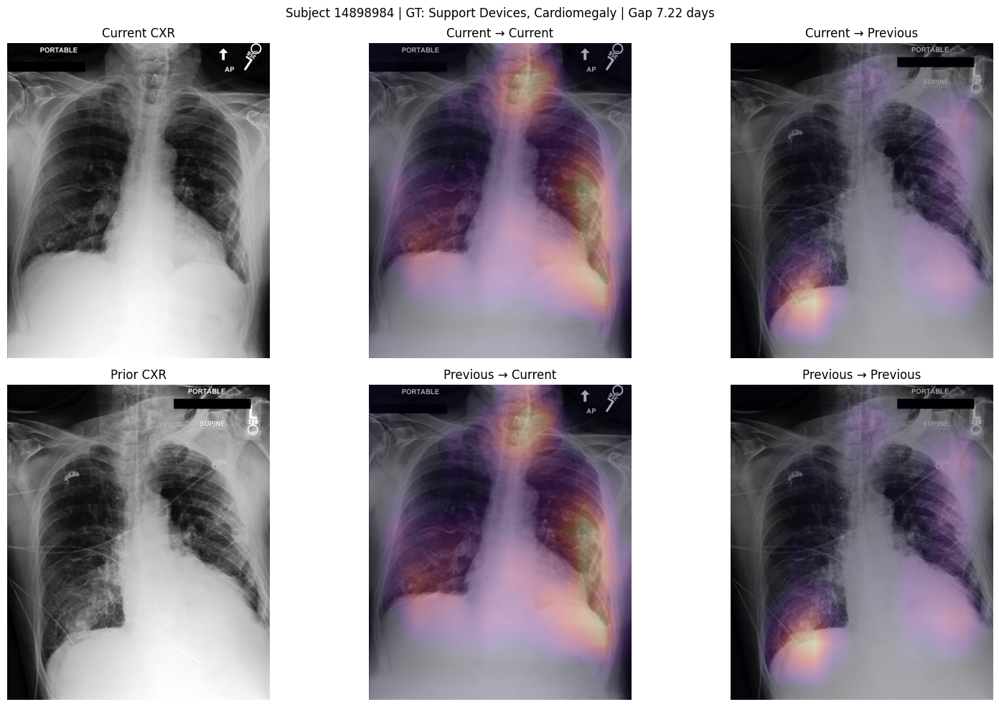


Sample           : 2/5
Subject ID       : 12330994
Prior Study ID   : 55026558
Current Study ID : 50229871
Prior DICOM ID   : 62674883-65d37d73-2e3e7b71-9c830c98-e0d1f1ae
Current DICOM ID : 69c94c0b-1cfc75c3-4ddde5e7-289e338d-43119870
Gap (days)       : 18.69
Prior Image      : 62674883-65d37d73-2e3e7b71-9c830c98-e0d1f1ae.jpg
Current Image    : 69c94c0b-1cfc75c3-4ddde5e7-289e338d-43119870.jpg
Report File      : s50229871.txt
Ground Truth     : Support Devices, No Finding
Impression       : Feeding tube tip is in the distal third of the esophagus
Temporal layers  : 3
Layer 0 shape    : (8, 392, 392)


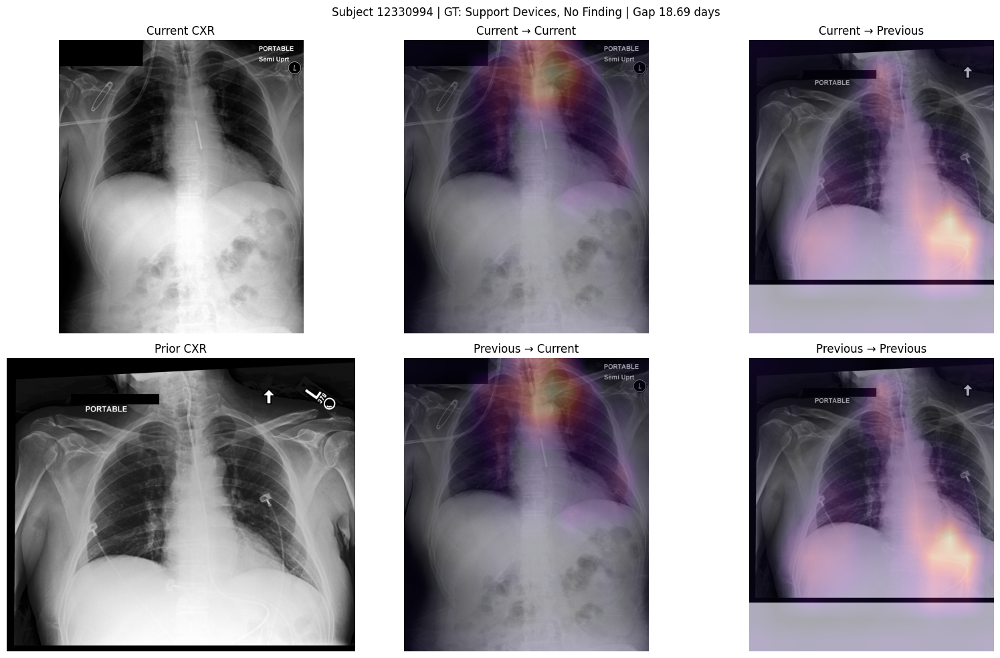


Sample           : 3/5
Subject ID       : 13185626
Prior Study ID   : 58850778
Current Study ID : 56995250
Prior DICOM ID   : 1f7e1ef2-f73ccc26-9d5b3361-77f94830-0b041376
Current DICOM ID : ff883efb-8c42cbe3-84762628-c3f0ad35-898f9605
Gap (days)       : 2.08
Prior Image      : 1f7e1ef2-f73ccc26-9d5b3361-77f94830-0b041376.jpg
Current Image    : ff883efb-8c42cbe3-84762628-c3f0ad35-898f9605.jpg
Report File      : s56995250.txt
Ground Truth     : Support Devices, Cardiomegaly
Impression       : Esophageal tube ends in the upper stomach and would need to be advanced 5 cm to move all side ports beyond the GE junction. Left PIC line ends in the upper SVC. Mild cardiomegaly is chronic. Lungs and pulmonary vasculature are unremarkable. There is no pleural abnormality
Temporal layers  : 3
Layer 0 shape    : (8, 392, 392)


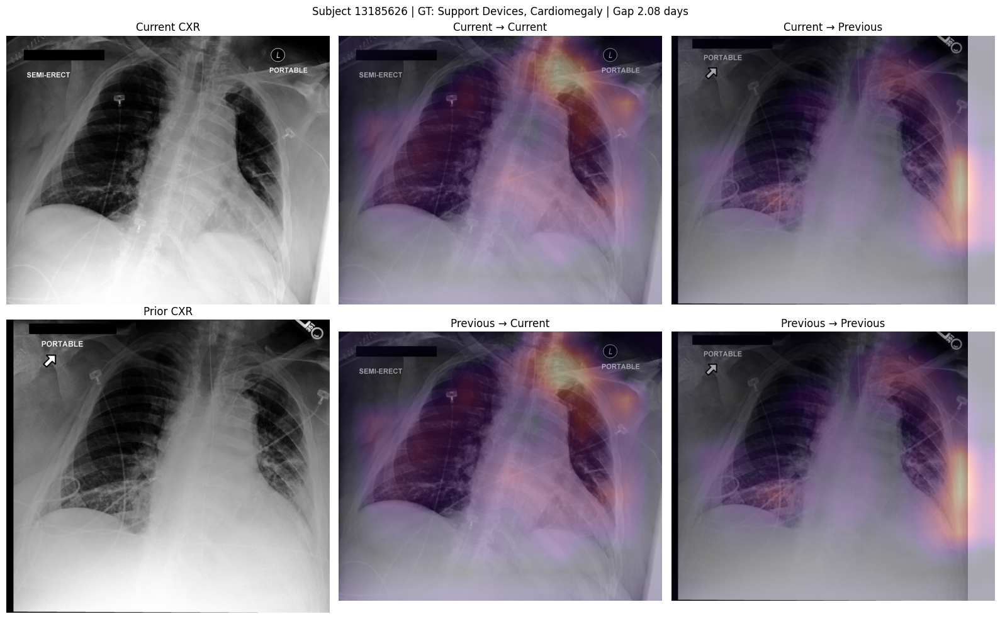


Sample           : 4/5
Subject ID       : 19817448
Prior Study ID   : 50587956
Current Study ID : 55080641
Prior DICOM ID   : 0cc2b062-724f6dec-e593681e-89b5cd9f-dba0114f
Current DICOM ID : 8c32facf-b25309a5-339c8251-4a9181a8-643fec9b
Gap (days)       : 2.17
Prior Image      : 0cc2b062-724f6dec-e593681e-89b5cd9f-dba0114f.jpg
Current Image    : 8c32facf-b25309a5-339c8251-4a9181a8-643fec9b.jpg
Report File      : s55080641.txt
Ground Truth     : Pneumothorax, Pleural Effusion, Support Devices
Impression       : Very small right apicolateral pneumothorax. Right pleural catheter in place. Interval improvement in right pleural effusion. The above findings were communicated to Dr. ___ by Dr. ___ ___ telephone at ___ on ___, 5 minutes after the discovery was made
Temporal layers  : 3
Layer 0 shape    : (8, 392, 392)


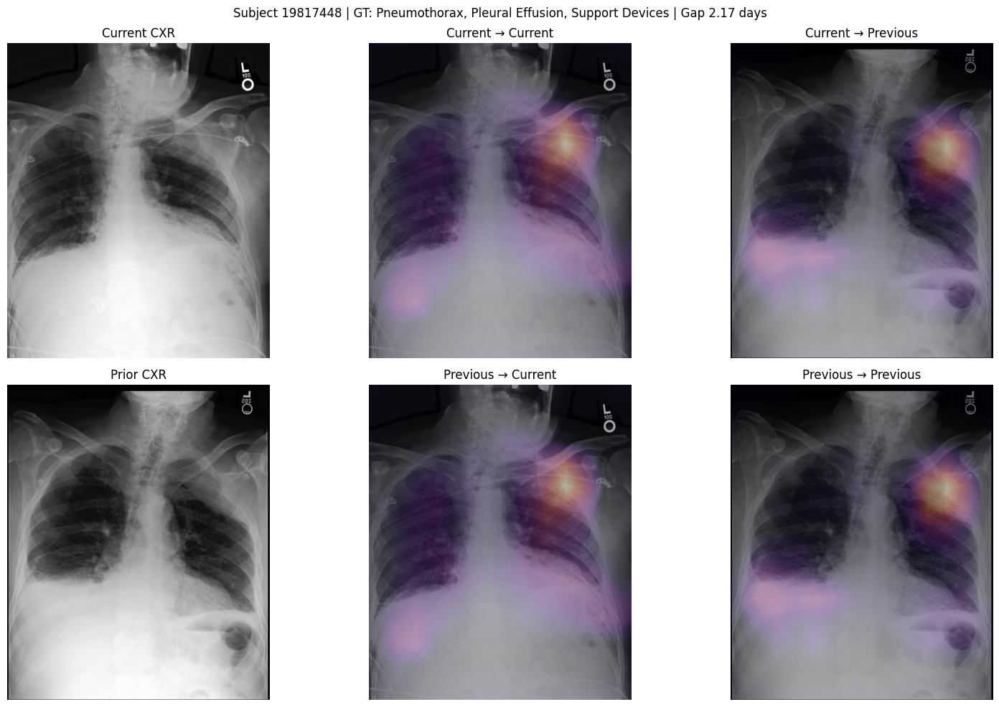


Sample           : 5/5
Subject ID       : 17018536
Prior Study ID   : 55693256
Current Study ID : 53930515
Prior DICOM ID   : 8cc19282-c1d73528-ae665186-cc02a4fb-142629ea
Current DICOM ID : a19e9578-10b80f5d-7d2a1109-5da41739-4e796c8e
Gap (days)       : 31.67
Prior Image      : 8cc19282-c1d73528-ae665186-cc02a4fb-142629ea.jpg
Current Image    : a19e9578-10b80f5d-7d2a1109-5da41739-4e796c8e.jpg
Report File      : s53930515.txt
Ground Truth     : Support Devices, Consolidation, Cardiomegaly, Edema
Impression       : AP chest compared to ___ at 10:58 a.m.: Right PIC line has been pulled back to the low SVC, ending just beyond right internal jugular line. ET tube and nasoenteric drainage tube are in standard placements respectively. Left lower lobe remains densely consolidated. Mild-to-moderate pulmonary edema ha...
Temporal layers  : 3
Layer 0 shape    : (8, 392, 392)


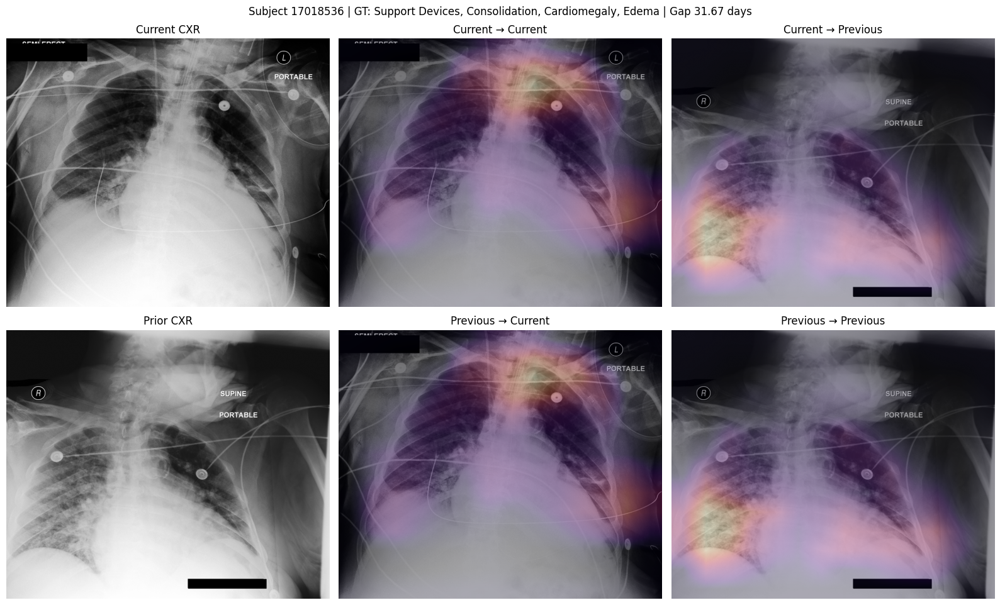

In [15]:
results = plot_random_temporal_attention_rollouts(
    temporal_chunk_paths,
    num_samples=5,
    seed=None,
)

/tmp/ipykernel_1619180/1150982480.py:19: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  prior_arr = torch.tensor(list(prior_img.getdata()), dtype=torch.float32).view(ph, pw) / 255.0
/tmp/ipykernel_1619180/1150982480.py:20: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  current_arr = torch.tensor(list(current_img.getdata()), dtype=torch.float32).view(ch, cw) / 255.0



Subject ID       : 10003400
Prior Study ID   : 53341253
Current Study ID : 50183258
Gap (days)       : 1.00
Ground Truth     : Pneumothorax, Pleural Effusion, Support Devices, Cardiomegaly, Atelectasis, Edema
Impression       : Large left pleural effusion has not changed over several days. Small to moderate residual right pleural effusion is also stable, despite the right thoracostomy tube. Tiny right apical pneumothorax is resolving. Moderate enlargement of the cardiac silhouette is stable, but pulmonary edema if present...


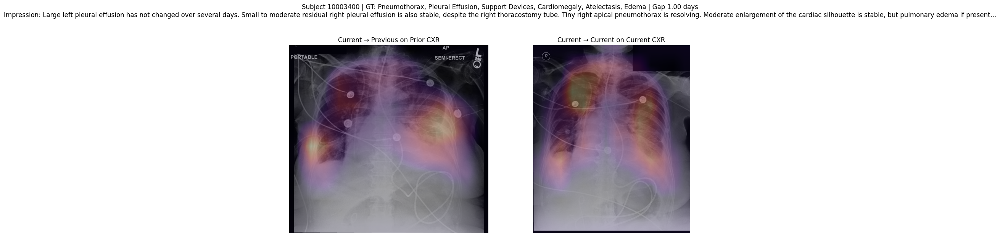

In [16]:
rollout = attention_rollout(temporal_attns, add_identity=True)[0]
quads = split_temporal_rollout(rollout)

ground_truth = []
if "labels" in chunk and chunk["labels"][sample_idx] is not None:
    ground_truth = [
        k for k, v in chunk["labels"][sample_idx].items()
        if float(v) == 1.0
    ]

overlay_two_rollouts(
    meta,
    quads,
    grid_size=14,
    ground_truth=ground_truth,
)

In [17]:
temporal_eval = evaluate_temporal_attention_rollout(
    temporal_chunk_paths,
    max_samples=100,
)
temporal_df = pd.DataFrame(temporal_eval)
temporal_df.head()

temporal_df[[
    "entropy_c2c", "entropy_c2p", "entropy_p2c", "entropy_p2p",
    "peak_c2c", "peak_c2p", "peak_p2c", "peak_p2p",
    "sparsity_c2c", "sparsity_c2p", "sparsity_p2c", "sparsity_p2p",
    "temporal_consistency_distance"
]].mean()

entropy_c2c                      4.782668
entropy_c2p                      4.725385
entropy_p2c                      4.784028
entropy_p2p                      4.730167
peak_c2c                         6.410897
peak_c2p                         7.163553
peak_p2c                         6.377933
peak_p2p                         7.097599
sparsity_c2c                     0.035816
sparsity_c2p                     0.033163
sparsity_p2c                     0.036224
sparsity_p2p                     0.033214
temporal_consistency_distance    4.619348
dtype: float64

# Spatial attention rollout

In [13]:
def run_spatial_rollout_for_samples(selected_single, single_chunk_paths):
    """
    Run spatial rollout on pre-selected samples instead of random ones.
    """
    # Build a lookup from (chunk_path, sample_idx) or image_path
    chunk_cache = {}
    results = []

    # Flatten all selected samples across pathologies
    all_selected = []
    for p, samples in selected_single.items():
        for s in samples:
            all_selected.append(s)

    # Deduplicate by image_path
    seen = set()
    unique_selected = []
    for s in all_selected:
        img_path = s["metadata"]["image_path"]
        if img_path not in seen:
            seen.add(img_path)
            unique_selected.append(s)

    for s in unique_selected:
        meta = s["metadata"]
        image_patch_proj = s["image_patch_proj"].float()
        text_emb = s["text_emb"].float()

        patch_emb = image_patch_proj / image_patch_proj.norm(
            dim=-1, keepdim=True
        ).clamp_min(1e-8)
        query_vec = text_emb / text_emb.norm(
            dim=-1, keepdim=True
        ).clamp_min(1e-8)

        sim = patch_emb @ query_vec
        grid_size = int(sim.numel() ** 0.5)
        heat = sim.view(grid_size, grid_size).detach().cpu()
        heat = heat - heat.min()
        heat = heat / (heat.max() + 1e-8)

        image = Image.open(meta["image_path"]).convert("L")
        w, h = image.size
        heat_up = F.interpolate(
            heat.unsqueeze(0).unsqueeze(0),
            size=(h, w),
            mode="bilinear",
            align_corners=False,
        )[0, 0]

        results.append({
            "metadata": meta,
            "ground_truth": get_positive_pathologies(s),
            "heatmap": heat,
            "heatmap_up": heat_up.detach().cpu(),
            "sample": s,
        })

    return results

In [14]:
def plot_random_spatial_attention_rollouts(
    single_chunk_paths,
    num_samples=5,
    seed=None,
    alpha=0.35,
    cmap="magma",
    impression_chars=300,
    token_query=None,
):
    rng = random.Random(seed)

    all_samples = []
    for chunk_path in single_chunk_paths:
        chunk = torch.load(chunk_path, map_location="cpu")
        for i in range(len(chunk["metadata"])):
            all_samples.append((chunk_path, i))

    if len(all_samples) == 0:
        raise ValueError("No single-image samples found.")

    chosen = rng.sample(all_samples, min(num_samples, len(all_samples)))
    results = []

    for n, (chunk_path, sample_idx) in enumerate(chosen, start=1):
        chunk = torch.load(chunk_path, map_location="cpu")

        meta = chunk["metadata"][sample_idx]
        image_patch_proj = chunk["image_patch_proj"][sample_idx].float()   # [196,128]
        text_emb = chunk["text_emb"][sample_idx].float()
        text_token_proj = chunk["text_token_proj"][sample_idx].float() if chunk["text_token_proj"][sample_idx] is not None else None
        tokens = chunk["tokens"][sample_idx]
        sample_labels = chunk["labels"][sample_idx]

        ground_truth = []
        if sample_labels is not None:
            ground_truth = [k for k, v in sample_labels.items() if float(v) == 1.0]

        report_text = meta.get("report_text", "") or ""
        report_text_clean = " ".join(str(report_text).split())

        impression = report_text_clean
        upper_text = str(report_text)
        if "IMPRESSION:" in upper_text.upper():
            start = upper_text.upper().find("IMPRESSION:")
            impression = upper_text[start + len("IMPRESSION:"):].strip()
            impression = " ".join(impression.split())

        if len(impression) > impression_chars:
            impression = impression[:impression_chars].rstrip() + "..."

        print("\n" + "=" * 80)
        print(f"Sample         : {n}/{len(chosen)}")
        print(f"Subject ID     : {meta.get('subject_id', 'N/A')}")
        print(f"Study ID       : {meta.get('study_id', 'N/A')}")
        print(f"DICOM ID       : {meta.get('dicom_id', 'N/A')}")
        print(f"Image          : {Path(meta['image_path']).name}")
        print(f"Report File    : {Path(meta['report_path']).name if meta.get('report_path') else 'N/A'}")
        print(f"Ground Truth   : {', '.join(ground_truth) if ground_truth else 'None / unavailable'}")
        print(f"Impression     : {impression}")

        patch_emb = image_patch_proj / image_patch_proj.norm(dim=-1, keepdim=True).clamp_min(1e-8)

        if token_query is None:
            query_vec = text_emb / text_emb.norm(dim=-1, keepdim=True).clamp_min(1e-8)
            map_type = "patch ↔ global report embedding"
        else:
            if text_token_proj is None or tokens is None:
                raise ValueError("token_query was provided, but text_token_proj or tokens is missing.")

            matched_indices = []
            q = token_query.lower()
            for i, tok in enumerate(tokens):
                tok_clean = str(tok).replace("##", "").lower()
                if q == tok_clean or q in tok_clean:
                    matched_indices.append(i)

            if len(matched_indices) == 0:
                raise ValueError(f"Token query '{token_query}' not found in sample tokens.")

            token_vec = text_token_proj[matched_indices].mean(dim=0)
            query_vec = token_vec / token_vec.norm(dim=-1, keepdim=True).clamp_min(1e-8)
            map_type = f"patch ↔ token embedding ('{token_query}')"

        print(f"Map Type       : {map_type}")
        print(f"Patch shape    : {tuple(image_patch_proj.shape)}")

        sim = patch_emb @ query_vec   # [196]
        grid_size = int(sim.numel() ** 0.5)
        if grid_size * grid_size != sim.numel():
            raise ValueError(f"Cannot reshape {sim.numel()} patch scores into square grid.")

        heat = sim.view(grid_size, grid_size).detach().cpu()
        heat = heat - heat.min()
        heat = heat / (heat.max() + 1e-8)

        image = Image.open(meta["image_path"]).convert("L")
        w, h = image.size
        image_arr = torch.tensor(list(image.getdata()), dtype=torch.float32).view(h, w) / 255.0

        heat_up = F.interpolate(
            heat.unsqueeze(0).unsqueeze(0),
            size=(h, w),
            mode="bilinear",
            align_corners=False,
        )[0, 0]

        plt.figure(figsize=(6, 6))
        plt.imshow(image_arr, cmap="gray")
        plt.imshow(heat_up, cmap=cmap, alpha=alpha)
        plt.title(
            f"Spatial Embedding Map\n"
            f"Subject {meta.get('subject_id', 'N/A')} | {map_type}"
        )
        plt.axis("off")
        plt.tight_layout()
        savefig("biovil_t/spatial_rollout", f"subject_{meta.get('subject_id', 'NA')}_spatial.png")
        plt.show()

        results.append({
            "chunk_path": chunk_path,
            "sample_idx": sample_idx,
            "metadata": meta,
            "ground_truth": ground_truth,
            "impression": impression,
            "heatmap": heat,
            "heatmap_up": heat_up.detach().cpu(),
            "token_query": token_query,
            "map_type": map_type,
        })

    return results

In [15]:
def overlay_spatial_rollout(
    meta,
    heatmap_up,
    alpha=0.35,
    cmap="magma",
    ground_truth=None,
    impression_chars=300,
    token_query=None,
):
    image = Image.open(meta["image_path"]).convert("L")
    w, h = image.size
    image_arr = torch.tensor(list(image.getdata()), dtype=torch.float32).view(h, w) / 255.0

    report_text = meta.get("report_text", "") or ""
    impression = " ".join(str(report_text).split())

    upper_text = str(report_text)
    if "IMPRESSION:" in upper_text.upper():
        start = upper_text.upper().find("IMPRESSION:")
        impression = upper_text[start + len("IMPRESSION:"):].strip()
        impression = " ".join(impression.split())

    if len(impression) > impression_chars:
        impression = impression[:impression_chars].rstrip() + "..."

    gt_text = ", ".join(ground_truth) if ground_truth else "None / unavailable"
    map_type = "patch ↔ global report embedding" if token_query is None else f"patch ↔ token embedding ('{token_query}')"

    print("\n" + "=" * 80)
    print(f"Subject ID     : {meta.get('subject_id', 'N/A')}")
    print(f"Study ID       : {meta.get('study_id', 'N/A')}")
    print(f"DICOM ID       : {meta.get('dicom_id', 'N/A')}")
    print(f"Image          : {Path(meta['image_path']).name}")
    print(f"Ground Truth   : {gt_text}")
    print(f"Impression     : {impression}")
    print(f"Map Type       : {map_type}")

    plt.figure(figsize=(6, 6))
    plt.imshow(image_arr, cmap="gray")
    plt.imshow(heatmap_up, cmap=cmap, alpha=alpha)
    plt.title(
        f"Spatial Embedding Map\n"
        f"Subject {meta.get('subject_id', 'N/A')} | "
        f"GT: {gt_text} | {map_type}"
    )
    plt.axis("off")
    plt.tight_layout()
    savefig("biovil_t/spatial_rollout", f"subject_{meta.get('subject_id', 'NA')}_spatial_overlay.png")
    plt.show()


Sample         : 1/5
Subject ID     : 17769322
Study ID       : 56459276
DICOM ID       : ae62d356-a46f69b9-55535cbd-3fdfe491-79889a1b
Image          : ae62d356-a46f69b9-55535cbd-3fdfe491-79889a1b.jpg
Report File    : s56459276.txt
Ground Truth   : Lung Opacity, No Finding, Support Devices
Impression     : No acute cardiopulmonary abnormality. Right-sided aortic arch
Map Type       : patch ↔ global report embedding
Patch shape    : (196, 128)


/tmp/ipykernel_1619180/3322543030.py:98: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  image_arr = torch.tensor(list(image.getdata()), dtype=torch.float32).view(h, w) / 255.0


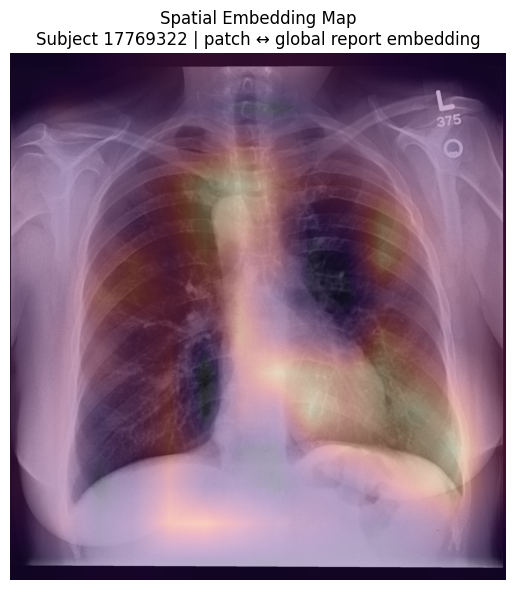


Sample         : 2/5
Subject ID     : 18047888
Study ID       : 50399167
DICOM ID       : a824103c-5c82ae84-da1ae3d7-0e65af2e-6031055b
Image          : a824103c-5c82ae84-da1ae3d7-0e65af2e-6031055b.jpg
Report File    : s50399167.txt
Ground Truth   : Cardiomegaly, Pleural Effusion
Impression     : In comparison with the study of ___, there has been re-accumulation of a moderate left pleural effusion following previous thoracentesis. The right lung is clear. Continued enlargement of the cardiac silhouette without vascular congestion. The right IJ catheter is been removed
Map Type       : patch ↔ global report embedding
Patch shape    : (196, 128)


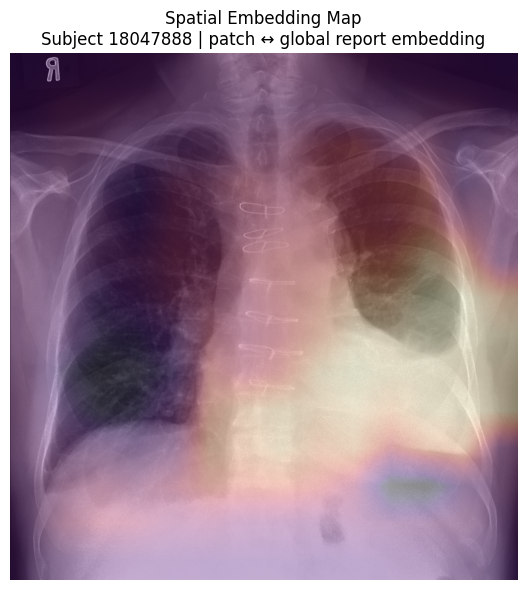


Sample         : 3/5
Subject ID     : 17742709
Study ID       : 51971233
DICOM ID       : 58f2d400-fa2b7b77-421feb87-74291cf1-c4d7ea35
Image          : 58f2d400-fa2b7b77-421feb87-74291cf1-c4d7ea35.jpg
Report File    : s51971233.txt
Ground Truth   : No Finding, Support Devices
Impression     : Right IJ central venous line terminating at the CA junction. No evidence of acute cardiopulmonary process
Map Type       : patch ↔ global report embedding
Patch shape    : (196, 128)


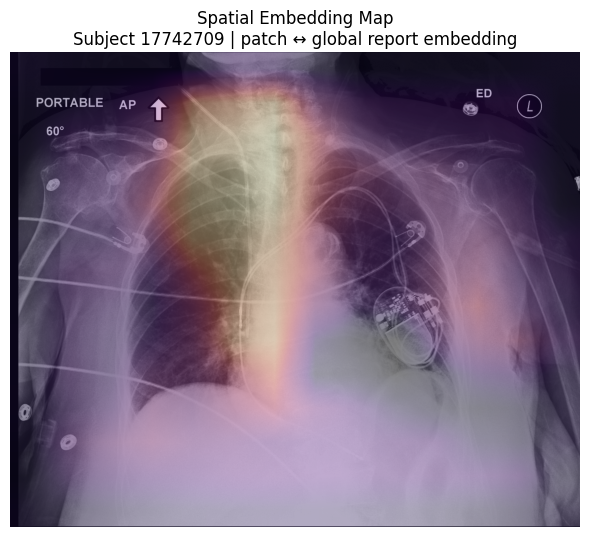


Sample         : 4/5
Subject ID     : 17555214
Study ID       : 58623720
DICOM ID       : f0924084-7fde1c46-0709acb5-8273482e-b9d7de1b
Image          : f0924084-7fde1c46-0709acb5-8273482e-b9d7de1b.jpg
Report File    : s58623720.txt
Ground Truth   : No Finding, Pneumothorax, Support Devices
Impression     : NG tube side port lies above the diaphragm, in the esophagus, and should be advanced
Map Type       : patch ↔ global report embedding
Patch shape    : (196, 128)


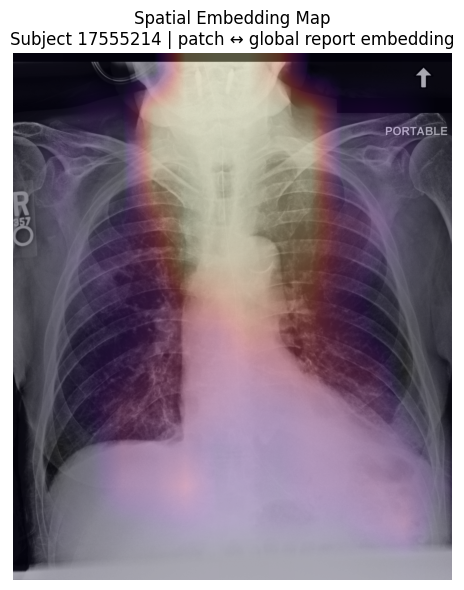


Sample         : 5/5
Subject ID     : 15124686
Study ID       : 56673947
DICOM ID       : b942033a-3805ffb7-90997a2d-725e615d-a77a67fc
Image          : b942033a-3805ffb7-90997a2d-725e615d-a77a67fc.jpg
Report File    : s56673947.txt
Ground Truth   : Consolidation, Pleural Effusion
Impression     : Improvement in left lower lobe consolidation and pleural effusion; follow-up imaging is recommended to ensure resolution
Map Type       : patch ↔ global report embedding
Patch shape    : (196, 128)


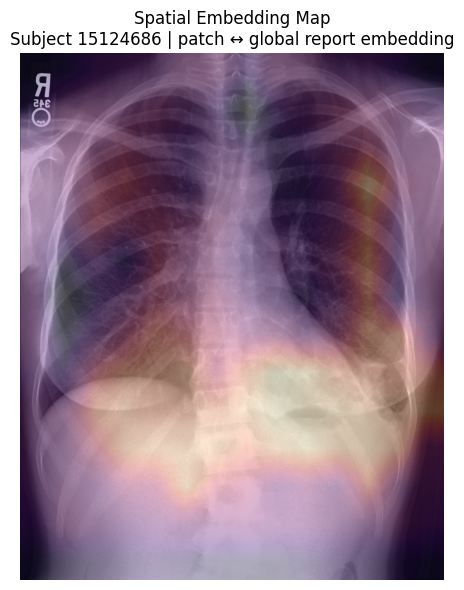

In [21]:
spatial_results = plot_random_spatial_attention_rollouts(
    single_chunk_paths,
    num_samples=5,
    seed=None,
    token_query=None,
)

/tmp/ipykernel_1619180/2832515832.py:12: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  image_arr = torch.tensor(list(image.getdata()), dtype=torch.float32).view(h, w) / 255.0



Subject ID     : 17769322
Study ID       : 56459276
DICOM ID       : ae62d356-a46f69b9-55535cbd-3fdfe491-79889a1b
Image          : ae62d356-a46f69b9-55535cbd-3fdfe491-79889a1b.jpg
Ground Truth   : Lung Opacity, No Finding, Support Devices
Impression     : No acute cardiopulmonary abnormality. Right-sided aortic arch
Map Type       : patch ↔ global report embedding


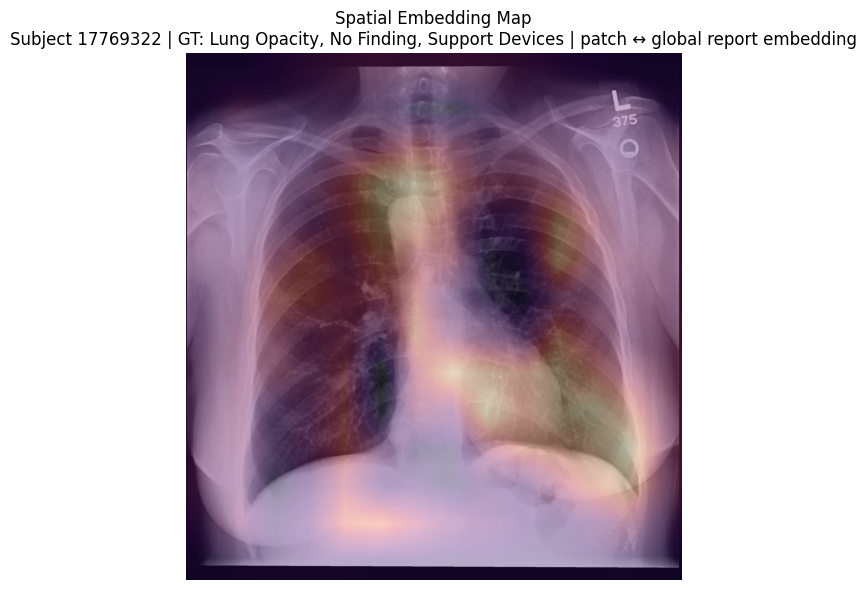

In [22]:
overlay_spatial_rollout(
    spatial_results[0]["metadata"],
    spatial_results[0]["heatmap_up"],
    ground_truth=spatial_results[0]["ground_truth"],
    token_query=spatial_results[0]["token_query"],
)

In [23]:
entropies = []
peaks = []
sparsities = []

for r in spatial_results:
    heat = r["heatmap"]

    entropies.append(heatmap_entropy(heat))
    peaks.append(peak_localisation_score(heat))
    sparsities.append(heatmap_sparsity(heat))

print("Spatial Attention Metrics")
print("------------------------")
print("Mean entropy:", sum(entropies) / len(entropies))
print("Mean peak localisation:", sum(peaks) / len(peaks))
print("Mean sparsity:", sum(sparsities) / len(sparsities))

Spatial Attention Metrics
------------------------
Mean entropy: 5.071939468383789
Mean peak localisation: 2.558142026562427
Mean sparsity: 0.1714285746216774


# Cross modal alignment

In [16]:
def plot_random_cross_modal_alignment_maps(
    single_chunk_paths,
    num_samples=5,
    seed=None,
    alpha=0.35,
    cmap="magma",
    impression_chars=300,
    token_query=None,
    phrase_tokens=None,
    normalize=True,
):
    rng = random.Random(seed)

    if token_query is not None and phrase_tokens is not None:
        raise ValueError("Use either token_query or phrase_tokens, not both.")

    all_samples = []
    for chunk_path in single_chunk_paths:
        chunk = torch.load(chunk_path, map_location="cpu")
        for i in range(len(chunk["metadata"])):
            all_samples.append((chunk_path, i))

    if len(all_samples) == 0:
        raise ValueError("No single-image samples found.")

    chosen = rng.sample(all_samples, min(num_samples, len(all_samples)))
    results = []

    for n, (chunk_path, sample_idx) in enumerate(chosen, start=1):
        chunk = torch.load(chunk_path, map_location="cpu")

        meta = chunk["metadata"][sample_idx]
        patch_proj = chunk["image_patch_proj"][sample_idx].float()         # [196,128]
        text_token_proj = chunk["text_token_proj"][sample_idx].float()     # [T,128]
        tokens = chunk["tokens"][sample_idx]
        attention_mask = chunk["attention_mask"][sample_idx]
        sample_labels = chunk["labels"][sample_idx]

        ground_truth = []
        if sample_labels is not None:
            ground_truth = [k for k, v in sample_labels.items() if float(v) == 1.0]

        report_text = meta.get("report_text", "") or ""
        report_text_clean = " ".join(str(report_text).split())

        impression = report_text_clean
        upper_text = str(report_text)
        if "IMPRESSION:" in upper_text.upper():
            start = upper_text.upper().find("IMPRESSION:")
            impression = upper_text[start + len("IMPRESSION:"):].strip()
            impression = " ".join(impression.split())

        if len(impression) > impression_chars:
            impression = impression[:impression_chars].rstrip() + "..."

        # choose token/phrase heatmap
        if phrase_tokens is not None:
            heat, matched_idxs = phrase_heatmap(
                patch_proj=patch_proj,
                text_token_proj=text_token_proj,
                tokens=tokens,
                phrase_tokens=phrase_tokens,
                attention_mask=attention_mask,
                normalize=normalize,
                reduce="mean",
            )
            chosen_label = " ".join(phrase_tokens)
            map_type = f"phrase ↔ patch alignment ('{chosen_label}')"
        else:
            if token_query is None:
                valid_tokens = [
                    tok for tok, keep in zip(tokens, attention_mask.tolist())
                    if keep
                ]
                ignore = {"[CLS]", "[SEP]", "[PAD]"}
                candidate_idx = None
                for i, tok in enumerate(valid_tokens):
                    tok_clean = str(tok).strip()
                    if tok_clean not in ignore and tok_clean.isalpha():
                        candidate_idx = i
                        break
                if candidate_idx is None:
                    raise ValueError("Could not automatically choose a valid token.")
                heat, chosen_token = token_heatmap(
                    patch_proj=patch_proj,
                    text_token_proj=text_token_proj,
                    tokens=tokens,
                    token_index=candidate_idx,
                    attention_mask=attention_mask,
                    normalize=normalize,
                )
            else:
                valid_tokens = [
                    tok for tok, keep in zip(tokens, attention_mask.tolist())
                    if keep
                ]

                matched_idx = None
                q = token_query.lower()
                for i, tok in enumerate(valid_tokens):
                    tok_clean = str(tok).replace("##", "").lower()
                    if q == tok_clean or q in tok_clean:
                        matched_idx = i
                        break

                if matched_idx is None:
                    raise ValueError(f"Token query '{token_query}' not found in valid tokens.")

                heat, chosen_token = token_heatmap(
                    patch_proj=patch_proj,
                    text_token_proj=text_token_proj,
                    tokens=tokens,
                    token_index=matched_idx,
                    attention_mask=attention_mask,
                    normalize=normalize,
                )

            chosen_label = chosen_token
            map_type = f"token ↔ patch alignment ('{chosen_label}')"

        heat = heat.detach().cpu()
        heat = heat - heat.min()
        heat = heat / (heat.max() + 1e-8)

        image = Image.open(meta["image_path"]).convert("L")
        w, h = image.size
        image_arr = torch.tensor(list(image.getdata()), dtype=torch.float32).view(h, w) / 255.0

        heat_up = F.interpolate(
            heat.unsqueeze(0).unsqueeze(0),
            size=(h, w),
            mode="bilinear",
            align_corners=False,
        )[0, 0]

        print("\n" + "=" * 80)
        print(f"Sample         : {n}/{len(chosen)}")
        print(f"Subject ID     : {meta.get('subject_id', 'N/A')}")
        print(f"Study ID       : {meta.get('study_id', 'N/A')}")
        print(f"DICOM ID       : {meta.get('dicom_id', 'N/A')}")
        print(f"Image          : {Path(meta['image_path']).name}")
        print(f"Report File    : {Path(meta['report_path']).name if meta.get('report_path') else 'N/A'}")
        print(f"Ground Truth   : {', '.join(ground_truth) if ground_truth else 'None / unavailable'}")
        print(f"Impression     : {impression}")
        print(f"Map Type       : {map_type}")
        print(f"Patch shape    : {tuple(patch_proj.shape)}")
        print(f"Token shape    : {tuple(text_token_proj.shape)}")

        plt.figure(figsize=(6, 6))
        plt.imshow(image_arr, cmap="gray")
        plt.imshow(heat_up, cmap=cmap, alpha=alpha)
        plt.title(
            f"Cross-Modal Alignment Map\n"
            f"Subject {meta.get('subject_id', 'N/A')} | {map_type}"
        )
        plt.axis("off")
        plt.tight_layout()
        savefig(
        "biovil_t/cross_modal",
        f"subject_{meta.get('subject_id', 'NA')}_{chosen_label}_cross_modal.png"
    )
        plt.show()

        results.append({
            "chunk_path": chunk_path,
            "sample_idx": sample_idx,
            "metadata": meta,
            "ground_truth": ground_truth,
            "impression": impression,
            "chosen_label": chosen_label,
            "map_type": map_type,
            "heatmap": heat,
            "heatmap_up": heat_up.detach().cpu(),
        })

    return results

In [17]:
def plot_random_temporal_cross_modal_alignment_maps(
    temporal_chunk_paths,
    num_samples=5,
    seed=None,
    alpha=0.35,
    cmap="magma",
    impression_chars=300,
    token_query=None,
    phrase_tokens=None,
    normalize=True,
    patch_proj_key="current_patch_proj",
):
    rng = random.Random(seed)

    if token_query is not None and phrase_tokens is not None:
        raise ValueError("Use either token_query or phrase_tokens, not both.")

    all_samples = []
    for chunk_path in temporal_chunk_paths:
        chunk = torch.load(chunk_path, map_location="cpu")
        for i in range(len(chunk["metadata"])):
            all_samples.append((chunk_path, i))

    if len(all_samples) == 0:
        raise ValueError("No temporal samples found.")

    chosen = rng.sample(all_samples, min(num_samples, len(all_samples)))
    results = []

    for n, (chunk_path, sample_idx) in enumerate(chosen, start=1):
        chunk = torch.load(chunk_path, map_location="cpu")

        meta = chunk["metadata"][sample_idx]
        patch_proj = chunk[patch_proj_key][sample_idx].float()
        text_token_proj = chunk["text_token_proj"][sample_idx].float()
        tokens = chunk["tokens"][sample_idx]
        attention_mask = chunk["attention_mask"][sample_idx]
        sample_labels = chunk["labels"][sample_idx] if "labels" in chunk else None

        ground_truth = []
        if sample_labels is not None:
            ground_truth = [k for k, v in sample_labels.items() if float(v) == 1.0]

        report_text = meta.get("current_report_text", "") or ""
        report_text_clean = " ".join(str(report_text).split())

        impression = report_text_clean
        upper_text = str(report_text)
        if "IMPRESSION:" in upper_text.upper():
            start = upper_text.upper().find("IMPRESSION:")
            impression = upper_text[start + len("IMPRESSION:"):].strip()
            impression = " ".join(impression.split())
        if len(impression) > impression_chars:
            impression = impression[:impression_chars].rstrip() + "..."

        # Build heatmap
        valid_tokens = [tok for tok, keep in zip(tokens, attention_mask.tolist()) if keep]

        if phrase_tokens is not None:
            try:
                heat, matched_idxs = phrase_heatmap(
                    patch_proj=patch_proj,
                    text_token_proj=text_token_proj,
                    tokens=tokens,
                    phrase_tokens=phrase_tokens,
                    attention_mask=attention_mask,
                    normalize=normalize,
                    reduce="mean",
                )
                chosen_label = " ".join(phrase_tokens)
                map_type = f"phrase ↔ patch alignment ('{chosen_label}')"
            except ValueError:
                continue
        else:
            if token_query is not None:
                matched_idx = None
                q = token_query.lower()
                for i, tok in enumerate(valid_tokens):
                    tok_clean = str(tok).replace("##", "").lower()
                    if q == tok_clean or q in tok_clean:
                        matched_idx = i
                        break
                if matched_idx is None:
                    continue
            else:
                ignore = {"[CLS]", "[SEP]", "[PAD]"}
                matched_idx = None
                for i, tok in enumerate(valid_tokens):
                    tok_clean = str(tok).strip()
                    if tok_clean not in ignore and tok_clean.isalpha():
                        matched_idx = i
                        break
                if matched_idx is None:
                    continue

            heat, chosen_token = token_heatmap(
                patch_proj=patch_proj,
                text_token_proj=text_token_proj,
                tokens=tokens,
                token_index=matched_idx,
                attention_mask=attention_mask,
                normalize=normalize,
            )
            chosen_label = chosen_token
            map_type = f"token ↔ patch alignment ('{chosen_label}')"

        heat = heat.detach().cpu()
        heat = heat - heat.min()
        heat = heat / (heat.max() + 1e-8)

        image = Image.open(meta["current_image_path"]).convert("L")
        w, h = image.size
        image_arr = np.array(image).astype(np.float32) / 255.0

        heat_up = F.interpolate(
            heat.unsqueeze(0).unsqueeze(0),
            size=(h, w),
            mode="bilinear",
            align_corners=False,
        )[0, 0]

        print("\n" + "=" * 80)
        print(f"Sample         : {n}/{len(chosen)}")
        print(f"Subject ID     : {meta.get('subject_id', 'N/A')}")
        print(f"Current Study  : {meta.get('current_study_id', 'N/A')}")
        print(f"Prior Study    : {meta.get('prior_study_id', 'N/A')}")
        print(f"Current Image  : {Path(meta['current_image_path']).name}")
        print(f"Ground Truth   : {', '.join(ground_truth) if ground_truth else 'None'}")
        print(f"Impression     : {impression}")
        print(f"Map Type       : {map_type}")

        plt.figure(figsize=(6, 6))
        plt.imshow(image_arr, cmap="gray")
        plt.imshow(heat_up.numpy(), cmap=cmap, alpha=alpha)
        plt.title(
            f"Temporal Cross-Modal Alignment\n"
            f"Subject {meta.get('subject_id', 'N/A')} | {map_type}"
        )
        plt.axis("off")
        plt.tight_layout()
        savefig(
        "biovil_t/cross_modal",
        f"subject_{meta.get('subject_id', 'NA')}_{chosen_label}_cross_modal_temporal.png"
    )
        plt.show()

        results.append({
            "chunk_path": chunk_path,
            "sample_idx": sample_idx,
            "metadata": meta,
            "ground_truth": ground_truth,
            "impression": impression,
            "chosen_label": chosen_label,
            "map_type": map_type,
            "heatmap": heat,
            "heatmap_up": heat_up.detach().cpu(),
        })

    return results

In [18]:
def overlay_cross_modal_attention(
    meta,
    heatmap_up,
    chosen_label,
    alpha=0.35,
    cmap="magma",
    ground_truth=None,
    impression_chars=300,
    map_type_prefix="cross-modal alignment",
):
    image = Image.open(meta["image_path"]).convert("L")
    w, h = image.size
    image_arr = torch.tensor(list(image.getdata()), dtype=torch.float32).view(h, w) / 255.0

    report_text = meta.get("report_text", "") or ""
    impression = " ".join(str(report_text).split())

    upper_text = str(report_text)
    if "IMPRESSION:" in upper_text.upper():
        start = upper_text.upper().find("IMPRESSION:")
        impression = upper_text[start + len("IMPRESSION:"):].strip()
        impression = " ".join(impression.split())

    if len(impression) > impression_chars:
        impression = impression[:impression_chars].rstrip() + "..."

    gt_text = ", ".join(ground_truth) if ground_truth else "None / unavailable"

    print("\n" + "=" * 80)
    print(f"Subject ID     : {meta.get('subject_id', 'N/A')}")
    print(f"Study ID       : {meta.get('study_id', 'N/A')}")
    print(f"DICOM ID       : {meta.get('dicom_id', 'N/A')}")
    print(f"Image          : {Path(meta['image_path']).name}")
    print(f"Ground Truth   : {gt_text}")
    print(f"Impression     : {impression}")
    print(f"Chosen Label   : {chosen_label}")

    plt.figure(figsize=(6, 6))
    plt.imshow(image_arr, cmap="gray")
    plt.imshow(heatmap_up, cmap=cmap, alpha=alpha)
    plt.title(
        f"Cross-Modal Alignment Map\n"
        f"Subject {meta.get('subject_id', 'N/A')} | "
        f"GT: {gt_text} | {chosen_label}"
    )
    plt.axis("off")
    plt.tight_layout()
    savefig(
    "biovil_t/cross_modal",
    f"subject_{meta.get('subject_id', 'NA')}_{chosen_label}_cross_modal_overlay.png"
)
    plt.show()

In [19]:
def evaluate_cross_modal_alignment(
    single_chunk_paths,
    token_queries=("effusion", "cardiomegaly", "pneumothorax"),
    max_samples=None,
):
    rows = []
    seen = 0

    for chunk_path in single_chunk_paths:
        chunk = torch.load(chunk_path, map_location="cpu")

        for sample_idx in range(len(chunk["metadata"])):
            meta = chunk["metadata"][sample_idx]
            patch_proj = chunk["image_patch_proj"][sample_idx].float()         # [196,128]
            text_token_proj = chunk["text_token_proj"][sample_idx].float()
            tokens = chunk["tokens"][sample_idx]
            attention_mask = chunk["attention_mask"][sample_idx]
            sample_labels = chunk["labels"][sample_idx]

            ground_truth = []
            if sample_labels is not None:
                ground_truth = [k for k, v in sample_labels.items() if float(v) == 1.0]

            for token_query in token_queries:
                valid_tokens = [
                    tok for tok, keep in zip(tokens, attention_mask.tolist())
                    if keep
                ]

                matched_idx = None
                q = token_query.lower()
                for i, tok in enumerate(valid_tokens):
                    tok_clean = str(tok).replace("##", "").lower()
                    if q == tok_clean or q in tok_clean:
                        matched_idx = i
                        break

                if matched_idx is None:
                    continue

                heat, chosen_token = token_heatmap(
                    patch_proj=patch_proj,
                    text_token_proj=text_token_proj,
                    tokens=tokens,
                    token_index=matched_idx,
                    attention_mask=attention_mask,
                    normalize=True,
                )

                heat = heat.detach().cpu()
                loc = top_patch_location(heat)

                rows.append({
                    "subject_id": meta.get("subject_id"),
                    "study_id": meta.get("study_id"),
                    "dicom_id": meta.get("dicom_id"),
                    "token_query": token_query,
                    "chosen_token": chosen_token,
                    "ground_truth": ground_truth,

                    "entropy": heatmap_entropy(heat),
                    "peak_score": peak_localisation_score(heat),
                    "sparsity": heatmap_sparsity(heat),
                    "top_row": loc[0],
                    "top_col": loc[1],
                })

            seen += 1
            if max_samples is not None and seen >= max_samples:
                return rows

    return rows

In [20]:
def evaluate_cross_modal_phrases(
    single_chunk_paths,
    phrase_queries=(["pleural", "effusion"], ["enlarged", "heart"]),
    max_samples=None,
):
    rows = []
    seen = 0

    for chunk_path in single_chunk_paths:
        chunk = torch.load(chunk_path, map_location="cpu")

        for sample_idx in range(len(chunk["metadata"])):
            meta = chunk["metadata"][sample_idx]
            patch_proj = chunk["image_patch_proj"][sample_idx].float()
            text_token_proj = chunk["text_token_proj"][sample_idx].float()
            tokens = chunk["tokens"][sample_idx]
            attention_mask = chunk["attention_mask"][sample_idx]

            for phrase_tokens in phrase_queries:
                try:
                    heat, idxs = phrase_heatmap(
                        patch_proj=patch_proj,
                        text_token_proj=text_token_proj,
                        tokens=tokens,
                        phrase_tokens=phrase_tokens,
                        attention_mask=attention_mask,
                        normalize=True,
                        reduce="mean",
                    )
                except ValueError:
                    continue

                heat = heat.detach().cpu()
                loc = top_patch_location(heat)

                rows.append({
                    "subject_id": meta.get("subject_id"),
                    "study_id": meta.get("study_id"),
                    "phrase": " ".join(phrase_tokens),
                    "entropy": heatmap_entropy(heat),
                    "peak_score": peak_localisation_score(heat),
                    "sparsity": heatmap_sparsity(heat),
                    "top_row": loc[0],
                    "top_col": loc[1],
                })

            seen += 1
            if max_samples is not None and seen >= max_samples:
                return rows

    return rows

In [21]:
def show_topk_tokens_for_patch(
    patch_proj: torch.Tensor,
    text_token_proj: torch.Tensor,
    tokens: list[str],
    patch_row: int,
    patch_col: int,
    attention_mask: torch.Tensor | None = None,
    k: int = 10,
    normalize: bool = True,
) -> pd.DataFrame:
    rows = topk_tokens_for_patch(
        patch_proj=patch_proj,
        text_token_proj=text_token_proj,
        tokens=tokens,
        patch_row=patch_row,
        patch_col=patch_col,
        attention_mask=attention_mask,
        k=k,
        normalize=normalize,
    )
    return pd.DataFrame(rows)

In [22]:
def show_topk_patches_for_token(
    patch_proj: torch.Tensor,
    text_token_proj: torch.Tensor,
    tokens: list[str],
    token_index: int,
    attention_mask: torch.Tensor | None = None,
    k: int = 10,
    normalize: bool = True,
) -> pd.DataFrame:
    rows = topk_patches_for_token(
        patch_proj=patch_proj,
        text_token_proj=text_token_proj,
        tokens=tokens,
        token_index=token_index,
        attention_mask=attention_mask,
        k=k,
        normalize=normalize,
    )
    return pd.DataFrame(rows)

In [23]:
def plot_patch_location_on_image(
    image_path: str,
    patch_row: int,
    patch_col: int,
    grid_size: int = 14,
    figsize=(6, 6),
):
    image = Image.open(image_path).convert("L")
    w, h = image.size

    patch_h = h / grid_size
    patch_w = w / grid_size

    y0 = patch_row * patch_h
    x0 = patch_col * patch_w

    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(image, cmap="gray")
    rect = plt.Rectangle(
        (x0, y0),
        patch_w,
        patch_h,
        fill=False,
        linewidth=2,
    )
    ax.add_patch(rect)
    ax.set_title(f"Patch ({patch_row}, {patch_col})")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

In [24]:
def inspect_cross_modal_alignment_sample(
    chunk_path,
    sample_idx: int,
    token_query: str | None = None,
    phrase_tokens: list[str] | None = None,
    normalize: bool = True,
    alpha: float = 0.35,
    cmap: str = "magma",
    k: int = 10,
):
    if token_query is not None and phrase_tokens is not None:
        raise ValueError("Use either token_query or phrase_tokens, not both.")

    chunk = torch.load(chunk_path, map_location="cpu")

    meta = chunk["metadata"][sample_idx]
    patch_proj = chunk["image_patch_proj"][sample_idx].float()
    text_token_proj = chunk["text_token_proj"][sample_idx].float()
    tokens = chunk["tokens"][sample_idx]
    attention_mask = chunk["attention_mask"][sample_idx]
    sample_labels = chunk["labels"][sample_idx]

    ground_truth = []
    if sample_labels is not None:
        ground_truth = [k for k, v in sample_labels.items() if float(v) == 1.0]

    valid_tokens = [
        tok for tok, keep in zip(tokens, attention_mask.tolist())
        if keep
    ]

    if phrase_tokens is not None:
        heat, idxs = phrase_heatmap(
            patch_proj=patch_proj,
            text_token_proj=text_token_proj,
            tokens=tokens,
            phrase_tokens=phrase_tokens,
            attention_mask=attention_mask,
            normalize=normalize,
            reduce="mean",
        )
        chosen_label = " ".join(phrase_tokens)
        selected_token_indices = idxs
    else:
        if token_query is None:
            ignore = {"[CLS]", "[SEP]", "[PAD]"}
            matched_idx = None
            for i, tok in enumerate(valid_tokens):
                tok_clean = str(tok).replace("##", "").lower()
                if tok_clean not in {x.lower() for x in ignore} and tok_clean.isalpha():
                    matched_idx = i
                    break
            if matched_idx is None:
                raise ValueError("Could not automatically choose a valid token.")
        else:
            matched_idx = None
            q = token_query.lower()
            for i, tok in enumerate(valid_tokens):
                tok_clean = str(tok).replace("##", "").lower()
                if q == tok_clean or q in tok_clean:
                    matched_idx = i
                    break
            if matched_idx is None:
                raise ValueError(f"Token query '{token_query}' not found.")

        heat, chosen_token = token_heatmap(
            patch_proj=patch_proj,
            text_token_proj=text_token_proj,
            tokens=tokens,
            token_index=matched_idx,
            attention_mask=attention_mask,
            normalize=normalize,
        )
        chosen_label = chosen_token
        selected_token_indices = [matched_idx]

    heat = heat.detach().cpu()
    heat = heat - heat.min()
    heat = heat / (heat.max() + 1e-8)

    image = Image.open(meta["image_path"]).convert("L")
    w, h = image.size
    image_arr = torch.tensor(list(image.getdata()), dtype=torch.float32).view(h, w) / 255.0

    heat_up = F.interpolate(
        heat.unsqueeze(0).unsqueeze(0),
        size=(h, w),
        mode="bilinear",
        align_corners=False,
    )[0, 0]

    flat_idx = int(heat.reshape(-1).argmax().item())
    grid_h, grid_w = heat.shape
    top_row = flat_idx // grid_w
    top_col = flat_idx % grid_w

    print("\n" + "=" * 80)
    print(f"Subject ID   : {meta.get('subject_id', 'N/A')}")
    print(f"Study ID     : {meta.get('study_id', 'N/A')}")
    print(f"DICOM ID     : {meta.get('dicom_id', 'N/A')}")
    print(f"Image        : {Path(meta['image_path']).name}")
    print(f"Ground Truth : {', '.join(ground_truth) if ground_truth else 'None / unavailable'}")
    print(f"Chosen Label : {chosen_label}")
    print(f"Top Patch    : ({top_row}, {top_col})")

    plt.figure(figsize=(6, 6))
    plt.imshow(image_arr, cmap="gray")
    plt.imshow(heat_up, cmap=cmap, alpha=alpha)
    plt.title(f"Cross-Modal Alignment: {chosen_label}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    plot_patch_location_on_image(
        image_path=meta["image_path"],
        patch_row=top_row,
        patch_col=top_col,
        grid_size=heat.shape[0],
    )

    token_table = show_topk_tokens_for_patch(
        patch_proj=patch_proj,
        text_token_proj=text_token_proj,
        tokens=tokens,
        patch_row=top_row,
        patch_col=top_col,
        attention_mask=attention_mask,
        k=k,
        normalize=normalize,
    )

    patch_tables = {}
    for token_idx in selected_token_indices:
        patch_tables[token_idx] = show_topk_patches_for_token(
            patch_proj=patch_proj,
            text_token_proj=text_token_proj,
            tokens=tokens,
            token_index=token_idx,
            attention_mask=attention_mask,
            k=k,
            normalize=normalize,
        )

    return {
        "metadata": meta,
        "ground_truth": ground_truth,
        "chosen_label": chosen_label,
        "heatmap": heat,
        "heatmap_up": heat_up.detach().cpu(),
        "top_patch_row": top_row,
        "top_patch_col": top_col,
        "top_tokens_for_patch_df": token_table,
        "top_patches_for_selected_tokens": patch_tables,
    }

/tmp/ipykernel_1619180/3230111963.py:127: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  image_arr = torch.tensor(list(image.getdata()), dtype=torch.float32).view(h, w) / 255.0



Sample         : 1/5
Subject ID     : 12410764
Study ID       : 55151770
DICOM ID       : 0827542e-72e3d380-2c026f3a-eb8f37b1-560ff713
Image          : 0827542e-72e3d380-2c026f3a-eb8f37b1-560ff713.jpg
Report File    : s55151770.txt
Ground Truth   : Cardiomegaly, No Finding
Impression     : No acute cardiopulmonary process. Mild cardiomegaly
Map Type       : token ↔ patch alignment ('final')
Patch shape    : (196, 128)
Token shape    : (214, 128)


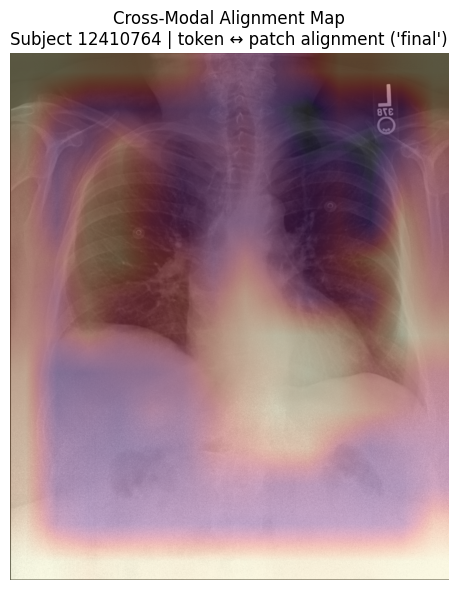


Sample         : 2/5
Subject ID     : 10541043
Study ID       : 50169121
DICOM ID       : 7fe8144e-7ca26330-27b57e6d-416770e8-30178d1b
Image          : 7fe8144e-7ca26330-27b57e6d-416770e8-30178d1b.jpg
Report File    : s50169121.txt
Ground Truth   : Cardiomegaly, Support Devices
Impression     : Right trans subclavian pacer leads follow their expected courses from the right pectoral generator. No pneumothorax, mediastinal widening, or pleural effusion. Cardiac silhouette is moderately enlarged due to cardiomegaly and/or pericardial effusion. There is no mediastinal venous engorgement to sug...
Map Type       : token ↔ patch alignment ('final')
Patch shape    : (196, 128)
Token shape    : (161, 128)


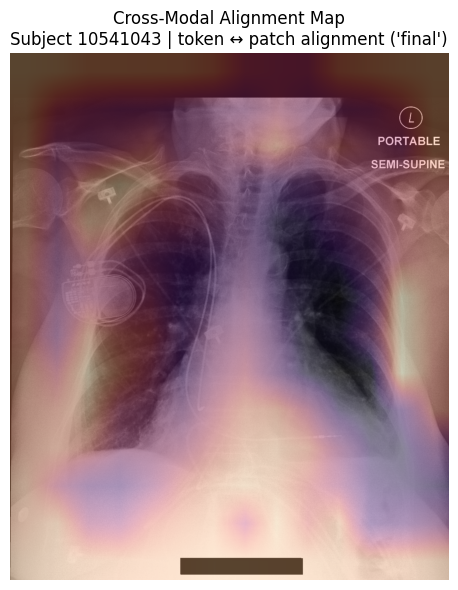


Sample         : 3/5
Subject ID     : 16199548
Study ID       : 51470102
DICOM ID       : b646a009-e30b47a7-b50de104-c7325b3a-2ce490a3
Image          : b646a009-e30b47a7-b50de104-c7325b3a-2ce490a3.jpg
Report File    : s51470102.txt
Ground Truth   : Cardiomegaly
Impression     : Possible minimal central pulmonary vascular engorgement without overt pulmonary edema. Persistent enlargement of the cardiac silhouette
Map Type       : token ↔ patch alignment ('final')
Patch shape    : (196, 128)
Token shape    : (257, 128)


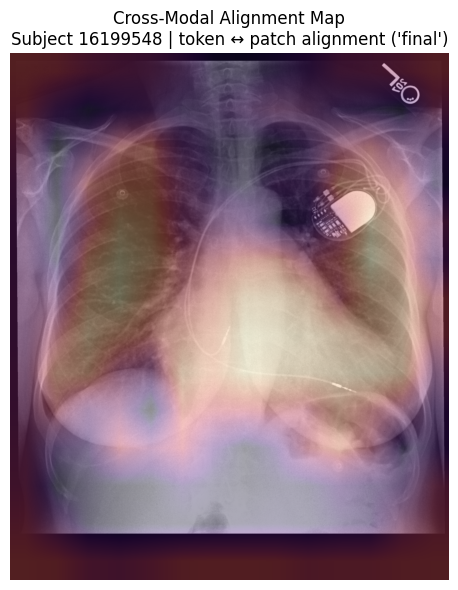


Sample         : 4/5
Subject ID     : 15514336
Study ID       : 56866308
DICOM ID       : 22cf2714-867f44d8-c14b69fa-360e57f9-8aeb9b71
Image          : 22cf2714-867f44d8-c14b69fa-360e57f9-8aeb9b71.jpg
Report File    : s56866308.txt
Ground Truth   : Atelectasis, Edema, Lung Opacity, Pleural Effusion, Support Devices
Impression     : 1. No evidence of subdiaphragmatic free air, however, this is not an upright film and therefore has a lower sensitivity for abdominal free-air. If there is further clinical concern, an upright or decubitus view of the abdomen would be more sensitive. 2. Unchanged mild bilateral pulmonary edema
Map Type       : token ↔ patch alignment ('final')
Patch shape    : (196, 128)
Token shape    : (232, 128)


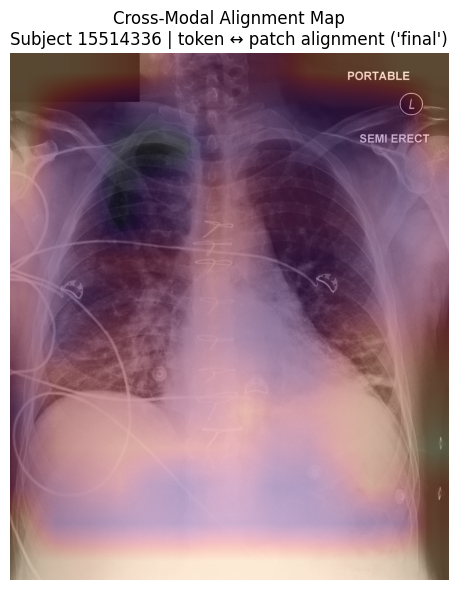


Sample         : 5/5
Subject ID     : 15020654
Study ID       : 54698051
DICOM ID       : b8ce7ad4-0fd47e70-53524f08-586d1f53-09639934
Image          : b8ce7ad4-0fd47e70-53524f08-586d1f53-09639934.jpg
Report File    : s54698051.txt
Ground Truth   : Cardiomegaly, Edema, Pleural Effusion
Impression     : Interval progression of the right-sided pleural effusion, now moderate to large in size
Map Type       : token ↔ patch alignment ('final')
Patch shape    : (196, 128)
Token shape    : (166, 128)


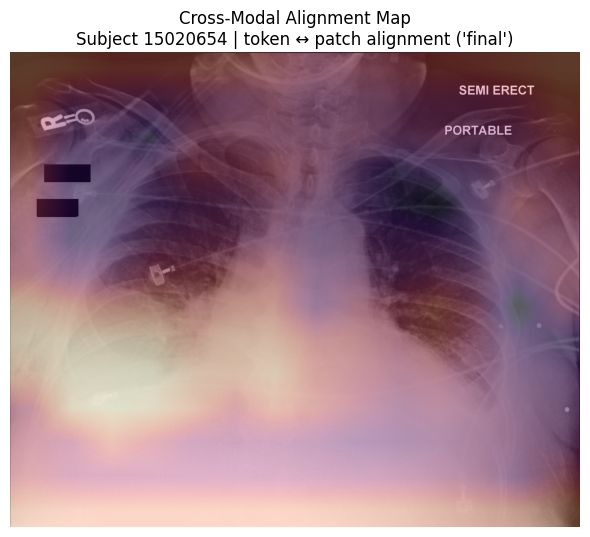

[{'chunk_path': PosixPath('/scratch/mtm211/embeddings/biovil_t/single/chunks/single_chunk_0018.pt'), 'sample_idx': 24, 'metadata': {'subject_id': 12410764, 'study_id': 55151770, 'dicom_id': '0827542e-72e3d380-2c026f3a-eb8f37b1-560ff713', 'image_path': '/home/links/mtm211/Dataset/Single/images/p12/p12410764/s55151770/0827542e-72e3d380-2c026f3a-eb8f37b1-560ff713.jpg', 'report_path': '/home/links/mtm211/Dataset/Single/Reports/p12/p12410764/s55151770.txt', 'report_text': 'FINAL REPORT\n EXAMINATION:  Chest radiograph\n \n INDICATION:  ___-year-old woman with chest pain.  Rule out acute process.\n \n TECHNIQUE:  PA and lateral radiograph view of the chest.\n \n COMPARISON:  Chest radiograph dated ___.\n \n FINDINGS: \n \n No significant interval change.  Persistent elevation of the right\n hemidiaphragm.  No focal consolidation, edema, pleural effusion, or\n pneumothorax.  The heart remains mildly enlarged.  The descending thoracic\n aorta is tortuous.  Is S shape scoliosis is unchanged.\n 

In [33]:
cross_modal_results = plot_random_cross_modal_alignment_maps(
    single_chunk_paths,
    num_samples=5,
    seed=42,
    token_query=None,
    phrase_tokens=None,
    normalize=True,
)
print(cross_modal_results)

/tmp/ipykernel_1619180/2659490997.py:13: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  image_arr = torch.tensor(list(image.getdata()), dtype=torch.float32).view(h, w) / 255.0



Subject ID     : 12410764
Study ID       : 55151770
DICOM ID       : 0827542e-72e3d380-2c026f3a-eb8f37b1-560ff713
Image          : 0827542e-72e3d380-2c026f3a-eb8f37b1-560ff713.jpg
Ground Truth   : Cardiomegaly, No Finding
Impression     : No acute cardiopulmonary process. Mild cardiomegaly
Chosen Label   : final


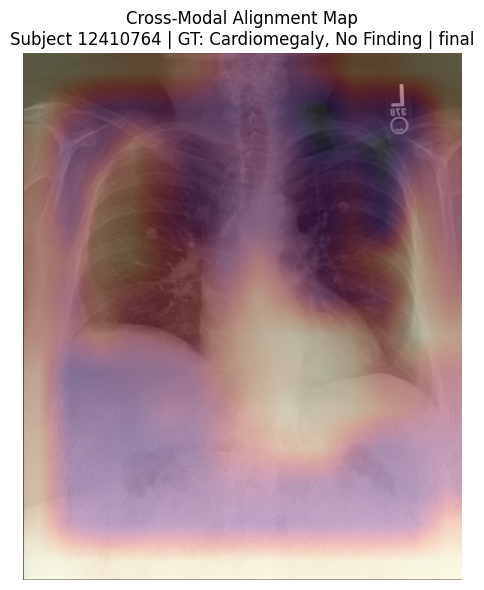

None


In [34]:
overlay_results = overlay_cross_modal_attention(
    cross_modal_results[0]["metadata"],
    cross_modal_results[0]["heatmap_up"],
    cross_modal_results[0]["chosen_label"],
    ground_truth=cross_modal_results[0]["ground_truth"],
)
print(overlay_results)

In [35]:
cross_modal_eval = evaluate_cross_modal_alignment(
    single_chunk_paths,
    token_queries=("effusion", "cardiomegaly", "pneumothorax"),
    max_samples=100,
)
cross_modal_df = pd.DataFrame(cross_modal_eval)
cross_modal_df.head()

cross_modal_df.groupby("token_query")[["entropy", "peak_score", "sparsity"]].mean()

,entropy,peak_score,sparsity
token_query,,,
cardiomegaly,5.164000,2.314762,0.158730
effusion,5.174777,2.161835,0.185333
pneumothorax,5.181706,1.987479,0.208503


/tmp/ipykernel_1619180/1819944841.py:83: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  image_arr = torch.tensor(list(image.getdata()), dtype=torch.float32).view(h, w) / 255.0



Subject ID   : 10005866
Study ID     : 55665483
DICOM ID     : 6039e5db-d35aed7c-106102aa-126d200e-a262c646
Image        : 6039e5db-d35aed7c-106102aa-126d200e-a262c646.jpg
Ground Truth : Atelectasis, Cardiomegaly, Consolidation, Edema, Pleural Effusion, Support Devices
Chosen Label : cardiomegaly
Top Patch    : (7, 8)


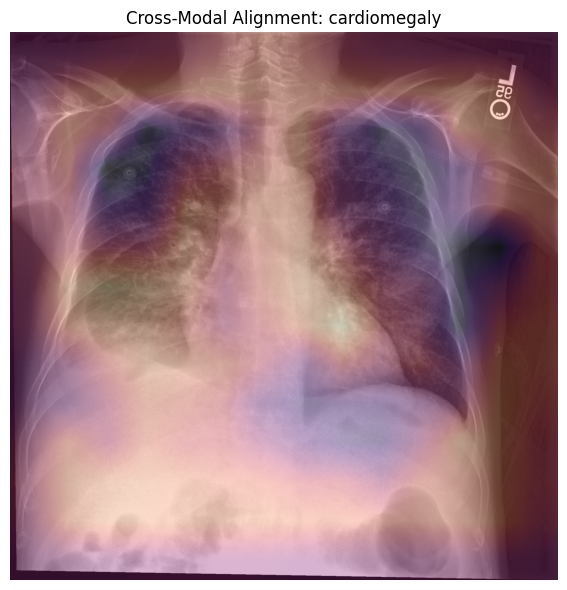

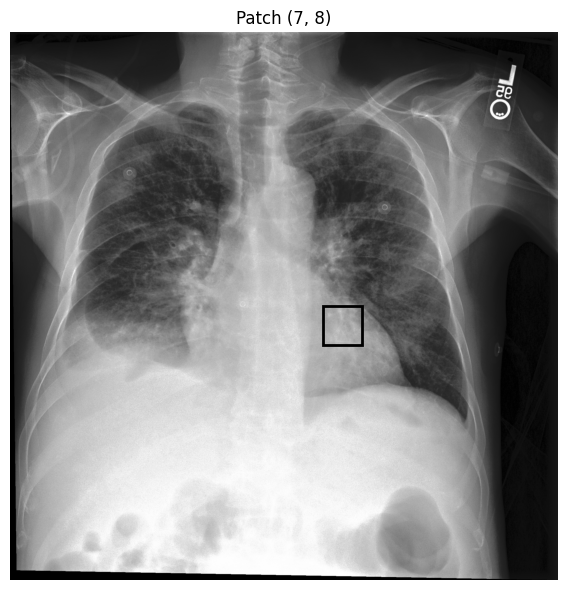

,token,score,token_index
0,mild,0.273603,112
1,cardiomegaly,0.254939,113
2,is,0.251979,114
3,[CLS],0.249159,0
4,unchanged,0.247230,115
5,diuretics,0.235220,38
6,.,0.226137,116
7,increased,0.222616,31
8,",",0.219530,132
9,on,0.214571,37



Top patches for token index 113


,row,col,score,token,token_index
0,7,8,0.254939,cardiomegaly,113
1,6,2,0.215397,cardiomegaly,113
2,6,3,0.182913,cardiomegaly,113
3,6,7,0.175367,cardiomegaly,113
4,10,11,0.153937,cardiomegaly,113
5,7,2,0.151757,cardiomegaly,113
6,6,1,0.150683,cardiomegaly,113
7,8,3,0.149933,cardiomegaly,113
8,12,2,0.149738,cardiomegaly,113
9,5,7,0.145211,cardiomegaly,113


In [36]:
result = inspect_cross_modal_alignment_sample(
    chunk_path=single_chunk_paths[0],
    sample_idx=4,
    token_query="cardiomegaly",
    normalize=True,
    k=10,
)
display(result["top_tokens_for_patch_df"])

for token_idx, df in result["top_patches_for_selected_tokens"].items():
    print(f"\nTop patches for token index {token_idx}")
    display(df)

/tmp/ipykernel_1619180/1819944841.py:83: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  image_arr = torch.tensor(list(image.getdata()), dtype=torch.float32).view(h, w) / 255.0



Subject ID   : 10001217
Study ID     : 52067803
DICOM ID     : a917c883-720a5bbf-02c84fc6-98ad00ac-c562ff80
Image        : a917c883-720a5bbf-02c84fc6-98ad00ac-c562ff80.jpg
Ground Truth : Atelectasis
Chosen Label : pleural effusion
Top Patch    : (5, 3)


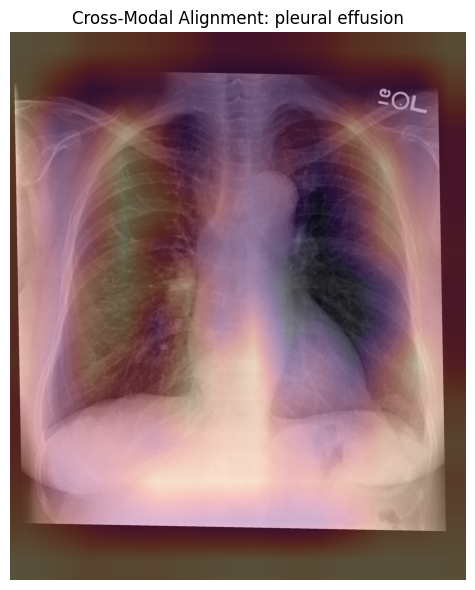

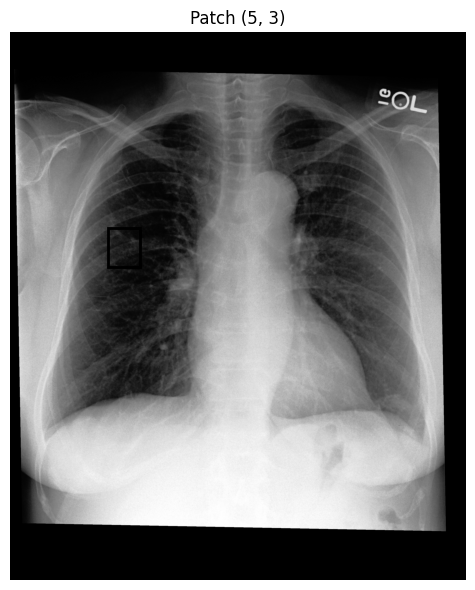

,token,score,token_index
0,[CLS],0.543896,0
1,no,0.255775,93
2,",",0.248988,92
3,left,0.238510,87
4,acute,0.238429,94
5,cardiopulmonary,0.233514,95
6,process,0.232745,96
7,none,0.232657,26
8,[SEP],0.229838,97
9,base,0.228294,88



Top patches for token index 59


,row,col,score,token,token_index
0,5,3,0.158619,pleural,59
1,3,3,0.148947,pleural,59
2,4,3,0.148362,pleural,59
3,13,11,0.145746,pleural,59
4,13,10,0.143963,pleural,59
5,13,12,0.143911,pleural,59
6,13,0,0.143516,pleural,59
7,13,7,0.142987,pleural,59
8,0,0,0.141282,pleural,59
9,8,12,0.139444,pleural,59



Top patches for token index 60


,row,col,score,token,token_index
0,5,3,0.152723,effusion,60
1,4,3,0.143645,effusion,60
2,3,3,0.143504,effusion,60
3,13,11,0.142729,effusion,60
4,13,10,0.140875,effusion,60
5,13,12,0.140725,effusion,60
6,13,0,0.140291,effusion,60
7,13,7,0.139870,effusion,60
8,8,12,0.138156,effusion,60
9,0,0,0.137983,effusion,60


In [37]:
result = inspect_cross_modal_alignment_sample(
    chunk_path=single_chunk_paths[0],
    sample_idx=0,
    phrase_tokens=["pleural", "effusion"],
    normalize=True,
    k=10,
)

display(result["top_tokens_for_patch_df"])

for token_idx, df in result["top_patches_for_selected_tokens"].items():
    print(f"\nTop patches for token index {token_idx}")
    display(df)

# Grad-CAM

In [25]:
def plot_biovil_t_gradcam(
    batch,
    cam,
    alpha=0.35,
    cmap="magma",
    impression_chars=300,
):
    """
    Plot Grad-CAM overlays for all samples in a batch.

    Args
    ----
    batch : dict
        Output batch from the dataloader
    cam : torch.Tensor
        Grad-CAM tensor [B, H, W]
    """

    B = cam.shape[0]
    results = []

    for i in range(B):

        meta = batch["meta"]

        image_path = meta["image_path"][i]
        image = Image.open(image_path).convert("L")

        w, h = image.size
        image_arr = torch.tensor(list(image.getdata()), dtype=torch.float32).view(h, w) / 255.0

        heat = cam[i]

        if heat.shape != image_arr.shape:
            heat = F.interpolate(
                heat.unsqueeze(0).unsqueeze(0),
                size=(h, w),
                mode="bilinear",
                align_corners=False,
            )[0, 0]

        report_text = meta.get("report_text", [""])[i] or ""
        report_text_clean = " ".join(str(report_text).split())

        impression = report_text_clean

        upper_text = str(report_text)
        if "IMPRESSION:" in upper_text.upper():
            start = upper_text.upper().find("IMPRESSION:")
            impression = upper_text[start + len("IMPRESSION:"):].strip()
            impression = " ".join(impression.split())

        if len(impression) > impression_chars:
            impression = impression[:impression_chars].rstrip() + "..."

        ground_truth = []

        if "labels" in batch:
            sample_labels = {
                k: batch["labels"][k][i].item()
                for k in batch["labels"]
            }
            ground_truth = [
                k for k, v in sample_labels.items()
                if float(v) == 1.0
            ]

        print("\n" + "=" * 80)
        print(f"Sample Index : {i+1}")
        print(f"Subject ID   : {meta.get('subject_id', ['N/A'])[i]}")
        print(f"Study ID     : {meta.get('study_id', ['N/A'])[i]}")
        print(f"DICOM ID     : {meta.get('dicom_id', ['N/A'])[i]}")
        print(f"Image        : {Path(image_path).name}")
        print(f"Ground Truth : {', '.join(ground_truth) if ground_truth else 'None / unavailable'}")
        print(f"Impression   : {impression}")

        plt.figure(figsize=(6, 6))
        plt.imshow(image_arr, cmap="gray")
        plt.imshow(heat, cmap=cmap, alpha=alpha)

        plt.title(
            f"BioViL-T Grad-CAM\n"
            f"Subject {meta.get('subject_id', ['N/A'])[i]}"
        )

        plt.axis("off")
        plt.tight_layout()
        savefig(
        "biovil_t/gradcam",
        f"sample_{i}_subject_{meta.get('subject_id', ['NA'])[i]}_gradcam.png"
    )
        plt.show()

        results.append({
            "index": i,
            "image_path": image_path,
            "heatmap": heat.detach().cpu(),
            "ground_truth": ground_truth,
            "impression": impression,
        })

    return results

In [26]:
def plot_biovil_t_gradcam_pp(
    batch,
    cam,
    alpha=0.35,
    cmap="magma",
    impression_chars=300,
):
    """
    Plot Grad-CAM overlays for all samples in a batch.

    Args
    ----
    batch : dict
        Output batch from the dataloader
    cam : torch.Tensor
        Grad-CAM tensor [B, H, W]
    """

    B = cam.shape[0]
    results = []

    for i in range(B):

        meta = batch["meta"]

        image_path = meta["image_path"][i]
        image = Image.open(image_path).convert("L")

        w, h = image.size
        image_arr = torch.tensor(list(image.getdata()), dtype=torch.float32).view(h, w) / 255.0

        heat = cam[i]

        if heat.shape != image_arr.shape:
            heat = F.interpolate(
                heat.unsqueeze(0).unsqueeze(0),
                size=(h, w),
                mode="bilinear",
                align_corners=False,
            )[0, 0]

        report_text = meta.get("report_text", [""])[i] or ""
        report_text_clean = " ".join(str(report_text).split())

        impression = report_text_clean

        upper_text = str(report_text)
        if "IMPRESSION:" in upper_text.upper():
            start = upper_text.upper().find("IMPRESSION:")
            impression = upper_text[start + len("IMPRESSION:"):].strip()
            impression = " ".join(impression.split())

        if len(impression) > impression_chars:
            impression = impression[:impression_chars].rstrip() + "..."

        ground_truth = []

        if "labels" in batch:
            sample_labels = {
                k: batch["labels"][k][i].item()
                for k in batch["labels"]
            }
            ground_truth = [
                k for k, v in sample_labels.items()
                if float(v) == 1.0
            ]

        print("\n" + "=" * 80)
        print(f"Sample Index : {i+1}")
        print(f"Subject ID   : {meta.get('subject_id', ['N/A'])[i]}")
        print(f"Study ID     : {meta.get('study_id', ['N/A'])[i]}")
        print(f"DICOM ID     : {meta.get('dicom_id', ['N/A'])[i]}")
        print(f"Image        : {Path(image_path).name}")
        print(f"Ground Truth : {', '.join(ground_truth) if ground_truth else 'None / unavailable'}")
        print(f"Impression   : {impression}")

        plt.figure(figsize=(6, 6))
        plt.imshow(image_arr, cmap="gray")
        plt.imshow(heat, cmap=cmap, alpha=alpha)

        plt.title(
            f"BioViL-T Grad-CAM\n"
            f"Subject {meta.get('subject_id', ['N/A'])[i]}"
        )

        plt.axis("off")
        plt.tight_layout()
        savefig(
        "biovil_t/gradcam",
        f"sample_{i}_subject_{meta.get('subject_id', ['NA'])[i]}_gradcam_pp.png"
    )
        plt.show()

        results.append({
            "index": i,
            "image_path": image_path,
            "heatmap": heat.detach().cpu(),
            "ground_truth": ground_truth,
            "impression": impression,
        })

    return results

/home/links/mtm211/.conda/envs/biovil_env/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/home/links/mtm211/.conda/envs/biovil_env/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of the model checkpoint at microsoft/BiomedVLP-BioViL-T were not used when initializing CXRBertModel: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing CXRBertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from 

Temporal pooler found: <class 'models.biovil_t.transformer.VisionTransformerPooler'>
Using last Conv2d layer for Grad-CAM: projector.model.3 (<class 'torch.nn.modules.conv.Conv2d'>)
Grad-CAM shape: torch.Size([5, 448, 448])
Similarity score: 3.1241564750671387


/tmp/ipykernel_1619180/941074277.py:30: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  image_arr = torch.tensor(list(image.getdata()), dtype=torch.float32).view(h, w) / 255.0



Sample Index : 1
Subject ID   : 10001217
Study ID     : 52067803
DICOM ID     : a917c883-720a5bbf-02c84fc6-98ad00ac-c562ff80
Image        : a917c883-720a5bbf-02c84fc6-98ad00ac-c562ff80.jpg
Ground Truth : Atelectasis
Impression   : Mild left base atelectasis. Otherwise, no acute cardiopulmonary process


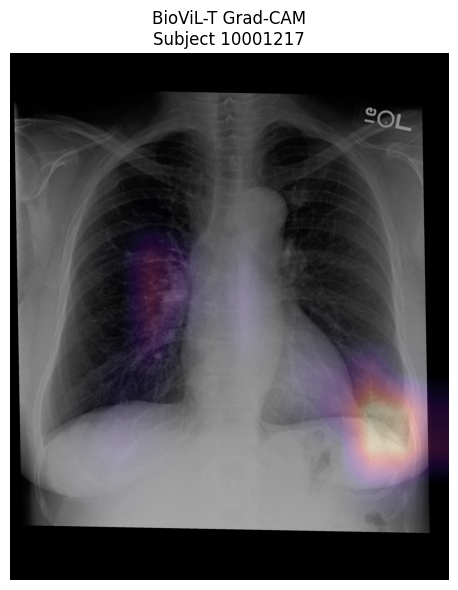


Sample Index : 2
Subject ID   : 10001401
Study ID     : 51065211
DICOM ID     : 8061113f-c019f3ae-fd1b7c54-33e8690d-be838099
Image        : 8061113f-c019f3ae-fd1b7c54-33e8690d-be838099.jpg
Ground Truth : Atelectasis, Cardiomegaly, No Finding, Support Devices
Impression   : Mild bibasilar atelectasis. No signs of free air below the right hemidiaphragm


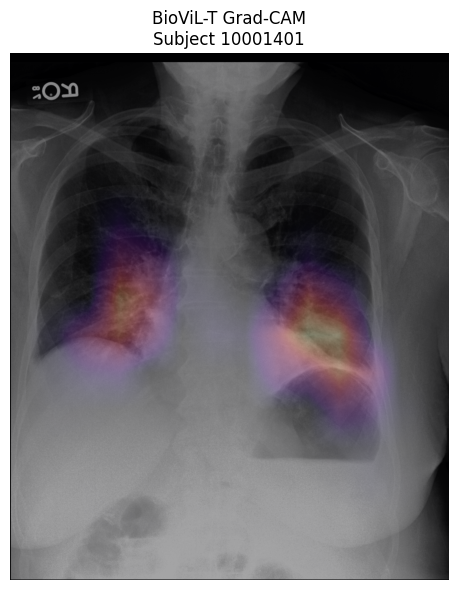


Sample Index : 3
Subject ID   : 10003019
Study ID     : 55487822
DICOM ID     : c25b9023-9cd26369-dbe2b67b-c250ef52-b772137e
Image        : c25b9023-9cd26369-dbe2b67b-c250ef52-b772137e.jpg
Ground Truth : Consolidation, Support Devices
Impression   : AP chest compared to ___: Multifocal pulmonary consolidation is clearing. Heart is normal size. Right paratracheal mediastinal fullness, due in part to adenopathy is longstanding. No pleural effusion. Heart size normal. Right jugular line ends in the region of the superior cavoatrial junction


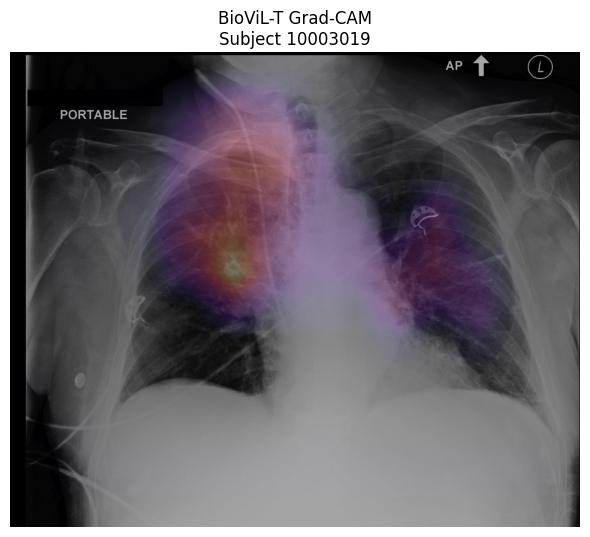


Sample Index : 4
Subject ID   : 10003400
Study ID     : 57147097
DICOM ID     : 71884ebf-2fa1b333-d288ddba-2a9d832b-c9f4f79b
Image        : 71884ebf-2fa1b333-d288ddba-2a9d832b-c9f4f79b.jpg
Ground Truth : Atelectasis, Cardiomegaly, Consolidation, Edema, Lung Opacity, No Finding, Pleural Effusion, Pneumothorax, Support Devices
Impression   : Interval decrease in the right-sided. Stable appearance of the left lung


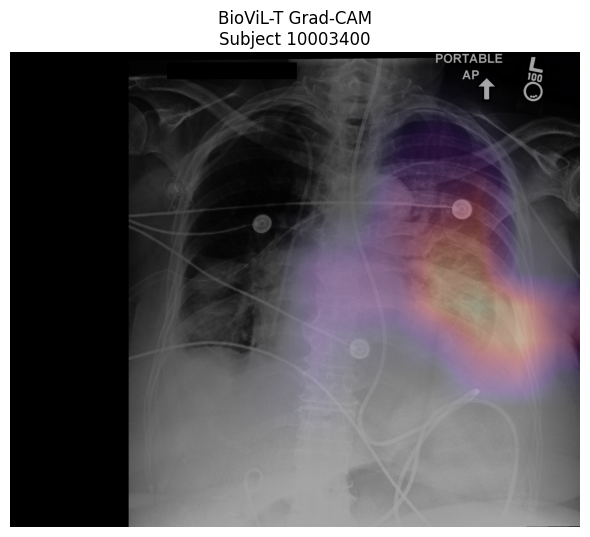


Sample Index : 5
Subject ID   : 10005866
Study ID     : 55665483
DICOM ID     : 6039e5db-d35aed7c-106102aa-126d200e-a262c646
Image        : 6039e5db-d35aed7c-106102aa-126d200e-a262c646.jpg
Ground Truth : Atelectasis, Cardiomegaly, Consolidation, Edema, Pleural Effusion, Support Devices
Impression   : Improved pulmonary edema, with improvement of a prior retrocardiac consolidation, suggesting clearing of a prior mucous plug


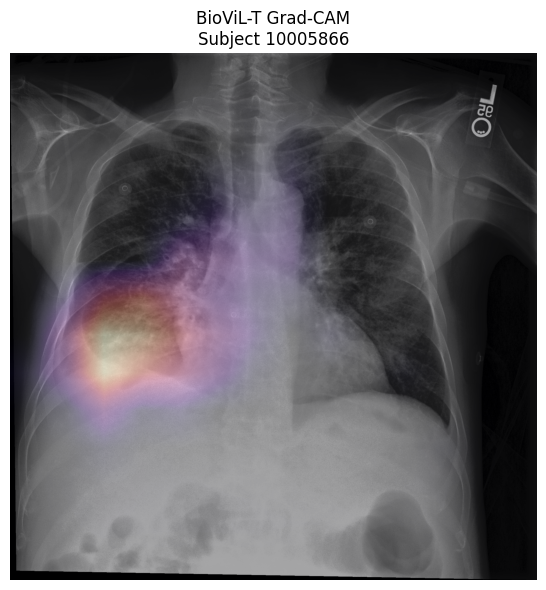

[{'index': 0,
  'image_path': '/home/links/mtm211/Dataset/Single/images/p10/p10001217/s52067803/a917c883-720a5bbf-02c84fc6-98ad00ac-c562ff80.jpg',
  'heatmap': tensor([[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]),
  'ground_truth': ['Atelectasis'],
  'impression': 'Mild left base atelectasis. Otherwise, no acute cardiopulmonary process'},
 {'index': 1,
  'image_path': '/home/links/mtm211/Dataset/Single/images/p10/p10001401/s51065211/8061113f-c019f3ae-fd1b7c54-33e8690d-be838099.jpg',
  'heatmap': tensor([[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]),
  'ground_truth': [

In [40]:
cam, score, batch, model, target_layer = init_grad_cam(
    single_csv_path="/home/links/mtm211/Dataset/Single/single_dataset.csv",
    model_name="microsoft/BiomedVLP-BioViL-T",
    device=get_device(),
    batch_size=5,
    num_workers=0,
    target_layer=None,
)             
print("Grad-CAM shape:", cam.shape)
print("Similarity score:", score)
plot_biovil_t_gradcam(batch, cam)

/home/links/mtm211/.conda/envs/biovil_env/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of the model checkpoint at microsoft/BiomedVLP-BioViL-T were not used when initializing CXRBertModel: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing CXRBertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing CXRBertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Temporal pooler found: <class 'models.biovil_t.transformer.VisionTransformerPooler'>
Using last Conv2d layer for Grad-CAM: projector.model.3 (<class 'torch.nn.modules.conv.Conv2d'>)
Grad-CAM++ shape: torch.Size([5, 448, 448])
Similarity score: 3.1241564750671387


/tmp/ipykernel_1619180/2668840699.py:30: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  image_arr = torch.tensor(list(image.getdata()), dtype=torch.float32).view(h, w) / 255.0



Sample Index : 1
Subject ID   : 10001217
Study ID     : 52067803
DICOM ID     : a917c883-720a5bbf-02c84fc6-98ad00ac-c562ff80
Image        : a917c883-720a5bbf-02c84fc6-98ad00ac-c562ff80.jpg
Ground Truth : Atelectasis
Impression   : Mild left base atelectasis. Otherwise, no acute cardiopulmonary process


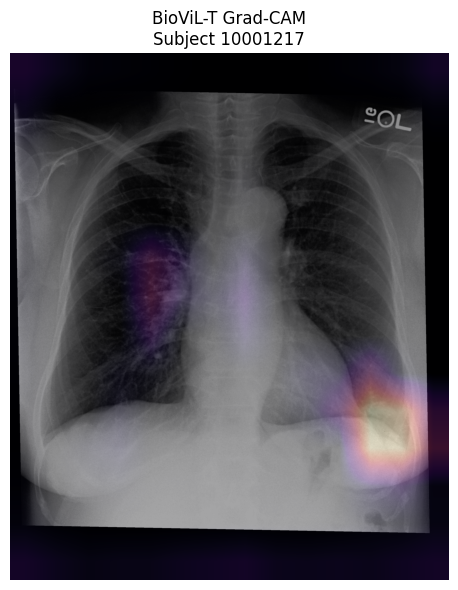


Sample Index : 2
Subject ID   : 10001401
Study ID     : 51065211
DICOM ID     : 8061113f-c019f3ae-fd1b7c54-33e8690d-be838099
Image        : 8061113f-c019f3ae-fd1b7c54-33e8690d-be838099.jpg
Ground Truth : Atelectasis, Cardiomegaly, No Finding, Support Devices
Impression   : Mild bibasilar atelectasis. No signs of free air below the right hemidiaphragm


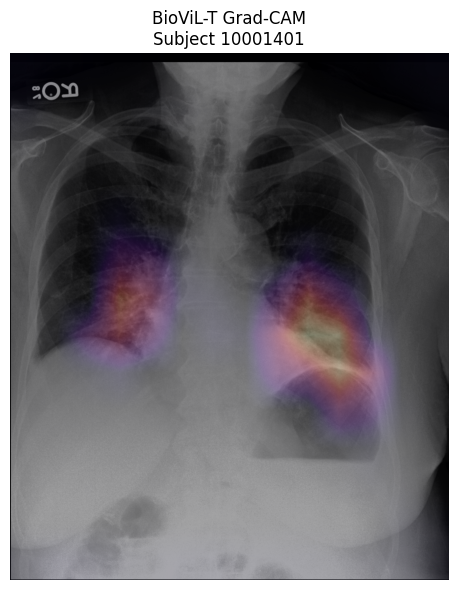


Sample Index : 3
Subject ID   : 10003019
Study ID     : 55487822
DICOM ID     : c25b9023-9cd26369-dbe2b67b-c250ef52-b772137e
Image        : c25b9023-9cd26369-dbe2b67b-c250ef52-b772137e.jpg
Ground Truth : Consolidation, Support Devices
Impression   : AP chest compared to ___: Multifocal pulmonary consolidation is clearing. Heart is normal size. Right paratracheal mediastinal fullness, due in part to adenopathy is longstanding. No pleural effusion. Heart size normal. Right jugular line ends in the region of the superior cavoatrial junction


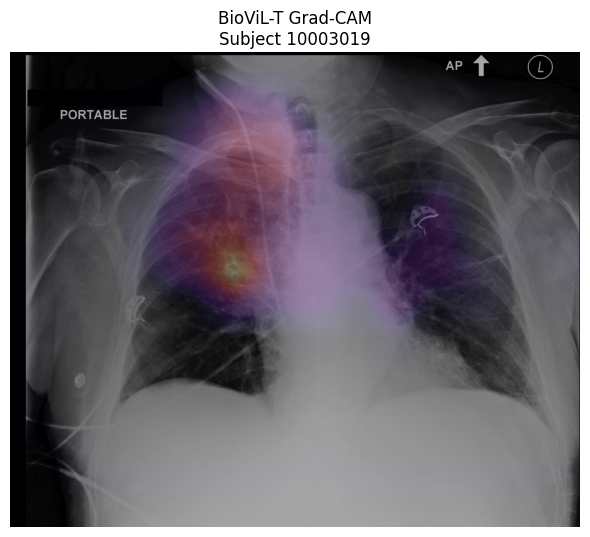


Sample Index : 4
Subject ID   : 10003400
Study ID     : 57147097
DICOM ID     : 71884ebf-2fa1b333-d288ddba-2a9d832b-c9f4f79b
Image        : 71884ebf-2fa1b333-d288ddba-2a9d832b-c9f4f79b.jpg
Ground Truth : Atelectasis, Cardiomegaly, Consolidation, Edema, Lung Opacity, No Finding, Pleural Effusion, Pneumothorax, Support Devices
Impression   : Interval decrease in the right-sided. Stable appearance of the left lung


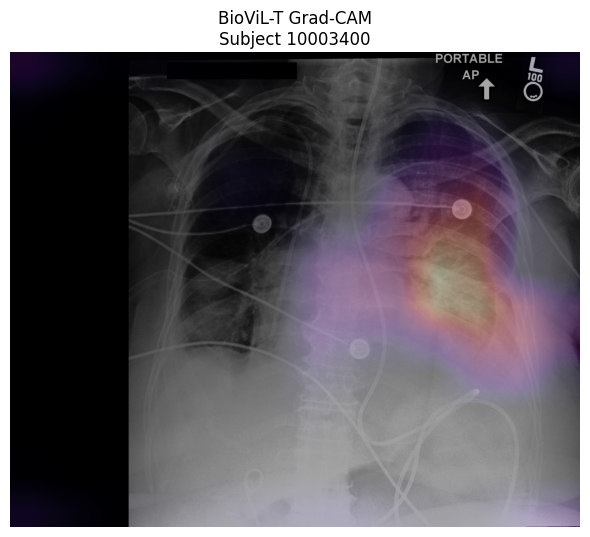


Sample Index : 5
Subject ID   : 10005866
Study ID     : 55665483
DICOM ID     : 6039e5db-d35aed7c-106102aa-126d200e-a262c646
Image        : 6039e5db-d35aed7c-106102aa-126d200e-a262c646.jpg
Ground Truth : Atelectasis, Cardiomegaly, Consolidation, Edema, Pleural Effusion, Support Devices
Impression   : Improved pulmonary edema, with improvement of a prior retrocardiac consolidation, suggesting clearing of a prior mucous plug


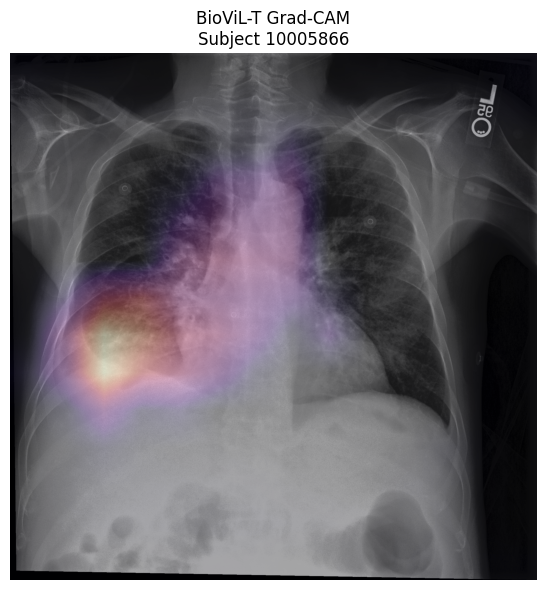

[{'index': 0,
  'image_path': '/home/links/mtm211/Dataset/Single/images/p10/p10001217/s52067803/a917c883-720a5bbf-02c84fc6-98ad00ac-c562ff80.jpg',
  'heatmap': tensor([[0.2290, 0.2290, 0.2290,  ..., 0.1862, 0.1862, 0.1862],
          [0.2290, 0.2290, 0.2290,  ..., 0.1862, 0.1862, 0.1862],
          [0.2290, 0.2290, 0.2290,  ..., 0.1862, 0.1862, 0.1862],
          ...,
          [0.1992, 0.1992, 0.1992,  ..., 0.1915, 0.1915, 0.1915],
          [0.1992, 0.1992, 0.1992,  ..., 0.1915, 0.1915, 0.1915],
          [0.1992, 0.1992, 0.1992,  ..., 0.1915, 0.1915, 0.1915]]),
  'ground_truth': ['Atelectasis'],
  'impression': 'Mild left base atelectasis. Otherwise, no acute cardiopulmonary process'},
 {'index': 1,
  'image_path': '/home/links/mtm211/Dataset/Single/images/p10/p10001401/s51065211/8061113f-c019f3ae-fd1b7c54-33e8690d-be838099.jpg',
  'heatmap': tensor([[0.0592, 0.0592, 0.0592,  ..., 0.0572, 0.0572, 0.0572],
          [0.0592, 0.0592, 0.0592,  ..., 0.0572, 0.0572, 0.0572],
          [0

In [41]:
cam_pp, score_pp, batch_pp, model, target_layer = init_grad_cam_pp(
    single_csv_path="/home/links/mtm211/Dataset/Single/single_dataset.csv",
    model_name="microsoft/BiomedVLP-BioViL-T",
    device=get_device(),
    batch_size=5,
    num_workers=0,
    target_layer=None,
)
print("Grad-CAM++ shape:", cam_pp.shape)
print("Similarity score:", score_pp)
plot_biovil_t_gradcam_pp(batch_pp, cam_pp)

# Concept-Based

## t-CAV

In [27]:
def build_single_tcav_concepts(
    samples,
    pathologies,
    max_positive=100,
    max_negative=100,
    embedding_key="image_emb",
    seed=42,
):
    """
    Builds TCAV concept dictionary automatically.

    Returns:
        concepts = {
            pathology_name: {
                "positives": ...,
                "negatives": ...,
                "cav": ...,
                "tcav_emb": ...,
                "tcav_sim": ...,
                "directional": ...,
                "sim_directional": ...,
            }
        }
    """
    concepts = {}

    for pathology in pathologies:
        print(f"\nBuilding TCAV concept: {pathology}")

        positives, negatives = select_single_samples(
            samples=samples,
            concept_name=pathology,
            max_positive=max_positive,
            max_negative=max_negative,
            seed=seed,
        )

        if len(positives) == 0 or len(negatives) == 0:
            print(f"Skipping {pathology}: not enough positive/negative samples.")
            continue

        cav = build_cav_from_samples(
            positives=positives,
            negatives=negatives,
            embedding_key=embedding_key,
        )

        tcav_emb, directional = tcav_score_from_embeddings(
            samples=positives + negatives,
            cav=cav,
            embedding_key=embedding_key,
        )

        tcav_sim, sim_directional = similarity_tcav_score(
            samples=positives + negatives,
            cav=cav,
            embedding_key=embedding_key,
        )

        concepts[pathology] = {
            "positives": positives,
            "negatives": negatives,
            "cav": cav,
            "tcav_emb": tcav_emb,
            "tcav_sim": tcav_sim,
            "directional": directional,
            "sim_directional": sim_directional,
        }

        print(f"  Positives: {len(positives)}")
        print(f"  Negatives: {len(negatives)}")
        print(f"  Embedding-space TCAV: {tcav_emb:.4f}")
        print(f"  Similarity-based TCAV: {tcav_sim:.4f}")

    return concepts

def build_temporal_tcav_concepts(
    temporal_samples,
    pathologies,
    max_positive=100,
    max_negative=100,
    embedding_key="temporal_global_emb",
    seed=42,
):
    """
    Build temporal TCAV concepts from temporal chunk samples.

    Returns:
        concepts = {
            pathology_name: {
                "positives": ...,
                "negatives": ...,
                "cav": ...,
                "tcav_emb": ...,
                "tcav_sim": ...,
                "directional": ...,
                "sim_directional": ...,
            }
        }
    """
    concepts = {}

    for pathology in pathologies:
        print(f"\nBuilding temporal TCAV concept: {pathology}")

        positives, negatives = select_temporal_samples(
            samples=temporal_samples,
            concept_name=pathology,
            max_positive=max_positive,
            max_negative=max_negative,
            seed=seed,
        )

        # filter out samples where temporal embedding is missing
        positives = [s for s in positives if s.get(embedding_key) is not None]
        negatives = [s for s in negatives if s.get(embedding_key) is not None]

        if len(positives) == 0 or len(negatives) == 0:
            print(f"Skipping {pathology}: not enough positive/negative temporal samples.")
            continue

        cav = build_cav_from_samples(
            positives=positives,
            negatives=negatives,
            embedding_key=embedding_key,
        )

        tcav_emb, directional = tcav_score_from_embeddings(
            samples=positives + negatives,
            cav=cav,
            embedding_key=embedding_key,
        )

        tcav_sim, sim_directional = similarity_tcav_score(
            samples=positives + negatives,
            cav=cav,
            embedding_key=embedding_key,
        )

        concepts[pathology] = {
            "positives": positives,
            "negatives": negatives,
            "cav": cav,
            "tcav_emb": tcav_emb,
            "tcav_sim": tcav_sim,
            "directional": directional,
            "sim_directional": sim_directional,
        }

        print(f"  Positives: {len(positives)}")
        print(f"  Negatives: {len(negatives)}")
        print(f"  Temporal embedding TCAV: {tcav_emb:.4f}")
        print(f"  Temporal similarity TCAV: {tcav_sim:.4f}")

    return concepts

In [28]:
def plot_tcav_summary(
    concept_name,
    positives,
    negatives,
    cav,
    tcav_score,
    similarity_tcav_score=None,
    num_example_images=3,
    seed=42,
    embedding_key="image_emb",
):

    rng = random.Random(seed)

    cav = F.normalize(cav.float(), dim=0)

    positives_emb = torch.stack([s[embedding_key].float() for s in positives])
    negatives_emb = torch.stack([s[embedding_key].float() for s in negatives])

    positives_emb = F.normalize(positives_emb, dim=-1)
    negatives_emb = F.normalize(negatives_emb, dim=-1)

    positive_proj = positives_emb @ cav
    negative_proj = negatives_emb @ cav

    positive_mean = positive_proj.mean().item()
    negative_mean = negative_proj.mean().item()

    pos_examples = rng.sample(positives, min(num_example_images, len(positives)))
    neg_examples = rng.sample(negatives, min(num_example_images, len(negatives)))

    plt.rcParams.update({
        "font.size": 12,
        "axes.titlesize": 14,
        "axes.labelsize": 12,
        "figure.titlesize": 18
    })

    fig = plt.figure(figsize=(16, 11))
    gs = fig.add_gridspec(
        4,
        max(num_example_images, 3),
        height_ratios=[1.2, 1.2, 1, 1],
        hspace=0.5,
        wspace=0.3
    )

    # Positive concept images
    for i in range(max(num_example_images, 3)):
        ax = fig.add_subplot(gs[0, i])

        if i < len(pos_examples):
            img_path = pos_examples[i]["metadata"]["image_path"]
            img = Image.open(img_path).convert("L")
            ax.imshow(img, cmap="gray")
            ax.set_title(f"Positive {i+1}", fontsize=12)

        ax.axis("off")

    # Negative concept images
    for i in range(max(num_example_images, 3)):
        ax = fig.add_subplot(gs[1, i])

        if i < len(neg_examples):
            img_path = neg_examples[i]["metadata"]["image_path"]
            img = Image.open(img_path).convert("L")
            ax.imshow(img, cmap="gray")
            ax.set_title(f"Negative {i+1}", fontsize=12)

        ax.axis("off")

    # Density distribution
    ax_hist = fig.add_subplot(gs[2, :2])

    pos = positive_proj.cpu().numpy()
    neg = negative_proj.cpu().numpy()

    xmin = min(pos.min(), neg.min())
    xmax = max(pos.max(), neg.max())

    x = np.linspace(xmin, xmax, 500)

    pos_density = gaussian_kde(pos)(x)
    neg_density = gaussian_kde(neg)(x)

    ax_hist.fill_between(
        x,
        pos_density,
        alpha=0.5,
        color="#3B82F6",
        label="Concept Positive",
    )

    ax_hist.fill_between(
        x,
        neg_density,
        alpha=0.5,
        color="#EF4444",
        label="Concept Negative",
    )

    ax_hist.axvline(
        0,
        linestyle="--",
        linewidth=2,
        color="black",
        label="Concept Boundary",
    )

    ax_hist.axvline(
        pos.mean(),
        color="#1D4ED8",
        linestyle=":",
        linewidth=2,
    )

    ax_hist.axvline(
        neg.mean(),
        color="#B91C1C",
        linestyle=":",
        linewidth=2,
    )

    ax_hist.set_title("Concept Projection Distribution")
    ax_hist.set_xlabel("Projection onto Concept Activation Vector (CAV)")
    ax_hist.set_ylabel("Density")
    ax_hist.grid(alpha=0.25)
    ax_hist.legend()

    # Boxplot
    ax_box = fig.add_subplot(gs[2, 2:])

    box = ax_box.boxplot(
        [
            positive_proj.cpu().numpy(),
            negative_proj.cpu().numpy()
        ],
        patch_artist=True,
        tick_labels=["Positive", "Negative"],
    )

    colors = ["#3B82F6", "#EF4444"]
    for patch, color in zip(box["boxes"], colors):
        patch.set_facecolor(color)

    ax_box.axhline(0, linestyle="--", linewidth=2, color="black")
    ax_box.set_title("Concept Projection Comparison")
    ax_box.set_ylabel("Projection onto CAV")
    ax_box.grid(alpha=0.25)

    # TCAV scores
    ax_bar = fig.add_subplot(gs[3, :])

    labels = ["Embedding TCAV"]
    values = [tcav_score]

    if similarity_tcav_score is not None:
        labels.append("Similarity TCAV")
        values.append(similarity_tcav_score)

    bars = ax_bar.bar(
        labels,
        values,
        color=["#10B981", "#8B5CF6"][:len(values)]
    )

    ax_bar.set_ylim(0, 1)
    ax_bar.set_ylabel("TCAV Score")
    ax_bar.set_title("Concept Sensitivity")
    ax_bar.grid(axis="y", alpha=0.3)

    for bar, val in zip(bars, values):
        ax_bar.text(
            bar.get_x() + bar.get_width() / 2,
            val + 0.03,
            f"{val:.2f}",
            ha="center",
            fontsize=12,
            fontweight="bold"
        )

    fig.suptitle(
        f"TCAV Analysis for Concept: {concept_name}\n"
        f"Positive mean projection = {positive_mean:.3f}   |   "
        f"Negative mean projection = {negative_mean:.3f}",
        fontweight="bold"
    )

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    savefig("biovil_t/tcav", f"{concept_name.replace(' ', '_')}_tcav_summary.png")
    plt.show()


def plot_tcav_concept_comparison(
    concepts,
    title="Concept Sensitivity Across Pathologies",
    figsize=(11, 6),
    emb_label="Embedding TCAV",
    sim_label="Similarity TCAV",
    rotation=25,
):
    """
    Beautified TCAV comparison plot for dissertation/presentation.
    """

    if not concepts:
        raise ValueError("concepts dictionary is empty.")

    concept_names = list(concepts.keys())
    emb_scores = [concepts[name]["tcav_emb"] for name in concept_names]
    sim_scores = [concepts[name]["tcav_sim"] for name in concept_names]

    x = np.arange(len(concept_names))
    width = 0.36

    plt.rcParams.update({
        "font.size": 12,
        "axes.titlesize": 16,
        "axes.labelsize": 13
    })

    fig, ax = plt.subplots(figsize=figsize)

    # Color palette (clean research style)
    emb_color = "#2563EB"   # blue
    sim_color = "#EF4444"   # red

    bars1 = ax.bar(
        x - width/2,
        emb_scores,
        width=width,
        label=emb_label,
        color=emb_color,
        alpha=0.85,
    )

    bars2 = ax.bar(
        x + width/2,
        sim_scores,
        width=width,
        label=sim_label,
        color=sim_color,
        alpha=0.85,
    )

    ax.set_xticks(x)
    ax.set_xticklabels(concept_names, rotation=rotation)

    ax.set_ylabel("TCAV Score")
    ax.set_ylim(0, 1)

    ax.set_title(title, pad=15, fontweight="bold")

    ax.legend(frameon=False)

    # cleaner grid
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    # remove top/right spines
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Annotate values
    for bars in [bars1, bars2]:
        for bar in bars:
            h = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                h + 0.02,
                f"{h:.2f}",
                ha="center",
                va="bottom",
                fontsize=11,
                fontweight="bold"
            )

    plt.tight_layout()
    plt.show()

def plot_temporal_tcav_examples(
    concept_name,
    positives,
    negatives,
    num_example_images=3,
    seed=42,
):

    rng = random.Random(seed)

    pos_examples = rng.sample(positives, min(num_example_images, len(positives)))
    neg_examples = rng.sample(negatives, min(num_example_images, len(negatives)))

    fig, axes = plt.subplots(4, num_example_images, figsize=(4 * num_example_images, 12))

    for i in range(num_example_images):
        if i < len(pos_examples):
            pos = pos_examples[i]
            prior_img = Image.open(pos["metadata"]["prior_image_path"]).convert("L")
            current_img = Image.open(pos["metadata"]["current_image_path"]).convert("L")

            axes[0, i].imshow(prior_img, cmap="gray")
            axes[0, i].set_title(f"Positive {i+1}\nPrior")
            axes[0, i].axis("off")

            axes[1, i].imshow(current_img, cmap="gray")
            axes[1, i].set_title(f"Positive {i+1}\nCurrent")
            axes[1, i].axis("off")
        else:
            axes[0, i].axis("off")
            axes[1, i].axis("off")

        if i < len(neg_examples):
            neg = neg_examples[i]
            prior_img = Image.open(neg["metadata"]["prior_image_path"]).convert("L")
            current_img = Image.open(neg["metadata"]["current_image_path"]).convert("L")

            axes[2, i].imshow(prior_img, cmap="gray")
            axes[2, i].set_title(f"Negative {i+1}\nPrior")
            axes[2, i].axis("off")

            axes[3, i].imshow(current_img, cmap="gray")
            axes[3, i].set_title(f"Negative {i+1}\nCurrent")
            axes[3, i].axis("off")
        else:
            axes[2, i].axis("off")
            axes[3, i].axis("off")

    plt.suptitle(f"Temporal TCAV Examples: {concept_name}", fontsize=16, y=0.98)
    plt.tight_layout()
    plt.show()

In [29]:
def plot_prototype_retrieval(
    query_sample,
    retrieved,
    title="Prototype Retrieval in Embedding Space",
    image_key="image_path",
    figsize=(16, 4),
):
    ncols = len(retrieved) + 1
    fig, axes = plt.subplots(1, ncols, figsize=figsize)

    query_path = query_sample["metadata"].get(image_key)
    if query_path is None:
        raise KeyError(f"Query sample metadata does not contain '{image_key}'")

    query_img = Image.open(query_path).convert("L")
    axes[0].imshow(query_img, cmap="gray")
    axes[0].set_title("Query")
    axes[0].axis("off")

    for i, item in enumerate(retrieved, start=1):
        sample = item["sample"]
        sim = item["similarity"]

        img_path = sample["metadata"].get(image_key)
        if img_path is None:
            raise KeyError(f"Retrieved sample metadata does not contain '{image_key}'")

        img = Image.open(img_path).convert("L")

        axes[i].imshow(img, cmap="gray")
        axes[i].set_title(f"Top {i}\nSim={sim:.3f}")
        axes[i].axis("off")

    plt.suptitle(title, fontsize=14, fontweight="bold")
    plt.tight_layout()
    savefig(
    "biovil_t/prototype_retrieval",
    f"query_{query_sample['metadata'].get('subject_id', 'NA')}_retrieval.png"
)
    plt.show()



def plot_random_prototype_retrieval(
    samples,
    embedding_key="image_emb",
    image_key="image_path",
    k=5,
    num_queries=3,
    seed=42,
):
    rng = random.Random(seed)

    if len(samples) == 0:
        raise ValueError("No samples available.")

    chosen = rng.sample(samples, min(num_queries, len(samples)))
    results = []

    for i, query_sample in enumerate(chosen, start=1):
        meta = query_sample["metadata"]

        print("\n" + "=" * 80)
        print(f"Query {i}/{len(chosen)}")
        print(f"Subject ID : {meta.get('subject_id', 'N/A')}")
        print(f"Study ID   : {meta.get('study_id', meta.get('current_study_id', 'N/A'))}")
        print(f"Image      : {Path(meta.get(image_key, 'N/A')).name}")

        retrieved = retrieve_prototypes(
            query_embedding=query_sample[embedding_key],
            samples=samples,
            embedding_key=embedding_key,
            k=k,
            exclude_same_image=True,
            query_image_path=meta.get(image_key),
        )

        plot_prototype_retrieval(
            query_sample=query_sample,
            retrieved=retrieved,
            title=f"Prototype Retrieval ({embedding_key})",
            image_key=image_key,
        )

        results.append({
            "query_sample": query_sample,
            "retrieved": retrieved,
        })

    return results

In [30]:

def _wrap_text(text: str, width: int = 55) -> str:
    text = " ".join(str(text).split())
    return "\n".join(textwrap.wrap(text, width=width))


def plot_report_retrieval(
    query_sample,
    retrieved,
    title="Report Retrieval in Embedding Space",
    text_key="report_text",
    wrap_width=55,
    figsize=(26, 11),
    font_size=16,
):
    """
    Plot query report + retrieved nearest-neighbour reports with wrapped text.
    """
    ncols = len(retrieved) + 1
    fig, axes = plt.subplots(1, ncols, figsize=figsize)

    if ncols == 1:
        axes = [axes]

    query_text = (
        query_sample["metadata"].get(text_key)
        or query_sample["metadata"].get("current_report_text")
        or query_sample["metadata"].get("report_text")
        or ""
    )

    axes[0].axis("off")
    axes[0].set_title("Query", fontweight="bold", pad=12)
    axes[0].text(
        0.02,
        0.98,
        _wrap_text(query_text, wrap_width),
        va="top",
        ha="left",
        fontsize=font_size,
        family="monospace",
        transform=axes[0].transAxes,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="lightgray"),
        clip_on=True,
    )

    for i, item in enumerate(retrieved, start=1):
        sample = item["sample"]
        sim = item["similarity"]

        report_text = (
            sample["metadata"].get(text_key)
            or sample["metadata"].get("current_report_text")
            or sample["metadata"].get("report_text")
            or ""
        )

        axes[i].axis("off")
        axes[i].set_title(f"Top {i}\nSim={sim:.3f}", fontweight="bold", pad=12)
        axes[i].text(
            0.02,
            0.98,
            _wrap_text(report_text, wrap_width),
            va="top",
            ha="left",
            fontsize=font_size,
            family="monospace",
            transform=axes[i].transAxes,
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="lightgray"),
            clip_on=True,
        )

    plt.suptitle(title, fontsize=14, fontweight="bold", y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

def plot_random_report_retrieval(
    samples,
    embedding_key="text_emb",
    text_key="report_text",
    k=5,
    num_queries=3,
    seed=42,
):
    rng = random.Random(seed)

    if len(samples) == 0:
        raise ValueError("No samples available.")

    chosen = rng.sample(samples, min(num_queries, len(samples)))
    results = []

    for i, query_sample in enumerate(chosen, start=1):
        meta = query_sample["metadata"]
        query_text = meta.get(text_key) or meta.get("current_report_text") or ""

        print("\n" + "=" * 80)
        print(f"Query {i}/{len(chosen)}")
        print(f"Subject ID : {meta.get('subject_id', 'N/A')}")
        print(f"Study ID   : {meta.get('study_id', meta.get('current_study_id', 'N/A'))}")

        retrieved = retrieve_reports(
            query_embedding=query_sample[embedding_key],
            samples=samples,
            embedding_key=embedding_key,
            k=k,
            exclude_same_report=True,
            query_report_text=query_text,
        )

        plot_report_retrieval(
            query_sample=query_sample,
            retrieved=retrieved,
            title=f"Report Retrieval ({embedding_key})",
            text_key=text_key,
        )

        results.append({
            "query_sample": query_sample,
            "retrieved": retrieved,
        })

    return results



def retrieve_reports_from_image(
    query_image_embedding,
    samples,
    k=5,
):
    return retrieve_reports(
        query_embedding=query_image_embedding,
        samples=samples,
        embedding_key="text_emb",
        k=k,
    )

def retrieve_images_from_report(
    query_text_embedding,
    samples,
    k=5,
    exclude_same_image=False,
    query_image_path=None,
):
    query_text_embedding = F.normalize(query_text_embedding.float(), dim=0)

    scored = []
    for s in samples:
        emb = s.get("image_emb")
        if emb is None:
            continue

        if exclude_same_image and query_image_path is not None:
            if s["metadata"].get("image_path") == query_image_path:
                continue

        emb = F.normalize(emb.float(), dim=0)
        sim = torch.dot(query_text_embedding, emb).item()

        scored.append({
            "similarity": sim,
            "sample": s,
        })

    scored.sort(key=lambda x: x["similarity"], reverse=True)
    return scored[:k]

## Single-inference

In [46]:
positives, negatives = select_single_samples(
    single_samples,
    concept_name="Cardiomegaly",
    max_positive=100,
    max_negative=100,
)

cav = build_cav_from_samples(
    positives=positives,
    negatives=negatives,
    embedding_key="image_emb",
)

tcav_emb, directional = tcav_score_from_embeddings(
    samples=positives + negatives,
    cav=cav,
    embedding_key="image_emb",
)

tcav_sim, sim_directional = similarity_tcav_score(
    samples=positives + negatives,
    cav=cav,
    embedding_key="image_emb",
)

print("Embedding-space TCAV score:", tcav_emb)
print("Similarity-based TCAV score:", tcav_sim)

Embedding-space TCAV score: 0.574999988079071
Similarity-based TCAV score: 0.7099999785423279



Building TCAV concept: Cardiomegaly
  Positives: 100
  Negatives: 100
  Embedding-space TCAV: 0.5750
  Similarity-based TCAV: 0.7100

Building TCAV concept: Pleural Effusion
  Positives: 100
  Negatives: 100
  Embedding-space TCAV: 0.4800
  Similarity-based TCAV: 0.6650

Building TCAV concept: Pneumothorax
  Positives: 100
  Negatives: 100
  Embedding-space TCAV: 0.7350
  Similarity-based TCAV: 0.4700


/tmp/ipykernel_1619180/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


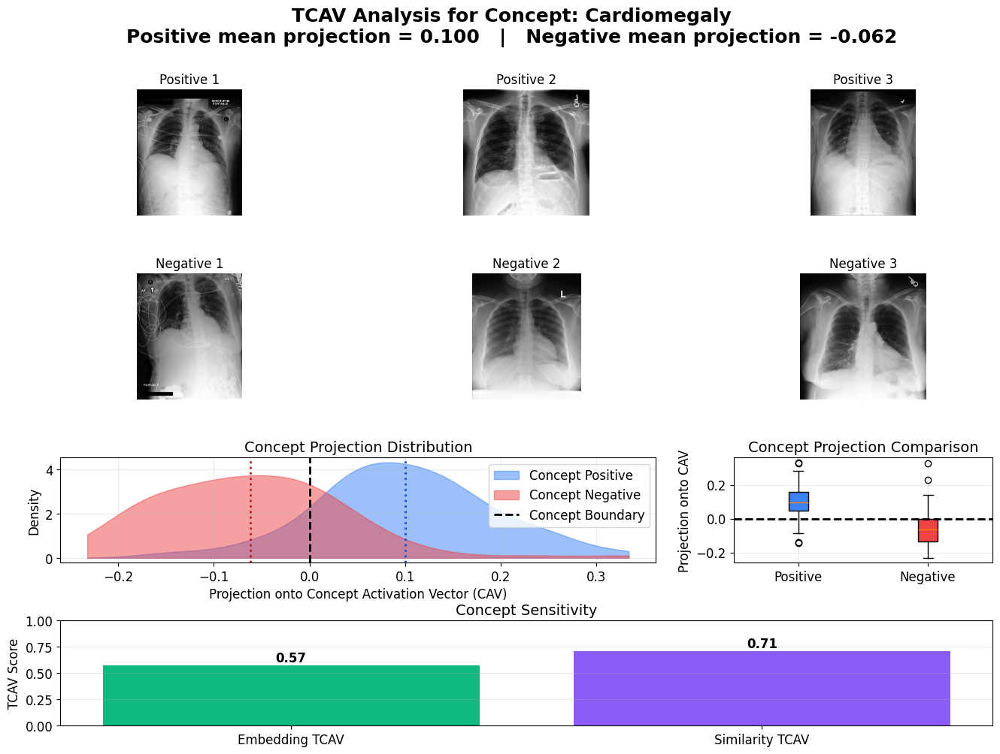

/tmp/ipykernel_1619180/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


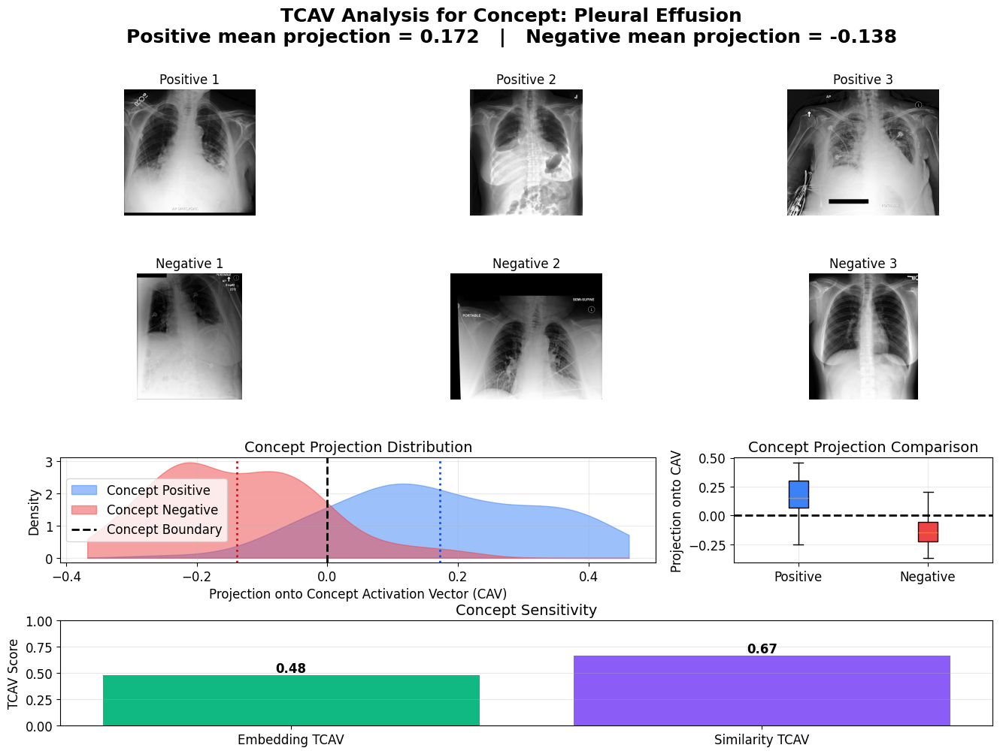

/tmp/ipykernel_1619180/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


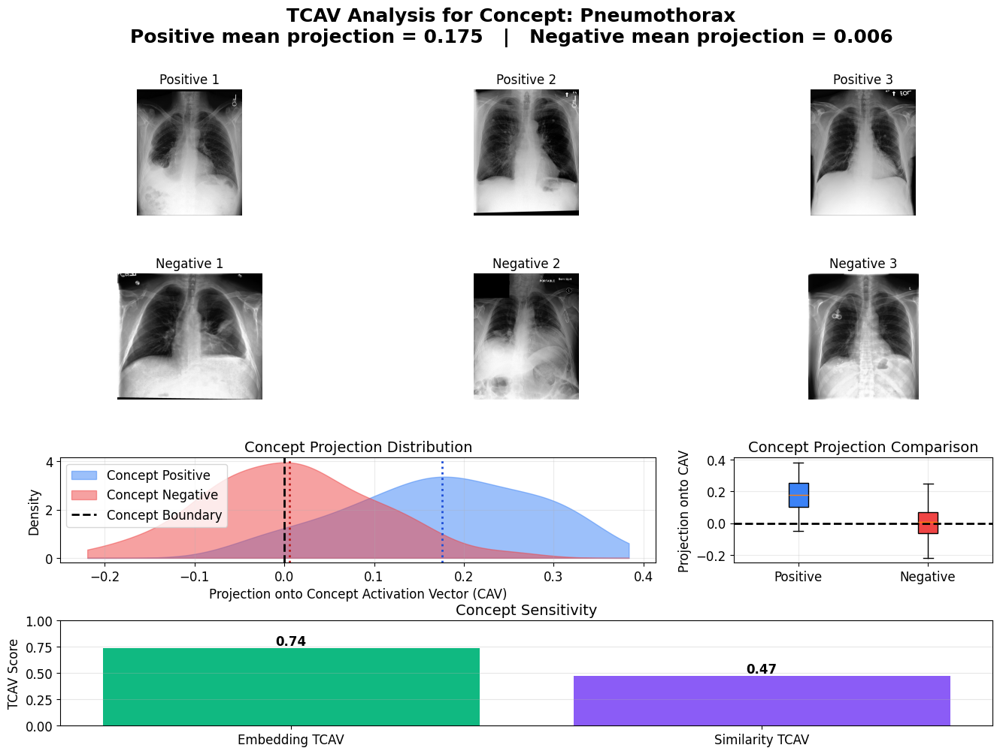

In [47]:

pathologies = [
    "Cardiomegaly",
    "Pleural Effusion",
    "Pneumothorax",
]

concepts = build_single_tcav_concepts(
    single_samples,
    pathologies,
)


for concept_name, data in concepts.items():

    plot_tcav_summary(
        concept_name=concept_name,
        positives=data["positives"],
        negatives=data["negatives"],
        cav=data["cav"],
        tcav_score=data["tcav_emb"],
        similarity_tcav_score=data["tcav_sim"],
    )

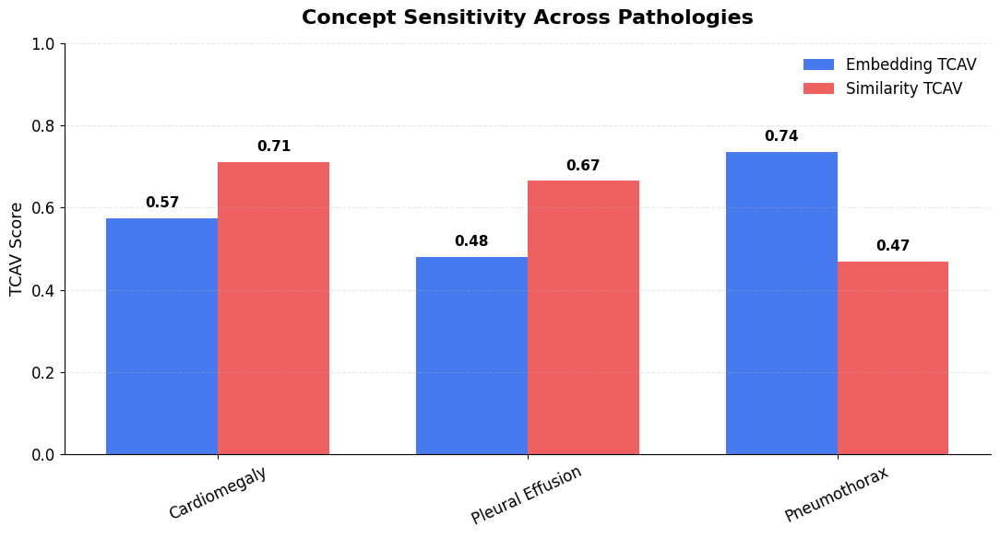

In [48]:
plot_tcav_concept_comparison(concepts)

## Temporal

In [49]:
temporal_pathologies = [
    "Cardiomegaly",
    "Pleural Effusion",
    "Pneumothorax",
]

temporal_concepts = build_temporal_tcav_concepts(
    temporal_samples=temporal_samples,
    pathologies=temporal_pathologies,
    max_positive=100,
    max_negative=100,
    embedding_key="temporal_global_emb",
)


Building temporal TCAV concept: Cardiomegaly
  Positives: 100
  Negatives: 100
  Temporal embedding TCAV: 0.4250
  Temporal similarity TCAV: 0.7950

Building temporal TCAV concept: Pleural Effusion
  Positives: 100
  Negatives: 100
  Temporal embedding TCAV: 0.5950
  Temporal similarity TCAV: 0.7550

Building temporal TCAV concept: Pneumothorax
  Positives: 100
  Negatives: 100
  Temporal embedding TCAV: 0.7000
  Temporal similarity TCAV: 0.4750


/tmp/ipykernel_1619180/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


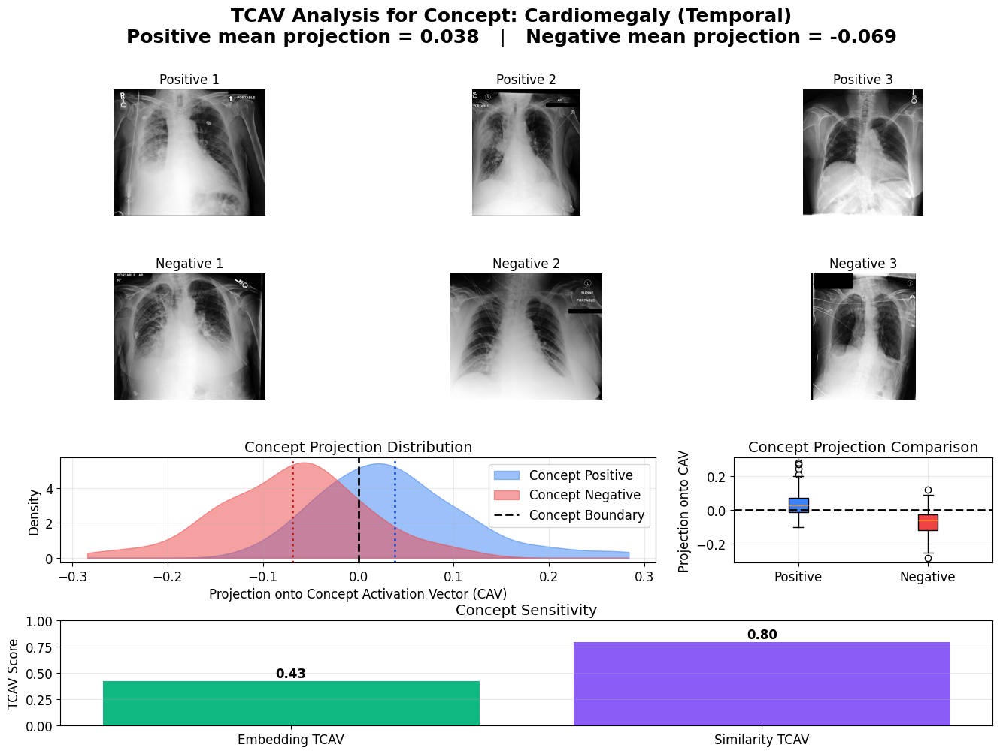

/tmp/ipykernel_1619180/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


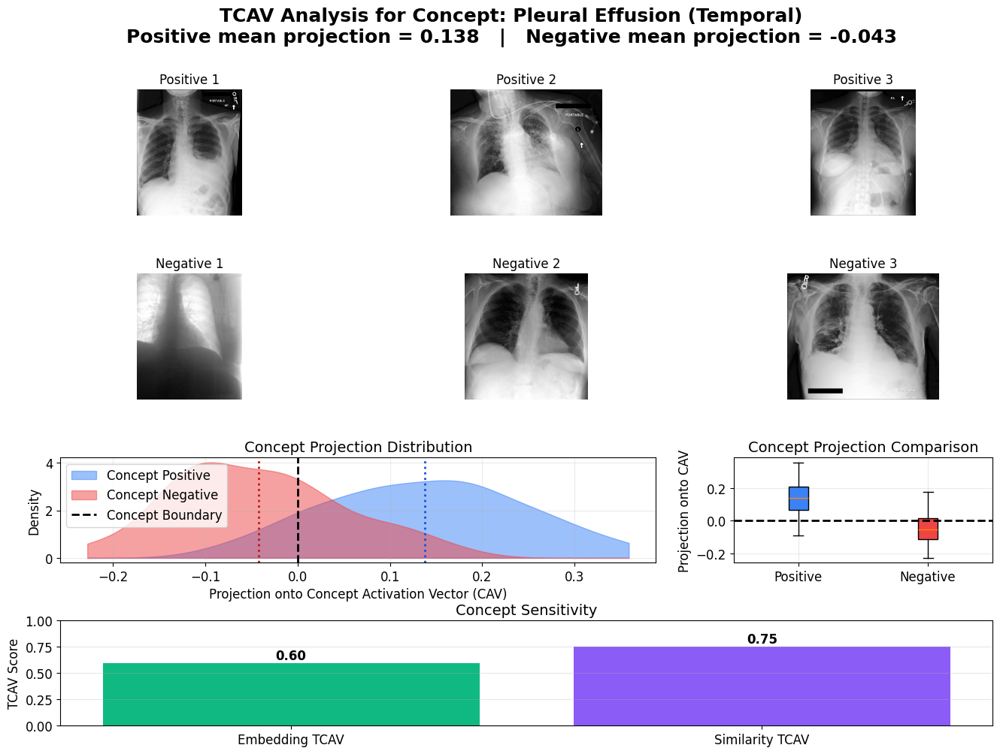

/tmp/ipykernel_1619180/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


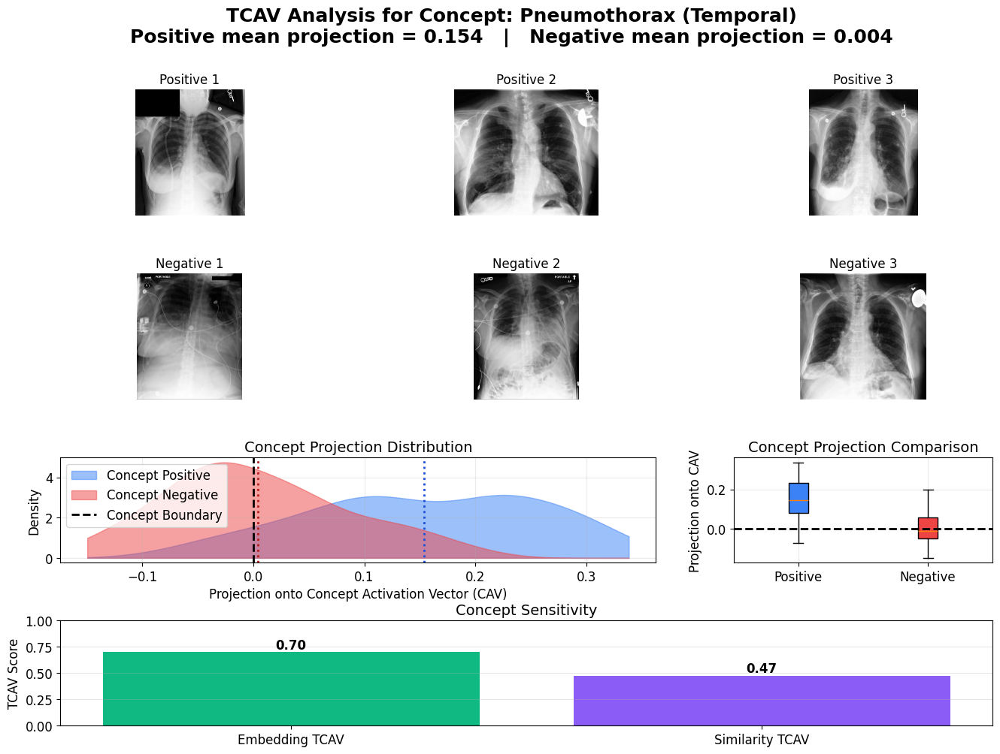

In [50]:
for concept_name, data in temporal_concepts.items():
    for s in data["positives"]:
        s["metadata"]["image_path"] = s["metadata"]["current_image_path"]
    for s in data["negatives"]:
        s["metadata"]["image_path"] = s["metadata"]["current_image_path"]

    plot_tcav_summary(
        concept_name=f"{concept_name} (Temporal)",
        positives=data["positives"],
        negatives=data["negatives"],
        cav=data["cav"],
        tcav_score=data["tcav_emb"],
        similarity_tcav_score=data["tcav_sim"],
        embedding_key="temporal_global_emb",
    )

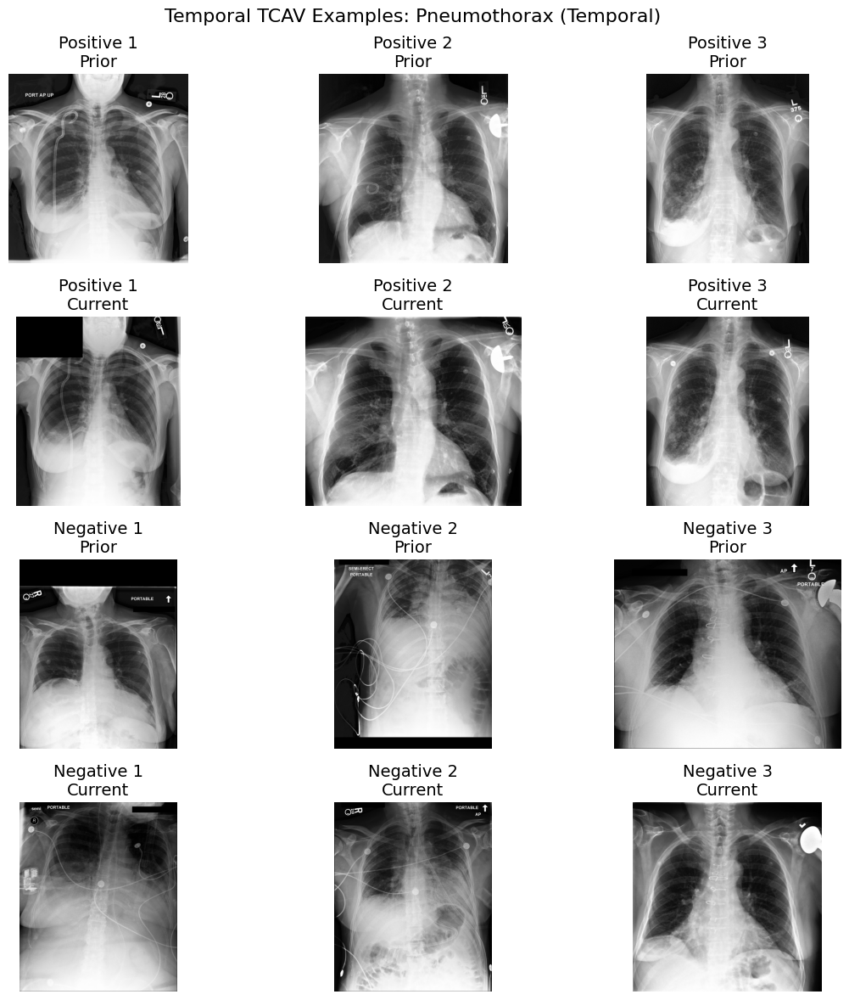

In [51]:
plot_temporal_tcav_examples(
    concept_name=f"{concept_name} (Temporal)",
    positives=data["positives"],
    negatives=data["negatives"],
    num_example_images=3,
    seed=42,
    )

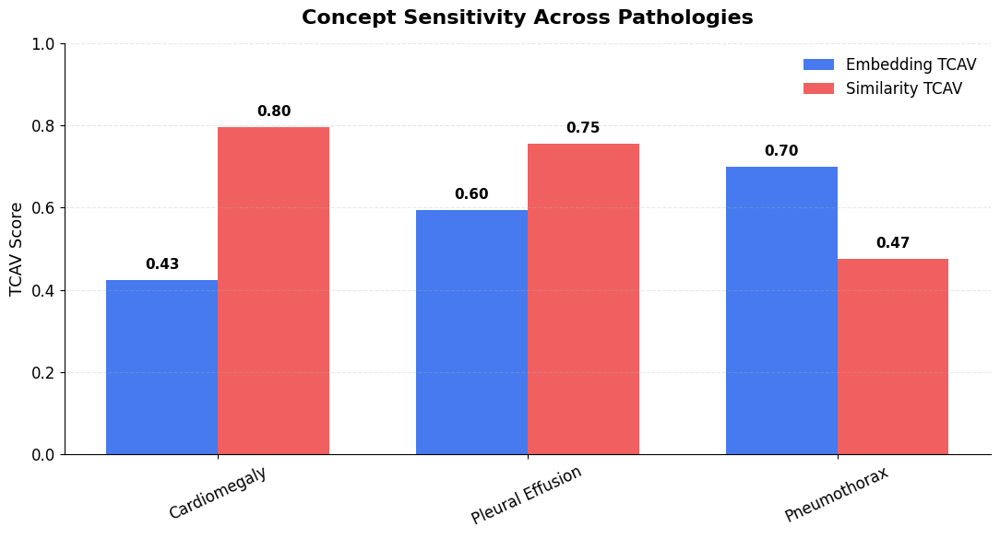

In [52]:
plot_tcav_concept_comparison(temporal_concepts)

# Prototype Retrieval

## Single-Infernce

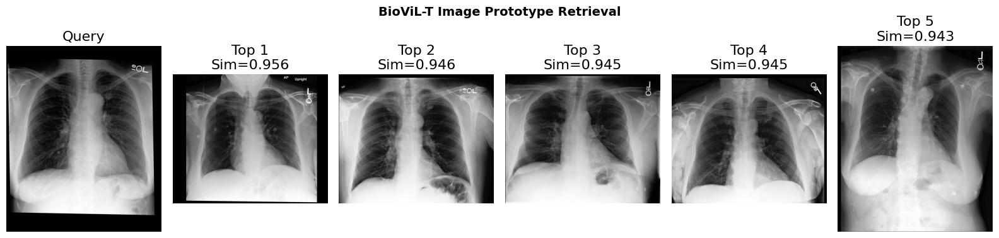

In [53]:
query_sample = single_samples[0]

retrieved = retrieve_prototypes(
    query_embedding=query_sample["image_emb"],
    samples=single_samples,
    embedding_key="image_emb",
    k=5,
    exclude_same_image=True,
    query_image_path=query_sample["metadata"]["image_path"],
)

plot_prototype_retrieval(
    query_sample=query_sample,
    retrieved=retrieved,
    title="BioViL-T Image Prototype Retrieval",
)

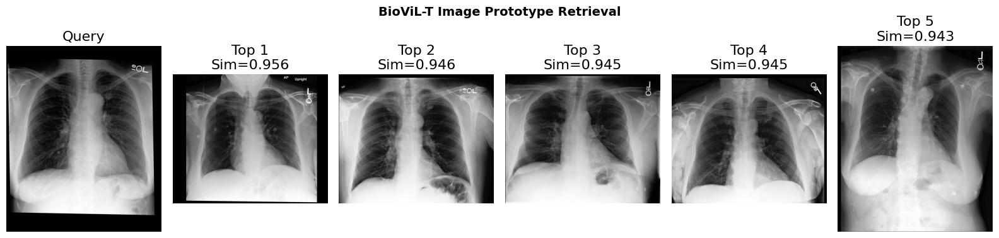

In [54]:
plot_prototype_retrieval(
    query_sample=query_sample,
    retrieved=retrieved,
    title="BioViL-T Image Prototype Retrieval",
)


Query 1/3
Subject ID : 12410764
Study ID   : 55151770
Image      : 0827542e-72e3d380-2c026f3a-eb8f37b1-560ff713.jpg


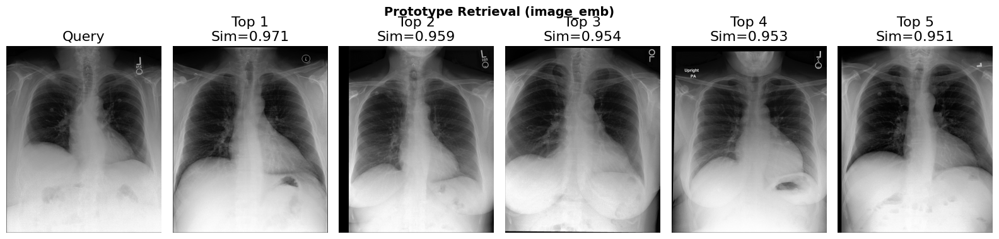


Query 2/3
Subject ID : 10541043
Study ID   : 50169121
Image      : 7fe8144e-7ca26330-27b57e6d-416770e8-30178d1b.jpg


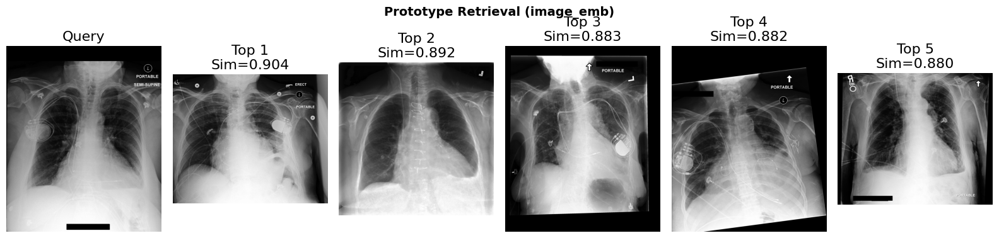


Query 3/3
Subject ID : 16199548
Study ID   : 51470102
Image      : b646a009-e30b47a7-b50de104-c7325b3a-2ce490a3.jpg


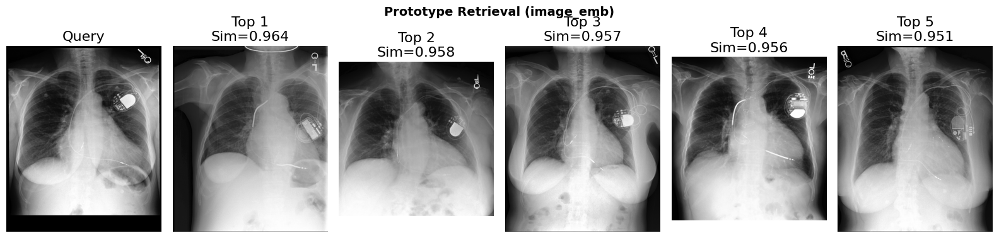

In [55]:
prototype_results = plot_random_prototype_retrieval(
    samples=single_samples,
    embedding_key="image_emb",
    k=5,
    num_queries=3,
)

## Temporal

In [56]:
query_sample = temporal_samples[0]

retrieved = retrieve_prototypes(
    query_embedding=query_sample["temporal_global_emb"],
    samples=temporal_samples,
    embedding_key="temporal_global_emb",
    k=5,
)

# for plotting, use current_image_path as display image
for s in [query_sample] + [r["sample"] for r in retrieved]:
    s["metadata"]["image_path"] = s["metadata"]["current_image_path"]



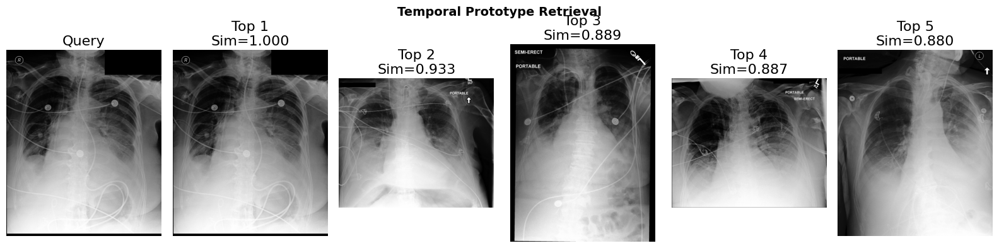

In [57]:
_ = plot_prototype_retrieval(
    query_sample=query_sample,
    retrieved=retrieved,
    title="Temporal Prototype Retrieval",
)


Query 1/3
Subject ID : 19032584
Study ID   : 53860348
Image      : 953d4e68-3f03b779-ac390bc2-018b877d-f91af428.jpg


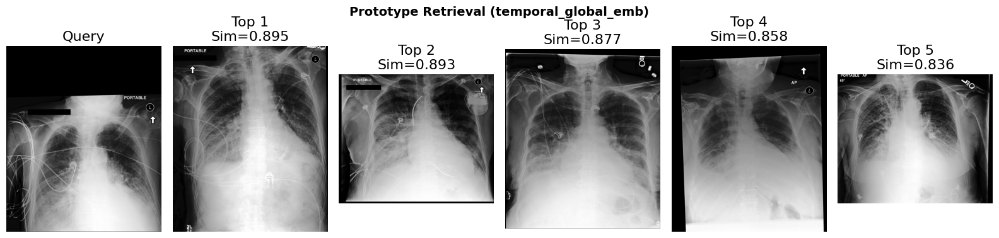


Query 2/3
Subject ID : 13013082
Study ID   : 50165964
Image      : f1740286-e5e65479-d199838e-5e156b63-cc5bcc31.jpg


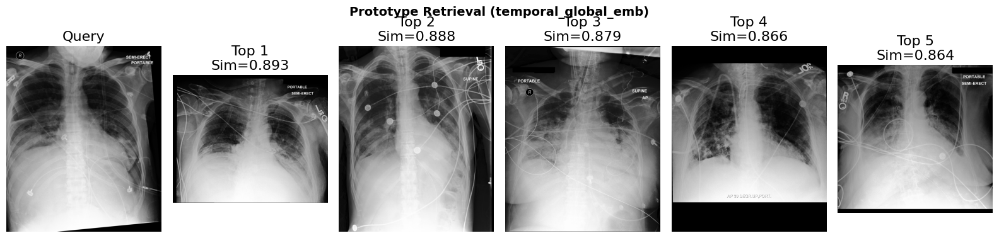


Query 3/3
Subject ID : 10550621
Study ID   : 52635361
Image      : 4b5edb6e-6cfb8b53-799370d0-ad10a07f-1c0988d8.jpg


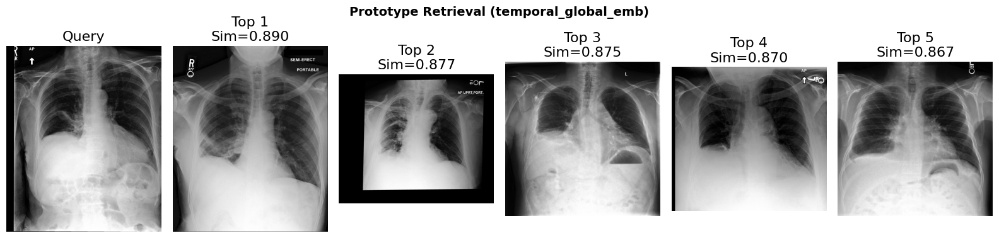

[{'query_sample': {'chunk_path': '/scratch/mtm211/embeddings/biovil_t/temporal/chunks/temporal_chunk_0026.pt',
   'sample_idx': 9,
   'metadata': {'subject_id': 19032584,
    'prior_study_id': 58293729,
    'prior_dicom_id': 'c6d417bd-3668e163-8a0e38ef-64d4e99b-ee28ffd9',
    'current_study_id': 53860348,
    'current_dicom_id': '953d4e68-3f03b779-ac390bc2-018b877d-f91af428',
    'gap_days': 1.0289467592592592,
    'prior_image_path': '/home/links/mtm211/Dataset/Temporal/images/p19/p19032584/s58293729/c6d417bd-3668e163-8a0e38ef-64d4e99b-ee28ffd9.jpg',
    'current_image_path': '/home/links/mtm211/Dataset/Temporal/images/p19/p19032584/s53860348/953d4e68-3f03b779-ac390bc2-018b877d-f91af428.jpg',
    'report_path': '/home/links/mtm211/Dataset/Temporal/Reports/p19/p19032584/s53860348.txt',
    'current_report_text': 'FINAL REPORT\n EXAMINATION:  CHEST (PORTABLE AP)\n \n INDICATION:  ___ year old man with acute on chronic heart failure exacerbation,\n pulmonary effusions, klebsiella pna  //

In [58]:
plot_random_prototype_retrieval(
    samples=temporal_samples,
    embedding_key="temporal_global_emb",
    image_key="current_image_path",
    k=5,
    num_queries=3,
)

## Report

In [59]:
query_sample = single_samples[0]
query_report_text = query_sample["metadata"].get("report_text", "")
query_text_embedding = query_sample["text_emb"]

retrieved_reports = retrieve_reports(
    query_embedding=query_sample["text_emb"],
    samples=single_samples,
    embedding_key="text_emb",
    k=5,
    exclude_same_report=True,
    query_report_text=query_report_text,
)


Query 1/3
Subject ID : 12410764
Study ID   : 55151770


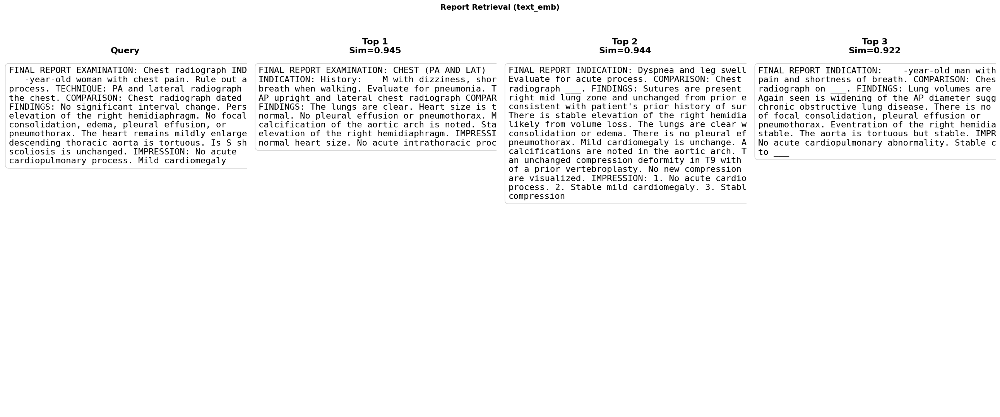


Query 2/3
Subject ID : 10541043
Study ID   : 50169121


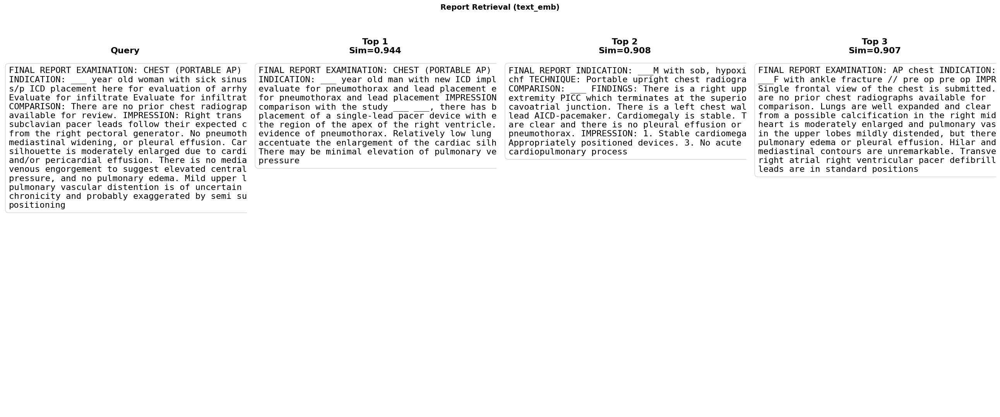


Query 3/3
Subject ID : 16199548
Study ID   : 51470102


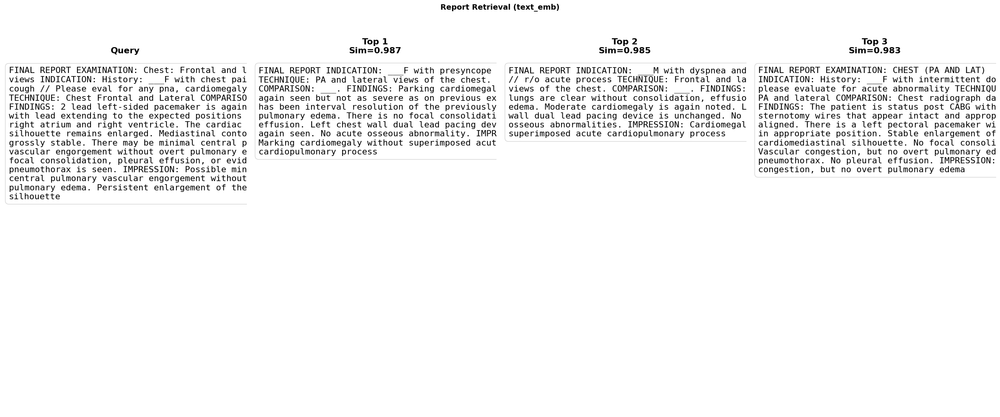

In [60]:
report_results = plot_random_report_retrieval(
    samples=single_samples,
    embedding_key="text_emb",
    text_key="report_text",
    k=3,
    num_queries=3,
)

In [61]:
retrieved_reports = retrieve_reports_from_image(
    query_image_embedding=query_sample["image_emb"],
    samples=single_samples,
    k=5,
)

In [62]:
for r in retrieved_reports:
    sim = r["similarity"]
    sample = r["sample"]

    meta = sample["metadata"]
    report = meta.get("report_text") or meta.get("current_report_text")

    subject = meta.get("subject_id")
    study = meta.get("study_id") or meta.get("current_study_id")

    print("\n-----------------------------------")
    print(f"Similarity : {sim:.3f}")
    print(f"Subject ID : {subject}")
    print(f"Study ID   : {study}")
    print("Report:")
    print(report[:300])


-----------------------------------
Similarity : 0.906
Subject ID : 18888994
Study ID   : 59648566
Report:
FINAL ADDENDUM
 ADDENDUM  There is a partially imaged ovoid lucency projecting over the medial
 proximal left humeral shaft, measuring approximately 5.4 X 0.9 cm.  This
 finding is not well assessed on this study and it is unclear whether this
 artifactual or a lucent bone lesion.  It is unlikely re

-----------------------------------
Similarity : 0.883
Subject ID : 12027869
Study ID   : 52440530
Report:
FINAL REPORT
 HISTORY:  Acute onset chest pain x.
 
 TECHNIQUE:  Frontal and lateral views of the chest. 
 
 COMPARISON:  ___.
 
 FINDINGS:
 
 There is minimal left base atelectasis.  No focal consolidation, pleural
 effusion, or evidence of pneumothorax is seen.  The cardiac and mediastinal
 silhou

-----------------------------------
Similarity : 0.883
Subject ID : 13704052
Study ID   : 50562275
Report:
FINAL REPORT
 HISTORY:  Chest pain. 
 
 TECHNIQUE:  Frontal and lateral vi

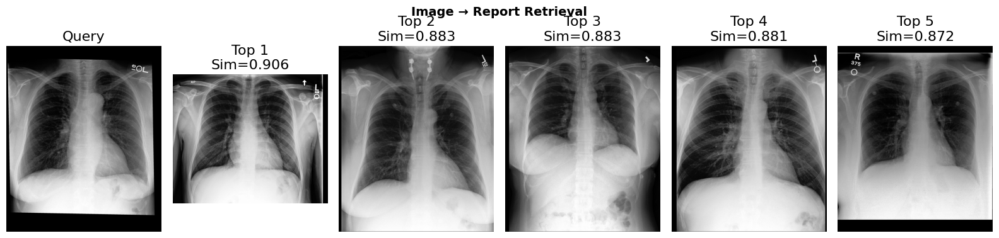

In [63]:
plot_prototype_retrieval(
    query_sample=query_sample,
    retrieved=retrieved_reports,
    title="Image → Report Retrieval",
)

In [64]:
retrieved_images = retrieve_images_from_report(
    query_text_embedding=query_text_embedding,
    samples=single_samples,
    k=5,
    exclude_same_image=True,
    query_image_path=query_sample["metadata"]["image_path"],
)

In [65]:
for r in retrieved_images:
    sim = r["similarity"]
    sample = r["sample"]
    meta = sample["metadata"]

    img_path = meta.get("image_path") or meta.get("current_image_path")
    report = meta.get("report_text") or meta.get("current_report_text")

    print(f"\nSimilarity: {sim:.3f}")
    print(f"Image: {img_path}")
    print(f"Report snippet: {report[:150]}")


Similarity: 0.888
Image: /home/links/mtm211/Dataset/Single/images/p11/p11710089/s50164558/d05e6bcb-86060f17-872810fc-85c49889-d2886380.jpg
Report snippet: FINAL REPORT
 EXAMINATION:  Chest radiograph
 
 INDICATION:  ___-year-old woman with cough for 2 weeks and bibasilar rales. 
 Evaluate for acute on ch

Similarity: 0.865
Image: /home/links/mtm211/Dataset/Single/images/p10/p10490155/s52288727/7ae3717f-c7320639-5d5e72ec-0e4f9376-649dd05f.jpg
Report snippet: FINAL REPORT
 EXAMINATION:  CHEST (PA AND LAT)
 
 INDICATION:  ___M with a PMH of EtOH cirrhosis presenting with decompensated
 cirrhosis and SBP, and

Similarity: 0.864
Image: /home/links/mtm211/Dataset/Single/images/p13/p13725504/s50102721/7967fbbe-9cc80800-89b4a221-7e1ba7f5-c56dd483.jpg
Report snippet: FINAL REPORT
 INDICATION:  ___-year-old male patient with sudden onset of severe pleuritic
 chest pain over the past three days, unable to take full b

Similarity: 0.858
Image: /home/links/mtm211/Dataset/Single/images/p16/p1665948

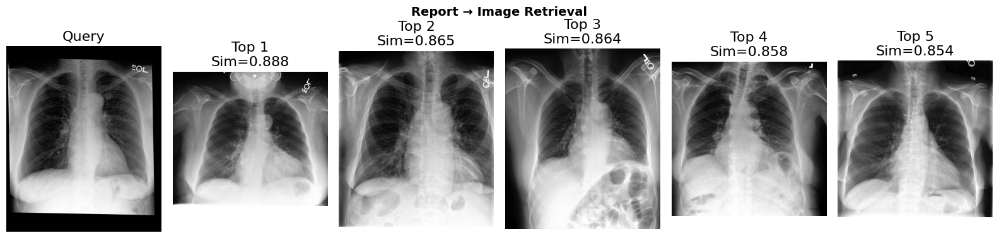

In [66]:
plot_prototype_retrieval(
    query_sample=query_sample,
    retrieved=retrieved_images,
    title="Report → Image Retrieval",
)

# Counterfactuals

In [66]:
def compute_temporal_rollout_maps(
    attentions,
    current_length=196,
    previous_length=196,
    current_first=True,
    grid_size=14,
    image_size=(448, 448),
):
    rollout = attention_rollout(attentions, add_identity=True)[0]

    quads = split_temporal_rollout(
        rollout,
        current_length=current_length,
        previous_length=previous_length,
        current_first=current_first,
        num_prefix_tokens=0,
    )

    heatmaps = {}
    for key, mat in quads.items():
        heat = mean_patch_heatmap(mat, grid_size=grid_size)
        heat = heat - heat.min()
        heat = heat / (heat.max() + 1e-8)
        heatmaps[key] = upsample_heatmap(heat, size=image_size)

    return {
        "rollout": rollout,
        "quadrants": quads,
        "heatmaps": heatmaps,
    }


In [67]:
def plot_baseline_vs_suppressed_temporal_rollout(
    current_image_tensor,
    prior_image_tensor,
    base_maps,
    supp_maps,
    heatmap_key="current_to_current",
    cmap="magma",
    alpha=0.35,
):
    current_arr = current_image_tensor[0].cpu()
    prior_arr = prior_image_tensor[0].cpu()

    base_heat = base_maps["heatmaps"][heatmap_key].cpu()
    supp_heat = supp_maps["heatmaps"][heatmap_key].cpu()
    diff_heat = (base_heat - supp_heat).abs()

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    axes[0, 0].imshow(current_arr, cmap="gray")
    axes[0, 0].set_title("Current CXR")
    axes[0, 0].axis("off")

    axes[1, 0].imshow(prior_arr, cmap="gray")
    axes[1, 0].set_title("Prior CXR")
    axes[1, 0].axis("off")

    axes[0, 1].imshow(current_arr, cmap="gray")
    axes[0, 1].imshow(base_heat, cmap=cmap, alpha=alpha)
    axes[0, 1].set_title(f"Baseline: {heatmap_key}")
    axes[0, 1].axis("off")

    axes[0, 2].imshow(current_arr, cmap="gray")
    axes[0, 2].imshow(supp_heat, cmap=cmap, alpha=alpha)
    axes[0, 2].set_title(f"Suppressed: {heatmap_key}")
    axes[0, 2].axis("off")

    axes[1, 1].imshow(current_arr, cmap="gray")
    axes[1, 1].imshow(diff_heat, cmap=cmap, alpha=alpha)
    axes[1, 1].set_title("Absolute Difference")
    axes[1, 1].axis("off")

    axes[1, 2].axis("off")

    plt.tight_layout()
    plt.show()

In [68]:
def run_temporal_rollout_attention_suppression_test(
    model,
    tokenizer,
    image_processor,
    matched_temporal_samples,
    suppression_config,
    num_samples=10,
    seed=42,
    heatmap_key="current_to_current",
):
    chosen = choose_random_samples(matched_temporal_samples, num_samples=num_samples, seed=seed)
    rows = []

    suppressor = make_attention_suppressor(suppression_config)
    device = next(model.parameters()).device

    for sample in chosen:
        current_image_tensor = load_grayscale_image_tensor(
            sample["metadata"]["current_image_path"],
            image_processor
        )
        prior_image_tensor = load_grayscale_image_tensor(
            sample["metadata"]["prior_image_path"],
            image_processor
        )

        report_text = sample["metadata"].get("current_report_text", "") or ""
        enc = tokenize_text(tokenizer, report_text, device)

        # baseline score
        base_score = biovilt_temporal_similarity_score_with_attention_suppression(
            model=model,
            current_pixel_values=current_image_tensor.unsqueeze(0).to(device),
            prior_pixel_values=prior_image_tensor.unsqueeze(0).to(device),
            input_ids=enc["input_ids"],
            attention_mask=enc["attention_mask"],
            suppressor=None,
        )[0].item()

        # suppressed score
        supp_score = biovilt_temporal_similarity_score_with_attention_suppression(
            model=model,
            current_pixel_values=current_image_tensor.unsqueeze(0).to(device),
            prior_pixel_values=prior_image_tensor.unsqueeze(0).to(device),
            input_ids=enc["input_ids"],
            attention_mask=enc["attention_mask"],
            suppressor=suppressor,
        )[0].item()

        # baseline attentions
        _, base_attns = get_temporal_attentions_with_optional_suppression(
            model=model,
            current_image_tensor=current_image_tensor,
            prior_image_tensor=prior_image_tensor,
            suppressor=None,
        )
        base_maps = compute_temporal_rollout_maps(base_attns)

        # suppressed attentions
        _, supp_attns = get_temporal_attentions_with_optional_suppression(
            model=model,
            current_image_tensor=current_image_tensor,
            prior_image_tensor=prior_image_tensor,
            suppressor=suppressor,
        )
        supp_maps = compute_temporal_rollout_maps(supp_attns)

        base_heat = base_maps["heatmaps"][heatmap_key]
        supp_heat = supp_maps["heatmaps"][heatmap_key]
        heatmap_change = (base_heat - supp_heat).abs().mean().item()

        rows.append({
            "subject_id": sample["metadata"].get("subject_id"),
            "current_study_id": sample["metadata"].get("current_study_id"),
            "current_dicom_id": sample["metadata"].get("current_dicom_id"),
            "baseline_score": base_score,
            "suppressed_score": supp_score,
            "score_drop": base_score - supp_score,
            "mean_abs_rollout_change": heatmap_change,
            "suppressed_quadrant": suppression_config.quadrant,
        })

    return pd.DataFrame(rows)

In [69]:
def plot_latent_counterfactuals(latent_cf_df: pd.DataFrame):
    fig, ax = plt.subplots(figsize=(8, 5))

    cols = [
        "original_similarity",
        "toward_concept_similarity",
        "away_concept_similarity",
    ]

    ax.boxplot([latent_cf_df[c].dropna().values for c in cols], tick_labels=[
        "Original", "Toward", "Away"
    ])

    ax.set_title("Latent-Space Counterfactual Similarity")
    ax.set_ylabel("Image-Text Similarity")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [70]:
def plot_textual_counterfactuals(text_cf_df: pd.DataFrame):
    fig, ax = plt.subplots(figsize=(8, 5))

    for _, row in text_cf_df.iterrows():
        ax.plot(
            [0, 1],
            [row["original_score"], row["counterfactual_score"]],
            marker="o",
            alpha=0.6,
        )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Original Text", "Counterfactual Text"])
    ax.set_ylabel("Similarity Score")
    ax.set_title("Textual Counterfactuals")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [71]:
def plot_temporal_counterfactuals(temporal_cf_df: pd.DataFrame):
    fig, ax = plt.subplots(figsize=(8, 5))

    for _, row in temporal_cf_df.iterrows():
        ax.plot(
            [0, 1, 2],
            [
                row["temporal_score"],
                row["mismatched_prior_score"],
                row["current_only_score"],
            ],
            marker="o",
            alpha=0.6,
        )

    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(["Correct Prior", "Mismatched Prior", "Current Only"])
    ax.set_ylabel("Similarity Score")
    ax.set_title("Temporal Counterfactual Variations")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [72]:
def plot_attention_suppression_summary(attn_cf_df: pd.DataFrame, title="Attention Suppression"):
    fig, ax = plt.subplots(figsize=(8, 5))

    for _, row in attn_cf_df.iterrows():
        ax.plot(
            [0, 1],
            [row["original_score"], row["suppressed_score"]],
            marker="o",
            alpha=0.6,
        )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Baseline", "Suppressed"])
    ax.set_ylabel("Similarity Score")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [73]:
def plot_counterfactual_summary(
    text_cf_df: pd.DataFrame,
    temporal_cf_df: pd.DataFrame,
    latent_cf_df: pd.DataFrame,
    attn_cf_df: pd.DataFrame,
):
    summary = {
        "Textual drop": text_cf_df["score_drop"].mean(),
        "Temporal mismatch drop": temporal_cf_df["drop_with_mismatch"].mean(),
        "Temporal no-prior drop": temporal_cf_df["drop_without_prior"].mean(),
        "Attention suppression drop": attn_cf_df["score_drop"].mean(),
        "Latent toward delta": latent_cf_df["toward_delta"].mean(),
        "Latent away delta": latent_cf_df["away_delta"].mean(),
    }

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(list(summary.keys()), list(summary.values()))
    ax.set_ylabel("Mean Effect")
    ax.set_title("Summary of Counterfactual Effects")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [75]:
cf_ctx = init_biovilt_counterfactuals()
model = cf_ctx["model"]
tokenizer = cf_ctx["tokenizer"]
image_processor=cf_ctx["image_processor"]
device = cf_ctx["device"]

matched_temporal_samples = build_matched_temporal_samples(temporal_samples)
matched_single_samples = build_matched_single_samples(single_samples)

/home/links/mtm211/.conda/envs/biovil_env/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of the model checkpoint at microsoft/BiomedVLP-BioViL-T were not used when initializing CXRBertModel: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing CXRBertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing CXRBertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Temporal pooler found: <class 'models.biovil_t.transformer.VisionTransformerPooler'>


In [76]:
cfg = AttentionSuppressionConfig(
    target="temporal_quadrant",
    current_length=196,
    previous_length=196,
    quadrant="current_to_current",
    mode="zero",
    renormalize=True,
)

temporal_sample = matched_temporal_samples[0]

current_image_tensor = load_grayscale_image_tensor(
    temporal_sample["metadata"]["current_image_path"],
    image_processor=image_processor,
)
prior_image_tensor = load_grayscale_image_tensor(
    temporal_sample["metadata"]["prior_image_path"],
    image_processor=image_processor,
)

_, base_attns = get_temporal_attentions_with_optional_suppression(
    model=model,
    current_image_tensor=current_image_tensor,
    prior_image_tensor=prior_image_tensor,
    suppressor=None,
)

base_maps = compute_temporal_rollout_maps(base_attns)

suppressor = make_attention_suppressor(cfg)


In [77]:
temporal_attn_cf_df = run_true_attention_suppression_temporal_random(
    model=model,
    tokenizer=tokenizer,
    image_processor=image_processor,
    matched_temporal_samples=matched_temporal_samples,
    suppression_config=cfg,
    num_samples=10,
    seed=42
)

temporal_attn_cf_df

temporal_attn_summary = summarize_counterfactual_df(
    temporal_attn_cf_df,
    ["original_score", "suppressed_score", "score_drop"],
)

display(temporal_attn_summary)

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0011171447113156319
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0010254164226353168
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.001196915633045137
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0012479234719648957
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.001272046472877264
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0013204211136326194
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.00113138637971133
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0010901116766035557
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0010488976258784533
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0013712806394323707
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0011015819618478417
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0011500382097437978
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.001156918820925057
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0011262474581599236
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0010648515308275819
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0011508989846333861
SUPRESSOR ACTIVE
MEAN ABS ATT

,original_score,suppressed_score,score_drop
mean,0.766237,0.765078,0.001159


In [78]:
temporal_rollout_supp_df = run_temporal_rollout_attention_suppression_test(
    model=model,
    tokenizer=tokenizer,
    image_processor=image_processor,
    matched_temporal_samples=matched_temporal_samples,
    suppression_config=cfg,
    num_samples=10,
    seed=42,
    heatmap_key="current_to_current",
)

temporal_rollout_supp_df

temporal_rollout_supp_df[["baseline_score", "suppressed_score", "score_drop", "mean_abs_rollout_change"]].mean()

SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0011171447113156319
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0010254164226353168
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.001196915633045137
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0011171447113156319
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0010254164226353168
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.001196915633045137
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0012479234719648957
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.001272046472877264
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0013204211136326194
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0012479234719648957
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.001272046472877264
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0013204211136326194
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.00113138637971133
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0010901116766035557
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0010488976258784533
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.00113138637971133
SUPRESSOR ACTIVE
MEAN ABS ATTN C

baseline_score             0.766237
suppressed_score           0.765078
score_drop                 0.001159
mean_abs_rollout_change    0.038793
dtype: float64

SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.001152112614363432
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0010360669111832976
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0010445377556607127


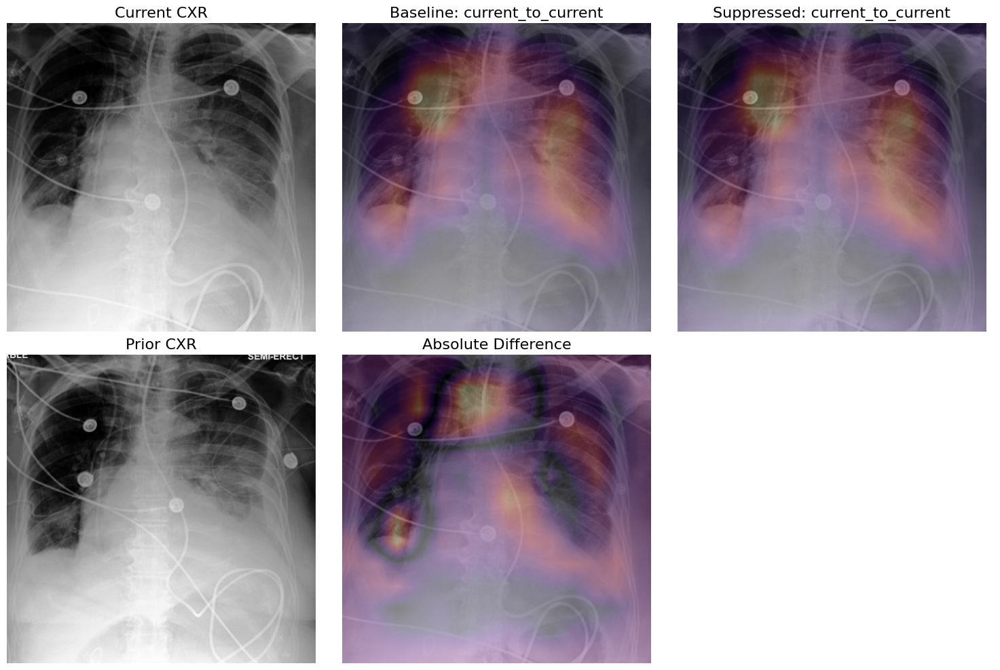

In [79]:
_, supp_attns = get_temporal_attentions_with_optional_suppression(
    model=model,
    current_image_tensor=current_image_tensor,
    prior_image_tensor=prior_image_tensor,
    suppressor=suppressor,
)

supp_maps = compute_temporal_rollout_maps(supp_attns)

plot_baseline_vs_suppressed_temporal_rollout(
    current_image_tensor=current_image_tensor,
    prior_image_tensor=prior_image_tensor,
    base_maps=base_maps,
    supp_maps=supp_maps,
    heatmap_key="current_to_current",
)

In [80]:
quadrants = [
    "current_to_current",
    "current_to_previous",
    "previous_to_current",
    "previous_to_previous",
]

dfs = []
for q in quadrants:
    df = run_temporal_rollout_attention_suppression_test(
        model=model,
        tokenizer=tokenizer,
        image_processor=image_processor,
        matched_temporal_samples=matched_temporal_samples,
        suppression_config=cfg,
        num_samples=10,
        seed=42,
        heatmap_key="current_to_current",
    )
    df["quadrant"] = q
    dfs.append(df)

all_temporal_supp_df = pd.concat(dfs, ignore_index=True)
all_temporal_supp_df.groupby("quadrant")[["score_drop", "mean_abs_rollout_change"]].mean()

SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0011171447113156319
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0010254164226353168
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.001196915633045137
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0011171447113156319
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0010254164226353168
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.001196915633045137
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0012479234719648957
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.001272046472877264
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0013204211136326194
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0012479234719648957
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.001272046472877264
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0013204211136326194
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.00113138637971133
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0010901116766035557
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.0010488976258784533
SUPRESSOR ACTIVE
MEAN ABS ATTN CHANGE: 0.00113138637971133
SUPRESSOR ACTIVE
MEAN ABS ATTN C

,score_drop,mean_abs_rollout_change
quadrant,,
current_to_current,0.001159,0.038793
current_to_previous,0.001159,0.038793
previous_to_current,0.001159,0.038793
previous_to_previous,0.001159,0.038793


In [81]:
def negate_text(text: str) -> str:
    return "No cardiomegaly. No pleural effusion. No pneumothorax."

text_cf_df = run_textual_counterfactuals_random(
    model=model,
    tokenizer=tokenizer,
    image_processor=image_processor,
    matched_single_samples=matched_single_samples,
    counterfactual_fn=negate_text,
    num_samples=10,
    seed=42,
)

text_cf_df

text_summary = summarize_counterfactual_df(
    text_cf_df,
    ["original_score", "counterfactual_score", "score_drop"],
)
display(text_summary)

,original_score,counterfactual_score,score_drop
mean,0.672133,-0.06399,0.736123


In [82]:
temporal_cf_df = run_temporal_counterfactuals_random(
    model=model,
    tokenizer=tokenizer,
    image_processor=image_processor,
    matched_temporal_samples=matched_temporal_samples,
    num_samples=10,
    seed=42,
)

temporal_cf_df

temporal_summary = summarize_counterfactual_df(
    temporal_cf_df,
    ["temporal_score", "mismatched_prior_score", "current_only_score", "drop_with_mismatch", "drop_without_prior"],
)

display(temporal_summary)

,temporal_score,mismatched_prior_score,current_only_score,drop_with_mismatch,drop_without_prior
mean,0.766237,0.739849,0.626918,0.026389,0.139319


In [83]:
positives, negatives = select_single_samples(
    single_samples,
    concept_name="Cardiomegaly",
    max_positive=100,
    max_negative=100,
)

cav = build_cav_from_samples(
    positives=positives,
    negatives=negatives,
    embedding_key="image_emb",
)

latent_cf_df = run_latent_counterfactuals_random(
    matched_single_samples=matched_single_samples,
    concept_vector=cav,
    num_samples=50,
    seed=42,
    epsilon=0.10,
)

latent_cf_df

latent_summary = summarize_counterfactual_df(
    latent_cf_df,
    ["original_similarity", "toward_concept_similarity", "away_concept_similarity", "toward_delta", "away_delta"],
)
display(latent_summary)

,original_similarity,toward_concept_similarity,away_concept_similarity,toward_delta,away_delta
mean,0.707703,0.707249,0.701231,-0.000454,-0.006471


# CXR-CLIP

In [ ]:
pipeline = init_cxr_clip_pipeline(
    checkpoint_path="models/cxr_clip/r50_m.tar",
    repo_root="models/cxr_clip/cxr-clip",
    device="cuda",
)

I0000 00:00:1777422593.123786 1644890 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1777422593.160316 1644890 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1777422595.436412 1644890 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/links/mtm211/.conda/envs/biovil_env/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: Fu

[load_cxr_clip] Unexpected keys: 3


In [ ]:
results = run_cxr_clip_calibration_and_evaluation(
    pipeline=pipeline,
    csv_path="Dataset/Single/single_dataset.csv",
    output_dir="calibration",
    test_size=0.2,
    random_state=42,
    use_saved_embeddings=True,
    batch_size=16,
    num_workers=0,
    threshold_objective="f1",
)

In [33]:
test_results_cal = results["test_results_cal"]
test_metrics_df = results["test_metrics_df"]
threshold_table = results["threshold_table"]

In [34]:
threshold_table
test_metrics_df

,label,tp,fp,tn,fn,precision,recall,specificity,accuracy,balanced_accuracy,f1
0,Pneumothorax,146,676,1075,103,0.177616,0.586345,0.613935,0.6105,0.600140,0.272642
1,Pleural Effusion,610,251,843,296,0.708479,0.673289,0.770567,0.7265,0.721928,0.690436
2,Support Devices,907,481,427,185,0.653458,0.830586,0.470264,0.6670,0.650425,0.731452
3,Consolidation,198,590,1129,83,0.251269,0.704626,0.656777,0.6635,0.680702,0.370440
4,Cardiomegaly,608,427,764,201,0.587440,0.751545,0.641478,0.6860,0.696511,0.659436
5,Atelectasis,790,724,353,133,0.521797,0.855905,0.327762,0.5715,0.591833,0.648338
6,Edema,352,216,1196,236,0.619718,0.598639,0.847025,0.7740,0.722832,0.608997
7,No Finding,103,93,1592,212,0.525510,0.326984,0.944807,0.8475,0.635896,0.403131


In [35]:
results["calibration_result_source"], results["test_result_source"]

('loaded', 'loaded')

In [36]:
label = "Pleural Effusion"

tp_df = test_results_cal[
    (test_results_cal[f"{label}_true"] == 1) &
    (test_results_cal[f"{label}_pred_calibrated"] == 1)
].sort_values(f"{label}_margin", ascending=False)

tp_df[[ "image_path", f"{label}_margin" ]].head()

,image_path,Pleural Effusion_margin
602,/home/links/mtm211/Dataset/Single/images/p14/p...,0.356069
261,/home/links/mtm211/Dataset/Single/images/p11/p...,0.340954
1106,/home/links/mtm211/Dataset/Single/images/p17/p...,0.311141
458,/home/links/mtm211/Dataset/Single/images/p12/p...,0.302885
1559,/home/links/mtm211/Dataset/Single/images/p13/p...,0.294744


In [37]:
row = tp_df.iloc[0]

test_df = results["test_df"]

sample_df = test_df[test_df["image_path"] == row["image_path"]].reset_index(drop=True)
sample_dataset = CXRClipInferenceDataset(sample_df, transform=pipeline["preprocess"])
sample = sample_dataset[0]

In [38]:
output = predict_sample(pipeline, sample)

print("Image:", sample["image_path"])
print("True:", output["true_labels"][label])
print("Pred:", output["results"][label]["pred"])
print("Margin:", output["results"][label]["margin"])

Image: /home/links/mtm211/Dataset/Single/images/p14/p14043015/s55036323/434385a0-c9d2fce1-37bbdc51-56e6d16e-e4c9adf3.jpg
True: 1.0
Pred: 1.0
Margin: 0.35612117499113083


In [39]:
def get_single_pathology_cases(df, label, labels_of_interest, n=None):
    other_labels = [l for l in labels_of_interest if l != label]

    mask = (df[f"{label}_true"] == 1)
    for other in other_labels:
        mask &= (df[f"{other}_true"] == 0)

    cols = [
        "subject_id",
        "study_id",
        "dicom_id",
        "image_path",
    ]

    for l in labels_of_interest:
        cols.append(f"{l}_true")

    for l in labels_of_interest:
        pred_col = f"{l}_pred_calibrated"
        if pred_col in df.columns:
            cols.append(pred_col)

    for l in labels_of_interest:
        margin_col = f"{l}_margin"
        if margin_col in df.columns:
            cols.append(margin_col)

    out = df.loc[mask, cols].reset_index(drop=True)

    if n is not None:
        out = out.head(n)

    return out

In [40]:
def get_random_single_pathology_case(df, label, labels_of_interest, random_state=None):
    other_labels = [l for l in labels_of_interest if l != label]

    mask = (df[f"{label}_true"] == 1)
    for other in other_labels:
        mask &= (df[f"{other}_true"] == 0)

    candidate_df = df.loc[mask].copy()

    if len(candidate_df) == 0:
        return None

    return candidate_df.sample(n=1, random_state=random_state).iloc[0]

In [41]:
TARGET_CASE_LABELS = [
    "Pneumothorax",
    "Pleural Effusion",
    "Support Devices",
    "Consolidation",
    "Cardiomegaly",
    "Atelectasis",
    "Edema",
    "No Finding",
]

random_cases = {}

for i, label in enumerate(TARGET_CASE_LABELS):
    row = get_random_single_pathology_case(
        df=test_results_cal,
        label=label,
        labels_of_interest=TARGET_CASE_LABELS,
        random_state=42 + i,
    )

    if row is not None:
        random_cases[label] = row
        
for label, row in random_cases.items():
    print(
        label,
        row["subject_id"],
        row["study_id"],
        row["dicom_id"],
        row["image_path"],
    )


Pneumothorax tensor(17639884) tensor(51347500) baf74b61-aa4e321e-0fad463a-99169ebe-b467f433 /home/links/mtm211/Dataset/Single/images/p17/p17639884/s51347500/baf74b61-aa4e321e-0fad463a-99169ebe-b467f433.jpg
Pleural Effusion tensor(16773909) tensor(52995219) b5333b33-2d7a0404-9e2f5dd2-c7e8a0c4-5bef905e /home/links/mtm211/Dataset/Single/images/p16/p16773909/s52995219/b5333b33-2d7a0404-9e2f5dd2-c7e8a0c4-5bef905e.jpg
Support Devices tensor(17556194) tensor(59125363) 49875266-46459ce6-787cfda1-acd158b5-9e91e2bc /home/links/mtm211/Dataset/Single/images/p17/p17556194/s59125363/49875266-46459ce6-787cfda1-acd158b5-9e91e2bc.jpg
Consolidation tensor(12691833) tensor(59271253) 222562f4-a19b517d-019d4f05-81ece1b2-c647ca60 /home/links/mtm211/Dataset/Single/images/p12/p12691833/s59271253/222562f4-a19b517d-019d4f05-81ece1b2-c647ca60.jpg
Cardiomegaly tensor(13464394) tensor(55263156) ae13fe1c-9fd244b3-1523fa5a-7d594f1a-a6c0a8db /home/links/mtm211/Dataset/Single/images/p13/p13464394/s55263156/ae13fe1c-9f

## Similarity-Based Mapping

In [95]:
SAVE_DIR = OUTPUT_ROOT / "Similarity-Based"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

In [96]:
def get_sample_from_row(row, test_df, pipeline):
    sample_df = test_df[test_df["image_path"] == row["image_path"]].reset_index(drop=True)
    sample_dataset = CXRClipInferenceDataset(
        sample_df,
        transform=pipeline["preprocess"],
    )
    return sample_dataset[0]

In [97]:
def plot_random_cases_different_pathologies(
    random_cases,
    test_df,
    pipeline,
    alpha=0.35,
    cmap="magma",
    use_margin=True,
    show_original=True,
    max_path_chars=70,
    save_dir=None,
    dpi=300,
):
    """
    Plot one random case per pathology with a clean dissertation-style layout.

    Parameters
    ----------
    random_cases : dict
        Mapping: label -> row (from test_results_cal)
    test_df : pd.DataFrame
        Original held-out test dataframe
    pipeline : dict
        Initialized CXR-CLIP pipeline
    alpha : float
        Overlay opacity
    cmap : str
        Heatmap colormap
    use_margin : bool
        Whether to use positive-minus-negative similarity map
    show_original : bool
        If True, show original image beside overlay
    max_path_chars : int
        Truncate displayed image path for readability
    save_dir : str | Path | None
        If provided, save each figure there
    dpi : int
        Figure save resolution
    """
    if len(random_cases) == 0:
        print("No random cases provided.")
        return

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

    labels = list(random_cases.keys())

    for idx, label in enumerate(labels, start=1):
        row = random_cases[label]

        sample = get_sample_from_row(row, test_df, pipeline)
        heatmap = generate_similarity_relevance_map(
            pipeline=pipeline,
            image_tensor=sample["image"],
            label=label,
            use_margin=use_margin,
        )

        img = sample["image"].detach().cpu().permute(1, 2, 0).numpy()
        img = img - img.min()
        if img.max() > 0:
            img = img / img.max()

        image_path = str(row["image_path"])
        short_path = image_path if len(image_path) <= max_path_chars else "..." + image_path[-max_path_chars:]

        print("\n" + "=" * 90)
        print(f"Sample        : {idx}/{len(labels)}")
        print(f"Pathology     : {label}")
        print(f"Subject ID    : {row.get('subject_id', 'N/A')}")
        print(f"Study ID      : {row.get('study_id', 'N/A')}")
        print(f"DICOM ID      : {row.get('dicom_id', 'N/A')}")
        print(f"Image         : {Path(image_path).name}")
        print(f"Image Path    : {short_path}")
        print(f"Ground Truth  : {int(row.get(f'{label}_true', 0))}")
        pred_col = f"{label}_pred_calibrated"
        if pred_col in row.index:
            print(f"Prediction    : {int(row[pred_col])}")
        margin_col = f"{label}_margin"
        if margin_col in row.index:
            print(f"Margin        : {row[margin_col]:.3f}")

        if show_original:
            fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)

            axes[0].imshow(img)
            axes[0].set_title("Original image", fontsize=11)
            axes[0].axis("off")

            axes[1].imshow(img)
            axes[1].imshow(heatmap, cmap=cmap, alpha=alpha)
            axes[1].set_title(f"{label} relevance map", fontsize=11)
            axes[1].axis("off")
        else:
            fig, ax = plt.subplots(1, 1, figsize=(5.5, 5.5), constrained_layout=True)
            ax.imshow(heatmap, cmap=cmap)
            ax.set_title(f"{label} relevance map", fontsize=11)
            ax.axis("off")

        fig.suptitle(
            f"{label} | Subject {row.get('subject_id', 'N/A')} | DICOM {row.get('dicom_id', 'N/A')}",
            fontsize=12,
        )

        if save_dir is not None:
            safe_label = label.replace(" ", "_")
            fname = f"{idx:02d}_{safe_label}_subj_{row.get('subject_id', 'NA')}_dicom_{row.get('dicom_id', 'NA')}.png"
            fig.savefig(save_dir / fname, dpi=dpi, bbox_inches="tight")

        plt.show()

        savefig(
        "cxr_clip/similarity_relevance",
        f"{label.replace(' ', '_')}_subject_{row.get('subject_id', 'NA')}.png"
        )
        
        plt.show()
        
        plt.close(fig)

In [98]:
def get_sample_from_row(row, test_df, pipeline):
    sample_df = test_df[test_df["image_path"] == row["image_path"]].reset_index(drop=True)
    sample_dataset = CXRClipInferenceDataset(
        sample_df,
        transform=pipeline["preprocess"],
    )
    return sample_dataset[0]

In [99]:
def get_case_by_type(test_results_cal, label, case_type="tp", random_state=42):
    """
    Get a case row by type: 'tp', 'fp', 'tn', 'fn'
    """
    true_col = f"{label}_true"
    pred_col = f"{label}_pred_calibrated"
    margin_col = f"{label}_margin"

    if case_type == "tp":
        mask = (test_results_cal[true_col] == 1) & (test_results_cal[pred_col] == 1)
    elif case_type == "fp":
        mask = (test_results_cal[true_col] == 0) & (test_results_cal[pred_col] == 1)
    elif case_type == "tn":
        mask = (test_results_cal[true_col] == 0) & (test_results_cal[pred_col] == 0)
    elif case_type == "fn":
        mask = (test_results_cal[true_col] == 1) & (test_results_cal[pred_col] == 0)
    else:
        raise ValueError(f"Unknown case_type: {case_type}")

    candidates = test_results_cal[mask]
    if len(candidates) == 0:
        return None

    return candidates.sample(n=1, random_state=random_state).iloc[0]


In [100]:
def plot_tp_fp_tn_comparison(
    label,
    test_results_cal,
    test_df,
    pipeline,
    alpha=0.35,
    cmap="magma",
    save_path=None,
    dpi=300,
    random_state=42,
):
    """
    Side-by-side comparison of TP, FP, TN for one pathology.
    """
    case_types = ["tp", "fp", "tn"]
    case_labels = ["True Positive", "False Positive", "True Negative"]
    rows_data = []

    for ct in case_types:
        row = get_case_by_type(test_results_cal, label, case_type=ct, random_state=random_state)
        rows_data.append(row)

    # Count available cases
    available = [(ct, cl, r) for ct, cl, r in zip(case_types, case_labels, rows_data) if r is not None]
    if len(available) == 0:
        print(f"No cases available for {label}")
        return

    n_cases = len(available)
    fig, axes = plt.subplots(2, n_cases, figsize=(6 * n_cases, 10), constrained_layout=True)

    if n_cases == 1:
        axes = axes.reshape(2, 1)

    for i, (ct, cl, row) in enumerate(available):
        sample = get_sample_from_row(row, test_df, pipeline)
        heatmap = generate_similarity_relevance_map(
            pipeline=pipeline,
            image_tensor=sample["image"],
            label=label,
            use_margin=True,
        )

        img = sample["image"].detach().cpu().permute(1, 2, 0).numpy()
        img = img - img.min()
        if img.max() > 0:
            img = img / img.max()

        margin = row.get(f"{label}_margin", float("nan"))
        true_val = int(row.get(f"{label}_true", 0))
        pred_val = int(row.get(f"{label}_pred_calibrated", 0))

        # Top row: original
        axes[0, i].imshow(img)
        axes[0, i].set_title(f"{cl}\nTrue={true_val} | Pred={pred_val}", fontsize=11)
        axes[0, i].axis("off")

        # Bottom row: overlay
        axes[1, i].imshow(img)
        axes[1, i].imshow(heatmap, cmap=cmap, alpha=alpha)
        axes[1, i].set_title(f"Margin: {margin:.4f}", fontsize=11)
        axes[1, i].axis("off")

    fig.suptitle(
        f"CXR-CLIP Similarity Relevance | {label}\nTP vs FP vs TN Comparison",
        fontsize=14,
        fontweight="bold",
    )

    if save_path:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight")
        print(f"Saved: {save_path}")

    plt.show()
    plt.close(fig)

In [101]:
def plot_specific_heatmap_case(
    row,
    label,
    test_df,
    pipeline,
    alpha=0.35,
    cmap="magma",
    use_margin=True,
    save_path=None,
    dpi=300,
):
    sample = get_sample_from_row(row, test_df, pipeline)

    heatmap = generate_similarity_relevance_map(
        pipeline=pipeline,
        image_tensor=sample["image"],
        label=label,
        use_margin=use_margin,
    )

    img = sample["image"].detach().cpu().permute(1, 2, 0).numpy()
    img = img - img.min()
    if img.max() > 0:
        img = img / img.max()

    fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)

    axes[0].imshow(img)
    axes[0].set_title("Original image", fontsize=11)
    axes[0].axis("off")

    axes[1].imshow(img)
    axes[1].imshow(heatmap, cmap=cmap, alpha=alpha)
    axes[1].set_title(f"{label} heatmap", fontsize=11)
    axes[1].axis("off")

    fig.suptitle(
        f"{label} | subj={row['subject_id']} | study={row['study_id']} | dicom={row['dicom_id']}\n"
        f"true={int(row[f'{label}_true'])} | pred={int(row.get(f'{label}_pred_calibrated', 0))} | "
        f"margin={row.get(f'{label}_margin', float('nan')):.3f}",
        fontsize=12,
    )

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight")

    plt.show()
    plt.close(fig)

In [102]:
def plot_selected_cases_for_pathology(
    cases_df,
    label,
    test_df,
    pipeline,
    alpha=0.35,
    cmap="magma",
    use_margin=True,
    save_dir=None,
    dpi=300,
):
    if len(cases_df) == 0:
        print(f"No selected cases for {label}")
        return

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

    for i, (_, row) in enumerate(cases_df.iterrows(), start=1):
        save_path = None
        if save_dir is not None:
            save_path = save_dir / f"{label.replace(' ', '_')}_case_{i}.png"

        plot_specific_heatmap_case(
            row=row,
            label=label,
            test_df=test_df,
            pipeline=pipeline,
            alpha=alpha,
            cmap=cmap,
            use_margin=use_margin,
            save_path=save_path,
            dpi=dpi,
        )

In [103]:
def mask_top_heatmap_region(image_tensor, heatmap, fraction=0.2, fill_value=0.0):
    """
    Mask the top `fraction` of most relevant pixels in the image.
    image_tensor: [3, H, W]
    heatmap: [H, W] in [0,1]
    """
    image = image_tensor.clone()

    h, w = heatmap.shape
    flat = heatmap.flatten()
    k = int(fraction * flat.size)

    if k <= 0:
        return image

    threshold = np.partition(flat, -k)[-k]
    mask = torch.tensor(heatmap >= threshold, dtype=image.dtype, device=image.device)  # [H, W]
    mask = mask.unsqueeze(0)  # [1, H, W]

    image = image * (1 - mask) + fill_value * mask
    return image

In [104]:
def evaluate_confidence_drop_for_label(pipeline, sample, label, heatmap, fraction=0.2):
    original_results = score_image_tensor(pipeline, sample["image"])
    original_margin = original_results[label]["margin"]

    masked_image = mask_top_heatmap_region(
        image_tensor=sample["image"],
        heatmap=heatmap,
        fraction=fraction,
        fill_value=0.0,
    )

    masked_results = score_image_tensor(pipeline, masked_image)
    masked_margin = masked_results[label]["margin"]

    drop = original_margin - masked_margin

    return {
        "label": label,
        "original_margin": float(original_margin),
        "masked_margin": float(masked_margin),
        "margin_drop": float(drop),
    }

In [105]:
def evaluate_cases_confidence_drop(cases_df, label, test_df, pipeline, fraction=0.2):
    rows = []

    for _, row in cases_df.iterrows():
        sample = get_sample_from_row(row, test_df, pipeline)

        heatmap = generate_similarity_relevance_map(
            pipeline=pipeline,
            image_tensor=sample["image"],
            label=label,
            use_margin=True,
        )

        faithfulness = evaluate_confidence_drop_for_label(
            pipeline=pipeline,
            sample=sample,
            label=label,
            heatmap=heatmap,
            fraction=fraction,
        )

        rows.append({
            "subject_id": row["subject_id"],
            "study_id": row["study_id"],
            "dicom_id": row["dicom_id"],
            "image_path": row["image_path"],
            f"{label}_true": row[f"{label}_true"],
            f"{label}_pred_calibrated": row[f"{label}_pred_calibrated"],
            f"{label}_margin": row[f"{label}_margin"],
            **faithfulness,
        })

    return pd.DataFrame(rows)


Sample        : 1/8
Pathology     : Pneumothorax
Subject ID    : tensor(17639884)
Study ID      : tensor(51347500)
DICOM ID      : baf74b61-aa4e321e-0fad463a-99169ebe-b467f433
Image         : baf74b61-aa4e321e-0fad463a-99169ebe-b467f433.jpg
Image Path    : ...7/p17639884/s51347500/baf74b61-aa4e321e-0fad463a-99169ebe-b467f433.jpg
Ground Truth  : 1
Prediction    : 0
Margin        : -0.018


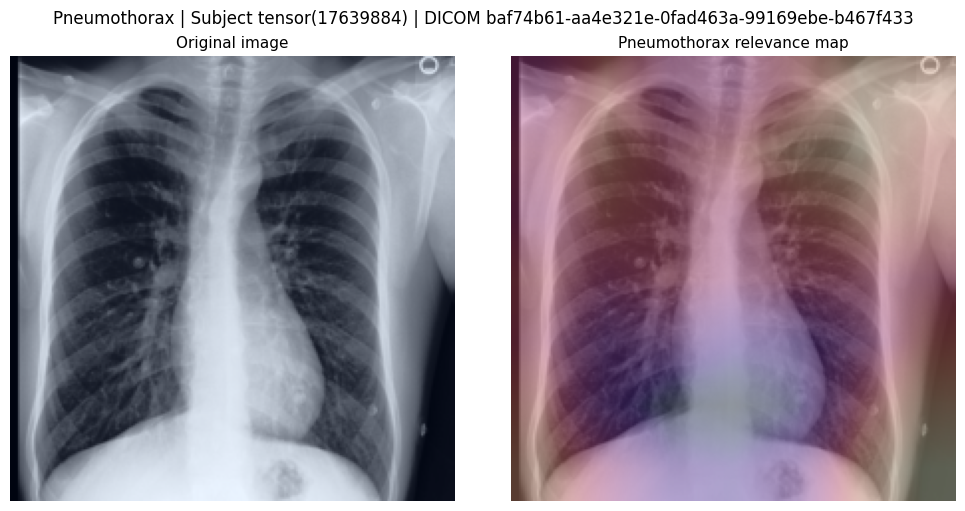

<Figure size 640x480 with 0 Axes>


Sample        : 2/8
Pathology     : Pleural Effusion
Subject ID    : tensor(16773909)
Study ID      : tensor(52995219)
DICOM ID      : b5333b33-2d7a0404-9e2f5dd2-c7e8a0c4-5bef905e
Image         : b5333b33-2d7a0404-9e2f5dd2-c7e8a0c4-5bef905e.jpg
Image Path    : ...6/p16773909/s52995219/b5333b33-2d7a0404-9e2f5dd2-c7e8a0c4-5bef905e.jpg
Ground Truth  : 1
Prediction    : 0
Margin        : -0.053


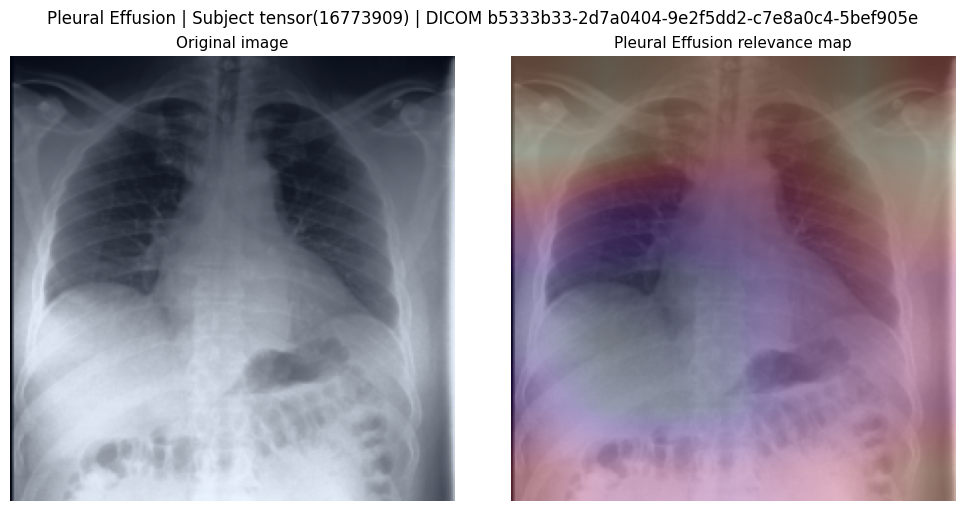

<Figure size 640x480 with 0 Axes>


Sample        : 3/8
Pathology     : Support Devices
Subject ID    : tensor(17556194)
Study ID      : tensor(59125363)
DICOM ID      : 49875266-46459ce6-787cfda1-acd158b5-9e91e2bc
Image         : 49875266-46459ce6-787cfda1-acd158b5-9e91e2bc.jpg
Image Path    : ...7/p17556194/s59125363/49875266-46459ce6-787cfda1-acd158b5-9e91e2bc.jpg
Ground Truth  : 1
Prediction    : 1
Margin        : 0.090


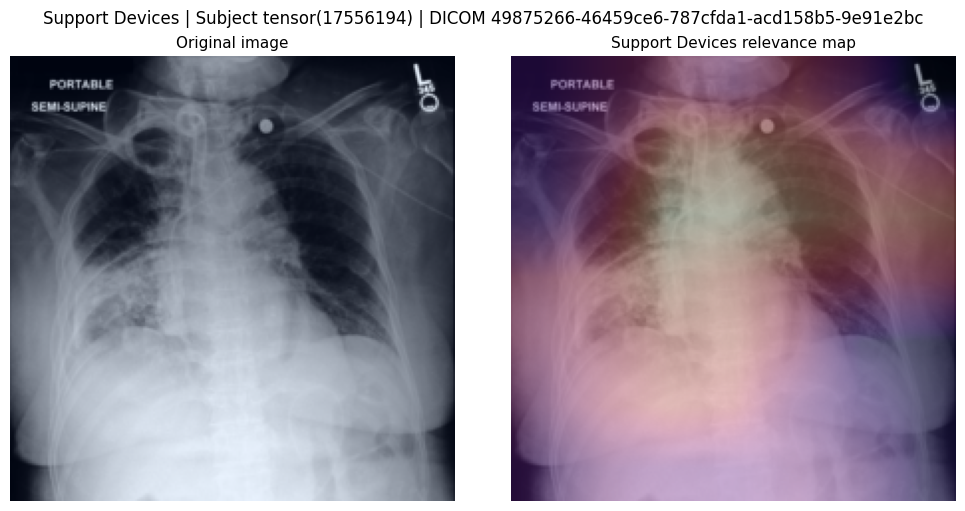

<Figure size 640x480 with 0 Axes>


Sample        : 4/8
Pathology     : Consolidation
Subject ID    : tensor(12691833)
Study ID      : tensor(59271253)
DICOM ID      : 222562f4-a19b517d-019d4f05-81ece1b2-c647ca60
Image         : 222562f4-a19b517d-019d4f05-81ece1b2-c647ca60.jpg
Image Path    : ...2/p12691833/s59271253/222562f4-a19b517d-019d4f05-81ece1b2-c647ca60.jpg
Ground Truth  : 1
Prediction    : 0
Margin        : -0.018


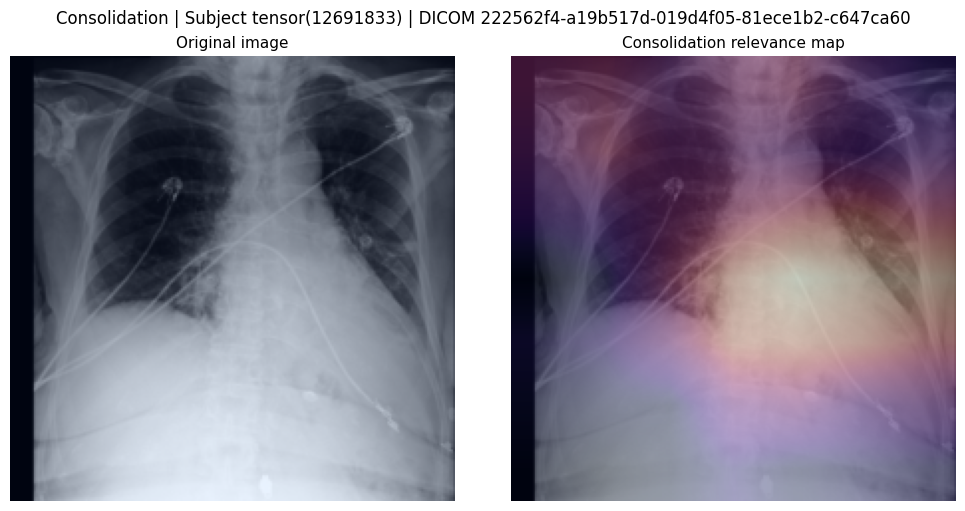

<Figure size 640x480 with 0 Axes>


Sample        : 5/8
Pathology     : Cardiomegaly
Subject ID    : tensor(13464394)
Study ID      : tensor(55263156)
DICOM ID      : ae13fe1c-9fd244b3-1523fa5a-7d594f1a-a6c0a8db
Image         : ae13fe1c-9fd244b3-1523fa5a-7d594f1a-a6c0a8db.jpg
Image Path    : ...3/p13464394/s55263156/ae13fe1c-9fd244b3-1523fa5a-7d594f1a-a6c0a8db.jpg
Ground Truth  : 1
Prediction    : 1
Margin        : 0.120


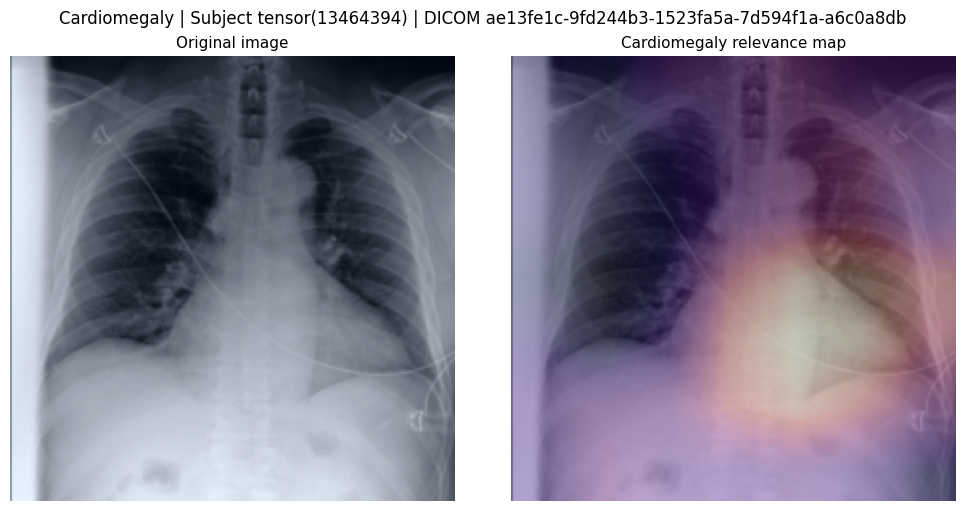

<Figure size 640x480 with 0 Axes>


Sample        : 6/8
Pathology     : Atelectasis
Subject ID    : tensor(17759808)
Study ID      : tensor(57519424)
DICOM ID      : 4329bed3-9c38b502-4d480688-849c7329-4941c218
Image         : 4329bed3-9c38b502-4d480688-849c7329-4941c218.jpg
Image Path    : ...7/p17759808/s57519424/4329bed3-9c38b502-4d480688-849c7329-4941c218.jpg
Ground Truth  : 1
Prediction    : 1
Margin        : -0.005


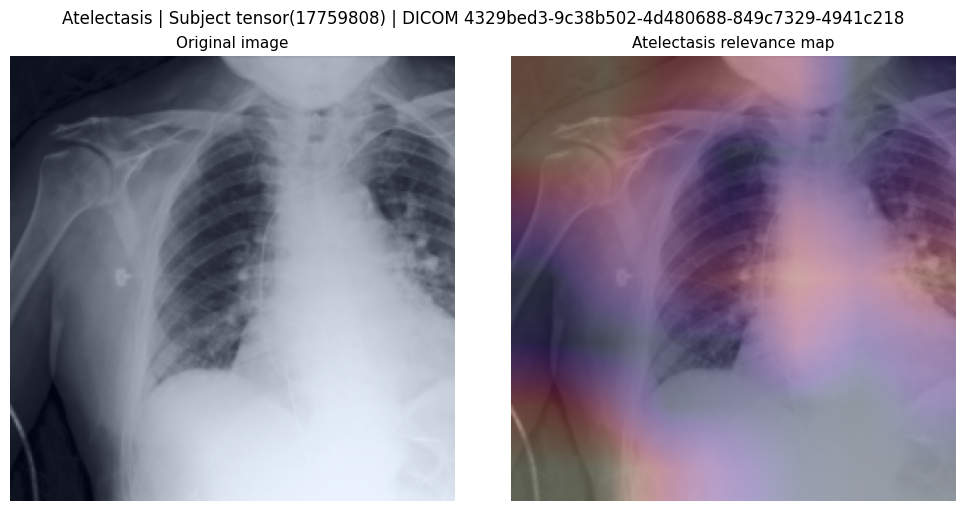

<Figure size 640x480 with 0 Axes>


Sample        : 7/8
Pathology     : Edema
Subject ID    : tensor(14062965)
Study ID      : tensor(58985721)
DICOM ID      : 2f453531-72706205-408aaeba-d025e2cc-c3f6f340
Image         : 2f453531-72706205-408aaeba-d025e2cc-c3f6f340.jpg
Image Path    : ...4/p14062965/s58985721/2f453531-72706205-408aaeba-d025e2cc-c3f6f340.jpg
Ground Truth  : 1
Prediction    : 1
Margin        : 0.402


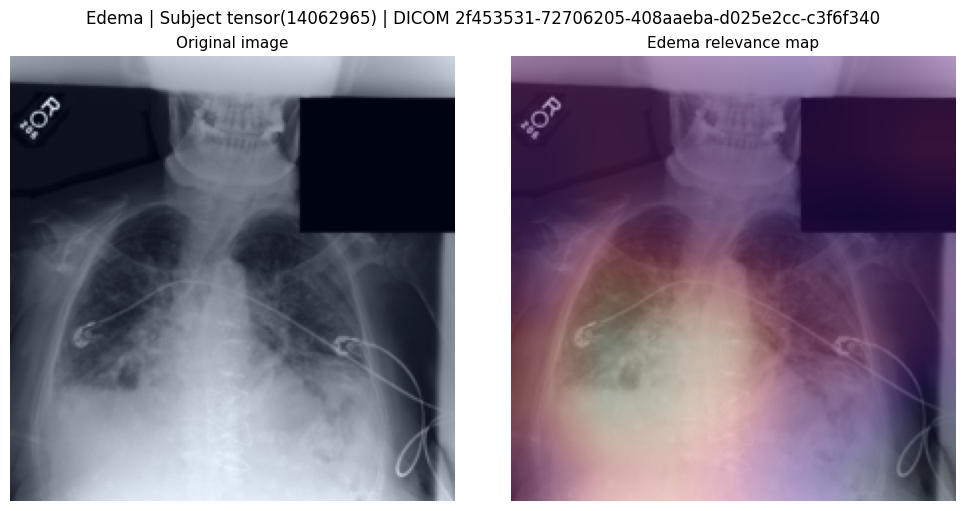

<Figure size 640x480 with 0 Axes>


Sample        : 8/8
Pathology     : No Finding
Subject ID    : tensor(15647422)
Study ID      : tensor(59647919)
DICOM ID      : 70a59206-4b1b8bd0-4e77dbf5-df2e90ad-ba42d70f
Image         : 70a59206-4b1b8bd0-4e77dbf5-df2e90ad-ba42d70f.jpg
Image Path    : ...5/p15647422/s59647919/70a59206-4b1b8bd0-4e77dbf5-df2e90ad-ba42d70f.jpg
Ground Truth  : 1
Prediction    : 1
Margin        : -0.068


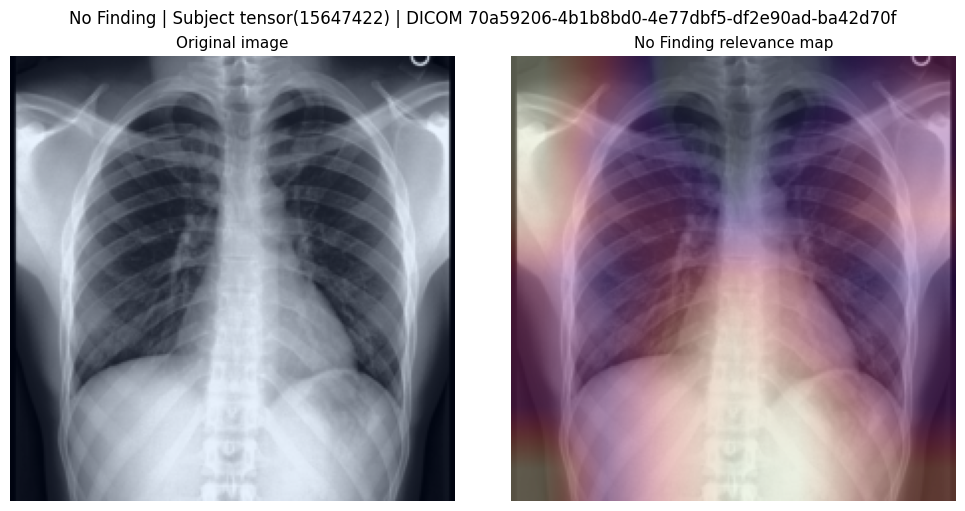

<Figure size 640x480 with 0 Axes>

In [106]:
plot_random_cases_different_pathologies(
    random_cases=random_cases,
    test_df=test_df,
    pipeline=pipeline,
    save_dir=SAVE_DIR / "random_cases",
)

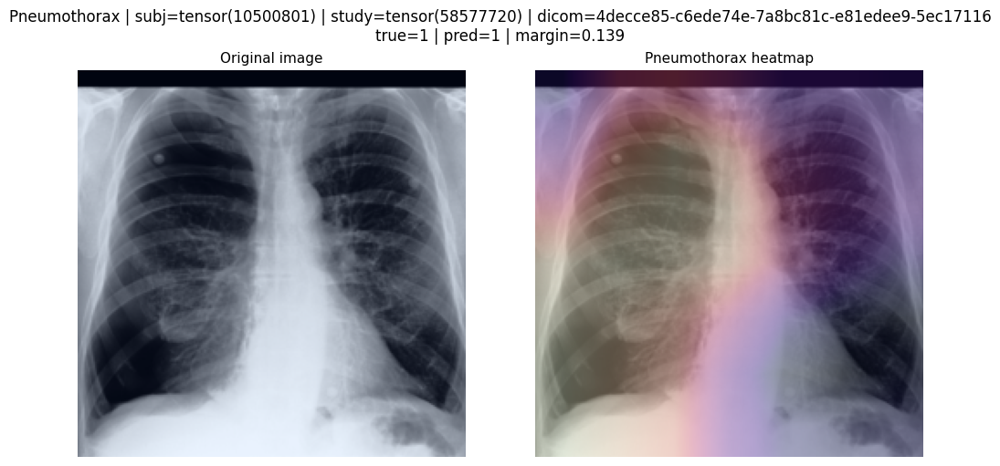

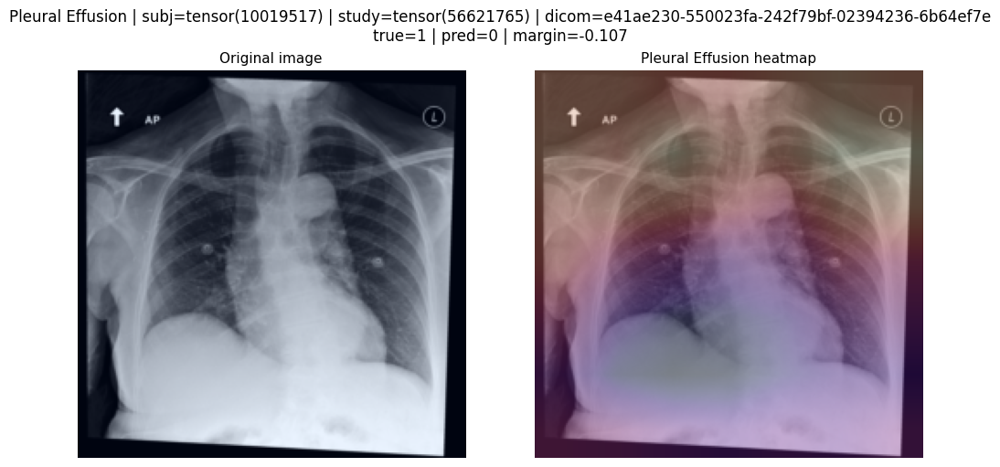

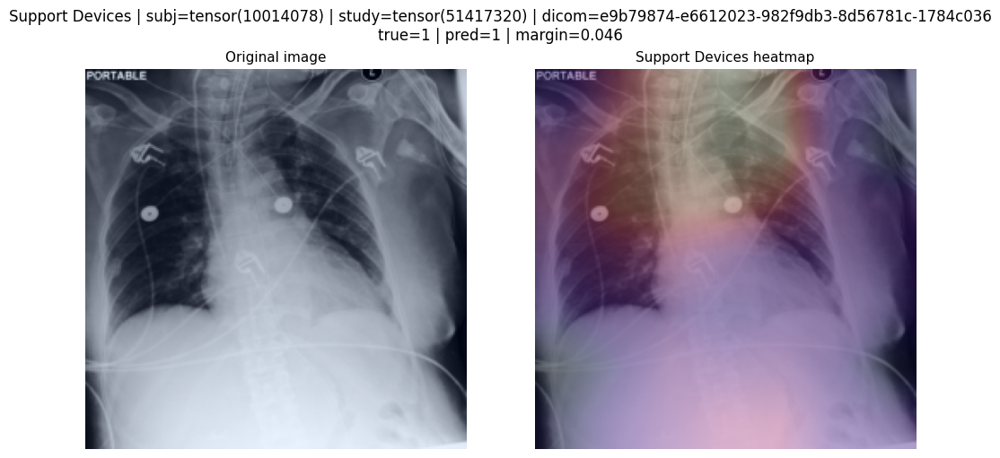

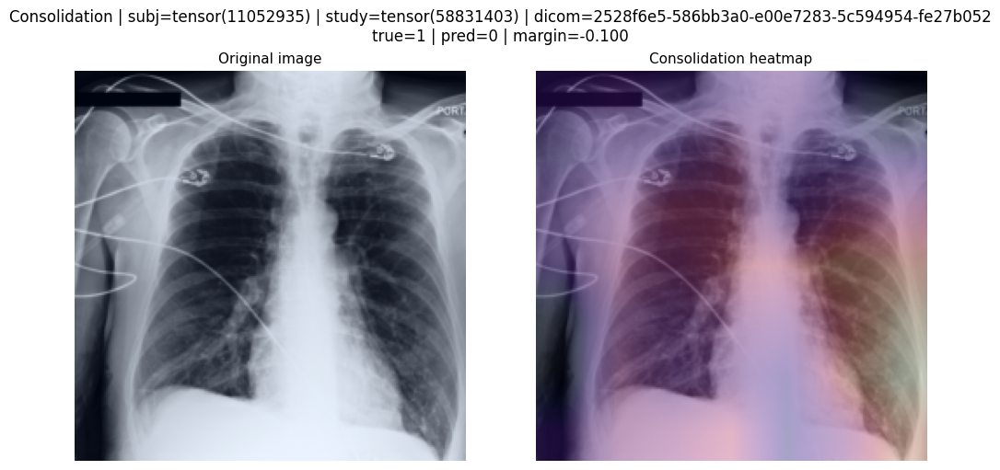

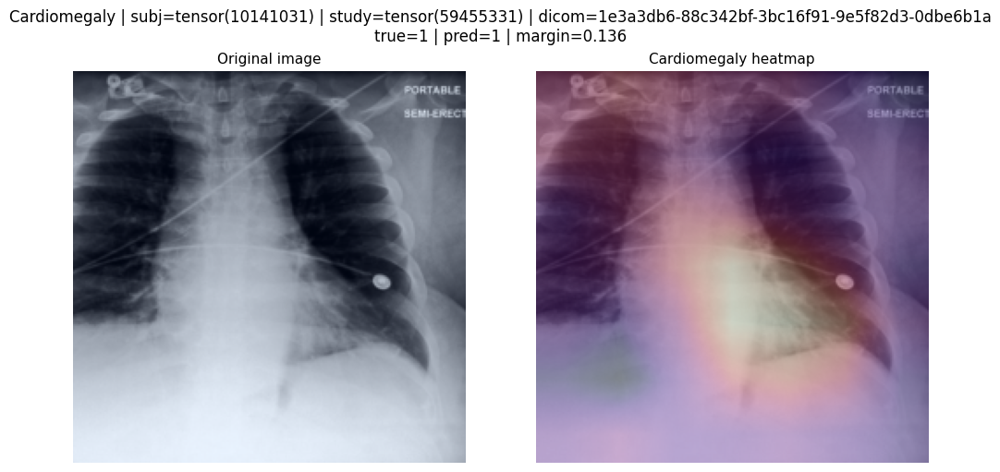

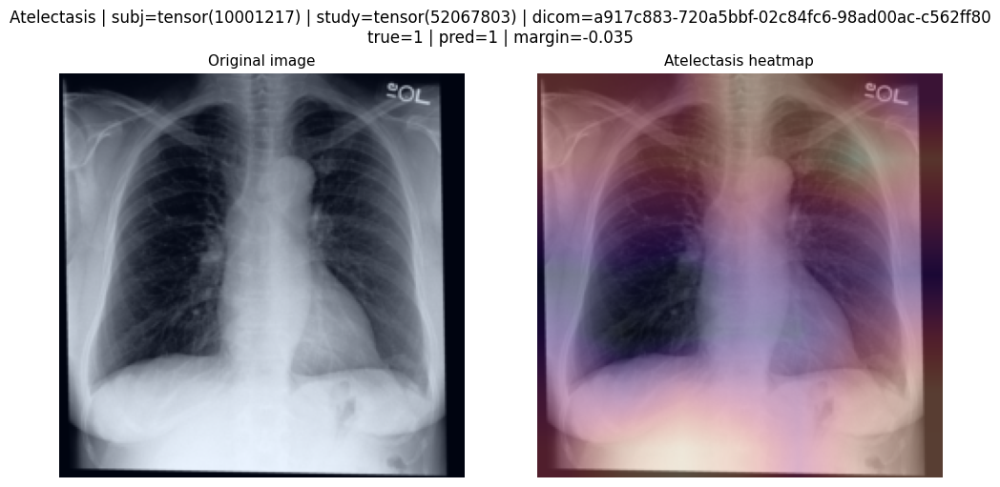

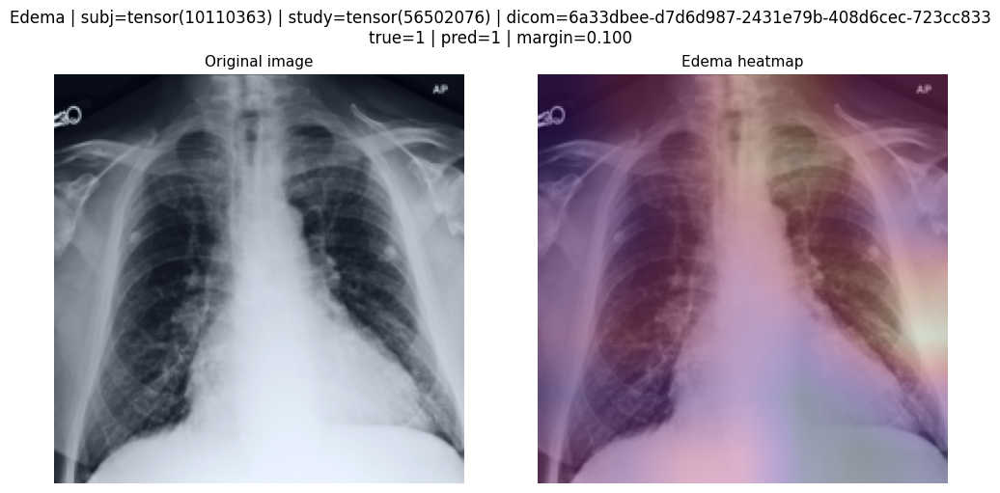

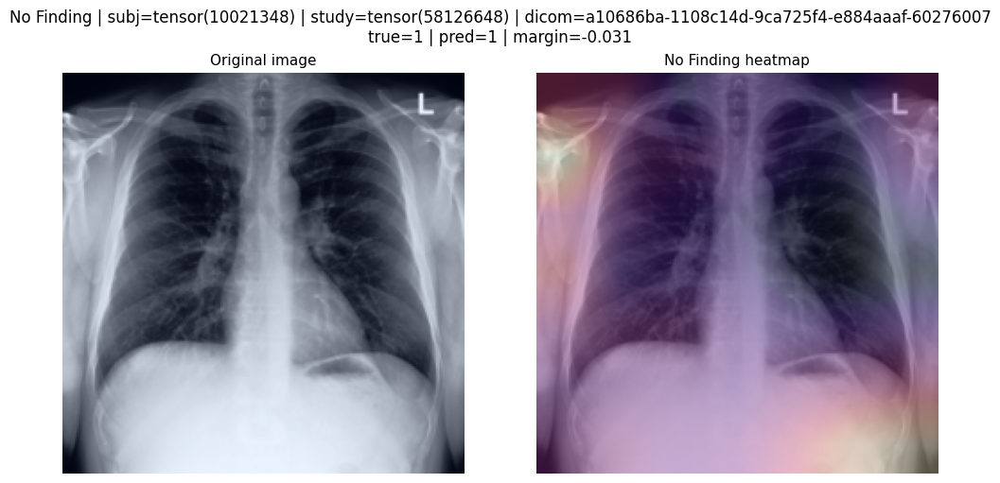

In [107]:
for label in TARGET_CASE_LABELS:
    cases = get_single_pathology_cases(
        df=test_results_cal,
        label=label,
        labels_of_interest=TARGET_CASE_LABELS,
        n=1,
    )
    if len(cases) == 0:
        print(f"No single-pathology cases for {label}, skipping.")
        continue
    plot_selected_cases_for_pathology(
        cases_df=cases,
        label=label,
        test_df=test_df,
        pipeline=pipeline,
        save_dir= SAVE_DIR / "selected_cases/",
    )

Saved: figures/cxr_clip/similarity_relevance/tp_fp_tn_pneumothorax.png


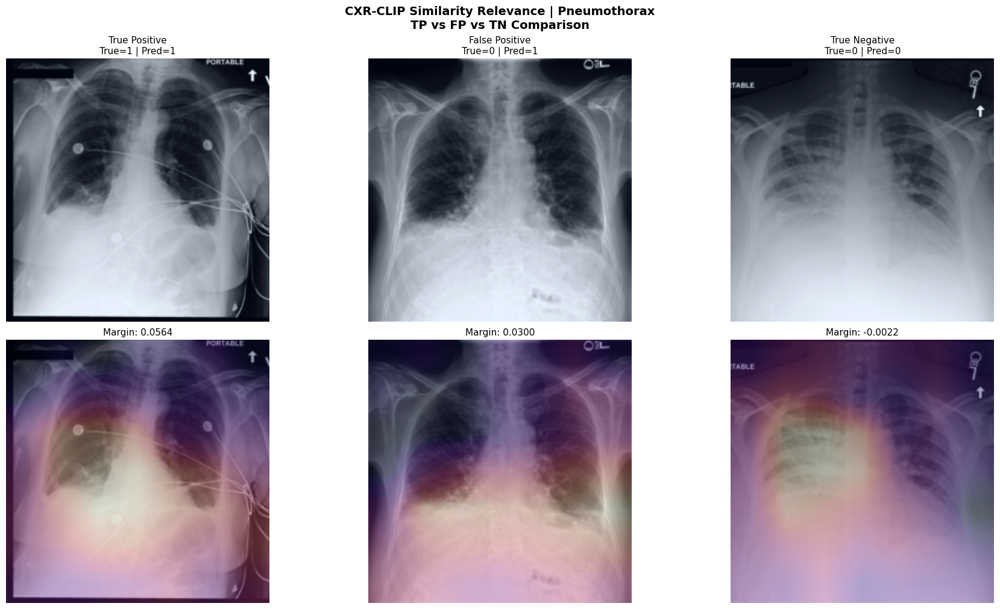

Saved: figures/cxr_clip/similarity_relevance/tp_fp_tn_pleural_effusion.png


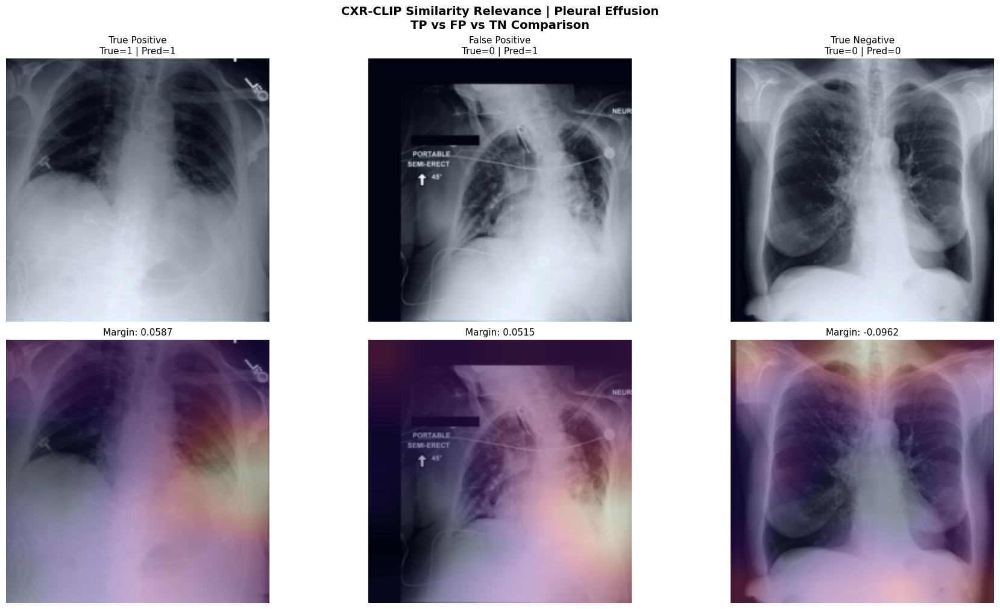

Saved: figures/cxr_clip/similarity_relevance/tp_fp_tn_support_devices.png


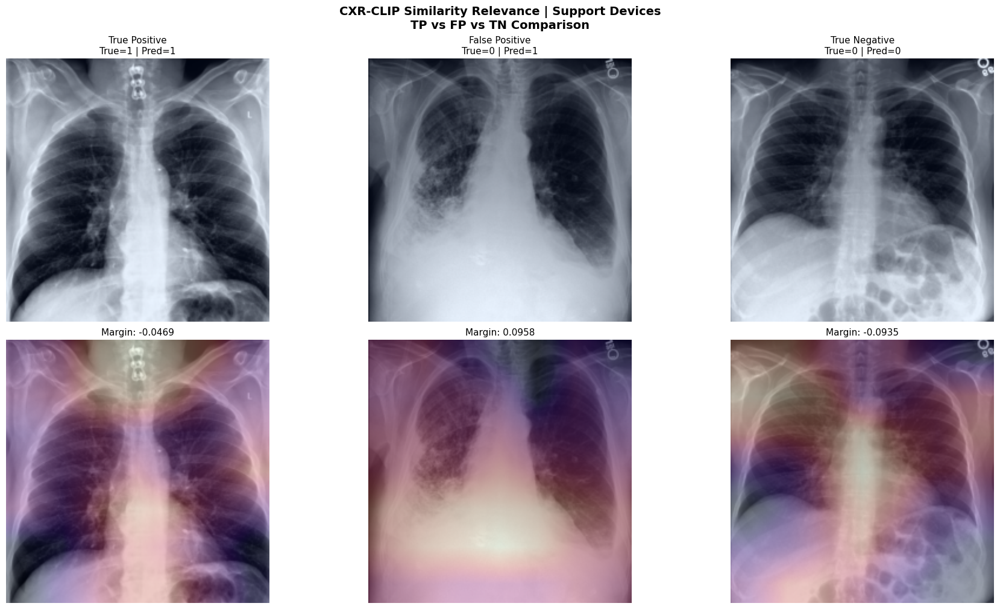

Saved: figures/cxr_clip/similarity_relevance/tp_fp_tn_consolidation.png


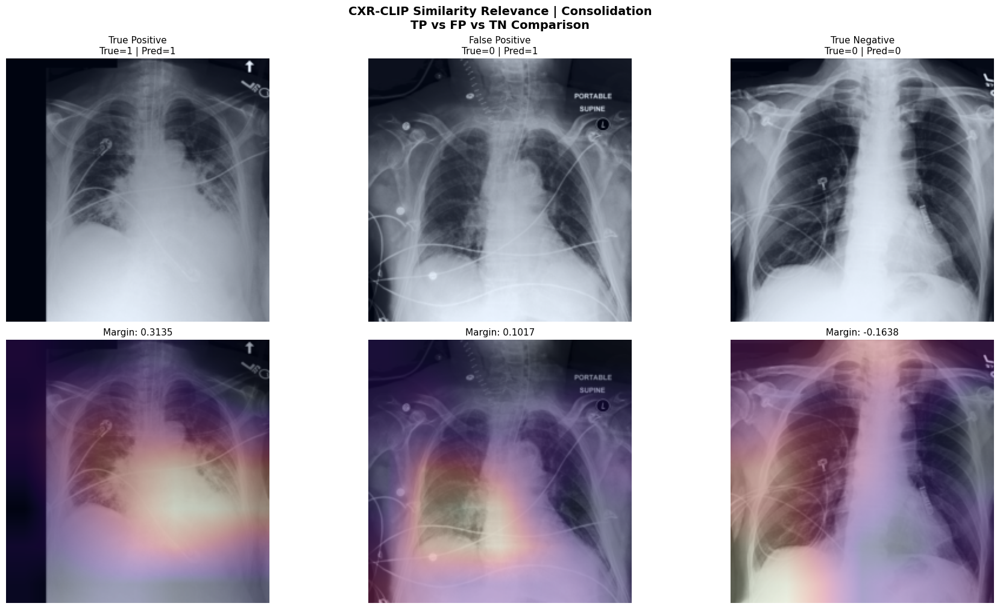

Saved: figures/cxr_clip/similarity_relevance/tp_fp_tn_cardiomegaly.png


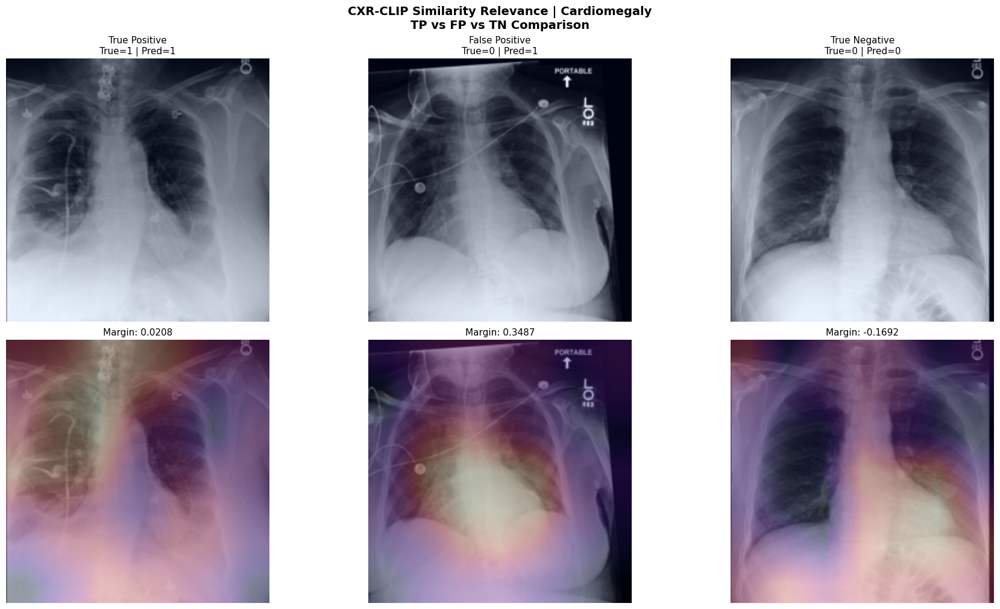

Saved: figures/cxr_clip/similarity_relevance/tp_fp_tn_atelectasis.png


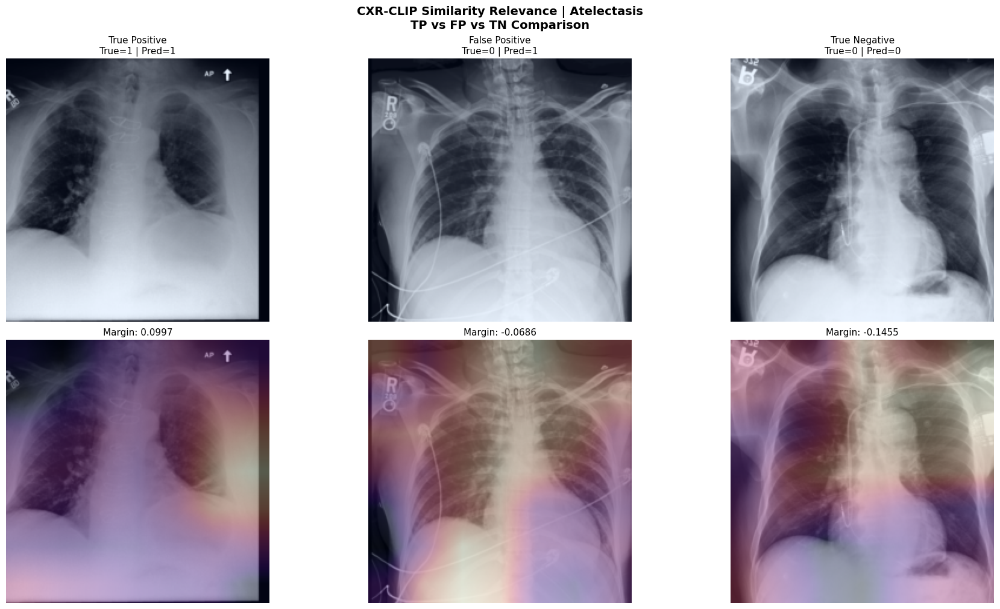

Saved: figures/cxr_clip/similarity_relevance/tp_fp_tn_edema.png


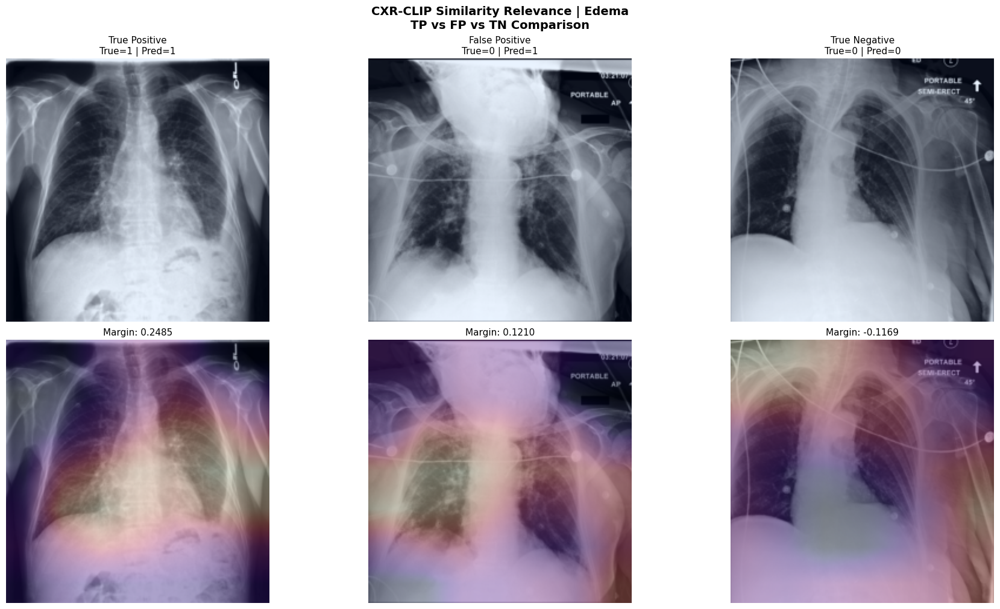

In [108]:
for label in TARGET_CASE_LABELS:
    if label == "No Finding":
        continue
    plot_tp_fp_tn_comparison(
        label=label,
        test_results_cal=test_results_cal,
        test_df=test_df,
        pipeline=pipeline,
        save_path=f"figures/cxr_clip/similarity_relevance/tp_fp_tn_{label.lower().replace(' ', '_')}.png",
        random_state=42,
    )

## Grad-CAM

In [109]:
SAVE_DIR = OUTPUT_ROOT / "Grad-CAM"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

In [110]:
def compare_gradcam_methods(sample, pipeline, label, alpha=0.35, cmap="magma"):
    cam = generate_gradcam(pipeline, sample["image"], label, use_margin=True)
    cam_pp = generate_gradcam_plus_plus(pipeline, sample["image"], label, use_margin=True)

    img = sample["image"].detach().cpu().permute(1, 2, 0).numpy()
    img = img - img.min()
    if img.max() > 0:
        img = img / img.max()

    fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)

    axes[0].imshow(img)
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(img)
    axes[1].imshow(cam, cmap=cmap, alpha=alpha)
    axes[1].set_title(f"{label}\nGrad-CAM")
    axes[1].axis("off")

    axes[2].imshow(img)
    axes[2].imshow(cam_pp, cmap=cmap, alpha=alpha)
    axes[2].set_title(f"{label}\nGrad-CAM++")
    axes[2].axis("off")

    plt.show()

In [111]:
def plot_random_gradcam_cases_different_pathologies(
    random_cases,
    test_df,
    pipeline,
    method="gradcam",   # "gradcam" or "gradcam++"
    alpha=0.35,
    cmap="magma",
    use_margin=True,
    show_original=True,
    max_path_chars=70,
    save_dir=None,
    dpi=300,
):
    """
    Plot one random case per pathology using Grad-CAM or Grad-CAM++.
    """
    if len(random_cases) == 0:
        print("No random cases provided.")
        return

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

    labels = list(random_cases.keys())

    for idx, label in enumerate(labels, start=1):
        row = random_cases[label]
        sample = get_sample_from_row(row, test_df, pipeline)

        if method == "gradcam":
            heatmap = generate_gradcam(
                pipeline=pipeline,
                image_tensor=sample["image"],
                label=label,
                use_margin=use_margin,
            )
            method_name = "Grad-CAM"
        elif method == "gradcam++":
            heatmap = generate_gradcam_plus_plus(
                pipeline=pipeline,
                image_tensor=sample["image"],
                label=label,
                use_margin=use_margin,
            )
            method_name = "Grad-CAM++"
        else:
            raise ValueError("method must be 'gradcam' or 'gradcam++'")

        img = sample["image"].detach().cpu().permute(1, 2, 0).numpy()
        img = img - img.min()
        if img.max() > 0:
            img = img / img.max()

        image_path = str(row["image_path"])
        short_path = image_path if len(image_path) <= max_path_chars else "..." + image_path[-max_path_chars:]

        print("\n" + "=" * 90)
        print(f"Sample        : {idx}/{len(labels)}")
        print(f"Pathology     : {label}")
        print(f"Method        : {method_name}")
        print(f"Subject ID    : {row.get('subject_id', 'N/A')}")
        print(f"Study ID      : {row.get('study_id', 'N/A')}")
        print(f"DICOM ID      : {row.get('dicom_id', 'N/A')}")
        print(f"Image         : {Path(image_path).name}")
        print(f"Image Path    : {short_path}")
        print(f"Ground Truth  : {int(row.get(f'{label}_true', 0))}")
        pred_col = f"{label}_pred_calibrated"
        if pred_col in row.index:
            print(f"Prediction    : {int(row[pred_col])}")
        margin_col = f"{label}_margin"
        if margin_col in row.index:
            print(f"Margin        : {row[margin_col]:.3f}")

        if show_original:
            fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)

            axes[0].imshow(img)
            axes[0].set_title("Original image", fontsize=11)
            axes[0].axis("off")

            axes[1].imshow(img)
            axes[1].imshow(heatmap, cmap=cmap, alpha=alpha)
            axes[1].set_title(f"{label} {method_name}", fontsize=11)
            axes[1].axis("off")
        else:
            fig, ax = plt.subplots(1, 1, figsize=(5.5, 5.5), constrained_layout=True)
            ax.imshow(heatmap, cmap=cmap)
            ax.set_title(f"{label} {method_name}", fontsize=11)
            ax.axis("off")

        fig.suptitle(
            f"{label} | Subject {row.get('subject_id', 'N/A')} | DICOM {row.get('dicom_id', 'N/A')}",
            fontsize=12,
        )

        if save_dir is not None:
            safe_label = label.replace(" ", "_")
            fname = f"{idx:02d}_{safe_label}_{method_name.replace('-', '').replace('+', 'pp')}_subj_{row.get('subject_id', 'NA')}_dicom_{row.get('dicom_id', 'NA')}.png"
            fig.savefig(save_dir / fname, dpi=dpi, bbox_inches="tight")
        
        savefig(
            f"cxr_clip/gradcam/{method}",
            f"{label.replace(' ', '_')}_subject_{row.get('subject_id', 'NA')}.png"
        )
        
        plt.show()
        plt.close(fig)

In [112]:
def plot_selected_gradcam_cases_for_pathology(
    cases_df,
    label,
    test_df,
    pipeline,
    method="gradcam",   # "gradcam" or "gradcam++"
    alpha=0.35,
    cmap="magma",
    use_margin=True,
    save_dir=None,
    dpi=300,
):
    """
    Plot selected cases for one pathology using Grad-CAM or Grad-CAM++.
    """
    if len(cases_df) == 0:
        print(f"No selected cases for {label}")
        return

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

    for i, (_, row) in enumerate(cases_df.iterrows(), start=1):
        sample = get_sample_from_row(row, test_df, pipeline)

        if method == "gradcam":
            heatmap = generate_gradcam(
                pipeline=pipeline,
                image_tensor=sample["image"],
                label=label,
                use_margin=use_margin,
            )
            method_name = "Grad-CAM"
        elif method == "gradcam++":
            heatmap = generate_gradcam_plus_plus(
                pipeline=pipeline,
                image_tensor=sample["image"],
                label=label,
                use_margin=use_margin,
            )
            method_name = "Grad-CAM++"
        else:
            raise ValueError("method must be 'gradcam' or 'gradcam++'")

        img = sample["image"].detach().cpu().permute(1, 2, 0).numpy()
        img = img - img.min()
        if img.max() > 0:
            img = img / img.max()

        print("\n" + "=" * 90)
        print(f"Pathology     : {label}")
        print(f"Method        : {method_name}")
        print(f"Subject ID    : {row.get('subject_id', 'N/A')}")
        print(f"Study ID      : {row.get('study_id', 'N/A')}")
        print(f"DICOM ID      : {row.get('dicom_id', 'N/A')}")
        print(f"Ground Truth  : {int(row.get(f'{label}_true', 0))}")
        print(f"Prediction    : {int(row.get(f'{label}_pred_calibrated', 0))}")
        print(f"Margin        : {row.get(f'{label}_margin', float('nan')):.3f}")

        fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)

        axes[0].imshow(img)
        axes[0].set_title("Original image", fontsize=11)
        axes[0].axis("off")

        axes[1].imshow(img)
        axes[1].imshow(heatmap, cmap=cmap, alpha=alpha)
        axes[1].set_title(f"{label} {method_name}", fontsize=11)
        axes[1].axis("off")

        fig.suptitle(
            f"{label} | true={int(row.get(f'{label}_true', 0))} | "
            f"pred={int(row.get(f'{label}_pred_calibrated', 0))}",
            fontsize=12,
        )

        if save_dir is not None:
            safe_label = label.replace(" ", "_")
            safe_method = method_name.replace("-", "").replace("+", "pp")
            fname = f"{safe_label}_case_{i:02d}_{safe_method}.png"
            fig.savefig(save_dir / fname, dpi=dpi, bbox_inches="tight")

        plt.show()
        plt.close(fig)

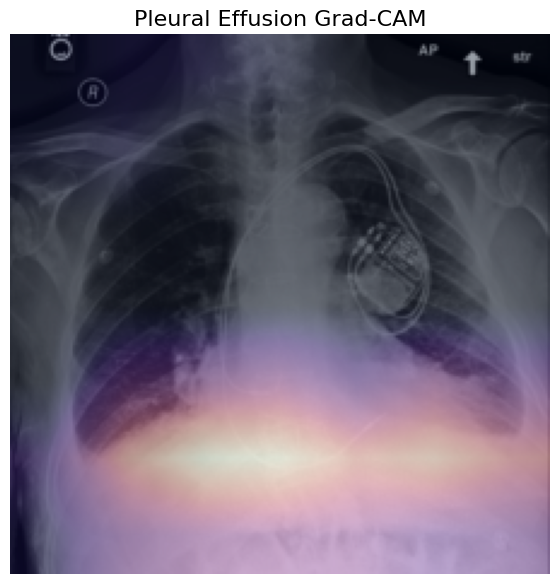

In [113]:
label = "Pleural Effusion"

cam = generate_gradcam(
    pipeline=pipeline,
    image_tensor=sample["image"],
    label=label,
    use_margin=True,
)

show_cam_overlay(
    image_tensor=sample["image"],
    heatmap=cam,
    title=f"{label} Grad-CAM",
)

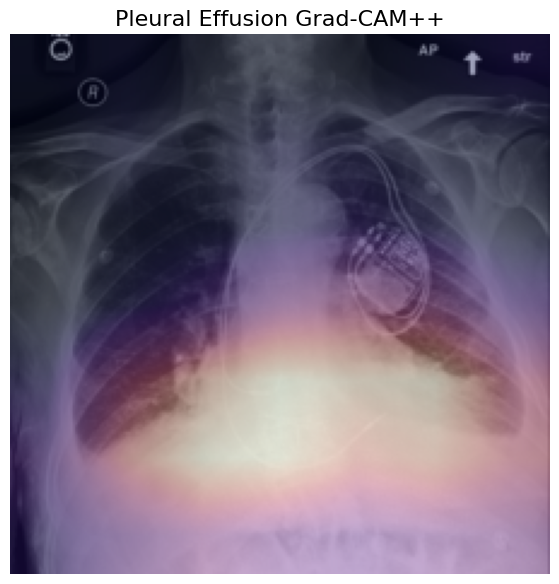

In [114]:
cam_pp = generate_gradcam_plus_plus(
    pipeline=pipeline,
    image_tensor=sample["image"],
    label=label,
    use_margin=True,
)

show_cam_overlay(
    image_tensor=sample["image"],
    heatmap=cam_pp,
    title=f"{label} Grad-CAM++",
)


Sample        : 1/8
Pathology     : Pneumothorax
Method        : Grad-CAM
Subject ID    : tensor(17639884)
Study ID      : tensor(51347500)
DICOM ID      : baf74b61-aa4e321e-0fad463a-99169ebe-b467f433
Image         : baf74b61-aa4e321e-0fad463a-99169ebe-b467f433.jpg
Image Path    : ...7/p17639884/s51347500/baf74b61-aa4e321e-0fad463a-99169ebe-b467f433.jpg
Ground Truth  : 1
Prediction    : 0
Margin        : -0.018


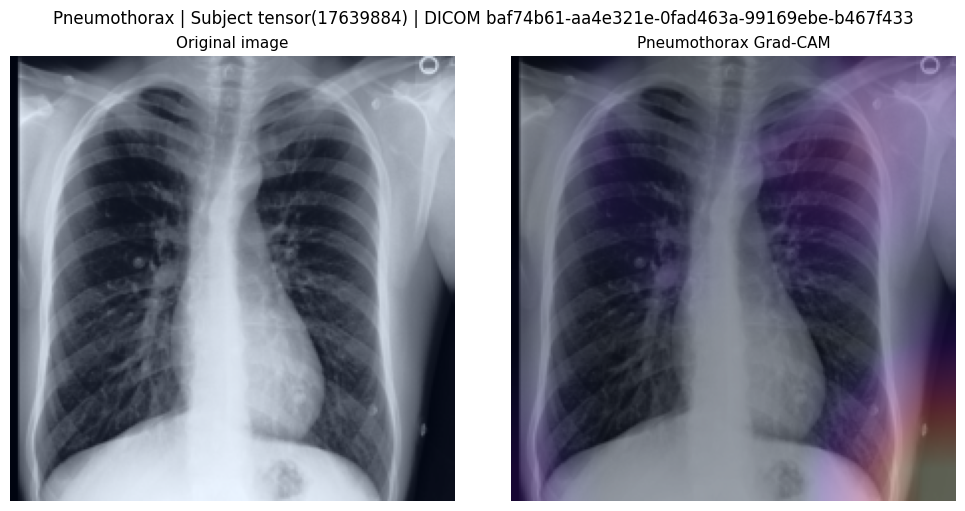


Sample        : 2/8
Pathology     : Pleural Effusion
Method        : Grad-CAM
Subject ID    : tensor(16773909)
Study ID      : tensor(52995219)
DICOM ID      : b5333b33-2d7a0404-9e2f5dd2-c7e8a0c4-5bef905e
Image         : b5333b33-2d7a0404-9e2f5dd2-c7e8a0c4-5bef905e.jpg
Image Path    : ...6/p16773909/s52995219/b5333b33-2d7a0404-9e2f5dd2-c7e8a0c4-5bef905e.jpg
Ground Truth  : 1
Prediction    : 0
Margin        : -0.053


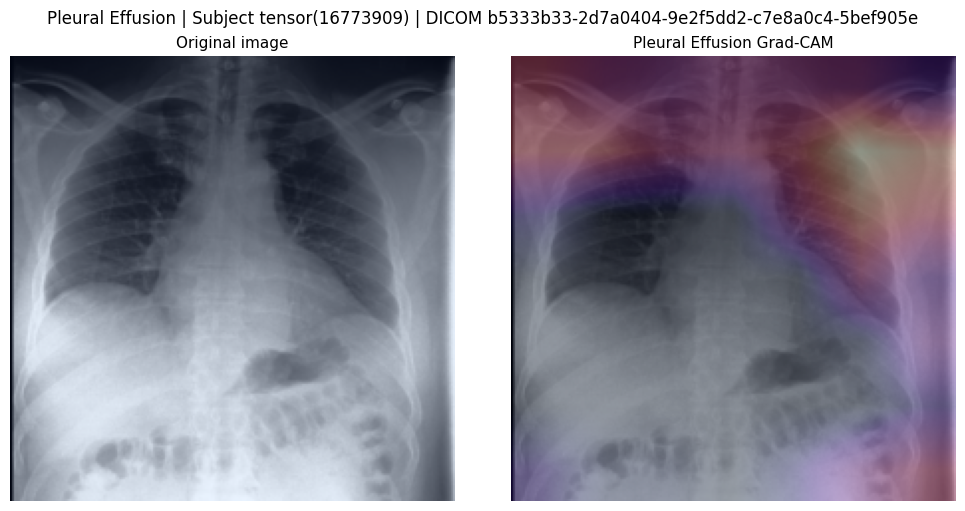


Sample        : 3/8
Pathology     : Support Devices
Method        : Grad-CAM
Subject ID    : tensor(17556194)
Study ID      : tensor(59125363)
DICOM ID      : 49875266-46459ce6-787cfda1-acd158b5-9e91e2bc
Image         : 49875266-46459ce6-787cfda1-acd158b5-9e91e2bc.jpg
Image Path    : ...7/p17556194/s59125363/49875266-46459ce6-787cfda1-acd158b5-9e91e2bc.jpg
Ground Truth  : 1
Prediction    : 1
Margin        : 0.090


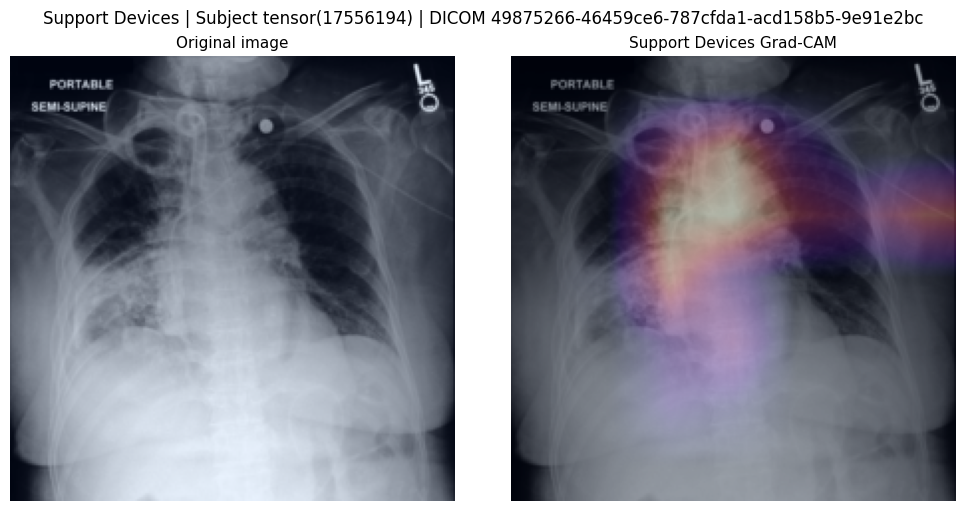


Sample        : 4/8
Pathology     : Consolidation
Method        : Grad-CAM
Subject ID    : tensor(12691833)
Study ID      : tensor(59271253)
DICOM ID      : 222562f4-a19b517d-019d4f05-81ece1b2-c647ca60
Image         : 222562f4-a19b517d-019d4f05-81ece1b2-c647ca60.jpg
Image Path    : ...2/p12691833/s59271253/222562f4-a19b517d-019d4f05-81ece1b2-c647ca60.jpg
Ground Truth  : 1
Prediction    : 0
Margin        : -0.018


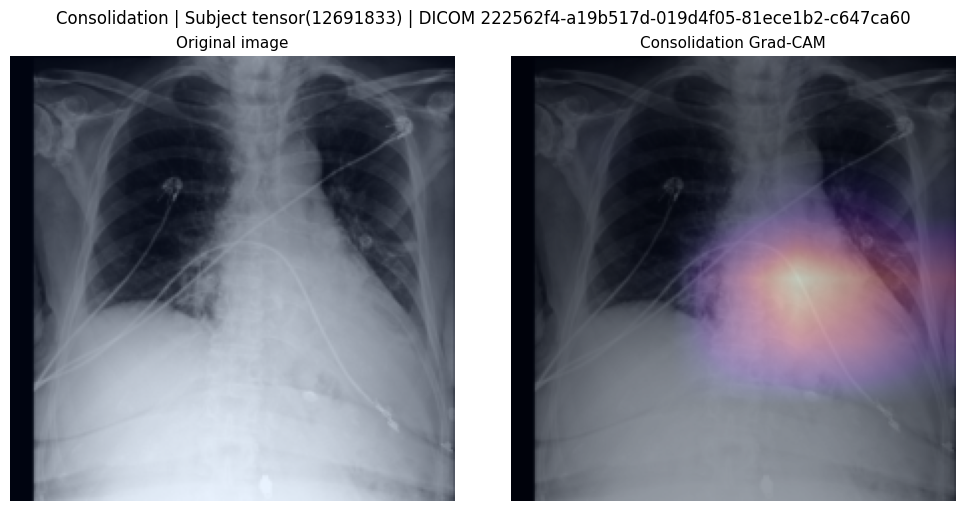


Sample        : 5/8
Pathology     : Cardiomegaly
Method        : Grad-CAM
Subject ID    : tensor(13464394)
Study ID      : tensor(55263156)
DICOM ID      : ae13fe1c-9fd244b3-1523fa5a-7d594f1a-a6c0a8db
Image         : ae13fe1c-9fd244b3-1523fa5a-7d594f1a-a6c0a8db.jpg
Image Path    : ...3/p13464394/s55263156/ae13fe1c-9fd244b3-1523fa5a-7d594f1a-a6c0a8db.jpg
Ground Truth  : 1
Prediction    : 1
Margin        : 0.120


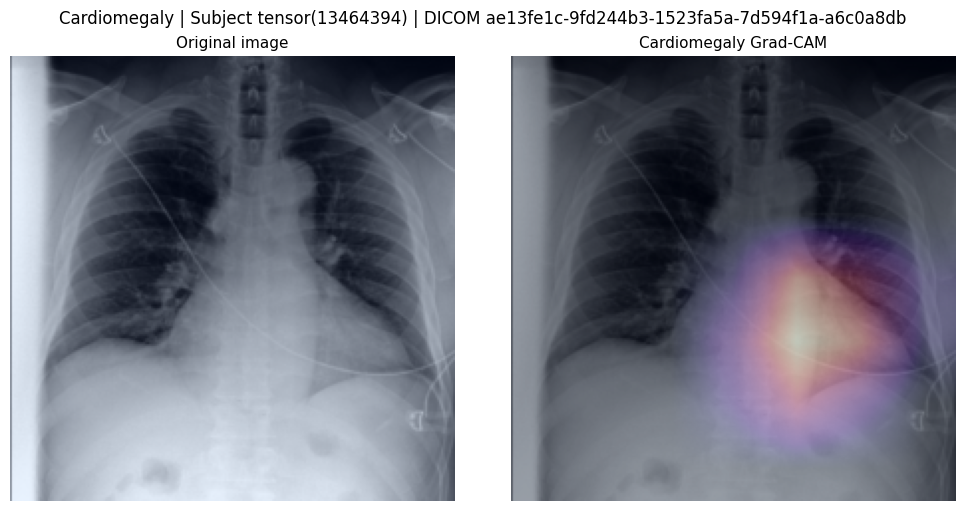


Sample        : 6/8
Pathology     : Atelectasis
Method        : Grad-CAM
Subject ID    : tensor(17759808)
Study ID      : tensor(57519424)
DICOM ID      : 4329bed3-9c38b502-4d480688-849c7329-4941c218
Image         : 4329bed3-9c38b502-4d480688-849c7329-4941c218.jpg
Image Path    : ...7/p17759808/s57519424/4329bed3-9c38b502-4d480688-849c7329-4941c218.jpg
Ground Truth  : 1
Prediction    : 1
Margin        : -0.005


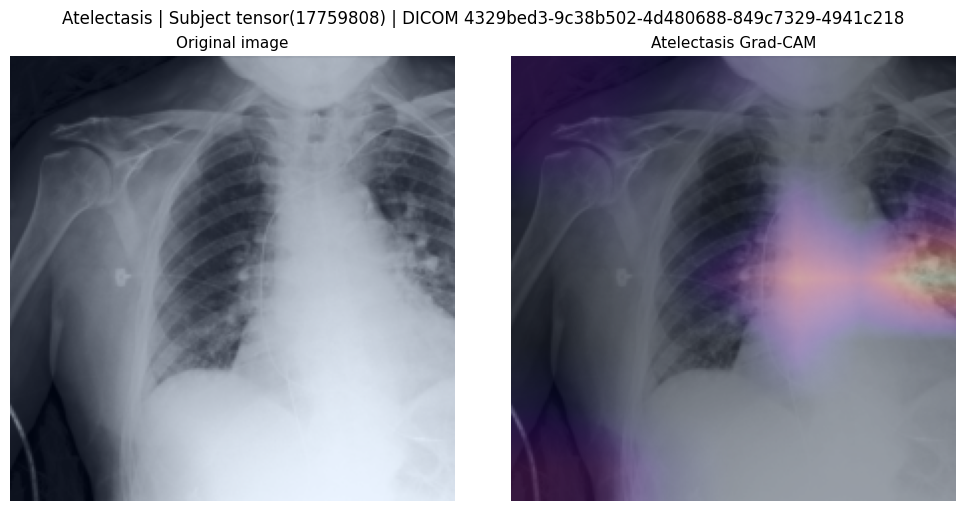


Sample        : 7/8
Pathology     : Edema
Method        : Grad-CAM
Subject ID    : tensor(14062965)
Study ID      : tensor(58985721)
DICOM ID      : 2f453531-72706205-408aaeba-d025e2cc-c3f6f340
Image         : 2f453531-72706205-408aaeba-d025e2cc-c3f6f340.jpg
Image Path    : ...4/p14062965/s58985721/2f453531-72706205-408aaeba-d025e2cc-c3f6f340.jpg
Ground Truth  : 1
Prediction    : 1
Margin        : 0.402


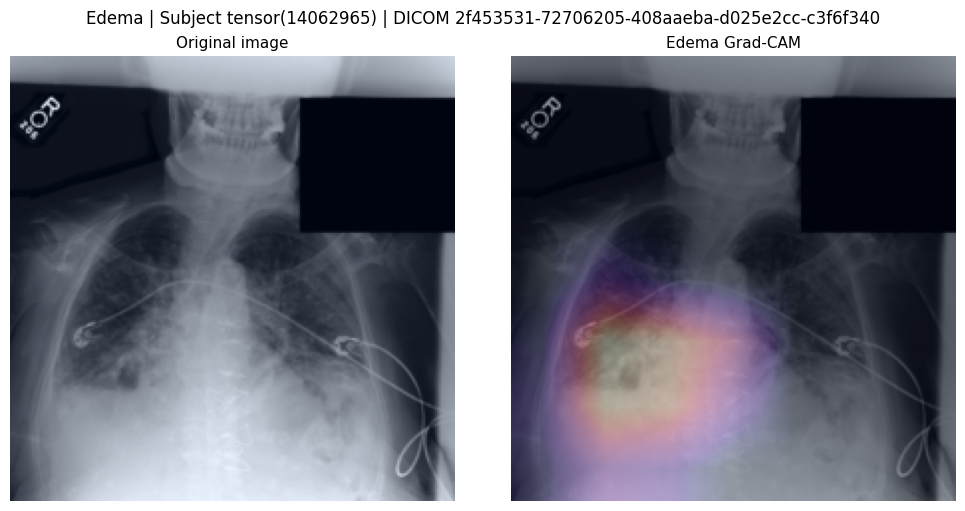


Sample        : 8/8
Pathology     : No Finding
Method        : Grad-CAM
Subject ID    : tensor(15647422)
Study ID      : tensor(59647919)
DICOM ID      : 70a59206-4b1b8bd0-4e77dbf5-df2e90ad-ba42d70f
Image         : 70a59206-4b1b8bd0-4e77dbf5-df2e90ad-ba42d70f.jpg
Image Path    : ...5/p15647422/s59647919/70a59206-4b1b8bd0-4e77dbf5-df2e90ad-ba42d70f.jpg
Ground Truth  : 1
Prediction    : 1
Margin        : -0.068


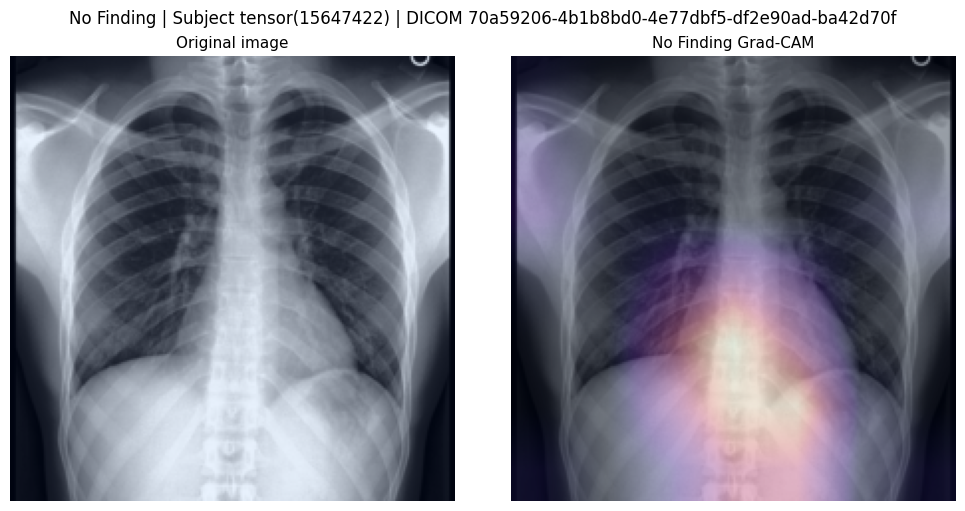

In [115]:
plot_random_gradcam_cases_different_pathologies(
    random_cases=random_cases,
    test_df=results["test_df"],
    pipeline=pipeline,
    method="gradcam",
    save_dir= SAVE_DIR / "random_gradcam/",
)


Sample        : 1/8
Pathology     : Pneumothorax
Method        : Grad-CAM++
Subject ID    : tensor(17639884)
Study ID      : tensor(51347500)
DICOM ID      : baf74b61-aa4e321e-0fad463a-99169ebe-b467f433
Image         : baf74b61-aa4e321e-0fad463a-99169ebe-b467f433.jpg
Image Path    : ...7/p17639884/s51347500/baf74b61-aa4e321e-0fad463a-99169ebe-b467f433.jpg
Ground Truth  : 1
Prediction    : 0
Margin        : -0.018


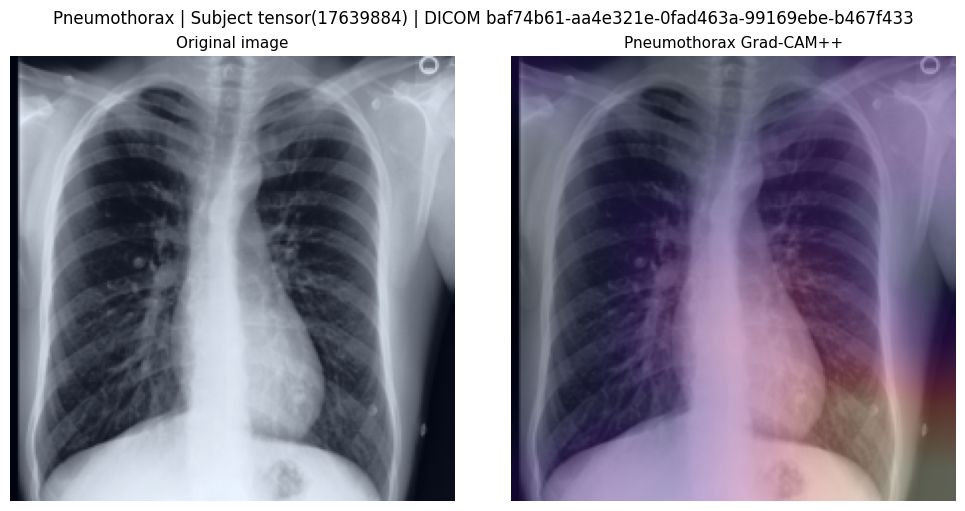


Sample        : 2/8
Pathology     : Pleural Effusion
Method        : Grad-CAM++
Subject ID    : tensor(16773909)
Study ID      : tensor(52995219)
DICOM ID      : b5333b33-2d7a0404-9e2f5dd2-c7e8a0c4-5bef905e
Image         : b5333b33-2d7a0404-9e2f5dd2-c7e8a0c4-5bef905e.jpg
Image Path    : ...6/p16773909/s52995219/b5333b33-2d7a0404-9e2f5dd2-c7e8a0c4-5bef905e.jpg
Ground Truth  : 1
Prediction    : 0
Margin        : -0.053


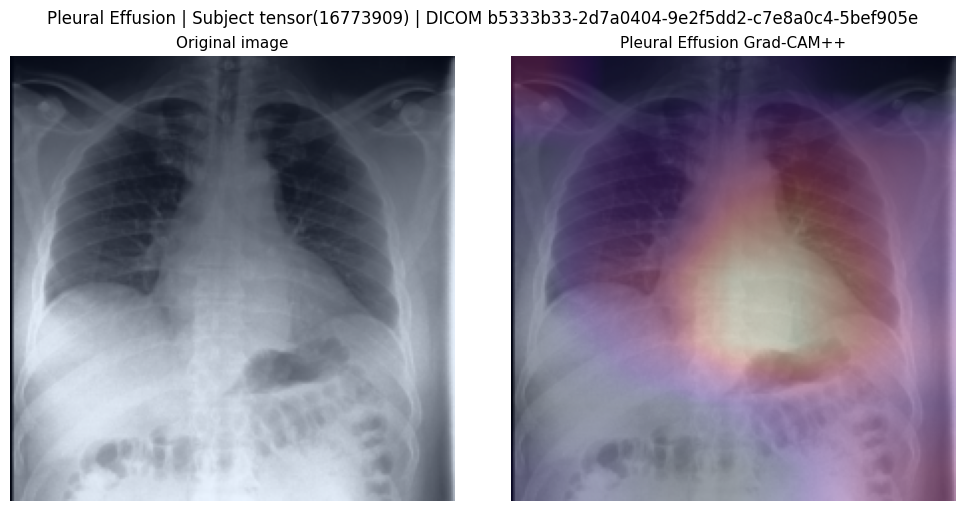


Sample        : 3/8
Pathology     : Support Devices
Method        : Grad-CAM++
Subject ID    : tensor(17556194)
Study ID      : tensor(59125363)
DICOM ID      : 49875266-46459ce6-787cfda1-acd158b5-9e91e2bc
Image         : 49875266-46459ce6-787cfda1-acd158b5-9e91e2bc.jpg
Image Path    : ...7/p17556194/s59125363/49875266-46459ce6-787cfda1-acd158b5-9e91e2bc.jpg
Ground Truth  : 1
Prediction    : 1
Margin        : 0.090


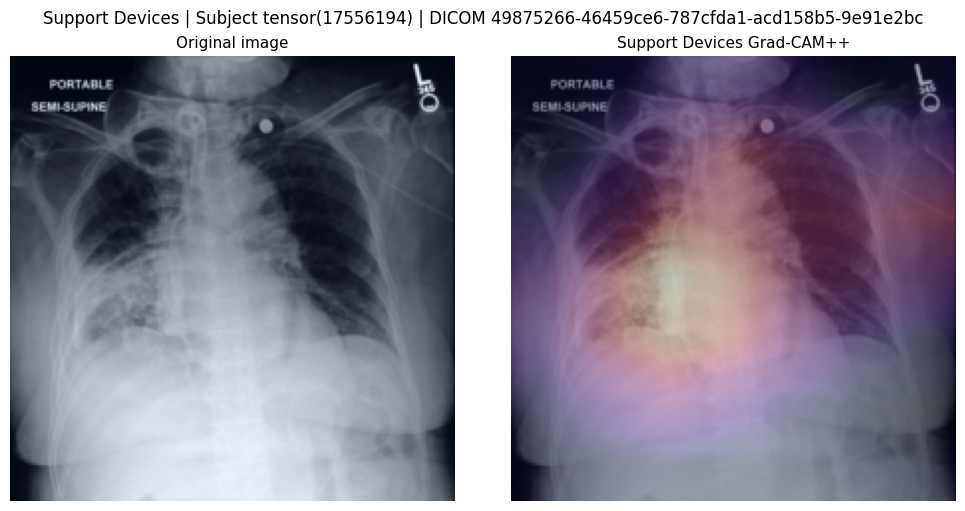


Sample        : 4/8
Pathology     : Consolidation
Method        : Grad-CAM++
Subject ID    : tensor(12691833)
Study ID      : tensor(59271253)
DICOM ID      : 222562f4-a19b517d-019d4f05-81ece1b2-c647ca60
Image         : 222562f4-a19b517d-019d4f05-81ece1b2-c647ca60.jpg
Image Path    : ...2/p12691833/s59271253/222562f4-a19b517d-019d4f05-81ece1b2-c647ca60.jpg
Ground Truth  : 1
Prediction    : 0
Margin        : -0.018


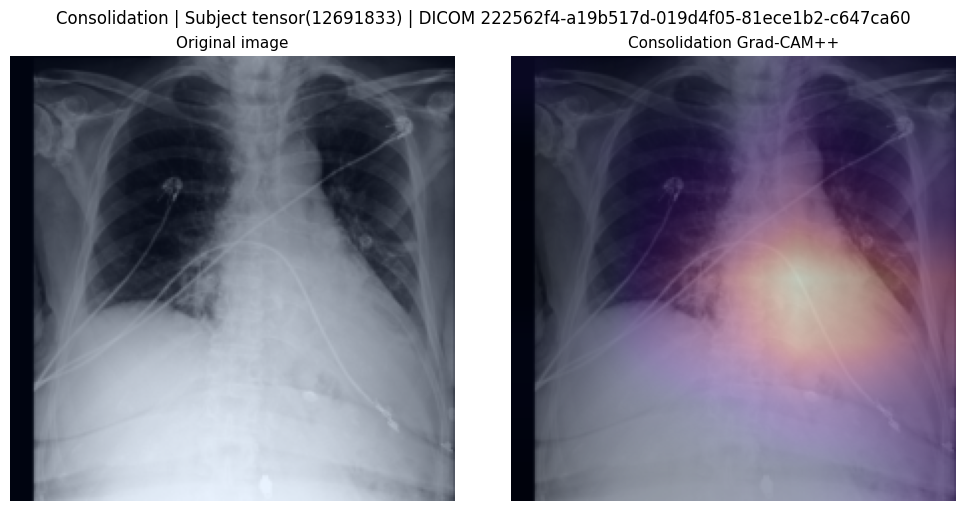


Sample        : 5/8
Pathology     : Cardiomegaly
Method        : Grad-CAM++
Subject ID    : tensor(13464394)
Study ID      : tensor(55263156)
DICOM ID      : ae13fe1c-9fd244b3-1523fa5a-7d594f1a-a6c0a8db
Image         : ae13fe1c-9fd244b3-1523fa5a-7d594f1a-a6c0a8db.jpg
Image Path    : ...3/p13464394/s55263156/ae13fe1c-9fd244b3-1523fa5a-7d594f1a-a6c0a8db.jpg
Ground Truth  : 1
Prediction    : 1
Margin        : 0.120


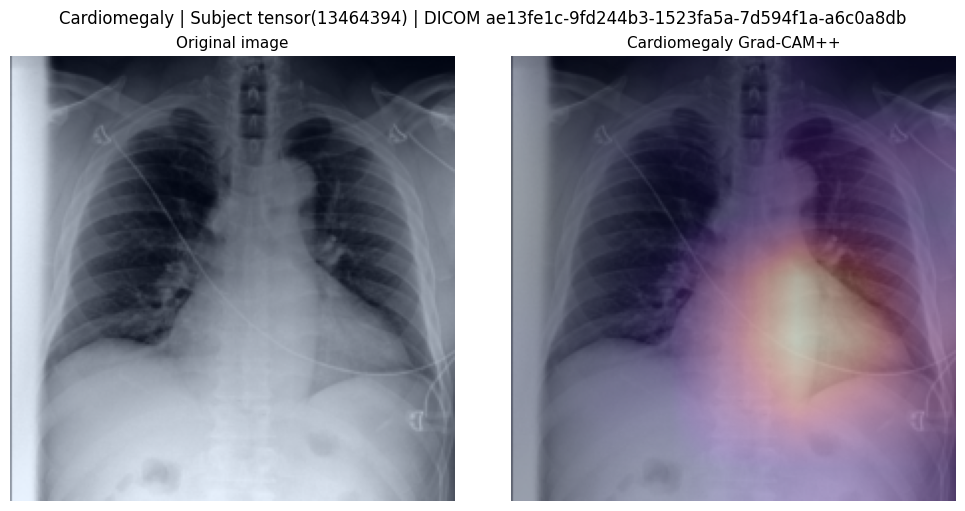


Sample        : 6/8
Pathology     : Atelectasis
Method        : Grad-CAM++
Subject ID    : tensor(17759808)
Study ID      : tensor(57519424)
DICOM ID      : 4329bed3-9c38b502-4d480688-849c7329-4941c218
Image         : 4329bed3-9c38b502-4d480688-849c7329-4941c218.jpg
Image Path    : ...7/p17759808/s57519424/4329bed3-9c38b502-4d480688-849c7329-4941c218.jpg
Ground Truth  : 1
Prediction    : 1
Margin        : -0.005


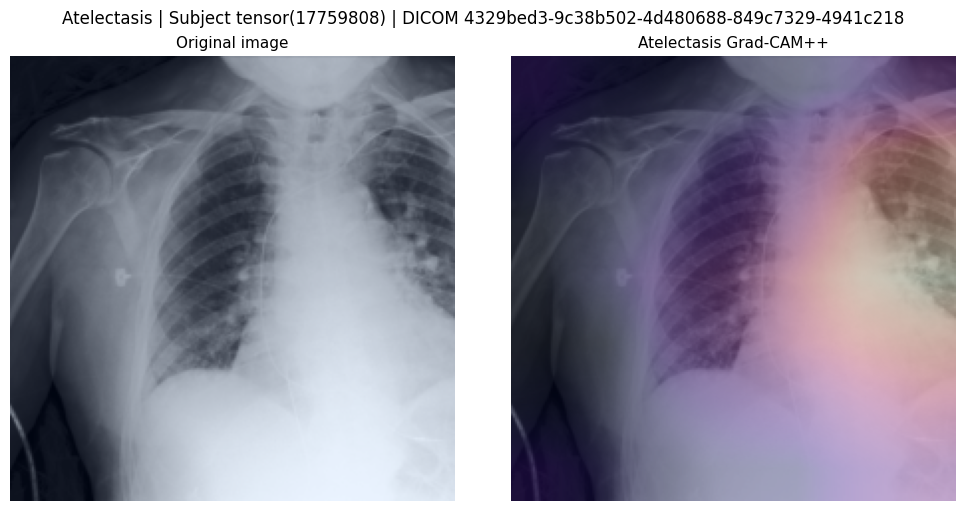


Sample        : 7/8
Pathology     : Edema
Method        : Grad-CAM++
Subject ID    : tensor(14062965)
Study ID      : tensor(58985721)
DICOM ID      : 2f453531-72706205-408aaeba-d025e2cc-c3f6f340
Image         : 2f453531-72706205-408aaeba-d025e2cc-c3f6f340.jpg
Image Path    : ...4/p14062965/s58985721/2f453531-72706205-408aaeba-d025e2cc-c3f6f340.jpg
Ground Truth  : 1
Prediction    : 1
Margin        : 0.402


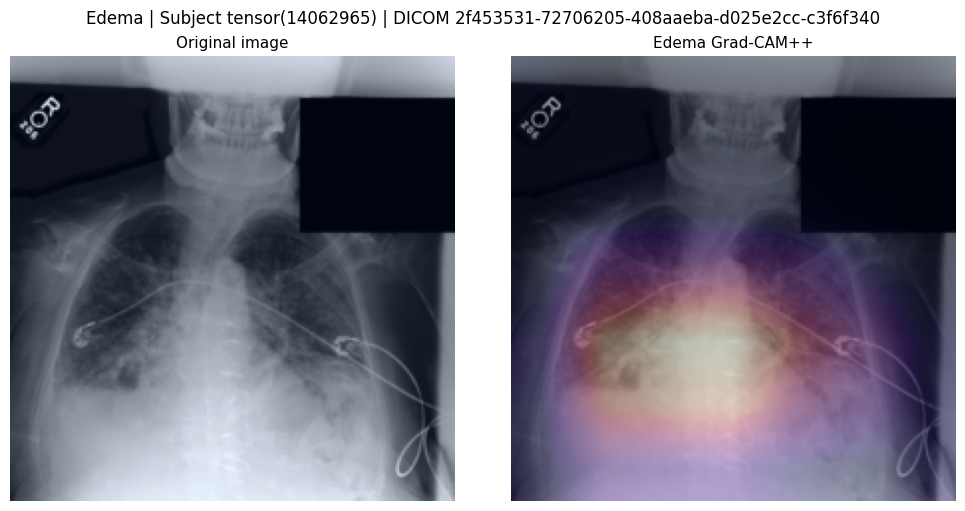


Sample        : 8/8
Pathology     : No Finding
Method        : Grad-CAM++
Subject ID    : tensor(15647422)
Study ID      : tensor(59647919)
DICOM ID      : 70a59206-4b1b8bd0-4e77dbf5-df2e90ad-ba42d70f
Image         : 70a59206-4b1b8bd0-4e77dbf5-df2e90ad-ba42d70f.jpg
Image Path    : ...5/p15647422/s59647919/70a59206-4b1b8bd0-4e77dbf5-df2e90ad-ba42d70f.jpg
Ground Truth  : 1
Prediction    : 1
Margin        : -0.068


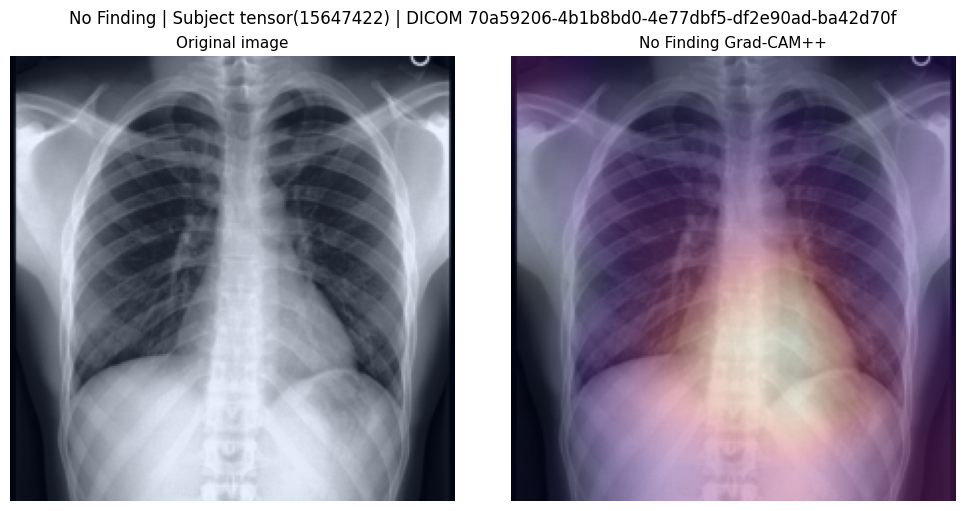

In [116]:
plot_random_gradcam_cases_different_pathologies(
    random_cases=random_cases,
    test_df=results["test_df"],
    pipeline=pipeline,
    method="gradcam++",
    save_dir= SAVE_DIR / "random_gradcam_pp/",
)


Pathology     : Edema
Method        : Grad-CAM
Subject ID    : tensor(10012292)
Study ID      : tensor(57676120)
DICOM ID      : 3a13fd66-e3d03334-55491a06-e0748dbc-eaf053a6
Ground Truth  : 1
Prediction    : 1
Margin        : 0.268


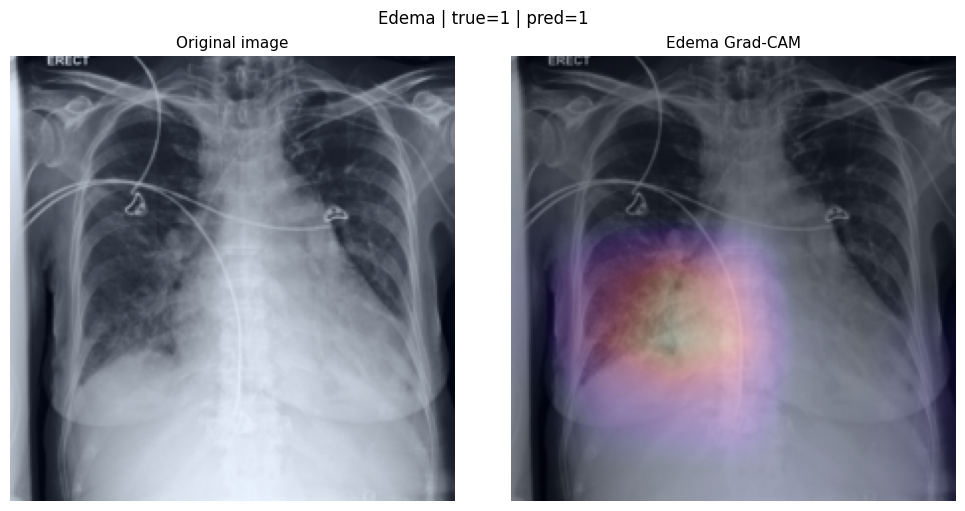


Pathology     : Atelectasis
Method        : Grad-CAM
Subject ID    : tensor(10001217)
Study ID      : tensor(52067803)
DICOM ID      : a917c883-720a5bbf-02c84fc6-98ad00ac-c562ff80
Ground Truth  : 1
Prediction    : 1
Margin        : -0.035


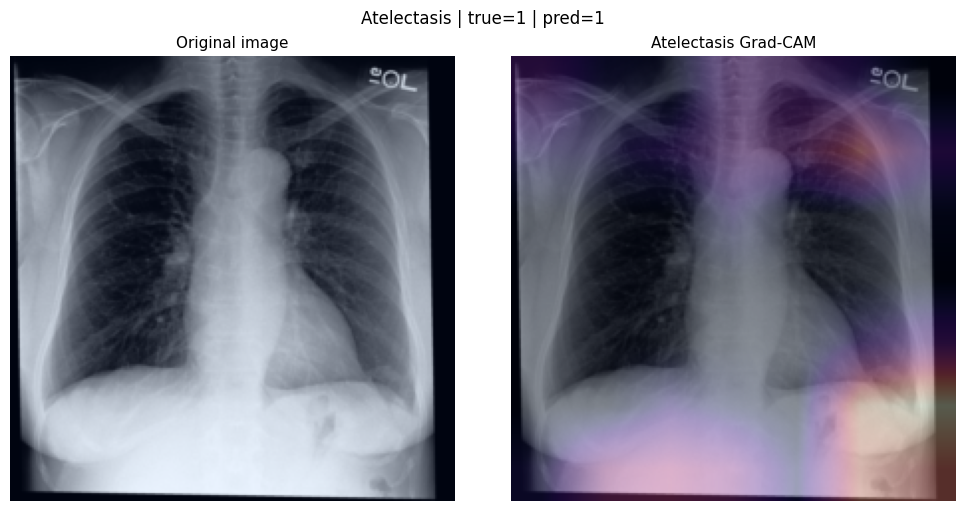


Pathology     : Pleural Effusion
Method        : Grad-CAM
Subject ID    : tensor(10019517)
Study ID      : tensor(56621765)
DICOM ID      : e41ae230-550023fa-242f79bf-02394236-6b64ef7e
Ground Truth  : 1
Prediction    : 0
Margin        : -0.107


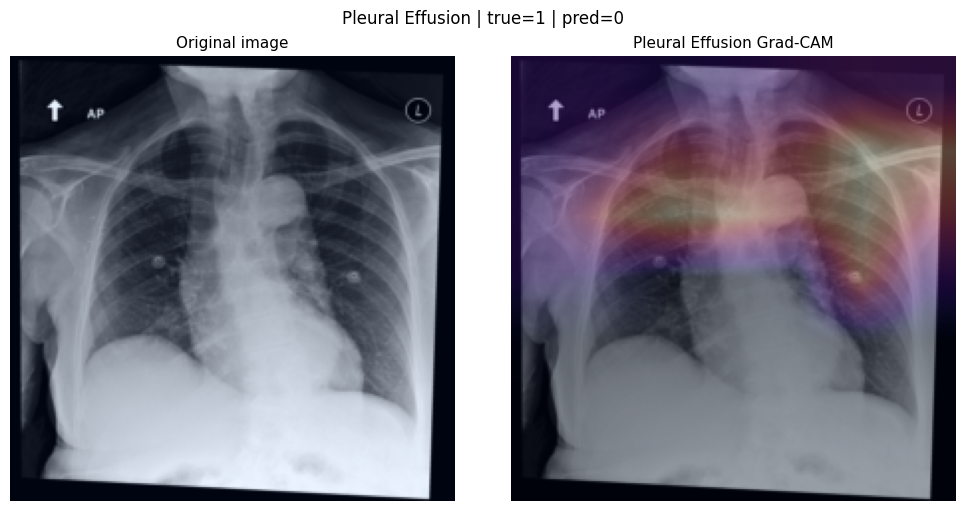


Pathology     : Pneumothorax
Method        : Grad-CAM
Subject ID    : tensor(10500801)
Study ID      : tensor(58577720)
DICOM ID      : 4decce85-c6ede74e-7a8bc81c-e81edee9-5ec17116
Ground Truth  : 1
Prediction    : 1
Margin        : 0.139


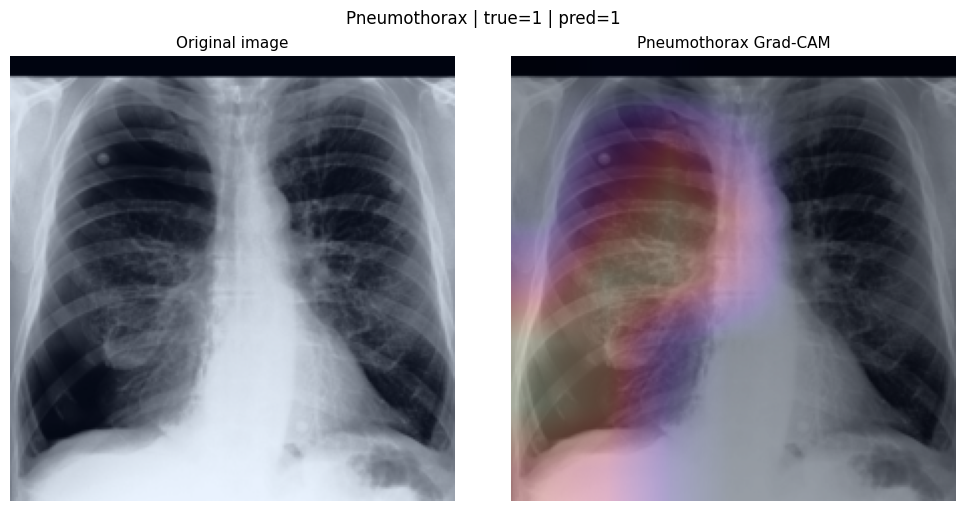


Pathology     : No Finding
Method        : Grad-CAM
Subject ID    : tensor(10021348)
Study ID      : tensor(58126648)
DICOM ID      : a10686ba-1108c14d-9ca725f4-e884aaaf-60276007
Ground Truth  : 1
Prediction    : 1
Margin        : -0.031


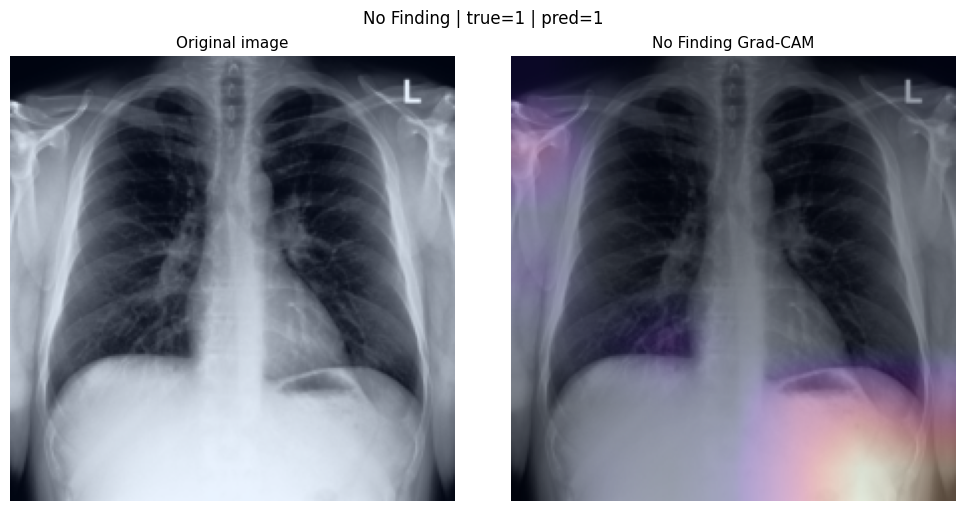

In [117]:
TARGET_CASE_LABELS = [
    "Edema",
    "Atelectasis",
    "Pleural Effusion",
    "Pneumothorax",
    "No Finding",
]

single_cases = {}
for label in TARGET_CASE_LABELS:
    single_cases[label] = get_single_pathology_cases(
        df=test_results_cal,
        label=label,
        labels_of_interest=TARGET_CASE_LABELS,
        n=1,
    )

for label in TARGET_CASE_LABELS:
    plot_selected_gradcam_cases_for_pathology(
        cases_df=single_cases[label],
        label=label,
        test_df=results["test_df"],
        pipeline=pipeline,
        method="gradcam",
        save_dir=SAVE_DIR / "selected_gradcam/",
    )


Pathology     : Edema
Method        : Grad-CAM++
Subject ID    : tensor(10012292)
Study ID      : tensor(57676120)
DICOM ID      : 3a13fd66-e3d03334-55491a06-e0748dbc-eaf053a6
Ground Truth  : 1
Prediction    : 1
Margin        : 0.268


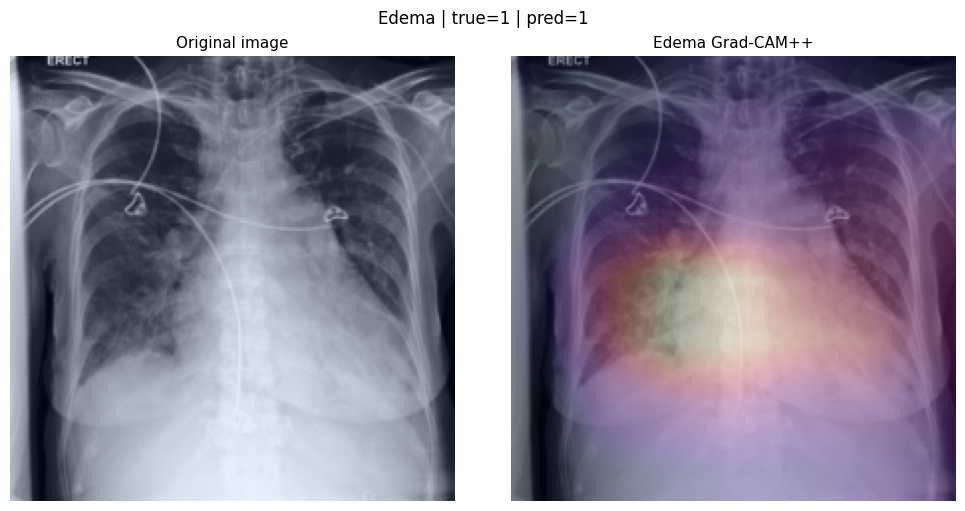


Pathology     : Atelectasis
Method        : Grad-CAM++
Subject ID    : tensor(10001217)
Study ID      : tensor(52067803)
DICOM ID      : a917c883-720a5bbf-02c84fc6-98ad00ac-c562ff80
Ground Truth  : 1
Prediction    : 1
Margin        : -0.035


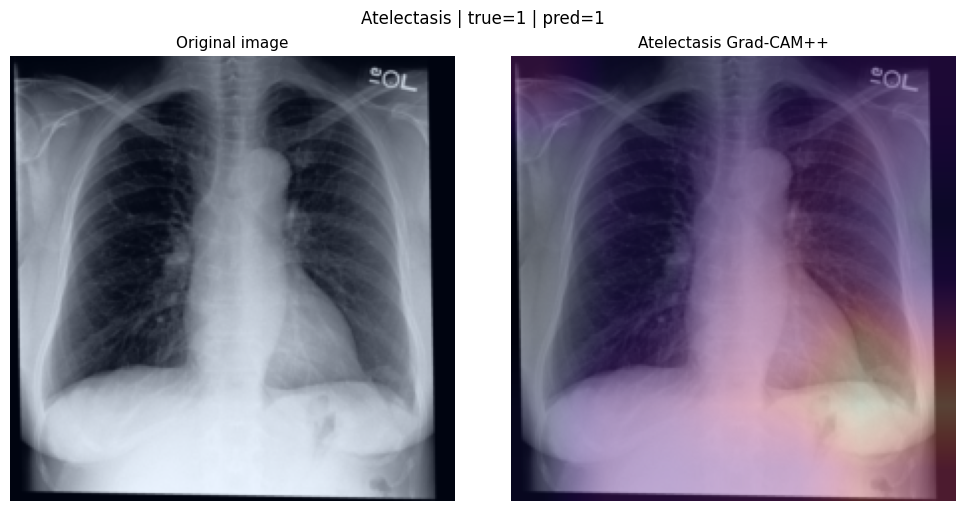


Pathology     : Pleural Effusion
Method        : Grad-CAM++
Subject ID    : tensor(10019517)
Study ID      : tensor(56621765)
DICOM ID      : e41ae230-550023fa-242f79bf-02394236-6b64ef7e
Ground Truth  : 1
Prediction    : 0
Margin        : -0.107


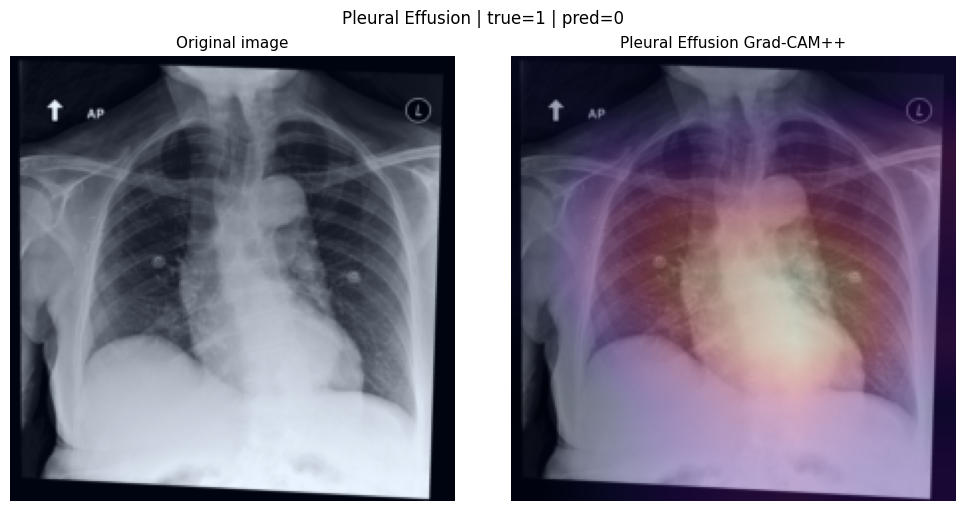


Pathology     : Pneumothorax
Method        : Grad-CAM++
Subject ID    : tensor(10500801)
Study ID      : tensor(58577720)
DICOM ID      : 4decce85-c6ede74e-7a8bc81c-e81edee9-5ec17116
Ground Truth  : 1
Prediction    : 1
Margin        : 0.139


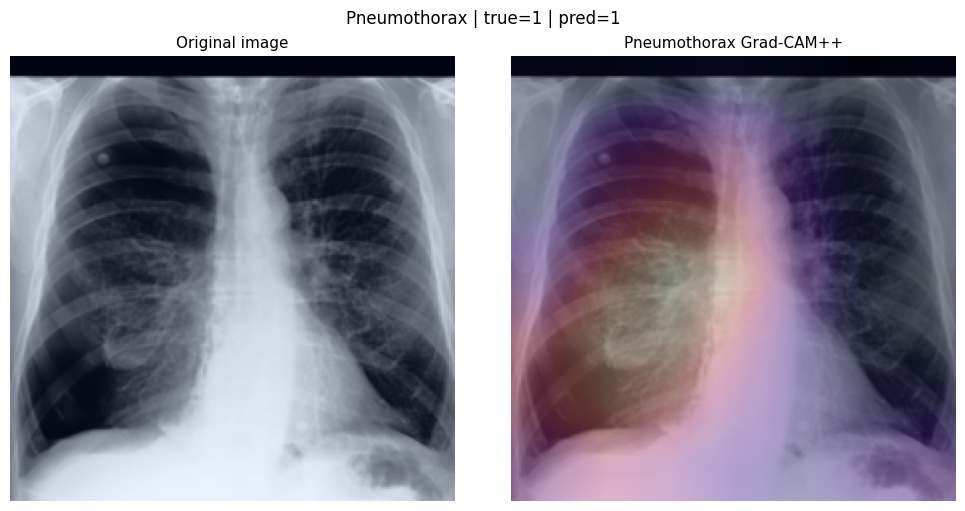


Pathology     : No Finding
Method        : Grad-CAM++
Subject ID    : tensor(10021348)
Study ID      : tensor(58126648)
DICOM ID      : a10686ba-1108c14d-9ca725f4-e884aaaf-60276007
Ground Truth  : 1
Prediction    : 1
Margin        : -0.031


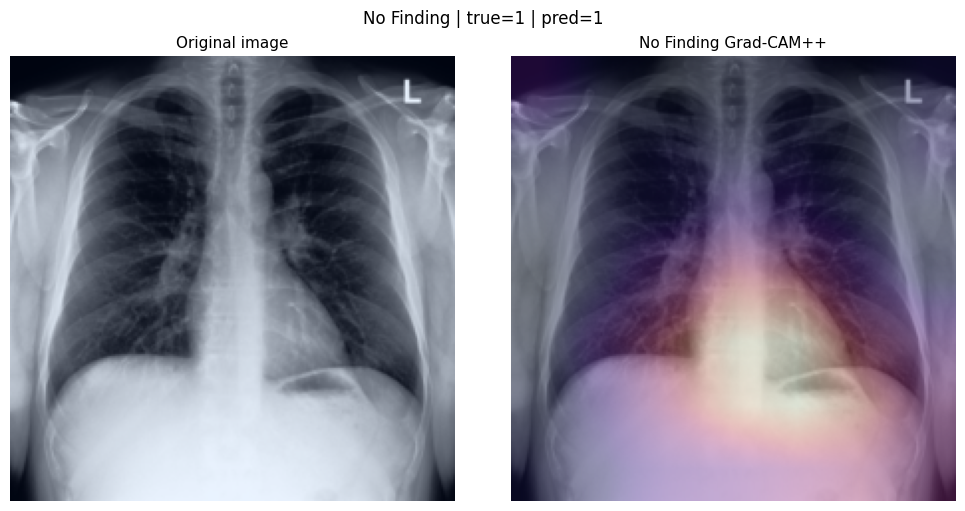

In [118]:
for label in TARGET_CASE_LABELS:
    plot_selected_gradcam_cases_for_pathology(
        cases_df=single_cases[label],
        label=label,
        test_df=results["test_df"],
        pipeline=pipeline,
        method="gradcam++",
        save_dir=SAVE_DIR / "selected_gradcam++/",
    )

# t-CAV

In [119]:
EVAL_PATHOLOGIES = ["Cardiomegaly", "Pleural Effusion", "Pneumothorax"]

test_emb = results["test_embedding_info"]
cxr_clip_samples = build_cxr_clip_samples(
    embeddings=test_emb["embeddings"],
    metadata=test_emb["metadata"],
    targets=pipeline["targets"],
)
print(f"CXR-CLIP samples: {len(cxr_clip_samples)}")
print(f"Embedding dim: {cxr_clip_samples[0]['image_emb'].shape}")


CXR-CLIP samples: 2000
Embedding dim: torch.Size([512])


In [120]:
# Build CXR-CLIP TCAV independently
cxr_clip_concepts = build_tcav_concepts(
    samples=cxr_clip_samples,
    pathologies=EVAL_PATHOLOGIES,
    embedding_key="image_emb",
    max_positive=100,
    max_negative=100,
    seed=42,
    model_name="CXR-CLIP",
    has_text_emb=False,
)

# Summary table
cxr_clip_tcav_df = tcav_single_model_to_dataframe(
    cxr_clip_concepts, model_name="CXR-CLIP"
)
display(cxr_clip_tcav_df)


[CXR-CLIP] Building TCAV: Cardiomegaly
  Positives: 100, Negatives: 100
  Embedding TCAV: 0.6100

[CXR-CLIP] Building TCAV: Pleural Effusion
  Positives: 100, Negatives: 100
  Embedding TCAV: 0.4550

[CXR-CLIP] Building TCAV: Pneumothorax
  Positives: 100, Negatives: 100
  Embedding TCAV: 0.5900


,Pathology,Model,N_pos,N_neg,Embedding_TCAV,Similarity_TCAV
0,Cardiomegaly,CXR-CLIP,100,100,0.610,None
1,Pleural Effusion,CXR-CLIP,100,100,0.455,None
2,Pneumothorax,CXR-CLIP,100,100,0.590,None


Saved: outputs/run_20260428_231401/Grad-CAM/cxr_clip_tcav_table.png


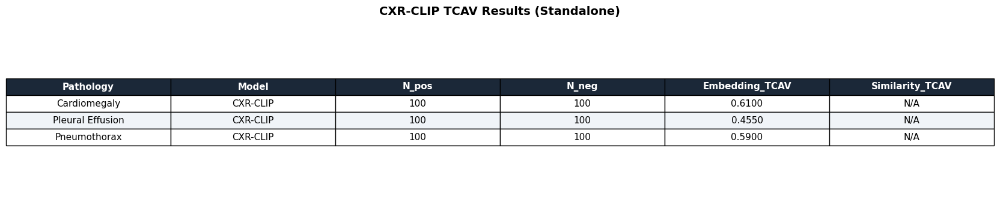

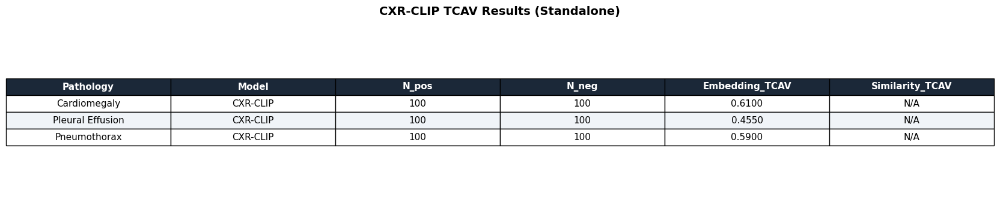

In [121]:
plot_tcav_table_figure(
    cxr_clip_tcav_df,
    title="CXR-CLIP TCAV Results (Standalone)",
    save_path=str(SAVE_DIR / "cxr_clip_tcav_table.png"),
)

/tmp/ipykernel_1619180/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


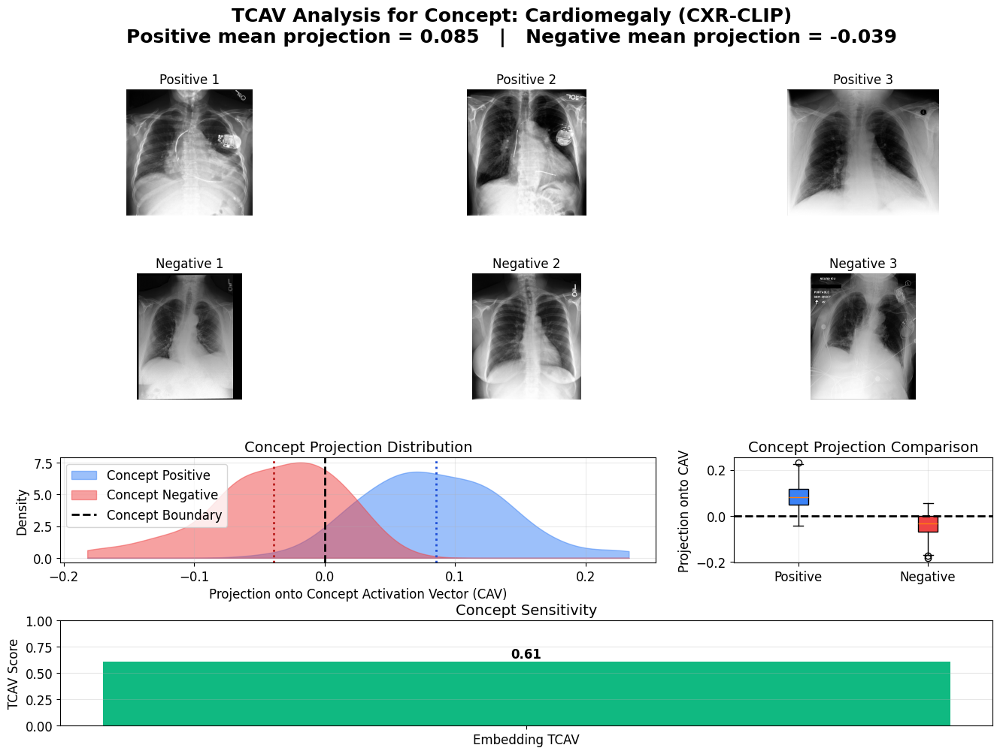

/tmp/ipykernel_1619180/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


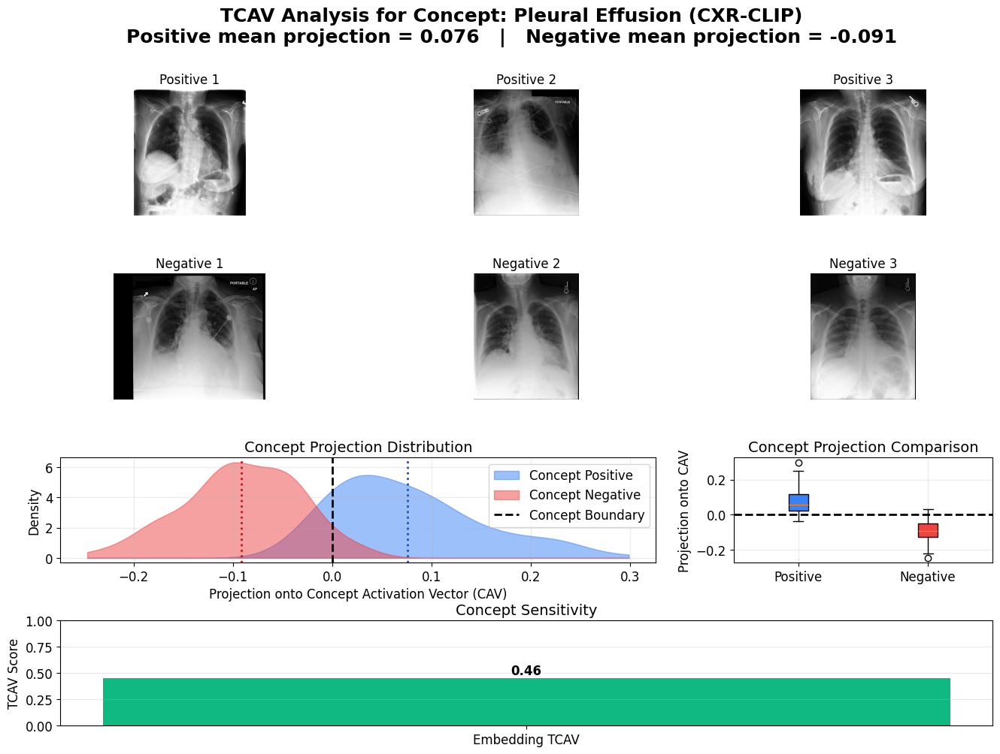

/tmp/ipykernel_1619180/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


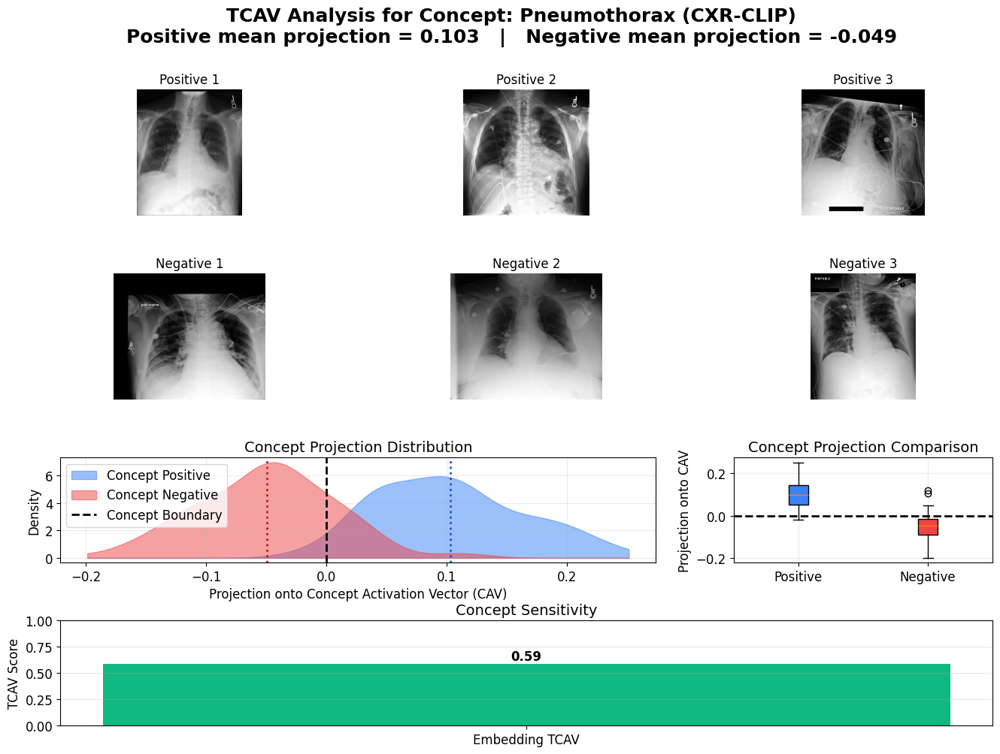

In [122]:
for pathology, data in cxr_clip_concepts.items():
    plot_tcav_summary(
        concept_name=f"{pathology} (CXR-CLIP)",
        positives=data["positives"],
        negatives=data["negatives"],
        cav=data["cav"],
        tcav_score=data["tcav_emb"],
        similarity_tcav_score=data["tcav_sim"],
        embedding_key="image_emb",
    )

In [123]:
from models.cxr_clip.load import encode_text

for s in cxr_clip_samples:
    # Use the positive prompt for the first positive label as proxy text embedding
    pos_labels = [k for k, v in s["labels"].items() if v == 1.0]
    if pos_labels:
        label = pos_labels[0]
        prompts = pipeline["prompts"][label]["pos"]
        text_emb = encode_text(pipeline["model"], pipeline["tokenizer"], prompts)
        s["text_emb"] = F.normalize(text_emb.mean(dim=0), dim=0).detach().cpu()
    else:
        # Use "No Finding" prompt
        prompts = pipeline["prompts"].get("No Finding", {}).get("pos", ["no abnormality detected"])
        text_emb = encode_text(pipeline["model"], pipeline["tokenizer"], prompts)
        s["text_emb"] = F.normalize(text_emb.mean(dim=0), dim=0).detach().cpu()

In [124]:
# Now rebuild with similarity TCAV enabled
cxr_clip_concepts_with_sim = build_tcav_concepts(
    samples=cxr_clip_samples,
    pathologies=EVAL_PATHOLOGIES,
    embedding_key="image_emb",
    max_positive=100,
    max_negative=100,
    seed=42,
    model_name="CXR-CLIP (with Sim)",
    has_text_emb=True,
)


[CXR-CLIP (with Sim)] Building TCAV: Cardiomegaly
  Positives: 100, Negatives: 100
  Embedding TCAV: 0.6100
  Similarity TCAV: 0.9200

[CXR-CLIP (with Sim)] Building TCAV: Pleural Effusion
  Positives: 100, Negatives: 100
  Embedding TCAV: 0.4550
  Similarity TCAV: 0.7950

[CXR-CLIP (with Sim)] Building TCAV: Pneumothorax
  Positives: 100, Negatives: 100
  Embedding TCAV: 0.5900
  Similarity TCAV: 0.8650


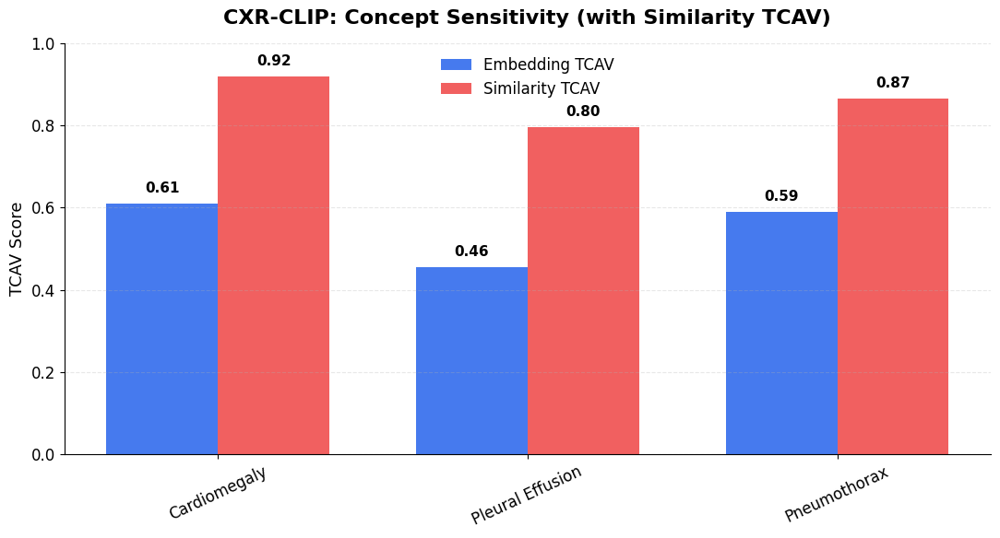

In [125]:
cxr_clip_tcav_sim_df = tcav_single_model_to_dataframe(
    cxr_clip_concepts_with_sim, model_name="CXR-CLIP"
)

plot_tcav_concept_comparison(
    cxr_clip_concepts_with_sim,
    title="CXR-CLIP: Concept Sensitivity (with Similarity TCAV)",
)

## Counterfactuals

In [126]:
# ============================================================
# D. Visualization
# ============================================================

def plot_cxr_clip_negation_counterfactuals(df, save_path=None):
    labels = df["label"].unique()
    fig, ax = plt.subplots(figsize=(10, 6))
    fig.patch.set_facecolor("white")

    x = np.arange(len(labels))
    width = 0.35

    orig = [df[df["label"] == l]["original_margin"].mean() for l in labels]
    cf = [df[df["label"] == l]["cf_margin"].mean() for l in labels]

    bars1 = ax.bar(x - width/2, orig, width, label="Original Prompts",
                   color="#0077B6", edgecolor="white", linewidth=0.8)
    bars2 = ax.bar(x + width/2, cf, width, label="Swapped Prompts",
                   color="#E63946", edgecolor="white", linewidth=0.8)

    for bars in [bars1, bars2]:
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.002,
                    f"{h:.4f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=12)
    ax.set_ylabel("Mean Margin", fontsize=12)
    ax.set_title("CXR-CLIP: Negation Counterfactuals\n(Swapping Positive ↔ Negative Prompts)",
                 fontsize=14, fontweight="bold")
    ax.legend(frameon=False, fontsize=11)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", color="#E0E0E0", linewidth=0.6)
    ax.set_axisbelow(True)
    plt.tight_layout()

    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=250, bbox_inches="tight", facecolor="white")
        print(f"Saved: {save_path}")
    plt.show()


In [127]:
def plot_cxr_clip_generic_counterfactuals(df, save_path=None):
    labels = df["label"].unique()
    fig, ax = plt.subplots(figsize=(10, 6))
    fig.patch.set_facecolor("white")

    x = np.arange(len(labels))
    width = 0.35

    orig = [df[df["label"] == l]["original_margin"].mean() for l in labels]
    generic = [df[df["label"] == l]["cf_margin"].mean() for l in labels]

    bars1 = ax.bar(x - width/2, orig, width, label="Disease-Specific Prompts",
                   color="#0077B6", edgecolor="white", linewidth=0.8)
    bars2 = ax.bar(x + width/2, generic, width, label="Generic Prompts",
                   color="#F4A261", edgecolor="white", linewidth=0.8)

    for bars in [bars1, bars2]:
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.002,
                    f"{h:.4f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=12)
    ax.set_ylabel("Mean Margin", fontsize=12)
    ax.set_title("CXR-CLIP: Generic vs Disease-Specific Prompts",
                 fontsize=14, fontweight="bold")
    ax.legend(frameon=False, fontsize=11)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", color="#E0E0E0", linewidth=0.6)
    ax.set_axisbelow(True)
    plt.tight_layout()

    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=250, bbox_inches="tight", facecolor="white")
        print(f"Saved: {save_path}")
    plt.show()


In [128]:
def plot_cxr_clip_latent_counterfactuals(df, save_path=None):
    labels = df["label"].unique()
    fig, ax = plt.subplots(figsize=(11, 6))
    fig.patch.set_facecolor("white")

    x = np.arange(len(labels))
    width = 0.25

    orig = [df[df["label"] == l]["original_margin"].mean() for l in labels]
    toward = [df[df["label"] == l]["toward_margin"].mean() for l in labels]
    away = [df[df["label"] == l]["away_margin"].mean() for l in labels]

    bars1 = ax.bar(x - width, orig, width, label="Original",
                   color="#0077B6", edgecolor="white", linewidth=0.8)
    bars2 = ax.bar(x, toward, width, label="Toward Concept",
                   color="#2A9D8F", edgecolor="white", linewidth=0.8)
    bars3 = ax.bar(x + width, away, width, label="Away from Concept",
                   color="#E63946", edgecolor="white", linewidth=0.8)

    for bars in [bars1, bars2, bars3]:
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.001,
                    f"{h:.4f}", ha="center", va="bottom", fontsize=8, fontweight="bold")

    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=12)
    ax.set_ylabel("Mean Margin", fontsize=12)
    ax.set_title("CXR-CLIP: Latent-Space Counterfactual Edits",
                 fontsize=14, fontweight="bold")
    ax.legend(frameon=False, fontsize=11)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", color="#E0E0E0", linewidth=0.6)
    ax.set_axisbelow(True)
    plt.tight_layout()

    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=250, bbox_inches="tight", facecolor="white")
        print(f"Saved: {save_path}")
    plt.show()

In [129]:
EVAL_PATHOLOGIES = ["Cardiomegaly", "Pleural Effusion", "Pneumothorax"]
SAVE_DIR = OUTPUT_ROOT / "counterfactuals"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

In [130]:
# ============================================================
# A. CXR-CLIP Textual Counterfactuals: Negation (swap prompts)
# ============================================================

negation_cf_df = run_negation_counterfactuals(
    pipeline=pipeline,
    test_df=results["test_df"],
    cxr_clip_samples=cxr_clip_samples,
    pathologies=EVAL_PATHOLOGIES,
    max_per_pathology=20,
    seed=42,
)
print("Negation Counterfactuals:")
display(negation_cf_df.groupby("label")[["original_margin", "cf_margin", "margin_drop"]].mean())

Negation Counterfactuals:


,original_margin,cf_margin,margin_drop
label,,,
Cardiomegaly,0.162178,-0.162178,0.324356
Pleural Effusion,0.027326,-0.027326,0.054653
Pneumothorax,0.005127,-0.005127,0.010253


Saved: outputs/run_20260428_231401/cxr_clip/counterfactuals/negation.png


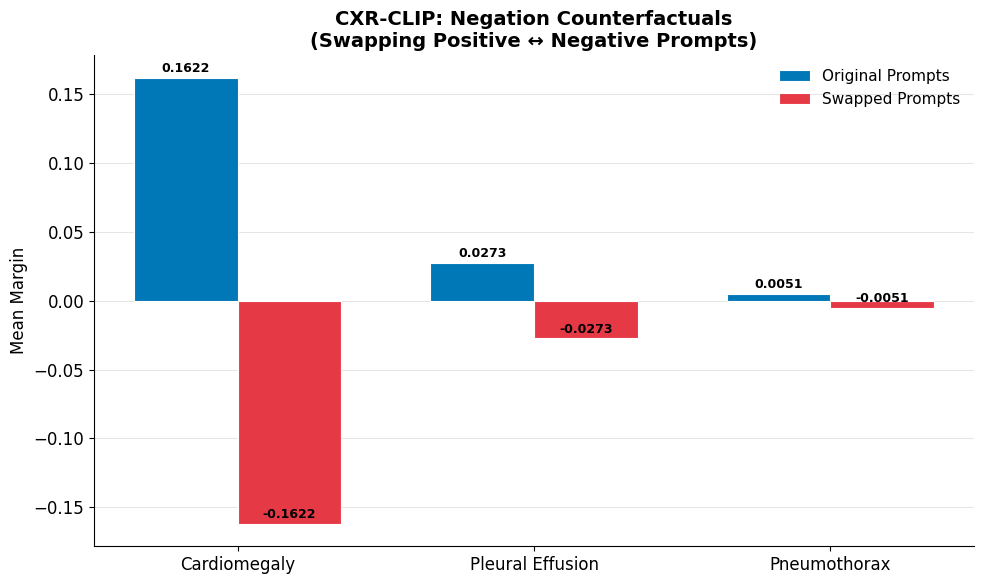

In [131]:
plot_cxr_clip_negation_counterfactuals(
    negation_cf_df,
    save_path=str(OUTPUT_ROOT / "cxr_clip/counterfactuals/negation.png"),
)

In [132]:
# ============================================================
# B. CXR-CLIP Textual Counterfactuals: Generic prompts
# ============================================================
generic_cf_df = run_generic_prompt_counterfactuals(
    pipeline=pipeline,
    test_df=results["test_df"],
    cxr_clip_samples=cxr_clip_samples,
    pathologies=EVAL_PATHOLOGIES,
    max_per_pathology=20,
    seed=42,
)

print("\nGeneric Prompt Counterfactuals:")
display(generic_cf_df.groupby("label")[["original_margin", "cf_margin", "margin_drop"]].mean())



Generic Prompt Counterfactuals:


,original_margin,cf_margin,margin_drop
label,,,
Cardiomegaly,0.162178,0.049810,0.112368
Pleural Effusion,0.027326,0.078074,-0.050748
Pneumothorax,0.005127,0.053401,-0.048275


Saved: outputs/run_20260428_231401/cxr_clip/counterfactuals/generic.png


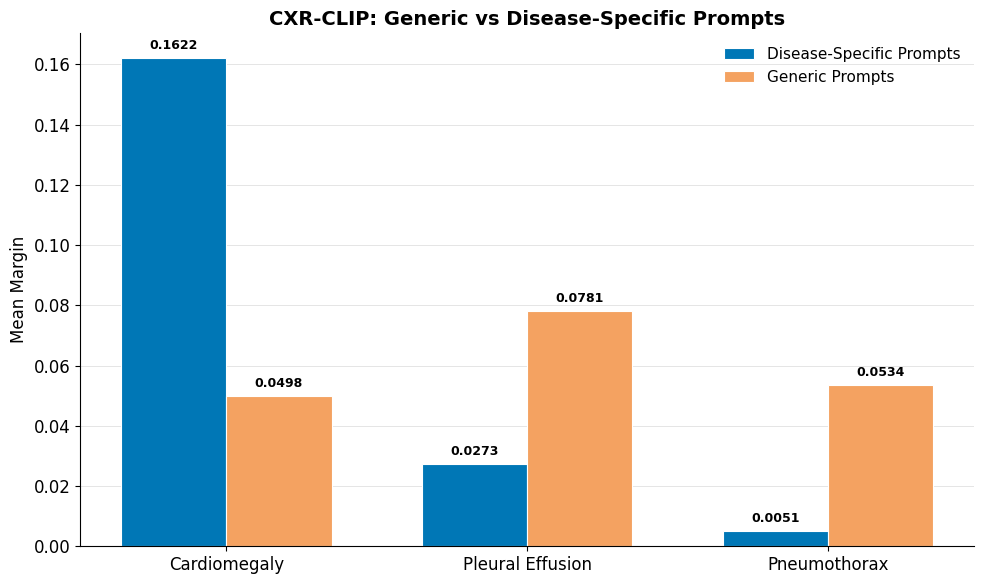

In [133]:
plot_cxr_clip_generic_counterfactuals(
    generic_cf_df,
    save_path=str(OUTPUT_ROOT / "cxr_clip/counterfactuals/generic.png"),
)

In [134]:
# ============================================================
# C. CXR-CLIP Latent-Space Counterfactuals
# ============================================================
# Use CAVs from the CXR-CLIP TCAV we already built
cxr_clip_cavs = {p: cxr_clip_concepts[p]["cav"] for p in EVAL_PATHOLOGIES if p in cxr_clip_concepts}

cxr_clip_latent_cf_df = run_cxr_clip_latent_counterfactuals(
    pipeline=pipeline,
    cxr_clip_samples=cxr_clip_samples,
    concept_vectors=cxr_clip_cavs,
    pathologies=EVAL_PATHOLOGIES,
    max_per_pathology=50,
    epsilon=0.10,
    seed=42,
)
print("\nCXR-CLIP Latent Counterfactuals:")
display(cxr_clip_latent_cf_df.groupby("label")[
    ["original_margin", "toward_margin", "away_margin", "toward_delta", "away_delta"]
].mean())



CXR-CLIP Latent Counterfactuals:


,original_margin,toward_margin,away_margin,toward_delta,away_delta
label,,,,,
Cardiomegaly,0.120487,0.136438,0.103071,0.015951,-0.017416
Pleural Effusion,0.032938,0.048825,0.016498,0.015887,-0.016440
Pneumothorax,0.018735,0.022634,0.014585,0.003898,-0.004150


Saved: outputs/run_20260428_231401/cxr_clip/counterfactuals/latent.png


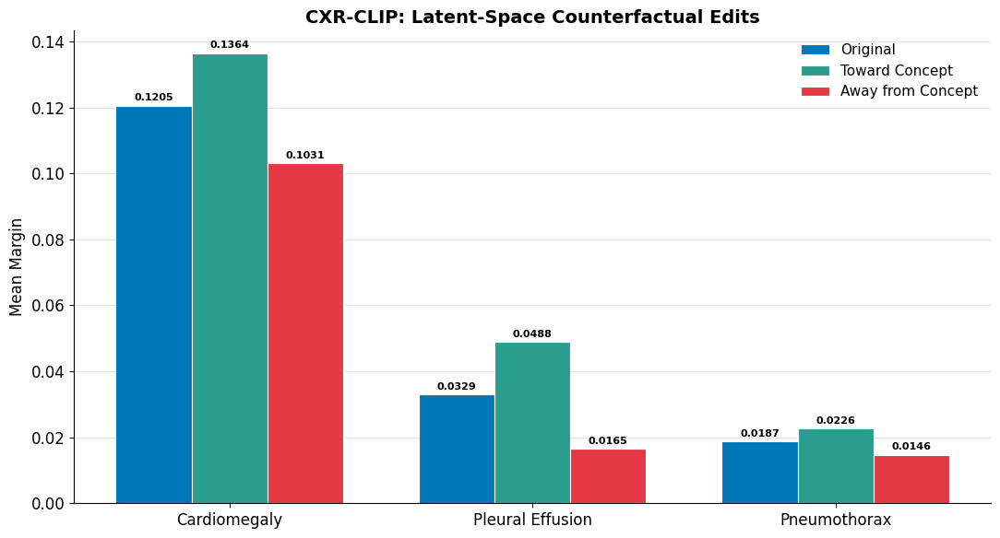

In [135]:
plot_cxr_clip_latent_counterfactuals(
    cxr_clip_latent_cf_df,
    save_path=str(OUTPUT_ROOT / "cxr_clip/counterfactuals/latent.png"),
)

# Evaluation

## Pointing Game (LQ)

In [42]:
needed_ids = collect_needed_dicom_ids(single_samples)
temp_needed_ids = collect_needed_dicom_ids(temporal_samples, include_prior=False)

chex_df = load_chexmask_mimic_csv(
    "/scratch/mtm211/CheXmask/MIMIC-CXR-JPG.csv",
    needed_dicom_ids=needed_ids,
    min_dice_mean=0.7,
)

temp_chex_df = load_chexmask_mimic_csv(
    "/scratch/mtm211/CheXmask/MIMIC-CXR-JPG.csv",
    needed_dicom_ids=temp_needed_ids,
    min_dice_mean=0.7,
)

print("chex_df rows:", len(chex_df))
print("temp_chex_df rows:", len(temp_chex_df))

chexmask_lookup = build_chexmask_lookup(chex_df)
temp_chexmask_lookup = build_chexmask_lookup(temp_chex_df)

print("len(chexmask_lookup):", len(chexmask_lookup))
print("len(temp_chexmask_lookup):", len(temp_chexmask_lookup))


matched_single_samples, missing_single_samples = attach_chexmask_to_samples(
    single_samples,
    chexmask_lookup,
)

matched_temporal_samples, missing_temporal_samples = attach_chexmask_to_temporal_samples(
    temporal_samples,
    temp_chexmask_lookup,   # use the non-empty lookup
)

chex_df rows: 9781
temp_chex_df rows: 1938
len(chexmask_lookup): 9781
len(temp_chexmask_lookup): 1938


In [43]:
POINTING_GAME_LABELS = ["Cardiomegaly", "Pleural Effusion", "Pneumothorax"]

pointing_cases_all = {
    label: get_single_pathology_cases(
        df=test_results_cal,
        label=label,
        labels_of_interest=POINTING_GAME_LABELS,
        n=None,
    )
    for label in POINTING_GAME_LABELS
}

pointing_cases_vis = {
    label: get_single_pathology_cases(
        df=test_results_cal,
        label=label,
        labels_of_interest=POINTING_GAME_LABELS,
        n=1,
    )
    for label in POINTING_GAME_LABELS
}

In [44]:
EVAL_PATHOLOGIES = ["Cardiomegaly", "Pleural Effusion", "Pneumothorax"]

selected_single, selected_temporal, balanced_counts = balanced_pathology_sample(
    single_samples=matched_single_samples,
    temporal_samples=matched_temporal_samples,
    pathologies=EVAL_PATHOLOGIES,
    seed=42,
)

print("\nBalanced counts:", balanced_counts)

Cardiomegaly: 513 samples per dataset (single had 3954, temporal had 513)
Pleural Effusion: 875 samples per dataset (single had 4394, temporal had 875)
Pneumothorax: 483 samples per dataset (single had 1142, temporal had 483)

Balanced counts: {'Cardiomegaly': 513, 'Pleural Effusion': 875, 'Pneumothorax': 483}


## BioViL-T

In [45]:
def get_positive_pathologies(sample, allowed_pathologies=None):
    """
    Returns list of positive pathology labels for a sample.
    Uses sample["labels"] which should be a dict of {label: value}.
    """
    labels = sample.get("labels")
    if labels is None:
        return []

    positives = []
    for k, v in labels.items():
        try:
            is_pos = float(v) == 1.0
        except Exception:
            is_pos = False

        if is_pos:
            if allowed_pathologies is None or k in allowed_pathologies:
                positives.append(k)

    return positives

In [46]:
def make_pointing_record(
    heatmap,
    sample,
    pathology_name,
    method_name,
):
    return {
        "heatmap": heatmap.detach().cpu(),
        "pathology_name": pathology_name,
        "chexmask_masks": sample["chexmask_masks"],
        "image_id": sample["chexmask_image_id"],
        "method_name": method_name,
        "sample": sample
    }

In [47]:
def build_temporal_rollout_pointing_records(
    temporal_results,
    heatmap_key="current_to_current",
    method_name="Temporal Rollout",
    allowed_pathologies=None,
    use_first_positive_only=True,
):
    records = []

    for r in temporal_results:
        sample = r["sample"]
        heatmap = r["heatmaps"][heatmap_key]

        positives = get_positive_pathologies(
            sample,
            allowed_pathologies=allowed_pathologies,
        )

        if not positives:
            continue

        if use_first_positive_only:
            positives = positives[:1]

        for pathology_name in positives:
            records.append(
                make_pointing_record(
                    heatmap=heatmap,
                    sample=sample,
                    pathology_name=pathology_name,
                    method_name=method_name,
                )
            )

    return records

In [48]:
def build_spatial_rollout_pointing_records(
    spatial_results,
    method_name="Spatial Rollout",
    allowed_pathologies=None,
    use_first_positive_only=True,
):
    """
    spatial_results: list of dicts, each with:
        - "heatmap_up"
        - "sample"   (matched curated sample)
    """
    records = []

    for r in spatial_results:
        sample = r["sample"]
        heatmap = r["heatmap_up"]

        positives = get_positive_pathologies(
            sample,
            allowed_pathologies=allowed_pathologies,
        )

        if not positives:
            continue

        if use_first_positive_only:
            positives = positives[:1]

        for pathology_name in positives:
            records.append(
                make_pointing_record(
                    heatmap=heatmap,
                    sample=sample,
                    pathology_name=pathology_name,
                    method_name=method_name,
                )
            )

    return records

In [49]:
def build_gradcam_pointing_records(
    cam_batch,
    matched_batch_samples,
    method_name="Grad-CAM",
    allowed_pathologies=None,
    use_first_positive_only=True,
):
    """
    cam_batch: Tensor [B, H, W]
    matched_batch_samples: list of matched samples aligned with cam_batch order
    """
    records = []

    if cam_batch.shape[0] != len(matched_batch_samples):
        raise ValueError(
            f"Batch size mismatch: cam_batch has {cam_batch.shape[0]} maps "
            f"but matched_batch_samples has {len(matched_batch_samples)} samples"
        )

    for i in range(cam_batch.shape[0]):
        sample = matched_batch_samples[i]
        positives = get_positive_pathologies(
            sample,
            allowed_pathologies=allowed_pathologies,
        )

        if not positives:
            continue

        if use_first_positive_only:
            positives = positives[:1]

        for pathology_name in positives:
            records.append(
                make_pointing_record(
                    heatmap=cam_batch[i],
                    sample=sample,
                    pathology_name=pathology_name,
                    method_name=method_name,
                )
            )

    return records

In [50]:
def index_samples_by_image_path(samples, image_path_key="image_path"):
    index = {}
    for s in samples:
        path = s["metadata"].get(image_path_key)
        if path is not None:
            index[path] = s
    return index


def attach_sample_to_spatial_results(
    spatial_results,
    matched_single_samples,
    image_path_key="image_path",
):
    index = index_samples_by_image_path(
        matched_single_samples,
        image_path_key=image_path_key,
    )

    out = []
    for r in spatial_results:
        img_path = r["metadata"].get(image_path_key)
        if img_path in index:
            r_new = dict(r)
            r_new["sample"] = index[img_path]
            out.append(r_new)

    return out

def attach_sample_to_temporal_results(
    temporal_results,
    matched_temporal_samples,
):
    index = {}

    for s in matched_temporal_samples:
        key = (str(Path(s["chunk_path"]).resolve()), int(s["sample_idx"]))
        index[key] = s

    out = []
    for r in temporal_results:
        key = (str(Path(r["chunk_path"]).resolve()), int(r["sample_idx"]))

        if key in index:
            r_new = dict(r)
            r_new["sample"] = index[key]
            out.append(r_new)

    return out


In [51]:
def evaluate_spatial_rollout_pointing_game(
    spatial_results,
    matched_single_samples,
    allowed_pathologies=None,
    method_name="Spatial Rollout",
    use_first_positive_only=True,
):
    """
    End-to-end Pointing Game evaluation for spatial rollout results.

    Args:
        spatial_results: output list from plot_random_spatial_attention_rollouts(...)
        matched_single_samples: curated samples already matched to CheXmask

    Returns:
        records, results, score, summary_method, summary_pathology
    """
    spatial_results = attach_sample_to_spatial_results(
        spatial_results,
        matched_single_samples,
        image_path_key="image_path",
    )

    records = build_spatial_rollout_pointing_records(
        spatial_results,
        method_name=method_name,
        allowed_pathologies=allowed_pathologies,
        use_first_positive_only=use_first_positive_only,
    )

    results, score = evaluate_dataset_with_masks(records)
    summary_method = summarize_results_by_method(results)
    summary_pathology = summarize_results_by_pathology(results)

    return records, results, score, summary_method, summary_pathology

In [52]:
def evaluate_temporal_rollout_pointing_game(
    temporal_results,
    matched_temporal_samples,
    allowed_pathologies=None,
    heatmap_key="current_to_current",
    method_name="Temporal Rollout",
    use_first_positive_only=True,
):
    """
    End-to-end Pointing Game evaluation for temporal rollout results.
    Evaluates on the current-image heatmap branch.
    """
    temporal_results = attach_sample_to_temporal_results(
        temporal_results,
        matched_temporal_samples,
    )

    records = build_temporal_rollout_pointing_records(
        temporal_results,
        heatmap_key=heatmap_key,
        method_name=method_name,
        allowed_pathologies=allowed_pathologies,
        use_first_positive_only=use_first_positive_only,
    )

    results, score = evaluate_dataset_with_masks(records)
    summary_method = summarize_results_by_method(results)
    summary_pathology = summarize_results_by_pathology(results)

    return records, results, score, summary_method, summary_pathology

In [53]:
def evaluate_gradcam_pointing_game(
    cam_batch,
    batch,
    matched_single_samples,
    allowed_pathologies=None,
    method_name="Grad-CAM",
    use_first_positive_only=True,
):
    """
    End-to-end Pointing Game evaluation for a Grad-CAM batch.

    Args:
        cam_batch: Tensor [B, H, W]
        batch: batch dict returned by your loader / init_grad_cam
        matched_single_samples: curated samples already matched to CheXmask
        allowed_pathologies: list[str] or None
        method_name: name for reporting
        use_first_positive_only: if True, use only first positive pathology per sample

    Returns:
        records, results, score, summary_method, summary_pathology
    """
    sample_index = {
        s["metadata"]["image_path"]: s
        for s in matched_single_samples
    }

    matched_batch_samples = []
    missing_paths = []

    for img_path in batch["meta"]["image_path"]:
        if img_path in sample_index:
            matched_batch_samples.append(sample_index[img_path])
        else:
            missing_paths.append(img_path)

    if missing_paths:
        print(f"Warning: {len(missing_paths)} batch images were not matched to CheXmask and were skipped.")

    usable_b = len(matched_batch_samples)
    if usable_b == 0:
        raise ValueError("No Grad-CAM batch samples matched to CheXmask.")

    cam_batch = cam_batch[:usable_b]

    records = build_gradcam_pointing_records(
        cam_batch=cam_batch,
        matched_batch_samples=matched_batch_samples,
        method_name=method_name,
        allowed_pathologies=allowed_pathologies,
        use_first_positive_only=use_first_positive_only,
    )

    results, score = evaluate_dataset_with_masks(records)
    summary_method = summarize_results_by_method(results)
    summary_pathology = summarize_results_by_pathology(results)

    return records, results, score, summary_method, summary_pathology

In [54]:
def balance_records_by_pathology(spatial_records, temporal_records, pathologies):
    """
    Post-hoc balancing: for each pathology, trim both record lists
    to the minimum count available across both.
    """
    from collections import defaultdict
    rng = random.Random(42)

    # Group by pathology
    spatial_by_path = defaultdict(list)
    temporal_by_path = defaultdict(list)

    for r in spatial_records:
        if r["pathology_name"] in pathologies:
            spatial_by_path[r["pathology_name"]].append(r)

    for r in temporal_records:
        if r["pathology_name"] in pathologies:
            temporal_by_path[r["pathology_name"]].append(r)

    balanced_spatial = []
    balanced_temporal = []

    for p in pathologies:
        s_list = spatial_by_path[p]
        t_list = temporal_by_path[p]
        n = min(len(s_list), len(t_list))

        if n == 0:
            print(f"Warning: {p} has 0 records in one or both datasets, skipping.")
            continue

        # Shuffle and take n from each
        rng.shuffle(s_list)
        rng.shuffle(t_list)

        balanced_spatial.extend(s_list[:n])
        balanced_temporal.extend(t_list[:n])

        print(f"{p}: {n} records per dataset "
              f"(spatial had {len(s_list)}, temporal had {len(t_list)})")

    return balanced_spatial, balanced_temporal

In [55]:
def pair_records_with_results(records, results):
    paired = []
    for rec, res in zip(records, results):
        if res is None:
            continue
        paired.append({
            "record": rec,
            "result": res,
        })
    return paired

def select_hit_and_miss_examples(paired_records, method_name=None):
    """
    Returns:
        hit_example, miss_example
    """
    if method_name is not None:
        paired_records = [
            x for x in paired_records
            if x["record"].get("method_name") == method_name
        ]

    hit_example = None
    miss_example = None

    for x in paired_records:
        if x["result"]["hit"] and hit_example is None:
            hit_example = x
        if (not x["result"]["hit"]) and miss_example is None:
            miss_example = x

        if hit_example is not None and miss_example is not None:
            break

    return hit_example, miss_example

def plot_pointing_game_record(
    record,
    result=None,
    image_path_key="image_path",
    cmap="magma",
    alpha=0.35,
    save_path=None,
):
    sample = record["sample"]
    pathology_name = record["pathology_name"]
    heatmap = record["heatmap"].float().cpu()
    method_name = record.get("method_name", "Method")

    masks = sample["chexmask_masks"]
    gt_mask = build_proxy_mask(pathology_name, masks).float().cpu()

    img_path = sample["metadata"][image_path_key]
    image = Image.open(img_path).convert("L")
    image_tensor = torch.tensor(list(image.getdata()), dtype=torch.float32).view(
        image.size[1], image.size[0]
    ) / 255.0

    # Resize heatmap/mask to image size
    if heatmap.shape != image_tensor.shape:
        heatmap = torch.nn.functional.interpolate(
            heatmap.unsqueeze(0).unsqueeze(0),
            size=image_tensor.shape,
            mode="bilinear",
            align_corners=False,
        )[0, 0]

    if gt_mask.shape != image_tensor.shape:
        gt_mask = torch.nn.functional.interpolate(
            gt_mask.unsqueeze(0).unsqueeze(0),
            size=image_tensor.shape,
            mode="nearest",
        )[0, 0]

    # Normalize heatmap
    heatmap = heatmap - heatmap.min()
    heatmap = heatmap / (heatmap.max() + 1e-8)

    # Peak point
    flat_idx = int(heatmap.reshape(-1).argmax().item())
    h, w = heatmap.shape
    row = flat_idx // w
    col = flat_idx % w

    hit = bool(gt_mask[row, col].item() > 0)
    if result is not None:
        hit = bool(result["hit"])

    fig, axes = plt.subplots(1, 4, figsize=(18, 5))

    axes[0].imshow(image_tensor, cmap="gray")
    axes[0].set_title("Original CXR")
    axes[0].axis("off")

    axes[1].imshow(image_tensor, cmap="gray")
    axes[1].imshow(heatmap, cmap=cmap, alpha=alpha)
    axes[1].scatter(col, row, c="cyan", s=60, marker="x")
    axes[1].set_title("Heatmap + Peak")
    axes[1].axis("off")

    axes[2].imshow(gt_mask, cmap="gray")
    axes[2].scatter(col, row, c="red", s=60, marker="x")
    axes[2].set_title("CheXmask Target Mask")
    axes[2].axis("off")

    axes[3].imshow(image_tensor, cmap="gray")
    axes[3].imshow(gt_mask, cmap="Greens", alpha=0.25)
    axes[3].imshow(heatmap, cmap=cmap, alpha=alpha)
    axes[3].scatter(col, row, c="cyan", s=60, marker="x")
    axes[3].set_title(f"Combined Overlay\n{'HIT' if hit else 'MISS'}")
    axes[3].axis("off")

    plt.suptitle(
        f"{method_name} | {pathology_name} | {'Correct localisation' if hit else 'Failure case'}",
        fontsize=14,
        fontweight="bold",
    )
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

def plot_hit_and_miss_for_method_saved(
    records,
    results,
    method_name,
    image_path_key="image_path",
    save_dir=None,
):
    if save_dir:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

    paired = pair_records_with_results(records, results)
    hit_example, miss_example = select_hit_and_miss_examples(
        paired,
        method_name=method_name,
    )

    if hit_example is None:
        print(f"No hit example found for {method_name}")
    else:
        print(f"\n{method_name} — Correct localisation")
        # Temporarily disable plt.show to capture the figure
        original_show = plt.show
        fig_holder = {}
        
        def capture_show(*args, **kwargs):
            fig_holder["fig"] = plt.gcf()
        
        plt.show = capture_show
        plot_pointing_game_record(
            hit_example["record"],
            result=hit_example["result"],
            image_path_key=image_path_key,
        )
        plt.show = original_show
        
        if "fig" in fig_holder and save_dir:
            safe_name = method_name.lower().replace(" ", "_")
            path = save_dir / f"{safe_name}_hit.png"
            fig_holder["fig"].savefig(path, dpi=150, bbox_inches="tight")
            print(f"Saved: {path}")
        
        # Now actually show it
        if "fig" in fig_holder:
            fig_holder["fig"].show()
            plt.show()

    if miss_example is None:
        print(f"No miss example found for {method_name}")
    else:
        print(f"\n{method_name} — Failure case")
        original_show = plt.show
        fig_holder = {}
        
        def capture_show(*args, **kwargs):
            fig_holder["fig"] = plt.gcf()
        
        plt.show = capture_show
        plot_pointing_game_record(
            miss_example["record"],
            result=miss_example["result"],
            image_path_key=image_path_key,
        )
        plt.show = original_show
        
        if "fig" in fig_holder and save_dir:
            safe_name = method_name.lower().replace(" ", "_")
            path = save_dir / f"{safe_name}_miss.png"
            fig_holder["fig"].savefig(path, dpi=150, bbox_inches="tight")
            print(f"Saved: {path}")
        
        if "fig" in fig_holder:
            fig_holder["fig"].show()
            plt.show()

In [56]:
# ============================================================
# BALANCED PATHOLOGY SUMMARY AS FIGURES
# ============================================================

def plot_pathology_table_figure(
    pathology_df,
    method_name,
    overall_score=None,
    save_path=None,
    figsize=(8, 2.5),
):
    """
    Render a per-pathology pointing game DataFrame as a clean table figure.
    """
    display_data = []
    for _, row in pathology_df.iterrows():
        display_data.append([
            row["pathology_name"],
            int(row["n"]),
            int(row["hits"]),
            f"{row['pointing_score']:.4f}",
        ])

    # Add overall row
    total_n = int(pathology_df["n"].sum())
    total_hits = int(pathology_df["hits"].sum())
    overall = total_hits / total_n if total_n > 0 else 0.0
    display_data.append(["Overall", total_n, total_hits, f"{overall:.4f}"])

    header = ["Pathology", "N", "Hits", "Pointing Score"]

    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off")

    table = ax.table(
        cellText=display_data,
        colLabels=header,
        cellLoc="center",
        loc="center",
    )

    table.auto_set_font_size(False)
    table.set_fontsize(11)
    table.scale(1, 1.8)

    # Style header
    for j in range(len(header)):
        cell = table[0, j]
        cell.set_facecolor("#2C3E50")
        cell.set_text_props(color="white", fontweight="bold")

    # Style overall row
    overall_idx = len(display_data)
    for j in range(len(header)):
        cell = table[overall_idx, j]
        cell.set_facecolor("#D5F5E3")
        cell.set_text_props(fontweight="bold")

    # Alternate row colors
    for i in range(1, len(display_data)):
        color = "#F8F9FA" if i % 2 == 0 else "white"
        for j in range(len(header)):
            table[i, j].set_facecolor(color)

    ax.set_title(
        f"{method_name} — Pointing Game by Pathology (Balanced)",
        fontsize=13,
        fontweight="bold",
        pad=20,
    )

    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
        print(f"Saved: {save_path}")

    plt.show()
    return fig

In [57]:
SAVE_DIR = OUTPUT_ROOT / "pointing_game"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

Cardiomegaly: 513 samples per dataset (single had 3954, temporal had 513)
Pleural Effusion: 875 samples per dataset (single had 4394, temporal had 875)
Pneumothorax: 483 samples per dataset (single had 1142, temporal had 483)
Patched 1744 records, skipped 0 (no anatomy mask)
Spatial: Counter({'Cardiomegaly': 1058, 'Pleural Effusion': 539, 'Pneumothorax': 147})

Spatial Rollout Score: 0.1823


,pathology_name,n,hits,pointing_score
0,Cardiomegaly,1058,252,0.238185
1,Pneumothorax,147,33,0.224490
2,Pleural Effusion,539,33,0.061224


,method,n,hits,pointing_score
0,Spatial Rollout,1744,318,0.182339



Spatial Rollout — Correct localisation


/tmp/ipykernel_1644890/2773775637.py:55: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  image_tensor = torch.tensor(list(image.getdata()), dtype=torch.float32).view(


Saved: outputs/run_20260429_012236/pointing_game/spatial_rollout_hit.png


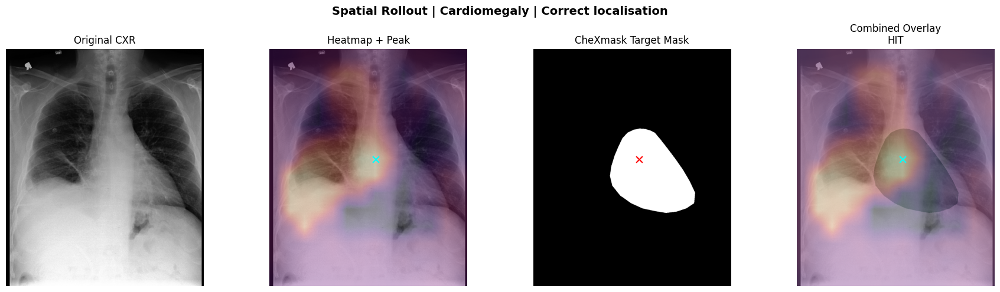


Spatial Rollout — Failure case
Saved: outputs/run_20260429_012236/pointing_game/spatial_rollout_miss.png


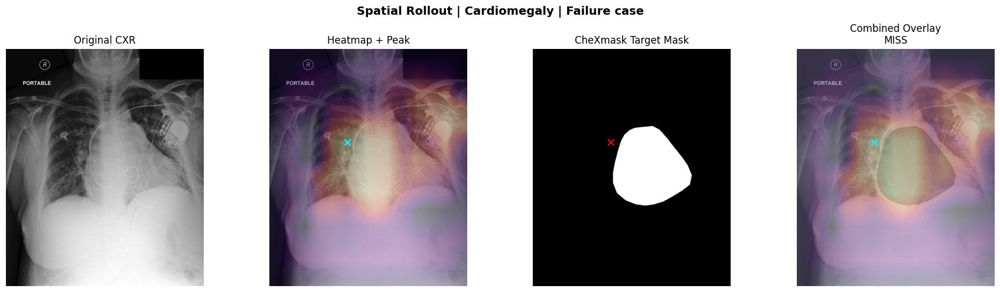

In [58]:
EVAL_PATHOLOGIES = ["Cardiomegaly", "Pleural Effusion", "Pneumothorax"]

# 1. Balanced selection
selected_single, selected_temporal, balanced_counts = balanced_pathology_sample(
    single_samples=matched_single_samples,
    temporal_samples=matched_temporal_samples,
    pathologies=EVAL_PATHOLOGIES,
    seed=42,
)

# 2. Generate spatial rollouts
spatial_results = run_spatial_rollout_for_samples(selected_single, single_chunk_paths)

# 3. Build records
spatial_records = build_spatial_rollout_pointing_records(
    spatial_results,
    method_name="Spatial Rollout",
    allowed_pathologies=EVAL_PATHOLOGIES,
)

# 4. Patch anatomy masks -> pathology masks
spatial_records = patch_records_with_pathology_masks(spatial_records)

# 5. Verify
from collections import Counter
print("Spatial:", Counter(r["pathology_name"] for r in spatial_records))

# 6. Evaluate
spatial_pg_results, spatial_score = evaluate_dataset_with_masks(spatial_records)

# 7. Display
print(f"\nSpatial Rollout Score: {spatial_score:.4f}")

spatial_path_df = summarize_results_by_pathology(spatial_pg_results)
display(spatial_path_df)

spatial_method_df = summarize_results_by_method(spatial_pg_results)
display(spatial_method_df)


# Spatial
plot_hit_and_miss_for_method_saved(
    records=spatial_records,
    results=spatial_pg_results,
    method_name="Spatial Rollout",
    image_path_key="image_path",
    save_dir=SAVE_DIR,
)

Patched 1368 records, skipped 0 (no anatomy mask)
Temporal: Counter({'Pleural Effusion': 686, 'Pneumothorax': 483, 'Cardiomegaly': 199})

Temporal Rollout Score: 0.1126


,pathology_name,n,hits,pointing_score
0,Pneumothorax,483,72,0.149068
1,Cardiomegaly,199,20,0.100503
2,Pleural Effusion,686,62,0.090379


,method,n,hits,pointing_score
0,Temporal Rollout,1368,154,0.112573



Temporal Rollout — Correct localisation


/tmp/ipykernel_1644890/2773775637.py:55: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  image_tensor = torch.tensor(list(image.getdata()), dtype=torch.float32).view(


Saved: outputs/run_20260429_012236/pointing_game/temporal_rollout_hit.png


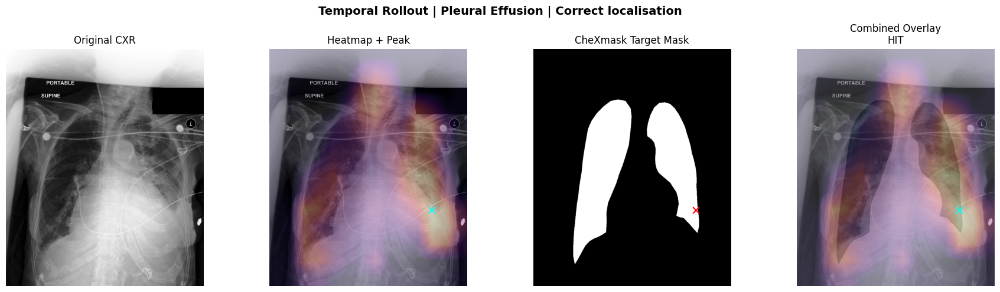


Temporal Rollout — Failure case
Saved: outputs/run_20260429_012236/pointing_game/temporal_rollout_miss.png


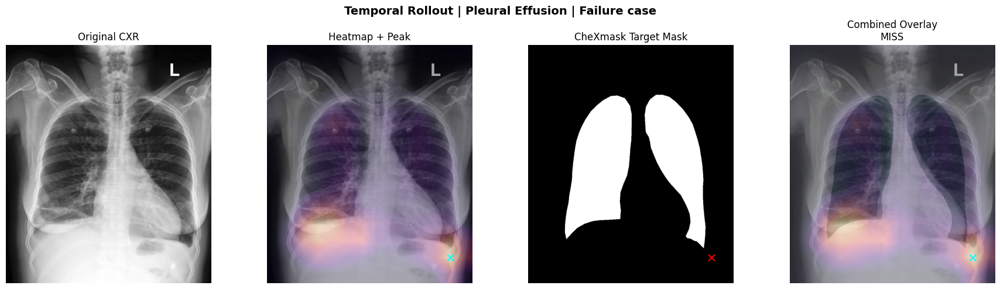

In [59]:
# 1. Generate temporal rollouts (uses selected_temporal from above)
temporal_results = run_temporal_rollout_for_samples(selected_temporal, temporal_chunk_paths)

# 2. Build records
temporal_records = build_temporal_rollout_pointing_records(
    temporal_results,
    heatmap_key="current_to_current",
    method_name="Temporal Rollout",
    allowed_pathologies=EVAL_PATHOLOGIES,
)

# 3. Patch anatomy masks -> pathology masks
temporal_records = patch_records_with_pathology_masks(temporal_records)

# 4. Verify
print("Temporal:", Counter(r["pathology_name"] for r in temporal_records))

# 5. Evaluate
temporal_pg_results, temporal_score = evaluate_dataset_with_masks(temporal_records)

# 6. Display
print(f"\nTemporal Rollout Score: {temporal_score:.4f}")

temporal_path_df = summarize_results_by_pathology(temporal_pg_results)
display(temporal_path_df)

temporal_method_df = summarize_results_by_method(temporal_pg_results)
display(temporal_method_df)


plot_hit_and_miss_for_method_saved(
    records=temporal_records,
    results=temporal_pg_results,
    method_name="Temporal Rollout",
    image_path_key="current_image_path",
    save_dir=SAVE_DIR,
)

Cardiomegaly: 199 records per dataset (spatial had 1058, temporal had 199)
Pleural Effusion: 539 records per dataset (spatial had 539, temporal had 686)
Pneumothorax: 147 records per dataset (spatial had 147, temporal had 483)
Balanced Spatial: Counter({'Pleural Effusion': 539, 'Cardiomegaly': 199, 'Pneumothorax': 147})
Balanced Temporal: Counter({'Pleural Effusion': 539, 'Cardiomegaly': 199, 'Pneumothorax': 147})

Balanced Spatial Score:  0.1299
Balanced Temporal Score: 0.1017

Balanced Spatial by pathology:


,pathology_name,n,hits,pointing_score
0,Cardiomegaly,199,49,0.246231
1,Pneumothorax,147,33,0.224490
2,Pleural Effusion,539,33,0.061224



Balanced Temporal by pathology:


,pathology_name,n,hits,pointing_score
0,Pneumothorax,147,18,0.122449
1,Cardiomegaly,199,20,0.100503
2,Pleural Effusion,539,52,0.096475


Saved: outputs/run_20260429_012236/pointing_game/spatial_rollout_pathology_table_balanced.png


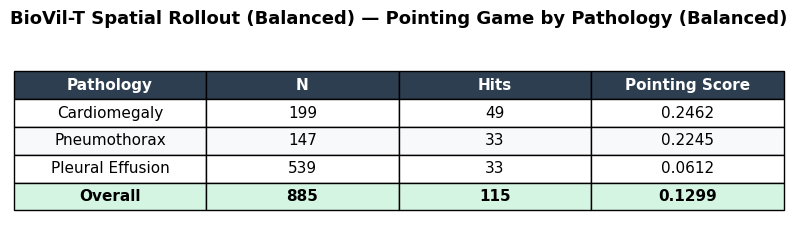

Saved: outputs/run_20260429_012236/pointing_game/temporal_rollout_pathology_table_balanced.png


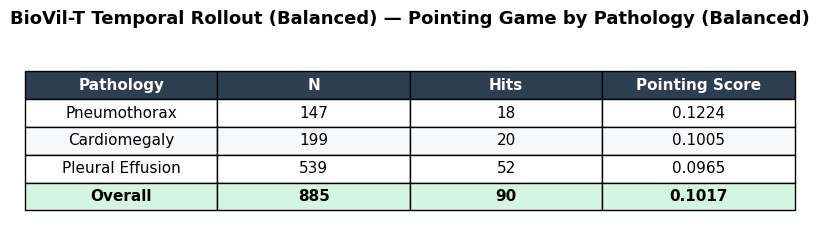

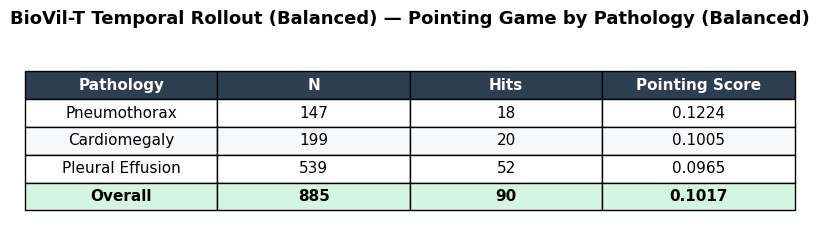

In [60]:
# Post-hoc balance for fair comparison
spatial_balanced, temporal_balanced = balance_records_by_pathology(
    spatial_records,
    temporal_records,
    EVAL_PATHOLOGIES,
)
print("Balanced Spatial:", Counter(r["pathology_name"] for r in spatial_balanced))
print("Balanced Temporal:", Counter(r["pathology_name"] for r in temporal_balanced))

spatial_bal_results, spatial_bal_score = evaluate_dataset_with_masks(spatial_balanced)
temporal_bal_results, temporal_bal_score = evaluate_dataset_with_masks(temporal_balanced)

print(f"\nBalanced Spatial Score:  {spatial_bal_score:.4f}")
print(f"Balanced Temporal Score: {temporal_bal_score:.4f}")

# Generate BALANCED summary DataFrames
spatial_bal_path_df = summarize_results_by_pathology(spatial_bal_results)
temporal_bal_path_df = summarize_results_by_pathology(temporal_bal_results)

print("\nBalanced Spatial by pathology:")
display(spatial_bal_path_df)
print("\nBalanced Temporal by pathology:")
display(temporal_bal_path_df)


plot_pathology_table_figure(
    spatial_bal_path_df,
    method_name="BioVil-T Spatial Rollout (Balanced)",
    save_path=str(SAVE_DIR / "spatial_rollout_pathology_table_balanced.png"),
)

plot_pathology_table_figure(
    temporal_bal_path_df,
    method_name="BioVil-T Temporal Rollout (Balanced)",
    save_path=str(SAVE_DIR / "temporal_rollout_pathology_table_balanced.png"),
)

/home/links/mtm211/.conda/envs/biovil_env/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of the model checkpoint at microsoft/BiomedVLP-BioViL-T were not used when initializing CXRBertModel: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing CXRBertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing CXRBertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Temporal pooler found: <class 'models.biovil_t.transformer.VisionTransformerPooler'>
Using last Conv2d layer for Grad-CAM: projector.model.3 (<class 'torch.nn.modules.conv.Conv2d'>)
BioViL-T Grad-CAM overall pointing score: 0.19740634005763688


,method,n,hits,pointing_score
0,gradcam,694,137,0.197406


,pathology_name,n,hits,pointing_score
0,Cardiomegaly,284,102,0.359155
1,Pneumothorax,69,15,0.217391
2,Pleural Effusion,341,20,0.058651


,hit,peak_row,peak_col,pathology_name,image_id,method_name
0,False,549,330,Cardiomegaly,9660a22d-c7205491-7e14e486-17a71603-95610c63,gradcam
1,False,403,329,Cardiomegaly,b9a2f699-c72f1411-04649240-170bde26-1fd058ee,gradcam
2,True,622,474,Cardiomegaly,1e3a3db6-88c342bf-3bc16f91-9e5f82d3-0dbe6b1a,gradcam
3,False,110,547,Cardiomegaly,36024fc7-5f6f5805-fb893533-7b1e5f73-252c832b,gradcam
4,True,693,693,Cardiomegaly,46b76292-e2460116-8183b54a-bbb5c467-cb1340e7,gradcam


Saved: outputs/run_20260429_012236/pointing_game/biovil_t_gradcam_pathology_table.png


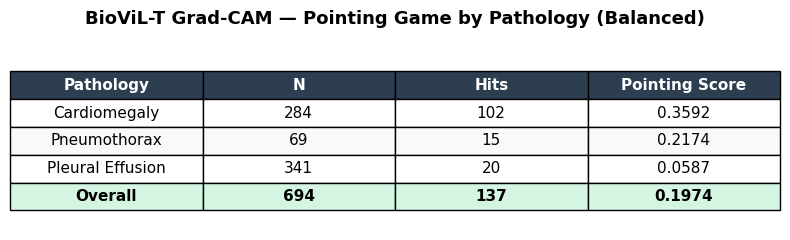

/home/links/mtm211/.conda/envs/biovil_env/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of the model checkpoint at microsoft/BiomedVLP-BioViL-T were not used when initializing CXRBertModel: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing CXRBertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing CXRBertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Temporal pooler found: <class 'models.biovil_t.transformer.VisionTransformerPooler'>
Using last Conv2d layer for Grad-CAM: projector.model.3 (<class 'torch.nn.modules.conv.Conv2d'>)


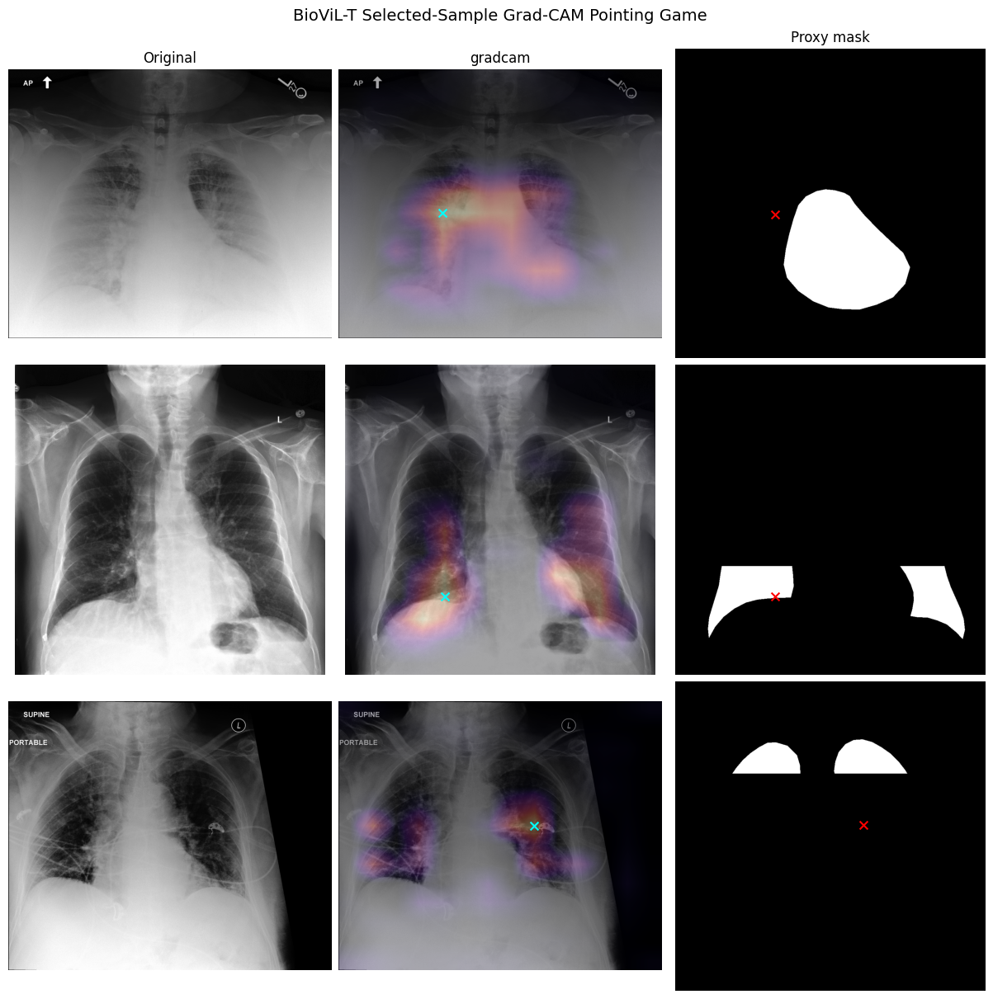

In [61]:
pg_biovil_gradcam = evaluate_biovil_t_selected_cam_pointing_game(
    cases_by_label=pointing_cases_all,
    single_samples=single_samples,
    chexmask_lookup=chexmask_lookup,
    methods=("gradcam",),
)


print("BioViL-T Grad-CAM overall pointing score:", pg_biovil_gradcam["overall_score"])
display(pg_biovil_gradcam["summary_method"])
display(pg_biovil_gradcam["summary_pathology"])
display(pg_biovil_gradcam["results_df"].head())

plot_pathology_table_figure(
    pg_biovil_gradcam["summary_pathology"],
    method_name="BioViL-T Grad-CAM",
    save_path=str(SAVE_DIR / "biovil_t_gradcam_pathology_table.png"),
)


plot_biovil_t_selected_cam_pointing_game_figure(
    cases_by_label=pointing_cases_vis,
    single_samples=single_samples,
    chexmask_lookup=chexmask_lookup,
    methods=("gradcam",),
    save_path=str(SAVE_DIR / "biovil_t_pointing_gradcam.png"),
)

Some weights of the model checkpoint at microsoft/BiomedVLP-BioViL-T were not used when initializing CXRBertModel: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing CXRBertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing CXRBertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Temporal pooler found: <class 'models.biovil_t.transformer.VisionTransformerPooler'>
Using last Conv2d layer for Grad-CAM: projector.model.3 (<class 'torch.nn.modules.conv.Conv2d'>)
BioViL-T Grad-CAM++ overall pointing score: 0.16570605187319884


,method,n,hits,pointing_score
0,gradcam++,694,115,0.165706


,pathology_name,n,hits,pointing_score
0,Cardiomegaly,284,88,0.309859
1,Pneumothorax,69,16,0.231884
2,Pleural Effusion,341,11,0.032258


,hit,peak_row,peak_col,pathology_name,image_id,method_name
0,False,549,330,Cardiomegaly,9660a22d-c7205491-7e14e486-17a71603-95610c63,gradcam++
1,False,403,329,Cardiomegaly,b9a2f699-c72f1411-04649240-170bde26-1fd058ee,gradcam++
2,False,0,0,Cardiomegaly,1e3a3db6-88c342bf-3bc16f91-9e5f82d3-0dbe6b1a,gradcam++
3,False,110,547,Cardiomegaly,36024fc7-5f6f5805-fb893533-7b1e5f73-252c832b,gradcam++
4,True,693,693,Cardiomegaly,46b76292-e2460116-8183b54a-bbb5c467-cb1340e7,gradcam++


Saved: outputs/run_20260429_012236/pointing_game/biovil_t_gradcam_pp_pathology_table.png


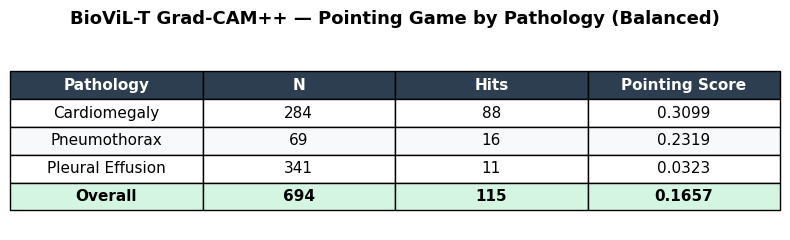

/home/links/mtm211/.conda/envs/biovil_env/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of the model checkpoint at microsoft/BiomedVLP-BioViL-T were not used when initializing CXRBertModel: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing CXRBertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing CXRBertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Temporal pooler found: <class 'models.biovil_t.transformer.VisionTransformerPooler'>
Using last Conv2d layer for Grad-CAM: projector.model.3 (<class 'torch.nn.modules.conv.Conv2d'>)


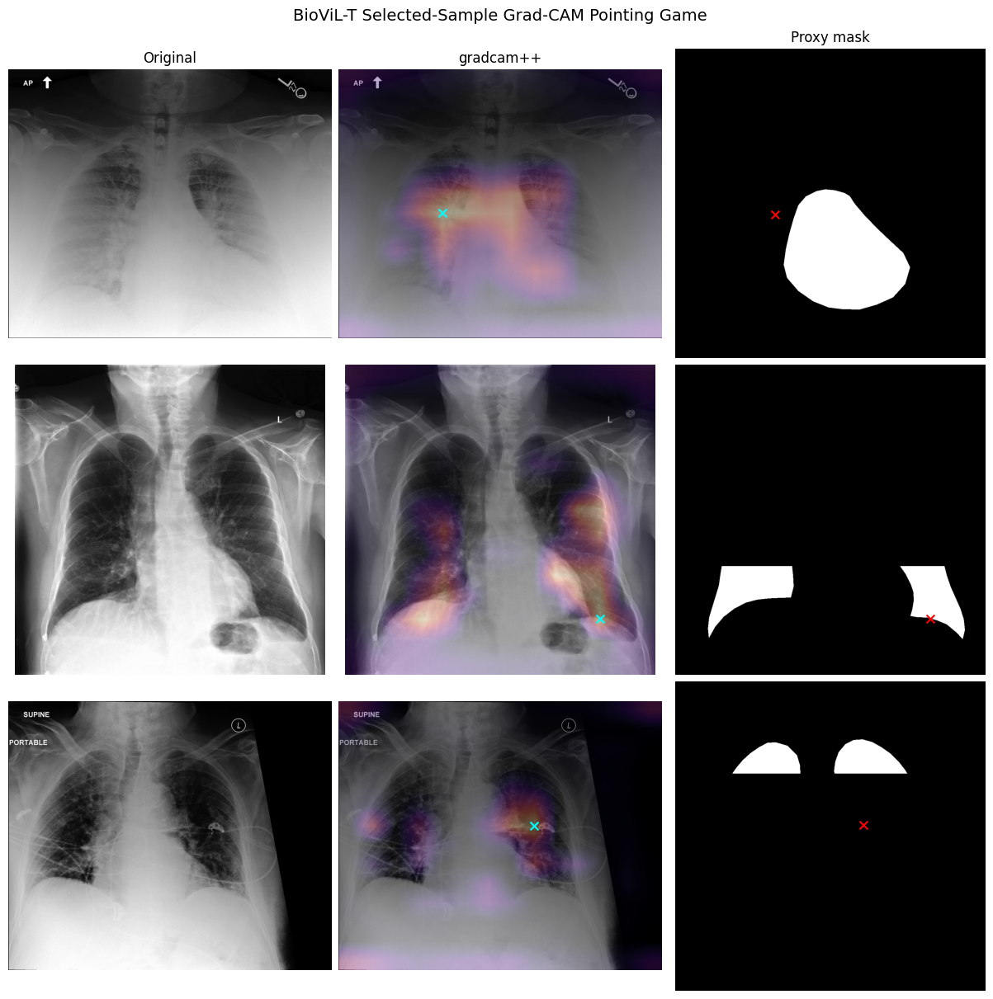

In [62]:
pg_biovil_gradcam_pp = evaluate_biovil_t_selected_cam_pointing_game(
    cases_by_label=pointing_cases_all,
    single_samples=single_samples,
    chexmask_lookup=chexmask_lookup,
    methods=("gradcam++",),
)

print("BioViL-T Grad-CAM++ overall pointing score:", pg_biovil_gradcam_pp["overall_score"])
display(pg_biovil_gradcam_pp["summary_method"])
display(pg_biovil_gradcam_pp["summary_pathology"])
display(pg_biovil_gradcam_pp["results_df"].head())

plot_pathology_table_figure(
    pg_biovil_gradcam_pp["summary_pathology"],
    method_name="BioViL-T Grad-CAM++",
    save_path=str(SAVE_DIR / "biovil_t_gradcam_pp_pathology_table.png"),
)

plot_biovil_t_selected_cam_pointing_game_figure(
    cases_by_label=pointing_cases_vis,
    single_samples=single_samples,
    chexmask_lookup=chexmask_lookup,
    methods=("gradcam++",),
    save_path=str(SAVE_DIR / "biovil_t_pointing_gradcam_pp.png"),
)

## CXR-CLIP

CXR-CLIP Grad-CAM overall pointing score: 0.2622478386167147


,hit,peak_row,peak_col,pathology_name,image_id,method_name
0,True,802,656,Cardiomegaly,9660a22d-c7205491-7e14e486-17a71603-95610c63,gradcam
1,False,660,802,Cardiomegaly,b9a2f699-c72f1411-04649240-170bde26-1fd058ee,gradcam
2,True,514,514,Cardiomegaly,1e3a3db6-88c342bf-3bc16f91-9e5f82d3-0dbe6b1a,gradcam
3,False,221,802,Cardiomegaly,36024fc7-5f6f5805-fb893533-7b1e5f73-252c832b,gradcam
4,True,656,802,Cardiomegaly,46b76292-e2460116-8183b54a-bbb5c467-cb1340e7,gradcam
...,...,...,...,...,...,...
689,False,801,222,Pneumothorax,7b9346a3-08588000-e7a234bc-ccd4a39e-9fea30ef,gradcam
690,False,368,807,Pneumothorax,10201641-377f287b-c762b0d0-c3bcdbf2-833bf93a,gradcam
691,False,513,656,Pneumothorax,4e4138d8-21dbe6c5-a52d3143-a4070fd5-20cb1afd,gradcam
692,False,953,953,Pneumothorax,1e24ae22-3027891c-c7bba699-0786d004-453d20de,gradcam


,method,n,hits,pointing_score
0,gradcam,694,182,0.262248


,pathology_name,n,hits,pointing_score
0,Cardiomegaly,284,169,0.595070
1,Pneumothorax,69,9,0.130435
2,Pleural Effusion,341,4,0.011730


Saved: outputs/run_20260429_012236/pointing_game/cxr_clip_gradcam_pathology_table.png


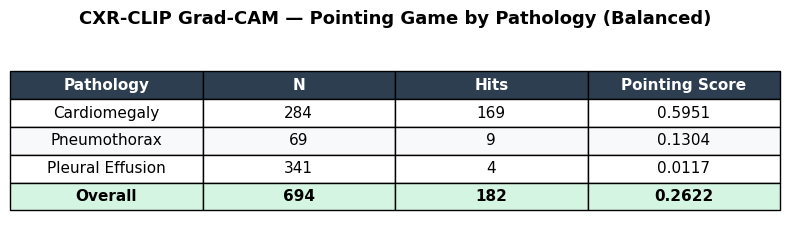

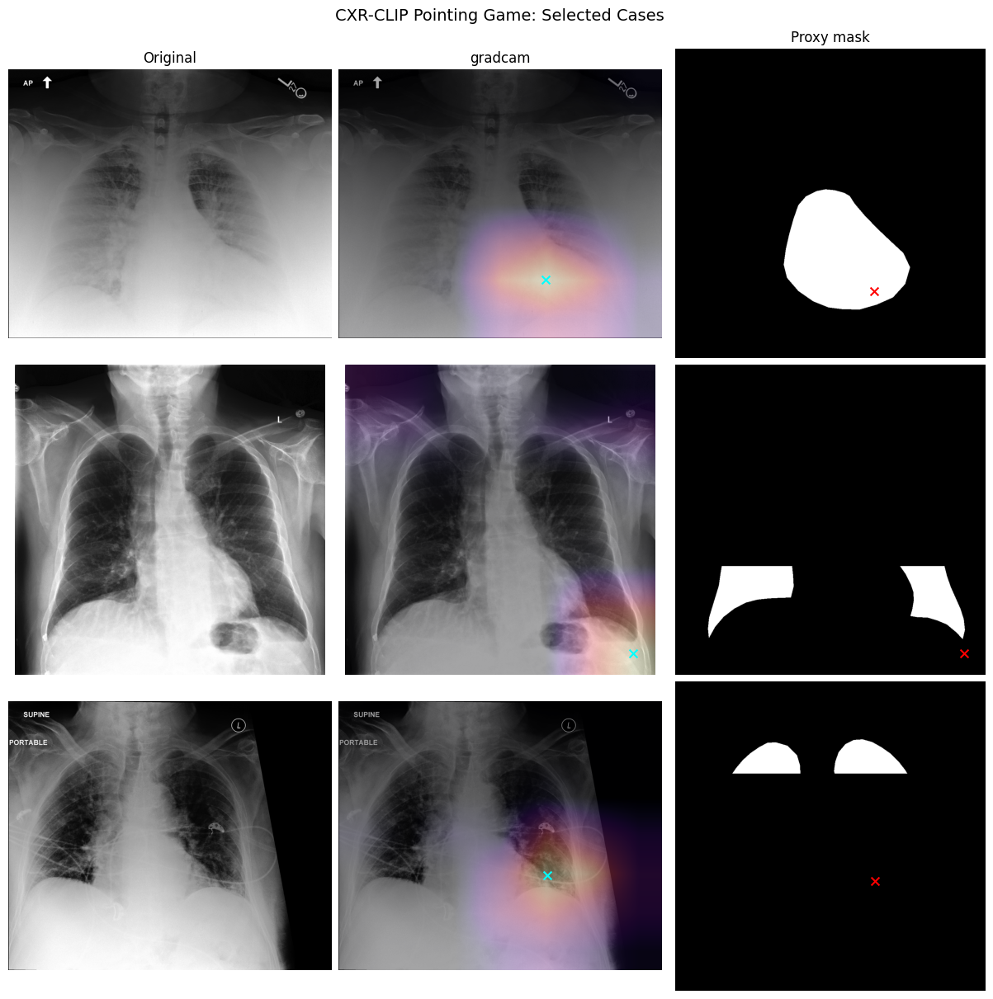

In [63]:
pg_cxr_gradcam = evaluate_cxr_clip_pointing_game(
    cases_by_label=pointing_cases_all,
    test_df=results["test_df"],
    pipeline=pipeline,
    chexmask_lookup=chexmask_lookup,
    methods=("gradcam",),
    use_margin=True,
)


print("CXR-CLIP Grad-CAM overall pointing score:", pg_cxr_gradcam["overall_score"])
display(pg_cxr_gradcam["results_df"])
display(pg_cxr_gradcam["summary_method"])
display(pg_cxr_gradcam["summary_pathology"])

plot_pathology_table_figure(
    pg_cxr_gradcam["summary_pathology"],
    method_name="CXR-CLIP Grad-CAM",
    save_path=(SAVE_DIR / "cxr_clip_gradcam_pathology_table.png"),
)

plot_cxr_clip_pointing_game_figure(
    cases_by_label=pointing_cases_vis,
    test_df=results["test_df"],
    pipeline=pipeline,
    chexmask_lookup=chexmask_lookup,
    methods=("gradcam",),
    save_path=str(SAVE_DIR / "cxr_clip_pointing_gradcam.png"),
)


pg_cxr_gradcam["summary_method"].to_csv(SAVE_DIR / "cxr_clip_gradcam_summary_method.csv", index=False)        # was out_dir / "summary_method.csv"
pg_cxr_gradcam["summary_pathology"].to_csv(SAVE_DIR / "cxr_clip_gradcam_summary_pathology.csv", index=False)  # was out_dir / "summary_pathology.csv"
pg_cxr_gradcam["results_df"].to_csv(SAVE_DIR / "cxr_clip_gradcam_results_per_case.csv", index=False)          # was out_dir / "results_per_case.csv"


CXR-CLIP Grad-CAM++ overall pointing score: 0.35014409221902015


,hit,peak_row,peak_col,pathology_name,image_id,method_name
0,True,802,660,Cardiomegaly,9660a22d-c7205491-7e14e486-17a71603-95610c63,gradcam++
1,False,509,363,Cardiomegaly,b9a2f699-c72f1411-04649240-170bde26-1fd058ee,gradcam++
2,True,514,514,Cardiomegaly,1e3a3db6-88c342bf-3bc16f91-9e5f82d3-0dbe6b1a,gradcam++
3,False,221,656,Cardiomegaly,36024fc7-5f6f5805-fb893533-7b1e5f73-252c832b,gradcam++
4,True,656,802,Cardiomegaly,46b76292-e2460116-8183b54a-bbb5c467-cb1340e7,gradcam++
...,...,...,...,...,...,...
689,False,656,363,Pneumothorax,7b9346a3-08588000-e7a234bc-ccd4a39e-9fea30ef,gradcam++
690,False,802,514,Pneumothorax,10201641-377f287b-c762b0d0-c3bcdbf2-833bf93a,gradcam++
691,False,660,514,Pneumothorax,4e4138d8-21dbe6c5-a52d3143-a4070fd5-20cb1afd,gradcam++
692,False,807,514,Pneumothorax,1e24ae22-3027891c-c7bba699-0786d004-453d20de,gradcam++


,method,n,hits,pointing_score
0,gradcam++,694,243,0.350144


,pathology_name,n,hits,pointing_score
0,Cardiomegaly,284,231,0.813380
1,Pneumothorax,69,5,0.072464
2,Pleural Effusion,341,7,0.020528


Saved: outputs/run_20260429_012236/pointing_game/cxr_clip_gradcam_pp_pathology_table.png


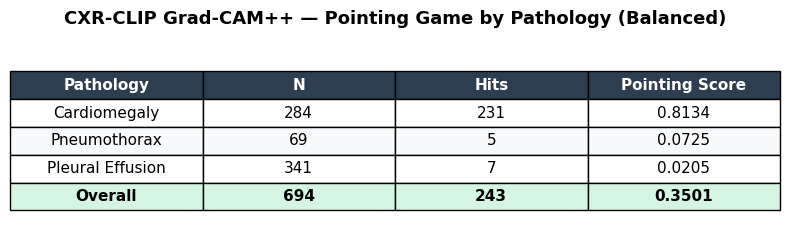

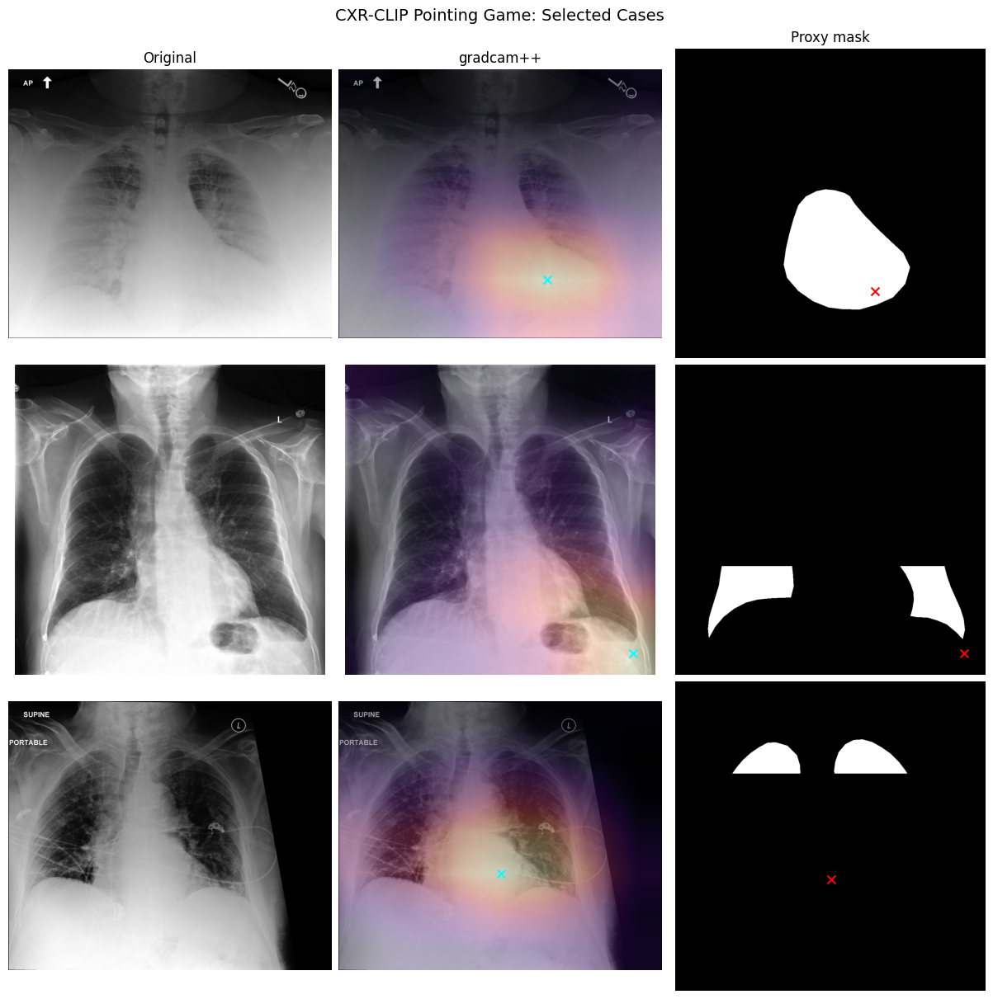

In [64]:
pg_cxr_gradcam_pp = evaluate_cxr_clip_pointing_game(
    cases_by_label=pointing_cases_all,
    test_df=results["test_df"],
    pipeline=pipeline,
    chexmask_lookup=chexmask_lookup,
    methods=("gradcam++",),
    use_margin=True,
)

print("CXR-CLIP Grad-CAM++ overall pointing score:", pg_cxr_gradcam_pp["overall_score"])
display(pg_cxr_gradcam_pp["results_df"])
display(pg_cxr_gradcam_pp["summary_method"])
display(pg_cxr_gradcam_pp["summary_pathology"])

plot_pathology_table_figure(
    pg_cxr_gradcam_pp["summary_pathology"],
    method_name="CXR-CLIP Grad-CAM++",
    save_path=str(SAVE_DIR / "cxr_clip_gradcam_pp_pathology_table.png"),
)


plot_cxr_clip_pointing_game_figure(
    cases_by_label=pointing_cases_vis,
    test_df=results["test_df"],
    pipeline=pipeline,
    chexmask_lookup=chexmask_lookup,
    methods=("gradcam++",),
    save_path=str(SAVE_DIR / "cxr_clip_pointing_gradcam_pp.png"),
)


pg_cxr_gradcam_pp["summary_method"].to_csv(SAVE_DIR / "cxr_clip_gradcam_pp_summary_method.csv", index=False)
pg_cxr_gradcam_pp["summary_pathology"].to_csv(SAVE_DIR / "cxr_clip_gradcam_pp_summary_pathology.csv", index=False)
pg_cxr_gradcam_pp["results_df"].to_csv(SAVE_DIR / "cxr_clip_gradcam_pp_results_per_case.csv", index=False)


Overall pointing score: 0.35014409221902015


,hit,peak_row,peak_col,pathology_name,image_id,method_name
0,True,802,660,Cardiomegaly,9660a22d-c7205491-7e14e486-17a71603-95610c63,gradcam++
1,False,509,363,Cardiomegaly,b9a2f699-c72f1411-04649240-170bde26-1fd058ee,gradcam++
2,True,514,514,Cardiomegaly,1e3a3db6-88c342bf-3bc16f91-9e5f82d3-0dbe6b1a,gradcam++
3,False,221,656,Cardiomegaly,36024fc7-5f6f5805-fb893533-7b1e5f73-252c832b,gradcam++
4,True,656,802,Cardiomegaly,46b76292-e2460116-8183b54a-bbb5c467-cb1340e7,gradcam++
...,...,...,...,...,...,...
689,False,656,363,Pneumothorax,7b9346a3-08588000-e7a234bc-ccd4a39e-9fea30ef,gradcam++
690,False,802,514,Pneumothorax,10201641-377f287b-c762b0d0-c3bcdbf2-833bf93a,gradcam++
691,False,660,514,Pneumothorax,4e4138d8-21dbe6c5-a52d3143-a4070fd5-20cb1afd,gradcam++
692,False,807,514,Pneumothorax,1e24ae22-3027891c-c7bba699-0786d004-453d20de,gradcam++


,method,n,hits,pointing_score
0,gradcam++,694,243,0.350144


,pathology_name,n,hits,pointing_score
0,Cardiomegaly,284,231,0.813380
1,Pneumothorax,69,5,0.072464
2,Pleural Effusion,341,7,0.020528


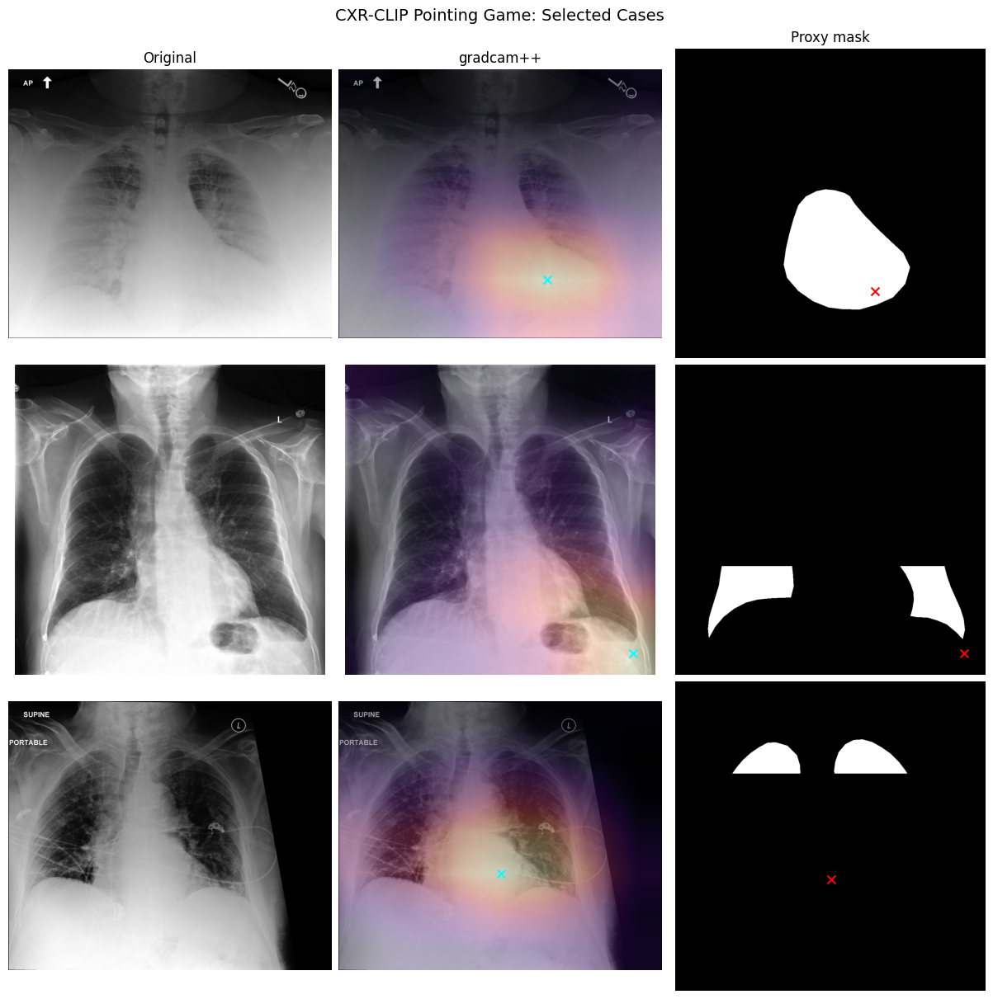

In [65]:
pg_out = evaluate_cxr_clip_pointing_game(
    cases_by_label=pointing_cases_all,
    test_df=results["test_df"],
    pipeline=pipeline,
    chexmask_lookup=chexmask_lookup,
    methods=("gradcam++",),
    use_margin=True,
)

print("Overall pointing score:", pg_out["overall_score"])
display(pg_out["results_df"])
display(pg_out["summary_method"])
display(pg_out["summary_pathology"])



plot_cxr_clip_pointing_game_figure(
    cases_by_label=pointing_cases_vis,
    test_df=results["test_df"],
    pipeline=pipeline,
    chexmask_lookup=chexmask_lookup,
    methods=("gradcam++",),
     save_path=str(SAVE_DIR / "cxr_clip_pointing_game_vis.png"),
)

## Semantic Alignment (SA)

In [66]:
EVAL_PATHOLOGIES = ["Cardiomegaly", "Pleural Effusion", "Pneumothorax"]
SAVE_DIR = OUTPUT_ROOT / "semantic_alignment"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

In [67]:
# ============================================================
# A. Build CXR-CLIP samples from saved embeddings
# ============================================================

test_emb = results["test_embedding_info"]
cxr_clip_samples = build_cxr_clip_samples(
    embeddings=test_emb["embeddings"],
    metadata=test_emb["metadata"],
    targets=pipeline["targets"],
)
print(f"CXR-CLIP samples: {len(cxr_clip_samples)}")
print(f"Embedding dim: {cxr_clip_samples[0]['image_emb'].shape}")

CXR-CLIP samples: 2000
Embedding dim: torch.Size([512])


In [68]:
# ============================================================
# B. Balanced TCAV comparison (BioViL-T single vs CXR-CLIP)
# ============================================================

comparison = build_balanced_tcav_comparison(
    biovil_samples=single_samples,
    cxr_clip_samples=cxr_clip_samples,
    pathologies=EVAL_PATHOLOGIES,
    biovil_embedding_key="image_emb",
    cxr_clip_embedding_key="image_emb",
    max_per_class=100,
    seed=42,
)


Cardiomegaly: 100 pos, 100 neg per model
  BioViL-T  emb=0.5750  sim=0.7100
  CXR-CLIP  emb=0.6100  sim=N/A

Pleural Effusion: 100 pos, 100 neg per model
  BioViL-T  emb=0.4800  sim=0.6650
  CXR-CLIP  emb=0.4550  sim=N/A

Pneumothorax: 100 pos, 100 neg per model
  BioViL-T  emb=0.7350  sim=0.4700
  CXR-CLIP  emb=0.5900  sim=N/A


In [69]:
comparison_df = tcav_comparison_to_dataframe(comparison)
display(comparison_df)


,Pathology,Model,N_pos,N_neg,Embedding_TCAV,Similarity_TCAV
0,Cardiomegaly,BioViL-T,100,100,0.575,0.710
1,Cardiomegaly,CXR-CLIP,100,100,0.610,NaN
2,Pleural Effusion,BioViL-T,100,100,0.480,0.665
3,Pleural Effusion,CXR-CLIP,100,100,0.455,NaN
4,Pneumothorax,BioViL-T,100,100,0.735,0.470
5,Pneumothorax,CXR-CLIP,100,100,0.590,NaN


Saved: outputs/run_20260429_012236/semantic_alignment/tcav_comparison_table.png


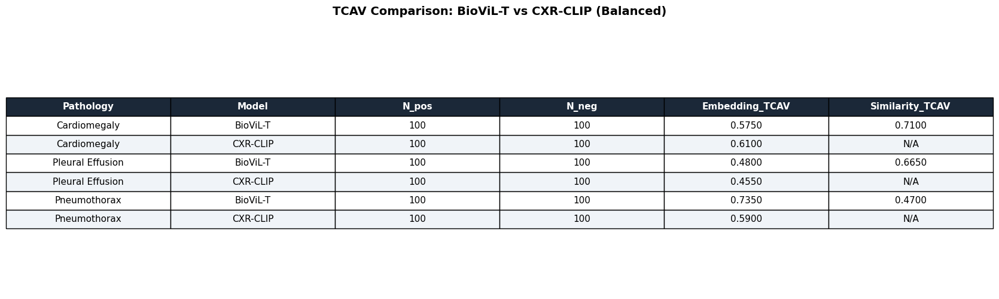

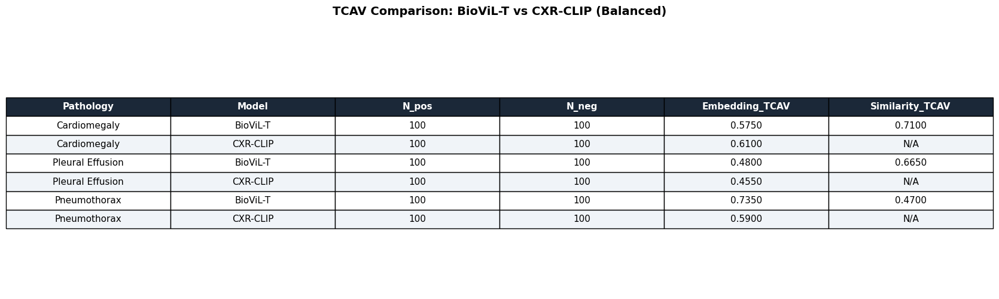

In [70]:
plot_tcav_table_figure(
    comparison_df,
    title="TCAV Comparison: BioViL-T vs CXR-CLIP (Balanced)",
    save_path=str(SAVE_DIR / "tcav_comparison_table.png"),
)

Saved: outputs/run_20260429_012236/semantic_alignment/tcav_embedding_comparison_bar.png


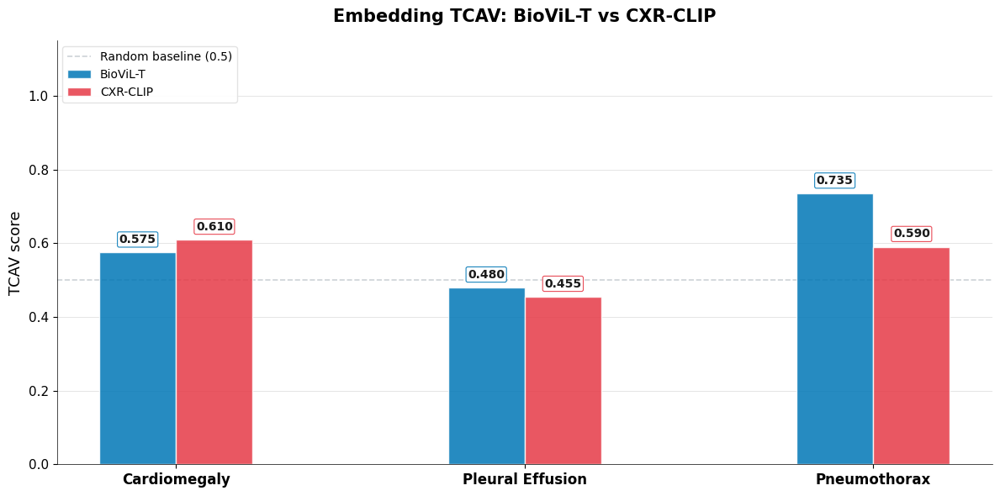

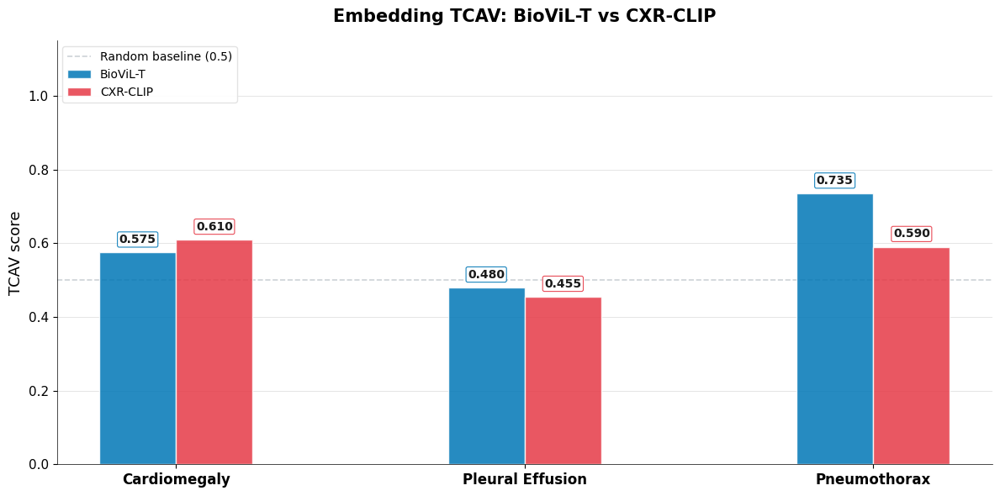

In [71]:
plot_tcav_comparison_bar(
    comparison_df,
    metric="Embedding_TCAV",
    title="Embedding TCAV: BioViL-T vs CXR-CLIP",
    save_path=str(SAVE_DIR / "tcav_embedding_comparison_bar.png"),
)

In [72]:
# ============================================================
# C. BioViL-T Temporal TCAV (standalone, not for comparison)
# ============================================================

temporal_concepts = build_tcav_concepts(
    samples=temporal_samples,
    pathologies=EVAL_PATHOLOGIES,
    embedding_key="temporal_global_emb",
    max_positive=100,
    max_negative=100,
    seed=42,
    model_name="BioViL-T Temporal",
    has_text_emb=True,
)



[BioViL-T Temporal] Building TCAV: Cardiomegaly
  Positives: 100, Negatives: 100
  Embedding TCAV: 0.4250
  Similarity TCAV: 0.7950

[BioViL-T Temporal] Building TCAV: Pleural Effusion
  Positives: 100, Negatives: 100
  Embedding TCAV: 0.5950
  Similarity TCAV: 0.7550

[BioViL-T Temporal] Building TCAV: Pneumothorax
  Positives: 100, Negatives: 100
  Embedding TCAV: 0.7000
  Similarity TCAV: 0.4750


In [73]:
temporal_tcav_df = tcav_single_model_to_dataframe(
    temporal_concepts, model_name="BioViL-T (Temporal)"
)
display(temporal_tcav_df)

,Pathology,Model,N_pos,N_neg,Embedding_TCAV,Similarity_TCAV
0,Cardiomegaly,BioViL-T (Temporal),100,100,0.425,0.795
1,Pleural Effusion,BioViL-T (Temporal),100,100,0.595,0.755
2,Pneumothorax,BioViL-T (Temporal),100,100,0.700,0.475


Saved: outputs/run_20260429_012236/semantic_alignment/temporal_tcav_table.png


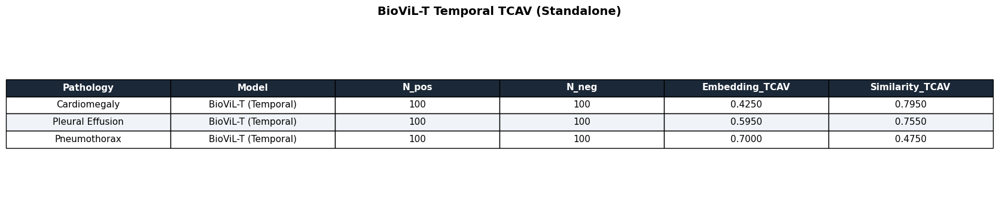

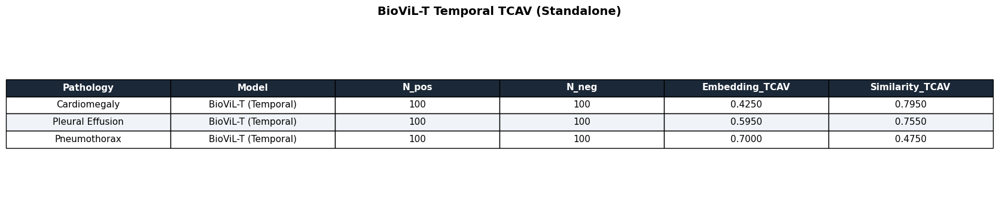

In [74]:
plot_tcav_table_figure(
    temporal_tcav_df,
    title="BioViL-T Temporal TCAV (Standalone)",
    save_path=str(SAVE_DIR / "temporal_tcav_table.png"),
)

/tmp/ipykernel_1644890/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


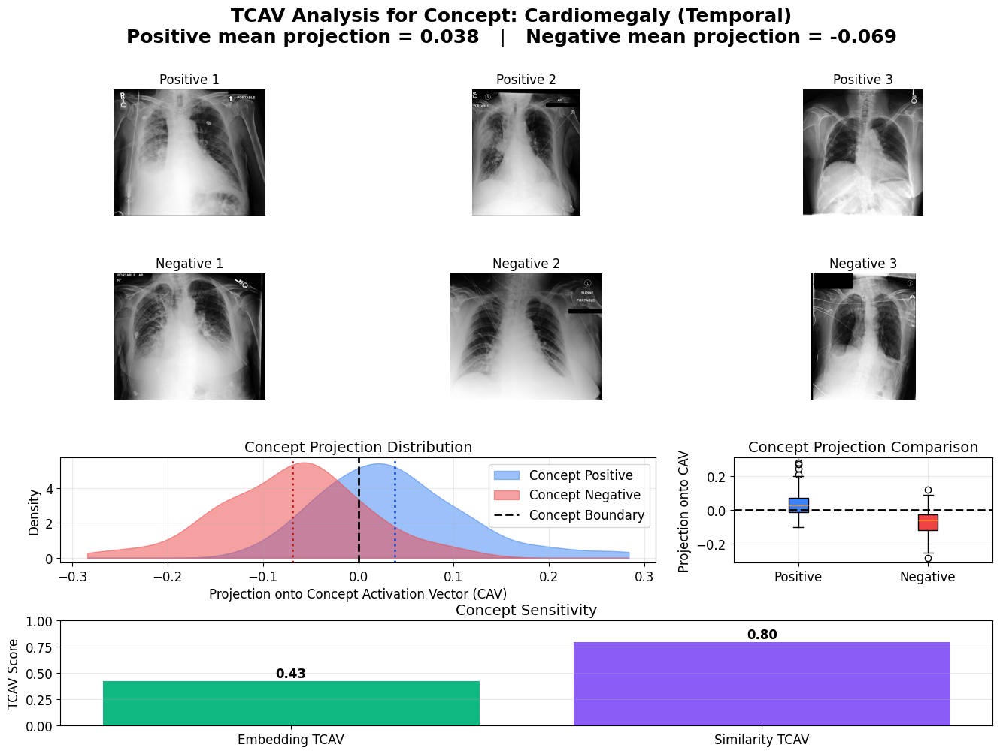

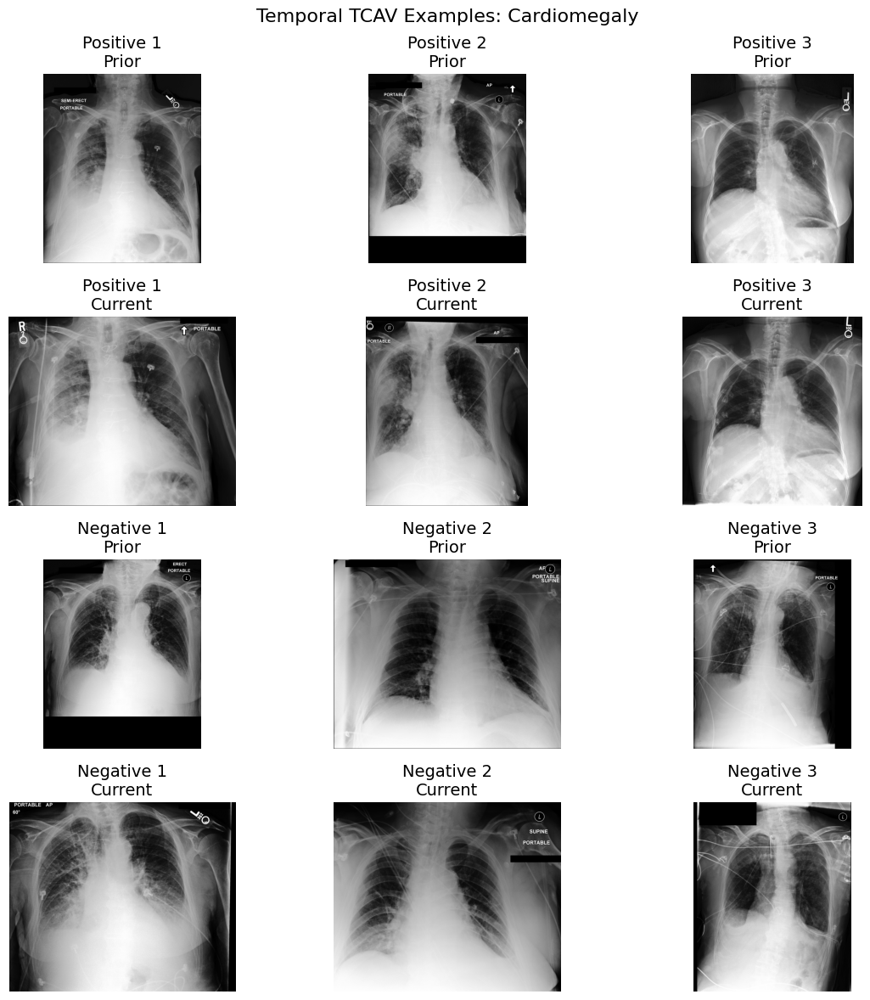

/tmp/ipykernel_1644890/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


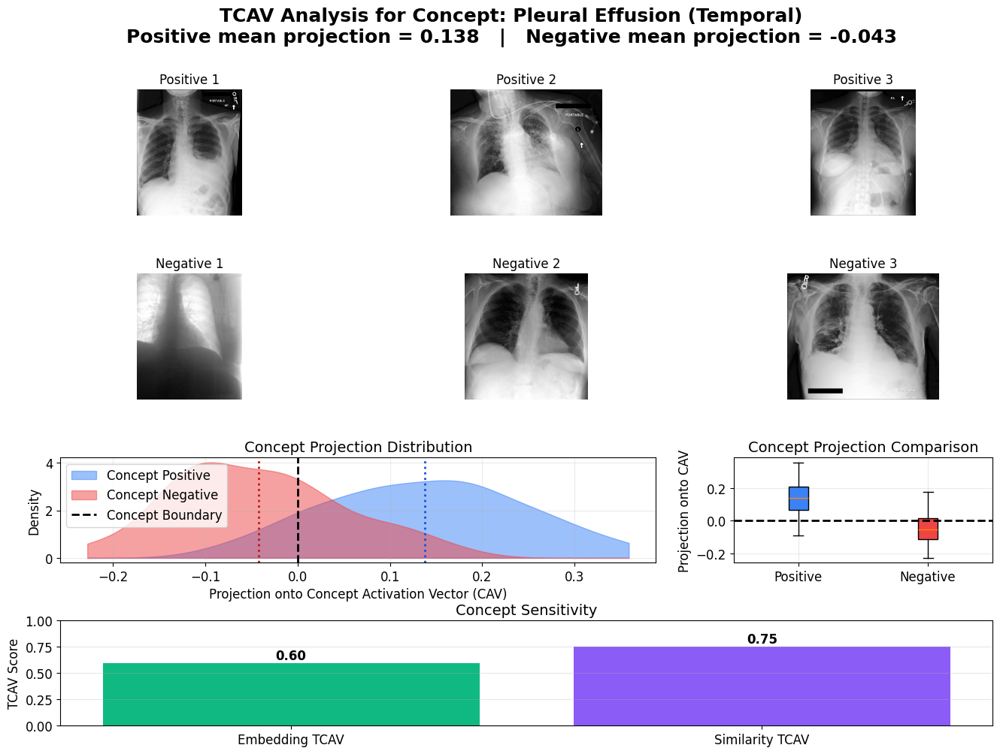

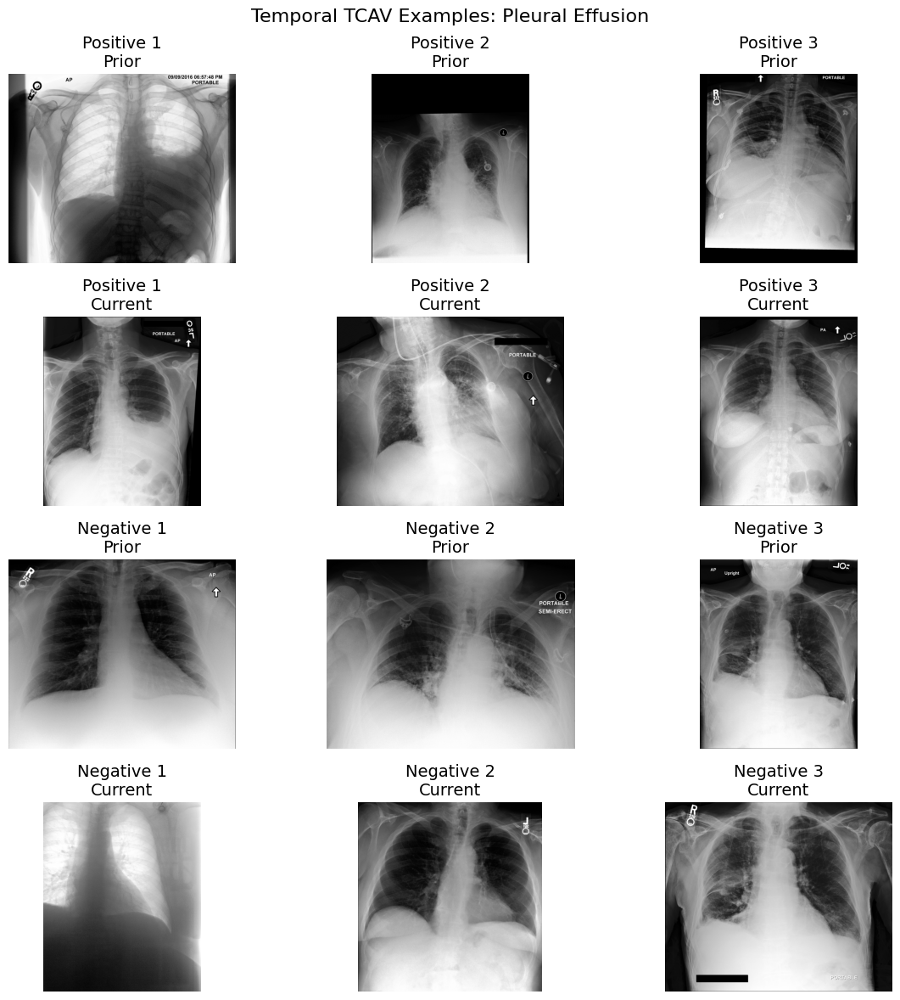

/tmp/ipykernel_1644890/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


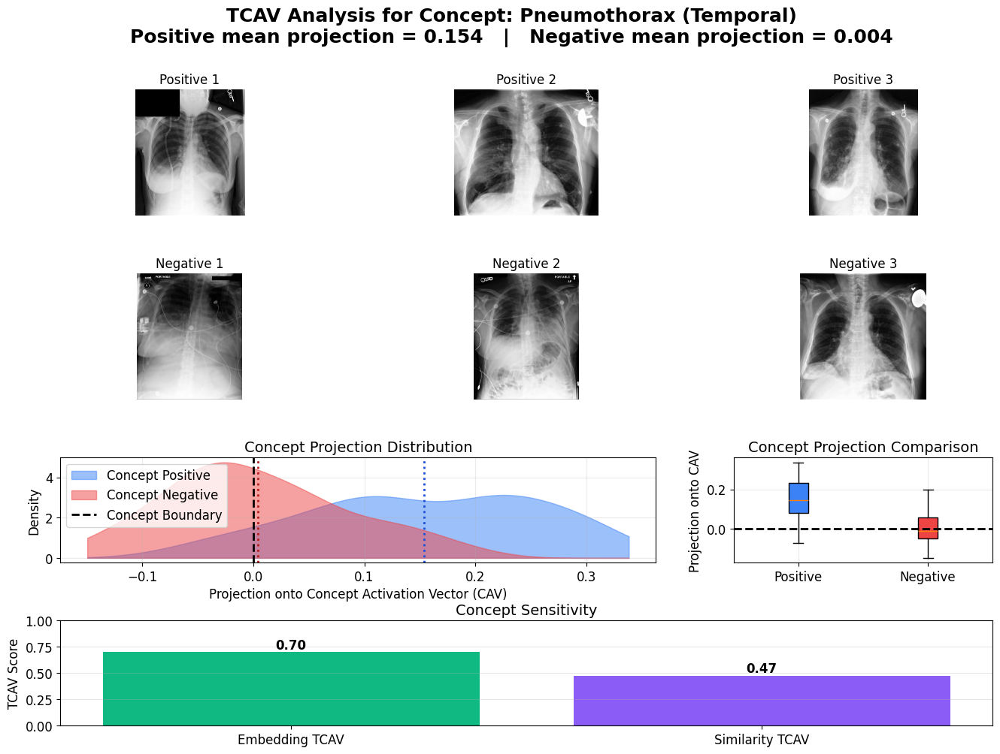

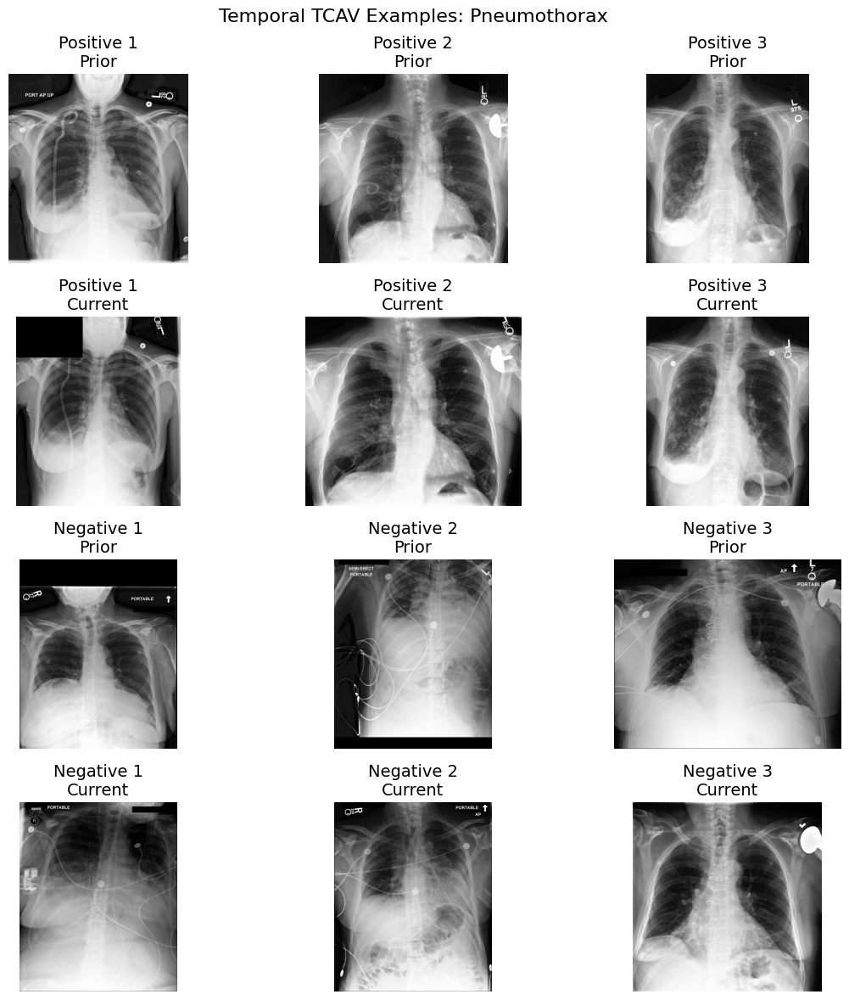

In [75]:
for pathology, data in temporal_concepts.items():
    # Patch metadata so plot_tcav_summary can find image_path
    for s in data["positives"] + data["negatives"]:
        if "image_path" not in s["metadata"] and "current_image_path" in s["metadata"]:
            s["metadata"]["image_path"] = s["metadata"]["current_image_path"]

    plot_tcav_summary(
        concept_name=f"{pathology} (Temporal)",
        positives=data["positives"],
        negatives=data["negatives"],
        cav=data["cav"],
        tcav_score=data["tcav_emb"],
        similarity_tcav_score=data["tcav_sim"],
        embedding_key="temporal_global_emb",
    )
    plot_temporal_tcav_examples(
        concept_name=pathology,
        positives=data["positives"],
        negatives=data["negatives"],
    )

Saved: outputs/run_20260429_012236/semantic_alignment/tcav_all_methods_bar.png


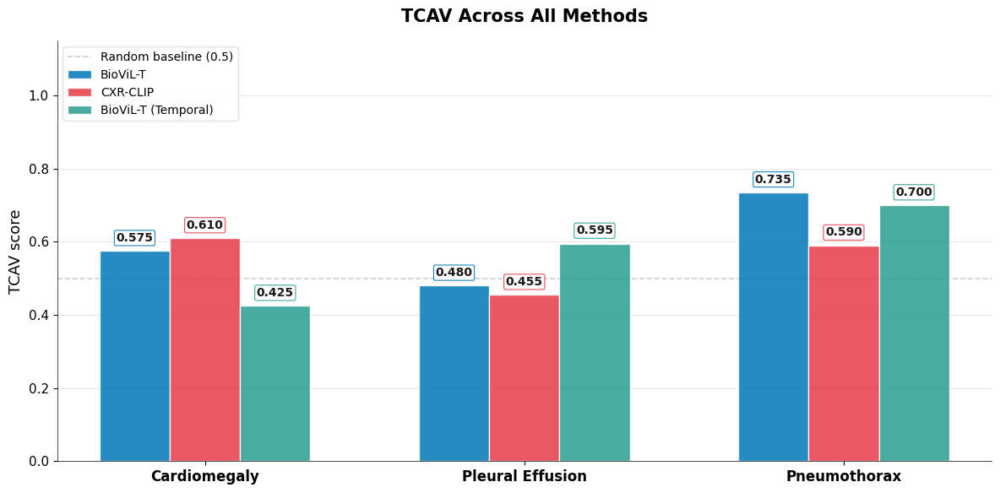

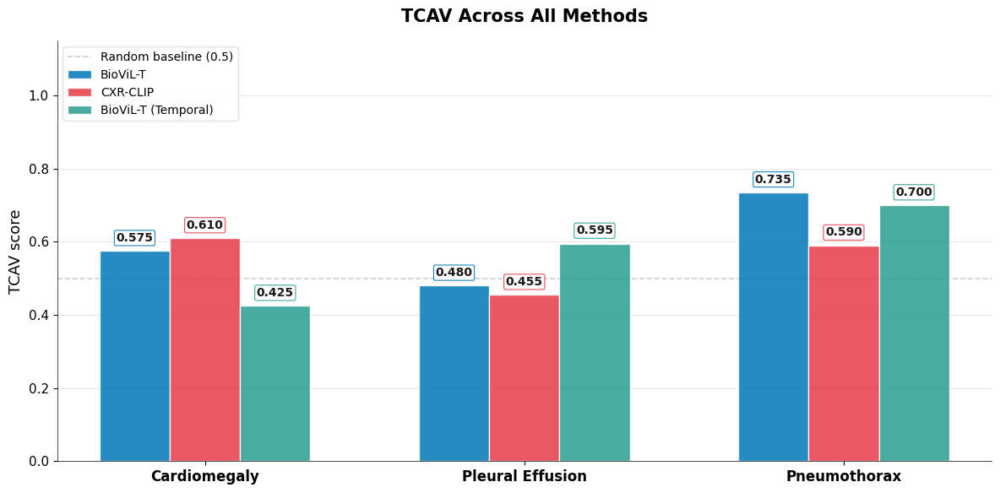

In [76]:
# Combined bar chart: all three (comparison + temporal standalone)
all_tcav_df = pd.concat([comparison_df, temporal_tcav_df], ignore_index=True)

plot_tcav_comparison_bar(
    all_tcav_df,
    metric="Embedding_TCAV",
    title="TCAV Across All Methods",
    save_path=str(SAVE_DIR / "tcav_all_methods_bar.png"),
)

In [77]:
# ============================================================
# D. Semantic Alignment: Heatmap Quality Comparison
# ============================================================

# BioViL-T cross-modal alignment metrics (already computed)
biovil_alignment_df = pd.DataFrame(evaluate_cross_modal_alignment(
    single_chunk_paths,
    token_queries=("effusion", "cardiomegaly", "pneumothorax"),
    max_samples=200,
))
print("BioViL-T alignment metrics:")
display(biovil_alignment_df.groupby("token_query")[["entropy", "peak_score", "sparsity"]].mean())

BioViL-T alignment metrics:


,entropy,peak_score,sparsity
token_query,,,
cardiomegaly,5.158808,2.387170,0.135954
effusion,5.175327,2.131325,0.194067
pneumothorax,5.182648,2.014387,0.206575


In [78]:
cxr_clip_alignment_df = evaluate_cxr_clip_heatmap_quality(
    cxr_clip_samples=cxr_clip_samples,
    test_df=results["test_df"],
    pipeline=pipeline,
    pathologies=EVAL_PATHOLOGIES,
    max_samples=70,
    seed=42,
)

print("\nCXR-CLIP alignment metrics:")
display(cxr_clip_alignment_df.groupby("pathology")[["entropy", "peak_score", "sparsity"]].mean())


CXR-CLIP alignment metrics:


,entropy,peak_score,sparsity
pathology,,,
Cardiomegaly,10.653702,2.435211,0.158000
Pleural Effusion,10.689174,2.077938,0.245634
Pneumothorax,10.693663,2.079587,0.236180


Saved: outputs/run_20260429_012236/semantic_alignment/heatmap_quality_comparison.png


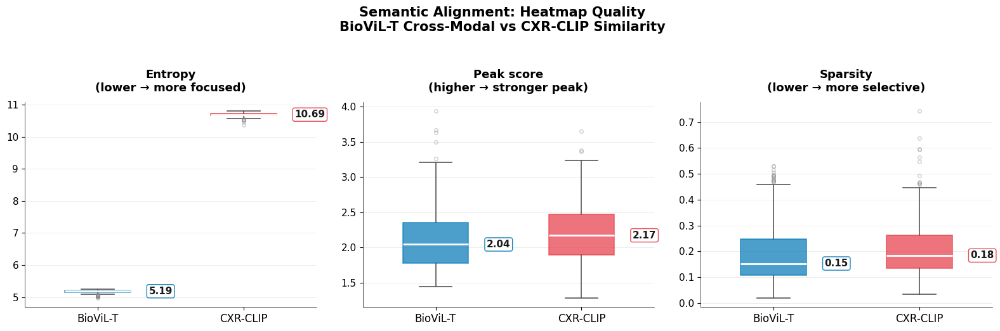

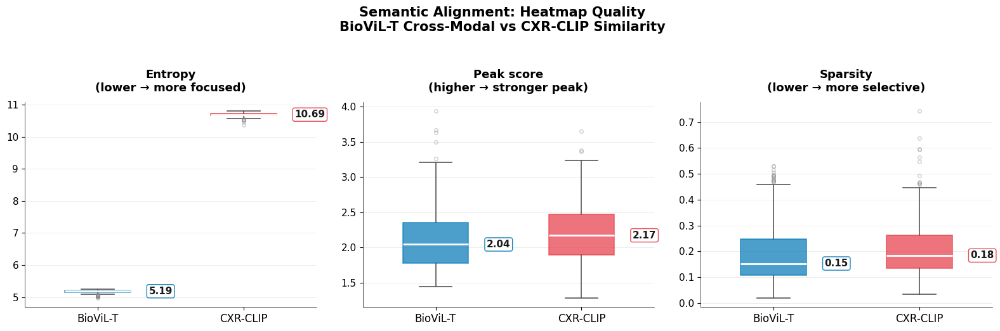

In [79]:
# Comparison boxplots
plot_semantic_alignment_heatmap_comparison(
    biovil_metrics_df=biovil_alignment_df,
    cxr_clip_metrics_df=cxr_clip_alignment_df,
    title="Semantic Alignment: Heatmap Quality\nBioViL-T Cross-Modal vs CXR-CLIP Similarity",
    save_path=str(SAVE_DIR / "heatmap_quality_comparison.png"),
)

/tmp/ipykernel_1644890/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


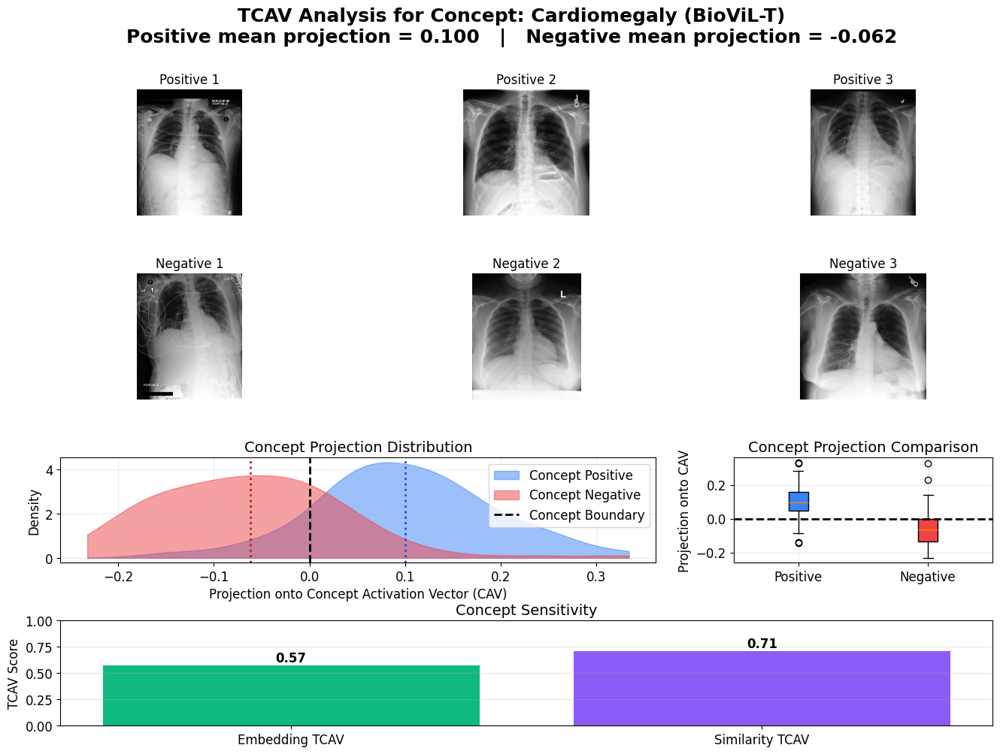

/tmp/ipykernel_1644890/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


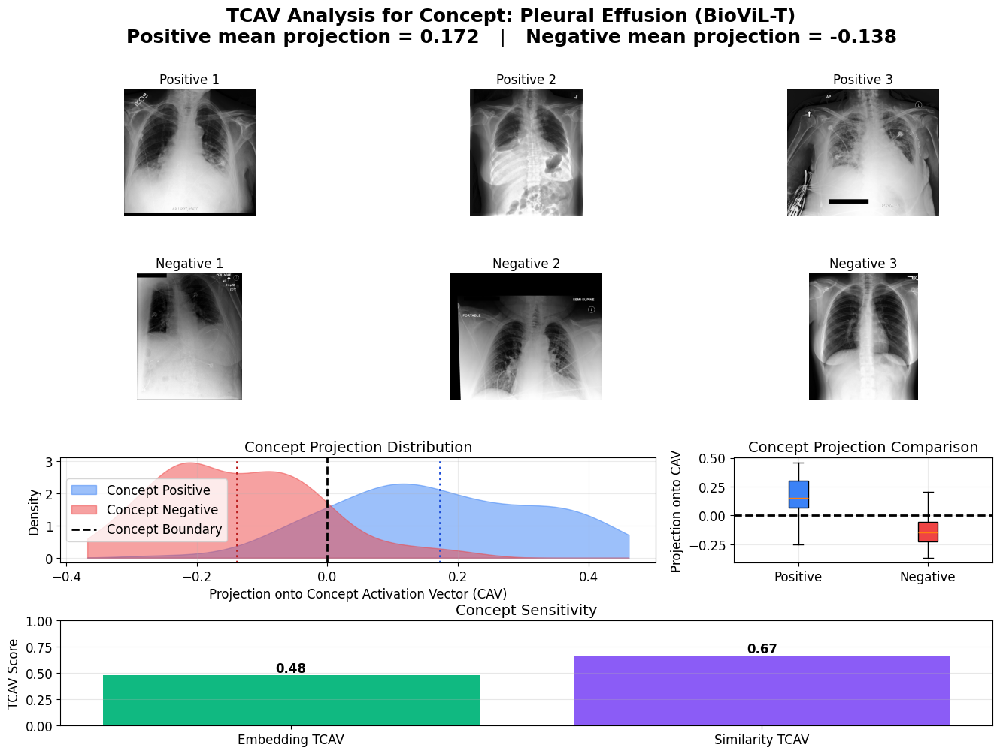

/tmp/ipykernel_1644890/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


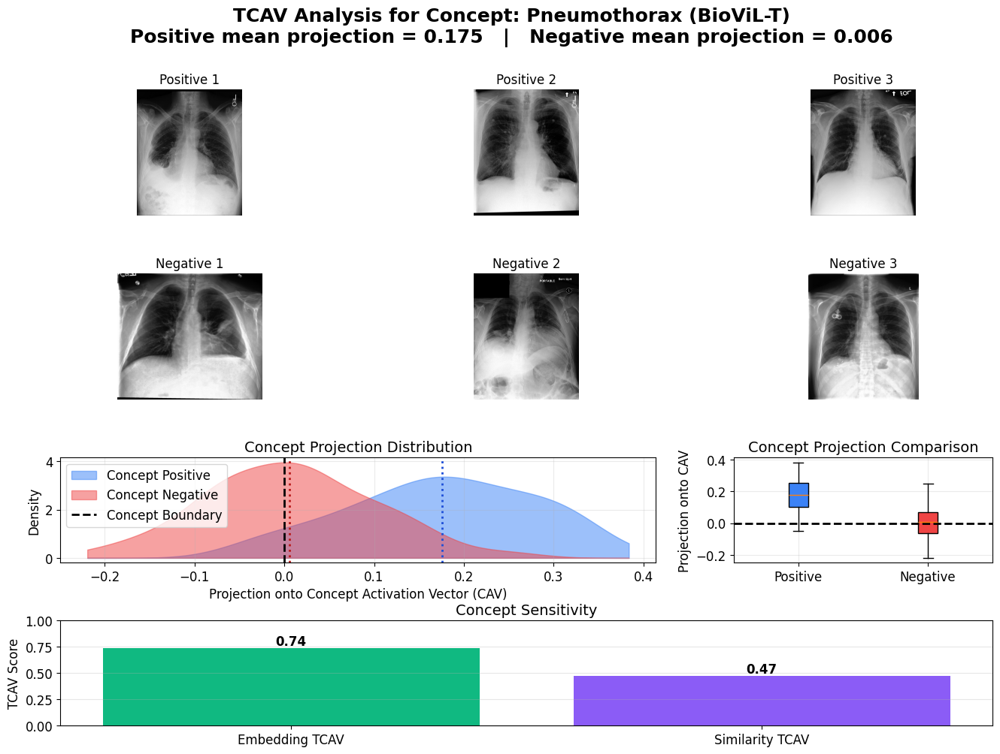

In [80]:
# ============================================================
# E. Per-model TCAV detail plots (BioViL-T single)
# ============================================================
for pathology, data in comparison.items():
    plot_tcav_summary(
        concept_name=f"{pathology} (BioViL-T)",
        positives=data["biovil_t"]["positives"],
        negatives=data["biovil_t"]["negatives"],
        cav=data["biovil_t"]["cav"],
        tcav_score=data["biovil_t"]["tcav_emb"],
        similarity_tcav_score=data["biovil_t"]["tcav_sim"],
        embedding_key="image_emb",
    )

/tmp/ipykernel_1644890/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


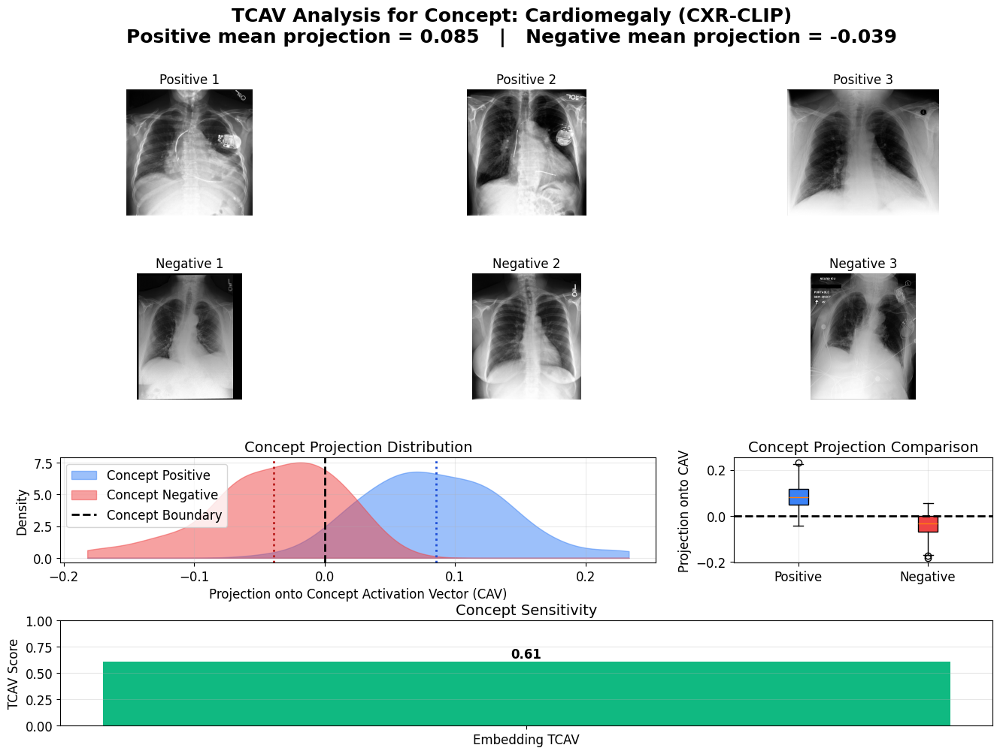

/tmp/ipykernel_1644890/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


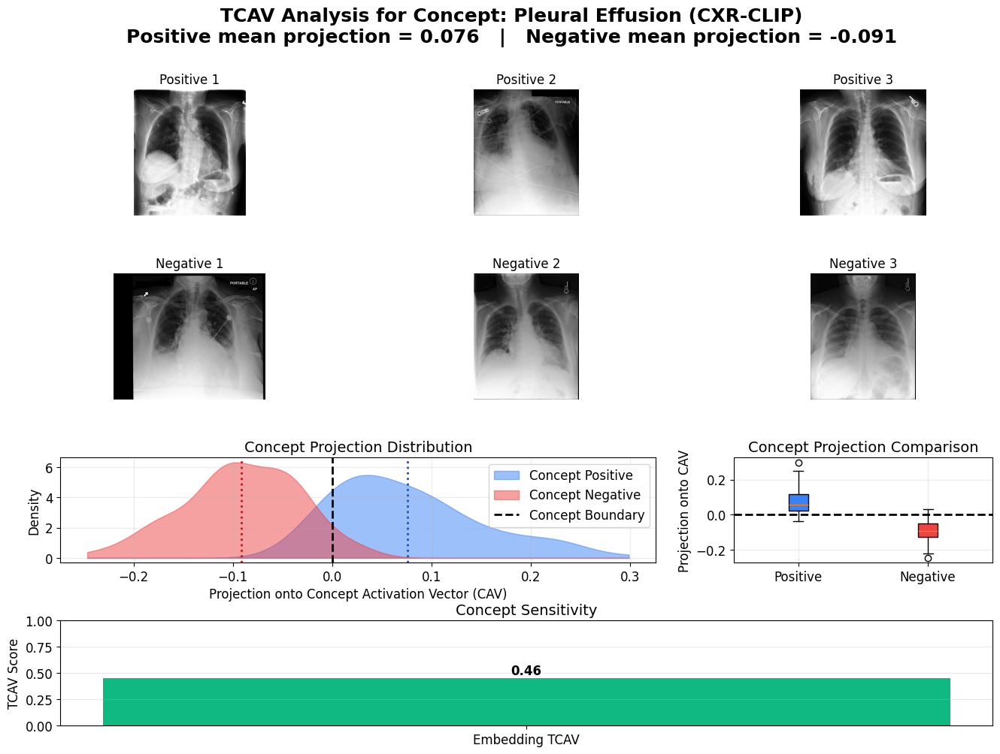

/tmp/ipykernel_1644890/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


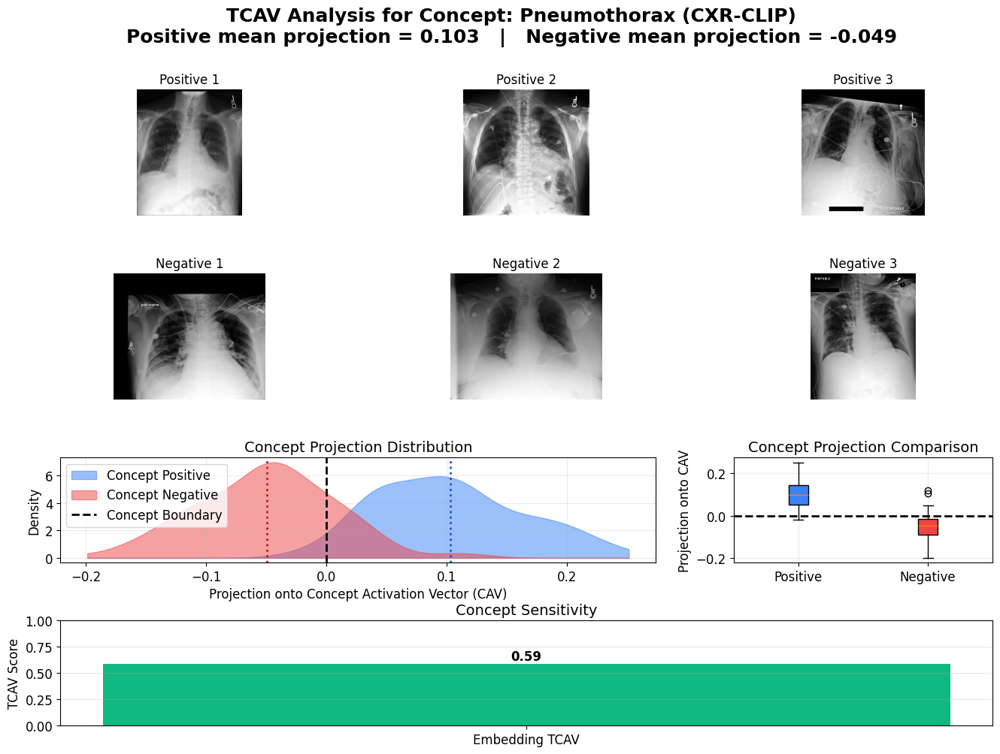

In [81]:
for pathology, data in comparison.items():
    plot_tcav_summary(
        concept_name=f"{pathology} (CXR-CLIP)",
        positives=data["cxr_clip"]["positives"],
        negatives=data["cxr_clip"]["negatives"],
        cav=data["cxr_clip"]["cav"],
        tcav_score=data["cxr_clip"]["tcav_emb"],
        similarity_tcav_score=data["cxr_clip"]["tcav_sim"],
        embedding_key="image_emb",
    )


Query 1/3
Subject ID : 12410764
Study ID   : 55151770
Image      : 0827542e-72e3d380-2c026f3a-eb8f37b1-560ff713.jpg


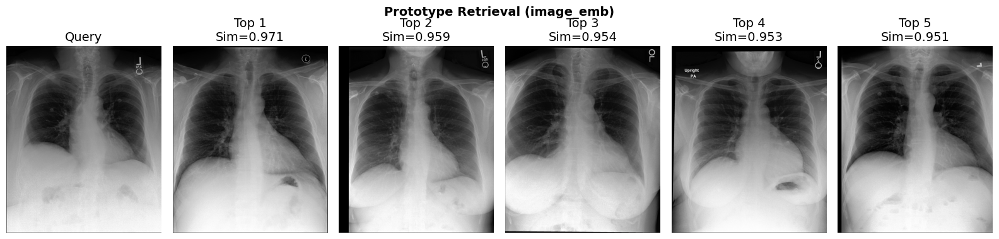


Query 2/3
Subject ID : 10541043
Study ID   : 50169121
Image      : 7fe8144e-7ca26330-27b57e6d-416770e8-30178d1b.jpg


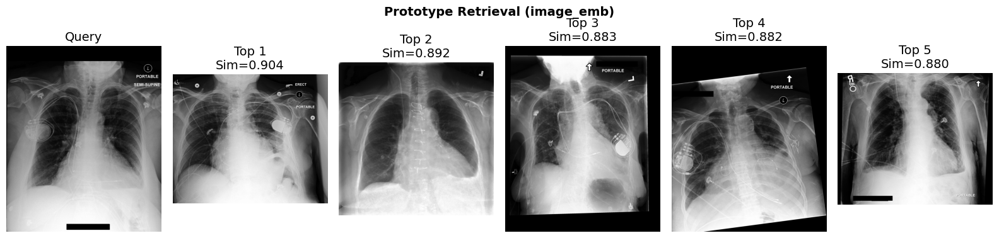


Query 3/3
Subject ID : 16199548
Study ID   : 51470102
Image      : b646a009-e30b47a7-b50de104-c7325b3a-2ce490a3.jpg


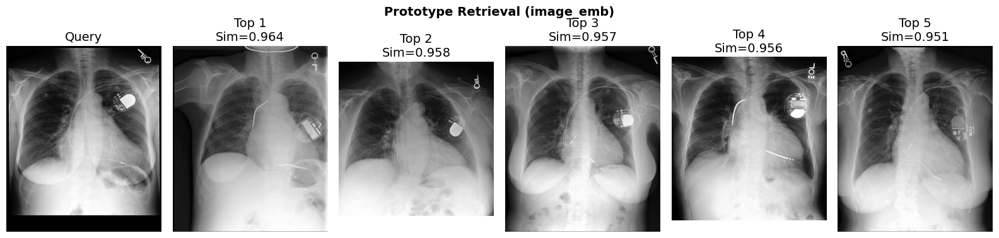

In [82]:
# BioViL-T prototype retrieval
biovil_proto_results = plot_random_prototype_retrieval(
    samples=single_samples,
    embedding_key="image_emb",
    image_key="image_path",
    k=5,
    num_queries=3,
    seed=42,
)

/tmp/ipykernel_1644890/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


Saved: biovil_t_cardiomegaly_tcav.png


/tmp/ipykernel_1644890/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


Saved: cxr_clip_cardiomegaly_tcav.png


/tmp/ipykernel_1644890/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


...

Saved: cxr_clip_pleural_effusion_tcav.png


/tmp/ipykernel_1644890/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


Saved: biovil_t_pneumothorax_tcav.png


/tmp/ipykernel_1644890/2996948840.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


Saved: cxr_clip_pneumothorax_tcav.png


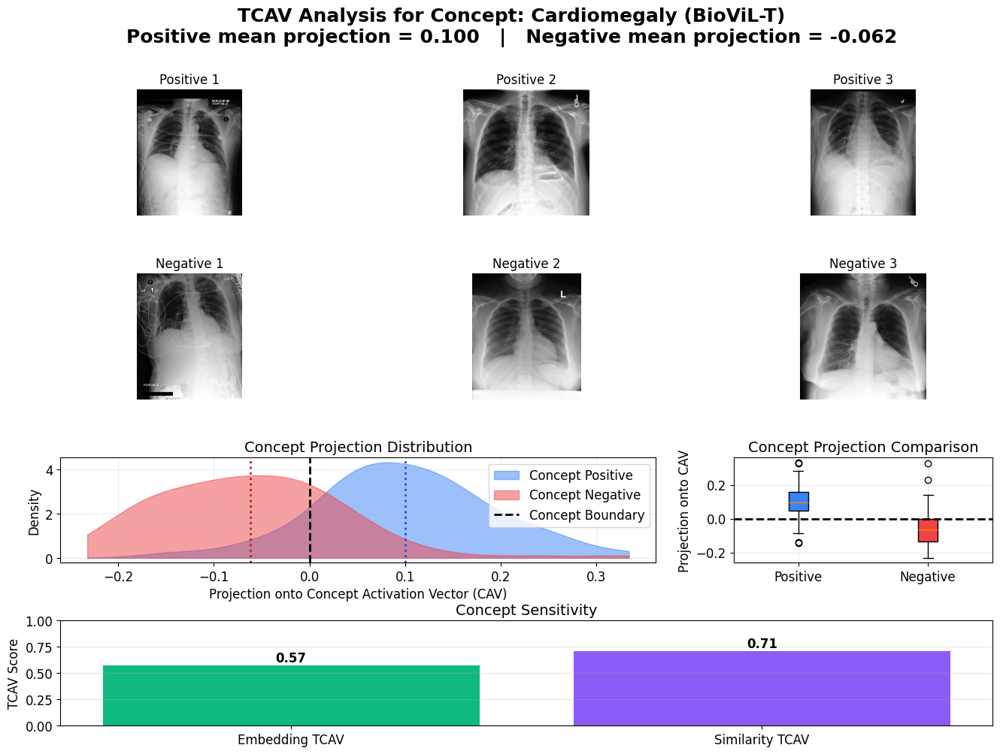

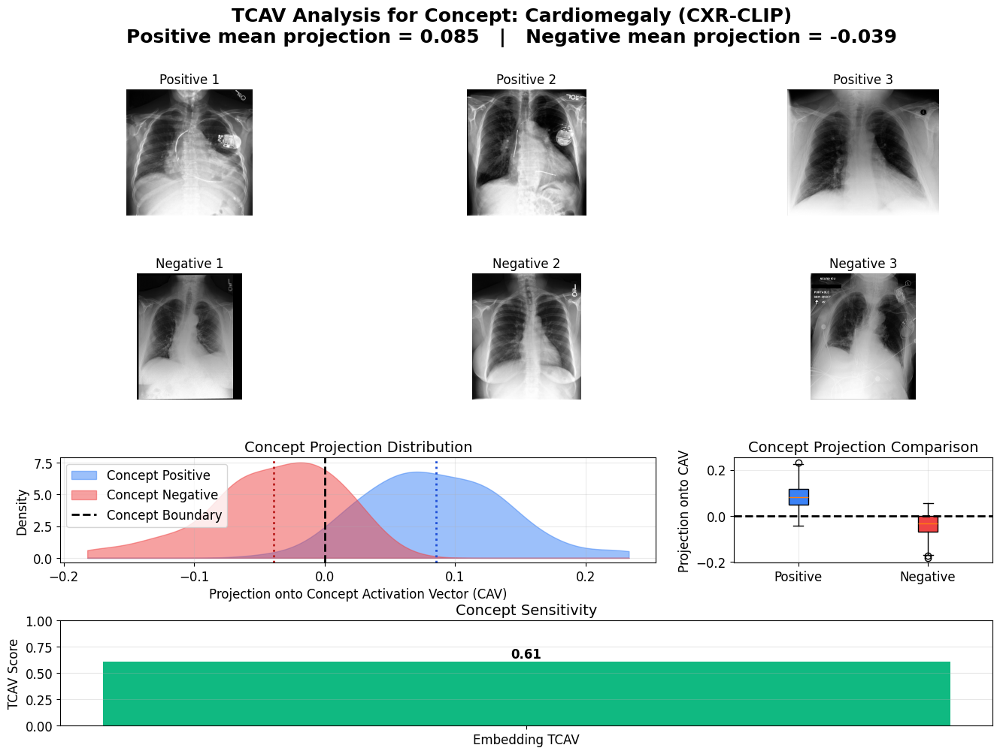

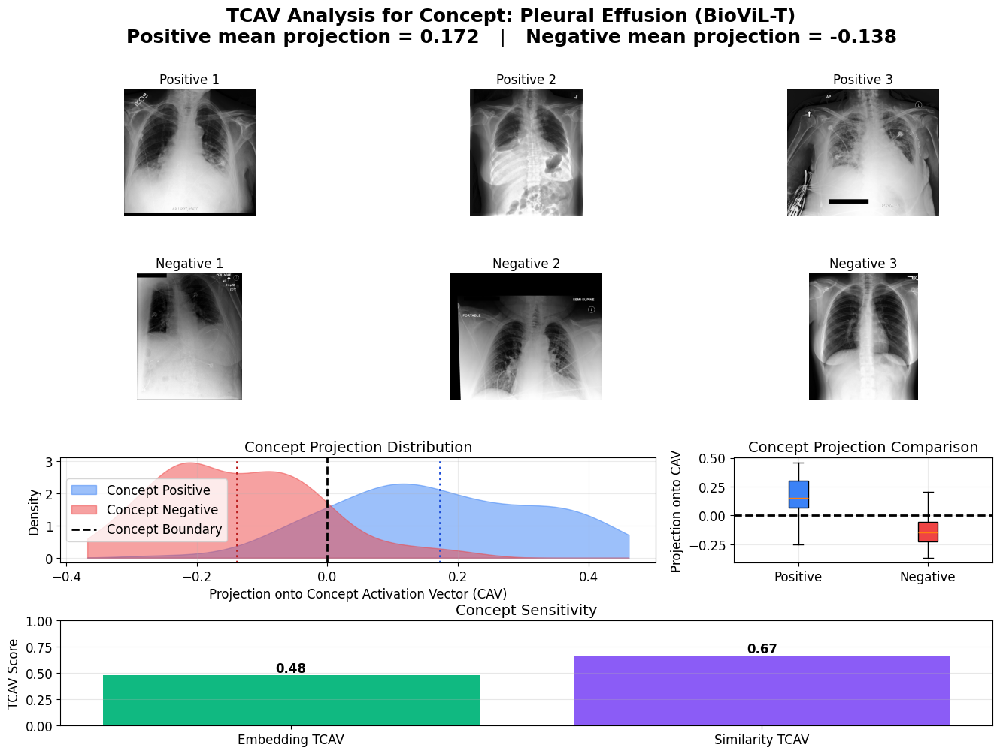

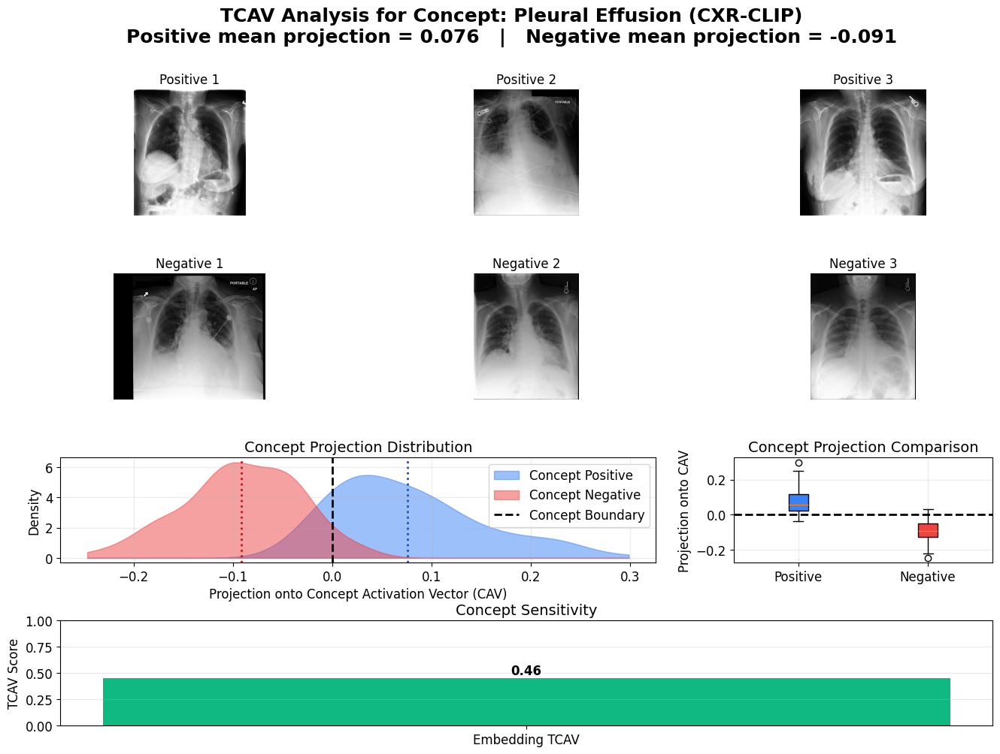

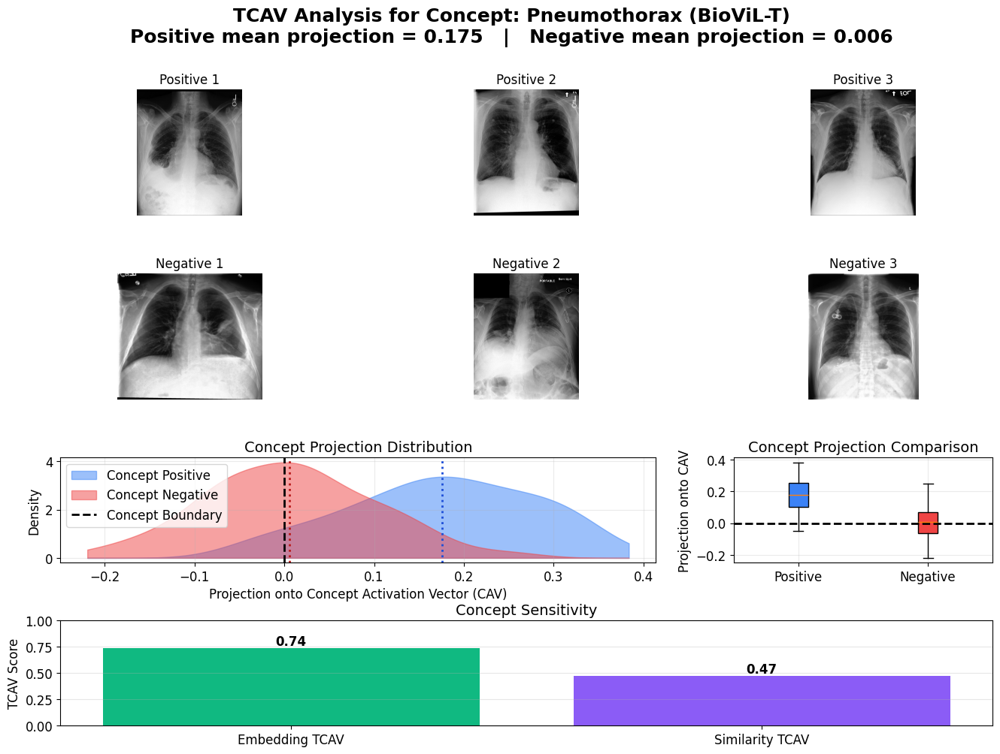

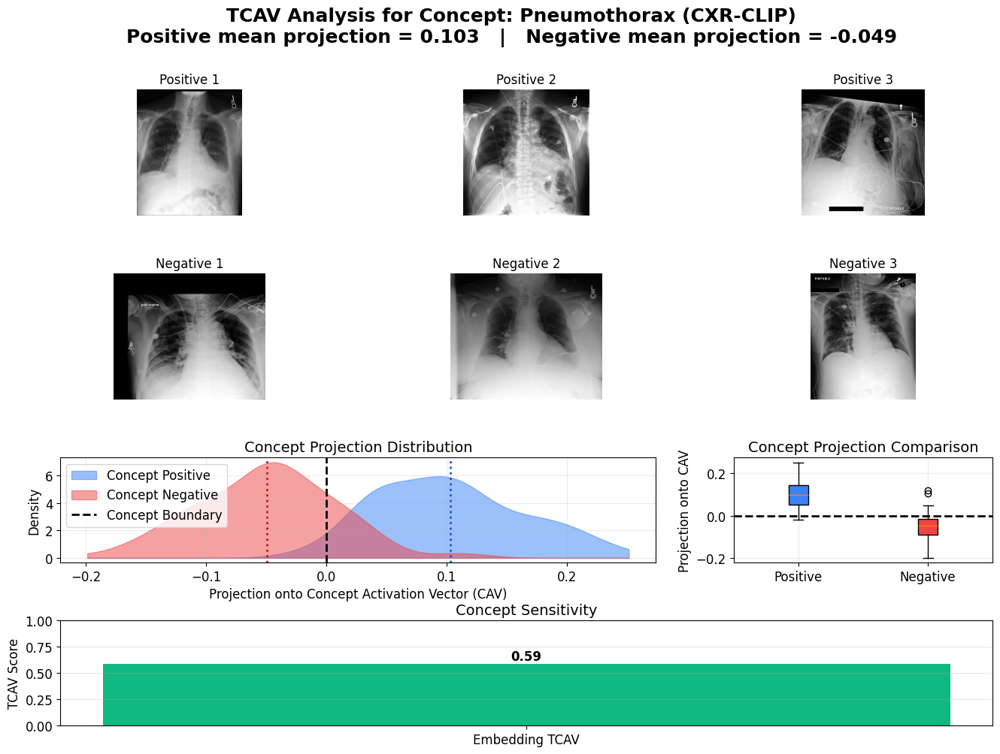

In [83]:
SAVE_DIR = Path("figures/semantic_alignment/tcav")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

original_show = plt.show

for pathology, data in comparison.items():
    safe_name = pathology.lower().replace(" ", "_")

    # BioViL-T
    fig_holder = {}
    def capture_show(*a, **kw):
        fig_holder["fig"] = plt.gcf()
    plt.show = capture_show

    plot_tcav_summary(
        concept_name=f"{pathology} (BioViL-T)",
        positives=data["biovil_t"]["positives"],
        negatives=data["biovil_t"]["negatives"],
        cav=data["biovil_t"]["cav"],
        tcav_score=data["biovil_t"]["tcav_emb"],
        similarity_tcav_score=data["biovil_t"]["tcav_sim"],
        embedding_key="image_emb",
    )
    plt.show = original_show
    if "fig" in fig_holder:
        fig_holder["fig"].savefig(
            SAVE_DIR / f"biovil_t_{safe_name}_tcav.png",
            dpi=250, bbox_inches="tight", facecolor="white",
        )
        print(f"Saved: biovil_t_{safe_name}_tcav.png")
        fig_holder["fig"].show()

    # CXR-CLIP
    fig_holder = {}
    plt.show = capture_show

    plot_tcav_summary(
        concept_name=f"{pathology} (CXR-CLIP)",
        positives=data["cxr_clip"]["positives"],
        negatives=data["cxr_clip"]["negatives"],
        cav=data["cxr_clip"]["cav"],
        tcav_score=data["cxr_clip"]["tcav_emb"],
        similarity_tcav_score=data["cxr_clip"]["tcav_sim"],
        embedding_key="image_emb",
    )
    plt.show = original_show
    if "fig" in fig_holder:
        fig_holder["fig"].savefig(
            SAVE_DIR / f"cxr_clip_{safe_name}_tcav.png",
            dpi=250, bbox_inches="tight", facecolor="white",
        )
        print(f"Saved: cxr_clip_{safe_name}_tcav.png")
        fig_holder["fig"].show()


Query 1/3
Subject ID : 12410764
Study ID   : 55151770


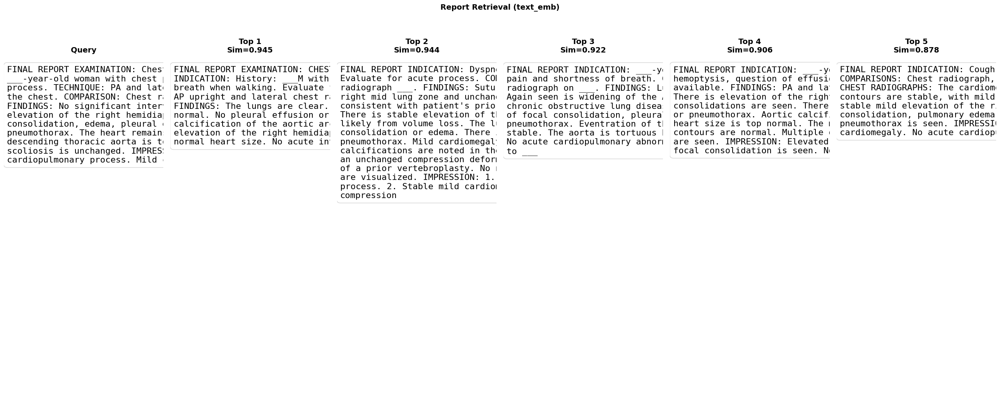


Query 2/3
Subject ID : 10541043
Study ID   : 50169121


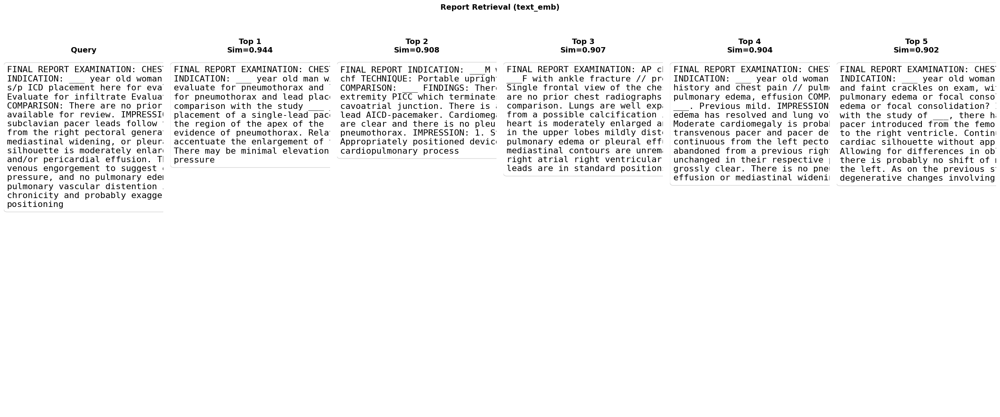


Query 3/3
Subject ID : 16199548
Study ID   : 51470102


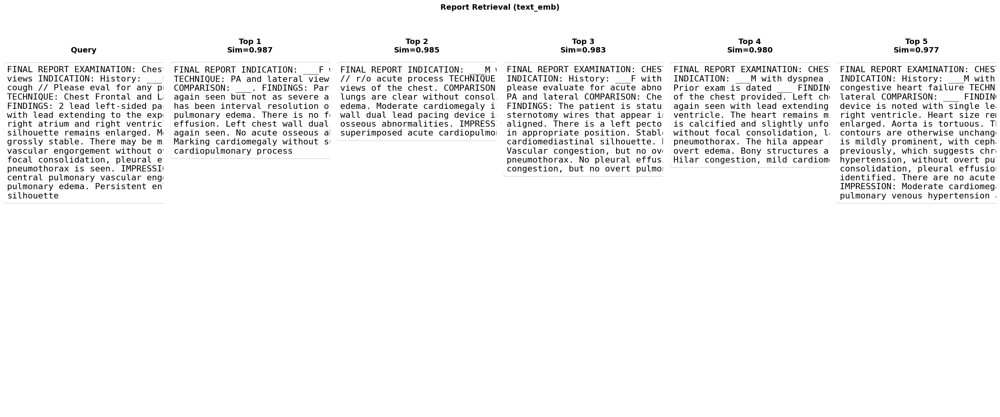

In [84]:
# BioViL-T report retrieval
biovil_report_results = plot_random_report_retrieval(
    samples=single_samples,
    embedding_key="text_emb",
    text_key="report_text",
    k=5,
    num_queries=3,
    seed=42,
)

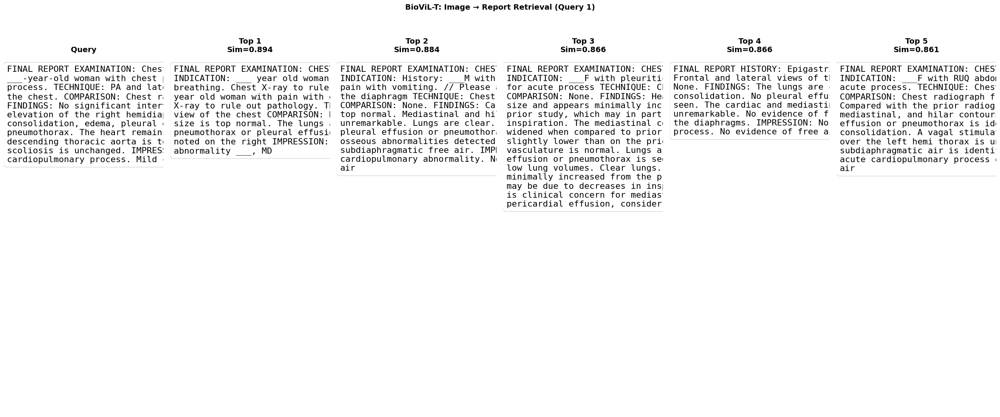

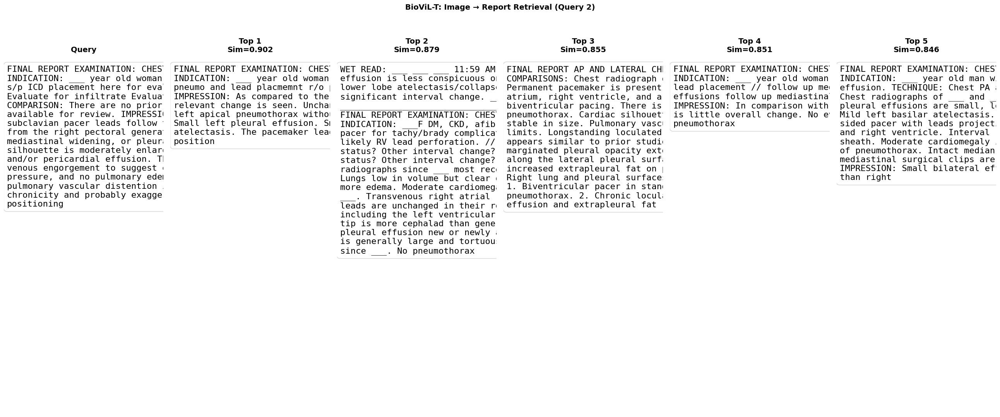

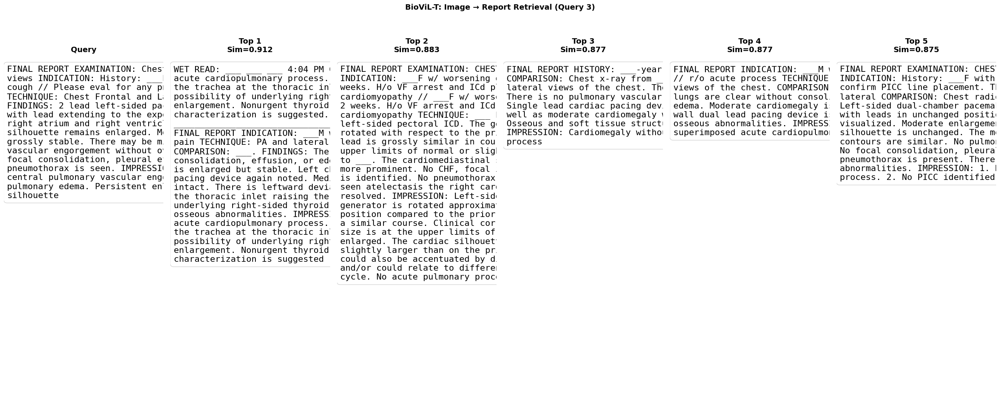

In [85]:
# BioViL-T cross-modal retrieval (image -> report)
for i, s in enumerate(random.Random(42).sample(single_samples, 3)):
    retrieved = retrieve_reports_from_image(
        query_image_embedding=s["image_emb"],
        samples=single_samples,
        k=5,
    )
    plot_report_retrieval(
        query_sample=s,
        retrieved=retrieved,
        title=f"BioViL-T: Image → Report Retrieval (Query {i+1})",
    )


Query 1/3
Subject ID : tensor(19017194)
Study ID   : tensor(56443889)
Image      : cd0a7ae0-bb2e258c-73373501-6147bfd0-adac3175.jpg


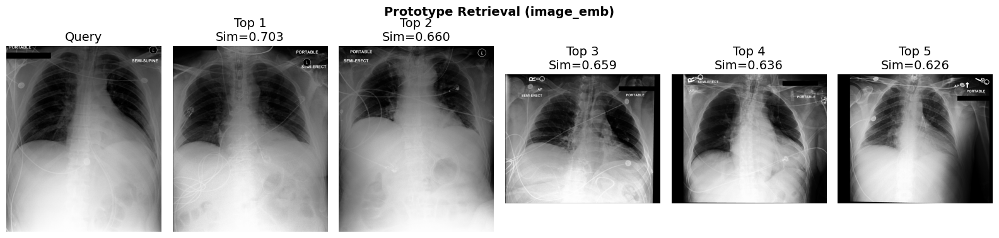


Query 2/3
Subject ID : tensor(11508827)
Study ID   : tensor(51023807)
Image      : a1c7c4cd-b3d054b9-234f0692-64df0bd8-3f7c88cf.jpg


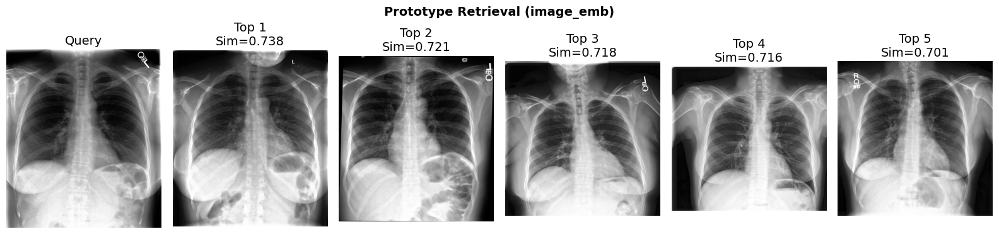


Query 3/3
Subject ID : tensor(10327971)
Study ID   : tensor(59454377)
Image      : 28ee45c3-73e25bf2-71f94c95-df9235c5-0f68f498.jpg


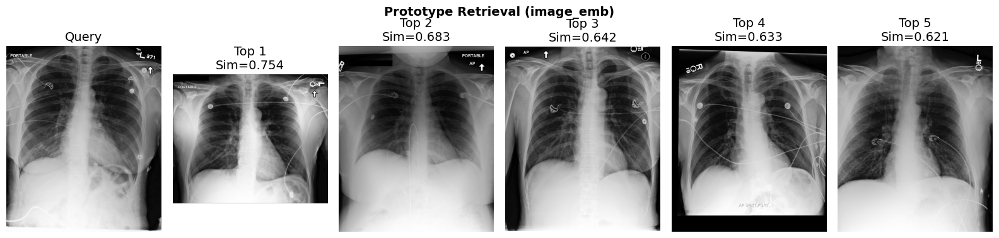

In [86]:
# CXR-CLIP prototype retrieval
cxr_clip_proto_results = plot_random_prototype_retrieval(
    samples=cxr_clip_samples,
    embedding_key="image_emb",
    image_key="image_path",
    k=5,
    num_queries=3,
    seed=42,
)

Saved: figures/semantic_alignment/tcav/semantic_alignment_full_summary.png


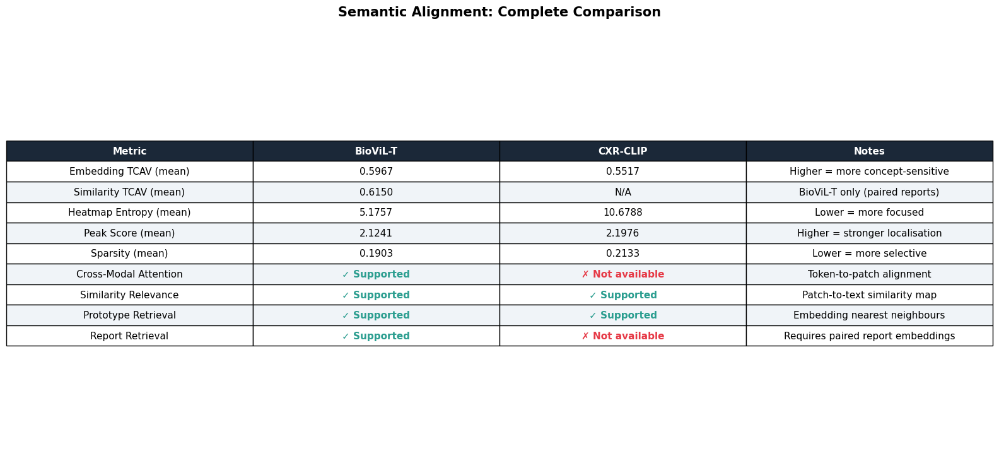

,Metric,BioViL-T,CXR-CLIP,Notes
0,Embedding TCAV (mean),0.5967,0.5517,Higher = more concept-sensitive
1,Similarity TCAV (mean),0.6150,N/A,BioViL-T only (paired reports)
2,Heatmap Entropy (mean),5.1757,10.6788,Lower = more focused
3,Peak Score (mean),2.1241,2.1976,Higher = stronger localisation
4,Sparsity (mean),0.1903,0.2133,Lower = more selective
5,Cross-Modal Attention,✓ Supported,✗ Not available,Token-to-patch alignment
6,Similarity Relevance,✓ Supported,✓ Supported,Patch-to-text similarity map
7,Prototype Retrieval,✓ Supported,✓ Supported,Embedding nearest neighbours
8,Report Retrieval,✓ Supported,✗ Not available,Requires paired report embeddings


In [87]:
# Build and display
sa_summary = build_semantic_alignment_summary(
    biovil_alignment_df=biovil_alignment_df,
    cxr_clip_alignment_df=cxr_clip_alignment_df,
    comparison_df=comparison_df,
    save_path=str(SAVE_DIR / "semantic_alignment_full_summary.png"),
)
display(sa_summary)


Sample         : 1/3
Subject ID     : 19032584
Current Study  : 53860348
Prior Study    : 58293729
Current Image  : 953d4e68-3f03b779-ac390bc2-018b877d-f91af428.jpg
Ground Truth   : Pleural Effusion, Support Devices, Cardiomegaly, Atelectasis
Impression     : As compared to the previous radiograph, the nasogastric tube and the left subclavian vein catheter where removed. The left PICC line remains in unchanged position. Unchanged mild cardiomegaly. Unchanged small to moderate bilateral pleural effusions, with retrocardiac atelectasis on the left. No pneu...
Map Type       : token ↔ patch alignment ('effusions')


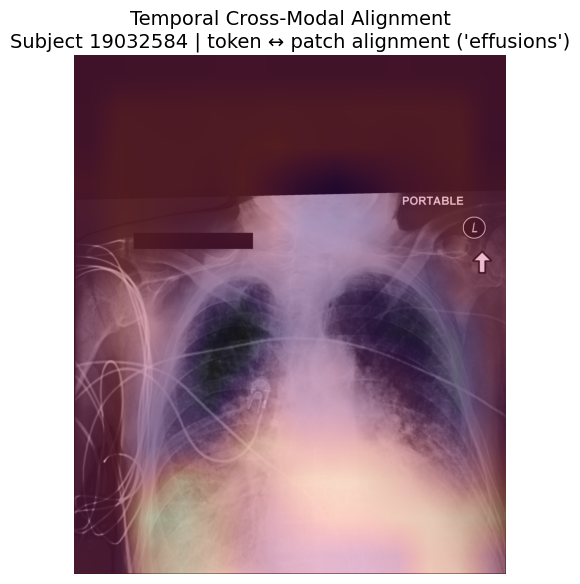


Sample         : 3/3
Subject ID     : 10550621
Current Study  : 52635361
Prior Study    : 53618152
Current Image  : 4b5edb6e-6cfb8b53-799370d0-ad10a07f-1c0988d8.jpg
Ground Truth   : Pleural Effusion, Consolidation, Cardiomegaly
Impression     : Stable elevation of the right hemidiaphragm with tiny right pleural effusion and right lower lobe consolidation, minimally improved from the prior CT torso. Mild cardiomegaly also again noted
Map Type       : token ↔ patch alignment ('effusion')


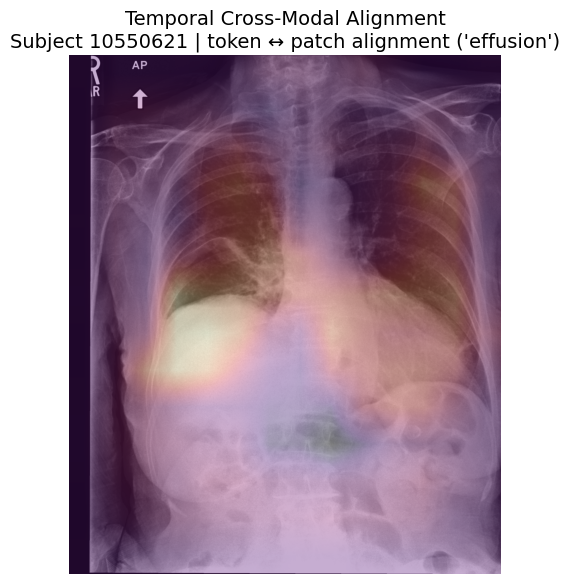

In [88]:
# Temporal cross-modal: show that BioViL-T can align text
# with temporal image features (unique capability)
temporal_cross_modal = plot_random_temporal_cross_modal_alignment_maps(
    temporal_chunk_paths=temporal_chunk_paths,
    num_samples=3,
    seed=42,
    token_query="effusion",
    normalize=True,
    patch_proj_key="current_patch_proj",
)

## Faithfulness

In [89]:
EVAL_PATHOLOGIES = ["Cardiomegaly", "Pleural Effusion", "Pneumothorax"]
SAVE_DIR = OUTPUT_ROOT / "faithfulness"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

In [90]:
cf_ctx = init_biovilt_counterfactuals()
model = cf_ctx["model"]
tokenizer = cf_ctx["tokenizer"]
image_processor = cf_ctx["image_processor"]
device = cf_ctx["device"]

matched_single_samples = build_matched_single_samples(single_samples)
matched_temporal_samples = build_matched_temporal_samples(temporal_samples)

/home/links/mtm211/.conda/envs/biovil_env/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of the model checkpoint at microsoft/BiomedVLP-BioViL-T were not used when initializing CXRBertModel: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing CXRBertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing CXRBertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Temporal pooler found: <class 'models.biovil_t.transformer.VisionTransformerPooler'>


Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


,subject_id,study_id,ig_delta
0,12410764,55151770,0.040073
1,10541043,50169121,-0.024454
2,16199548,51470102,0.124668
3,15514336,56866308,-0.001824
4,15020654,54698051,0.000626
5,13058887,56665046,-0.062122
6,12196601,53711044,0.080293
7,19050905,58044544,0.040704
8,11885477,50827723,0.016983
9,12376697,58910139,-0.073847


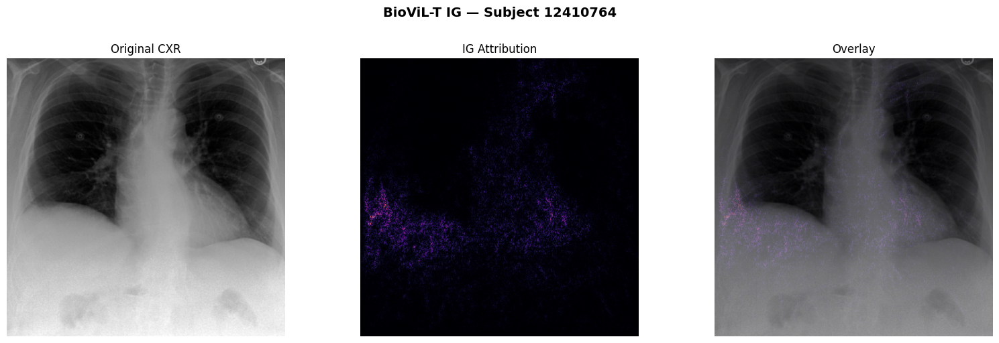

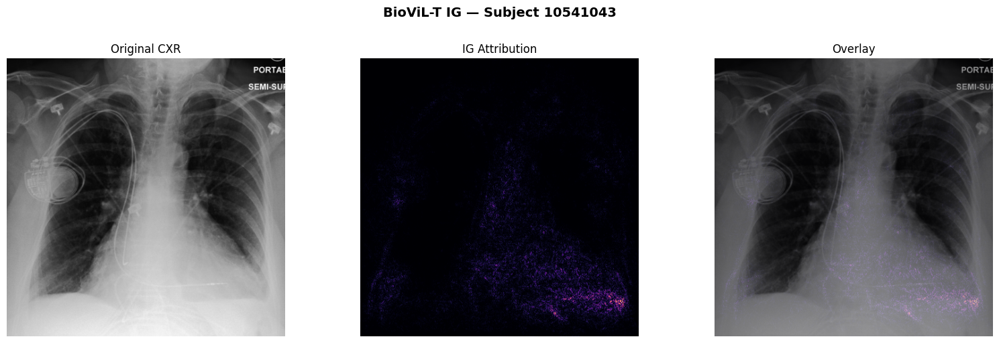

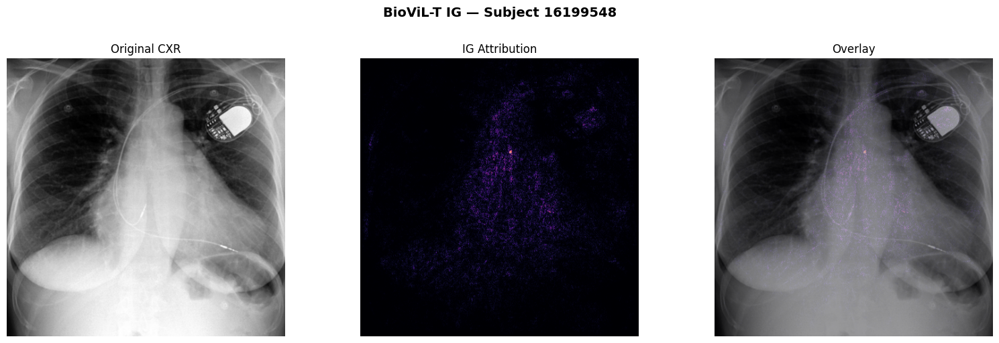

In [91]:
# ============================================================
# A. BioViL-T Integrated Gradients
# ============================================================
biovil_ig_df, biovil_ig_results = run_biovilt_integrated_gradients(
    model=model,
    tokenizer=tokenizer,
    image_loader=load_grayscale_image_tensor,
    matched_samples=matched_single_samples,
    num_samples=10,
    seed=42,
    n_steps=50,
    image_loader_kwargs={"image_processor": image_processor},
)
display(biovil_ig_df)

for i, r in enumerate(biovil_ig_results[:3]):
    plot_ig_result(
        r["image_tensor"], r["heatmap"],
        title=f"BioViL-T IG — Subject {r['sample']['metadata'].get('subject_id', 'N/A')}",
        save_path=str(SAVE_DIR / f"biovil_t_ig_{i}.png"),
    )

,subject_id,label,ig_delta
0,tensor(19858208),Cardiomegaly,-0.007171
1,tensor(11665864),Cardiomegaly,-0.027161
2,tensor(10380837),Cardiomegaly,-0.026384
3,tensor(14642362),Cardiomegaly,0.026043
4,tensor(14092441),Cardiomegaly,-0.019565


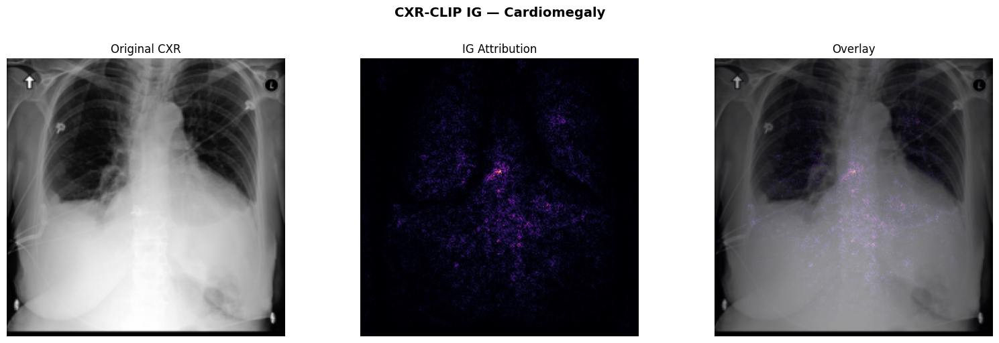

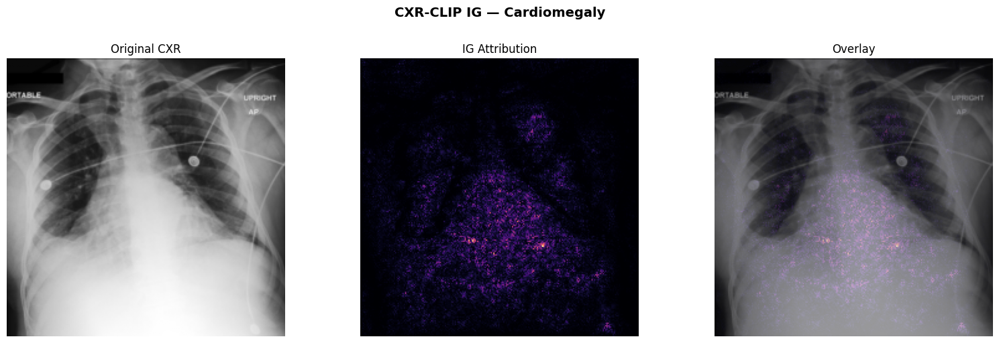

,subject_id,label,ig_delta
0,tensor(18439312),Pleural Effusion,0.002741
1,tensor(11476787),Pleural Effusion,0.010936
2,tensor(10348831),Pleural Effusion,0.006128
3,tensor(19777120),Pleural Effusion,-0.014793
4,tensor(13296814),Pleural Effusion,0.010696


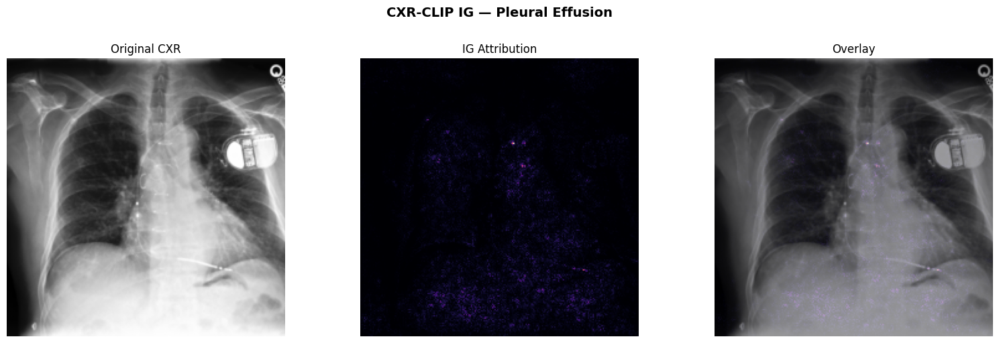

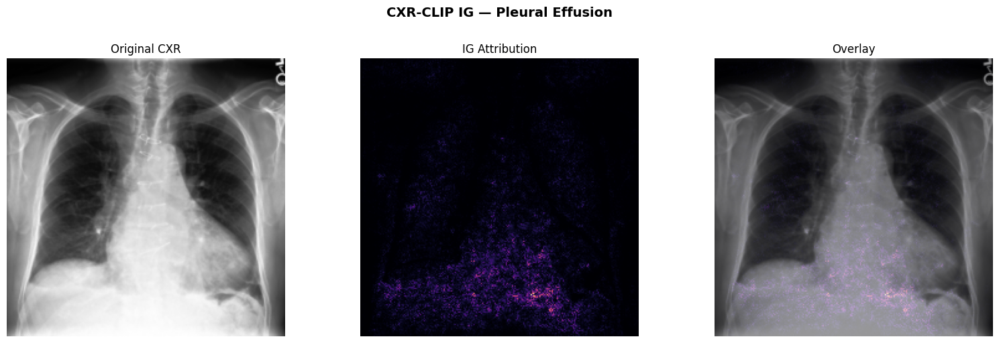

,subject_id,label,ig_delta
0,tensor(16883904),Pneumothorax,0.007331
1,tensor(10979566),Pneumothorax,0.017184
2,tensor(10242353),Pneumothorax,0.003450
3,tensor(17919687),Pneumothorax,-0.003358
4,tensor(12948096),Pneumothorax,0.013552


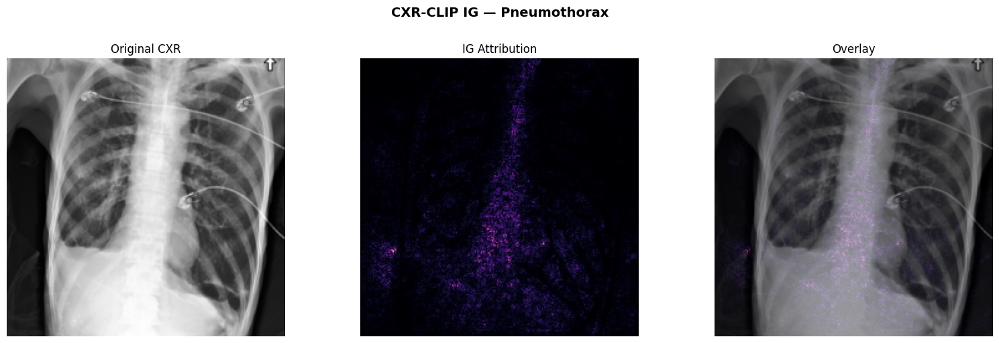

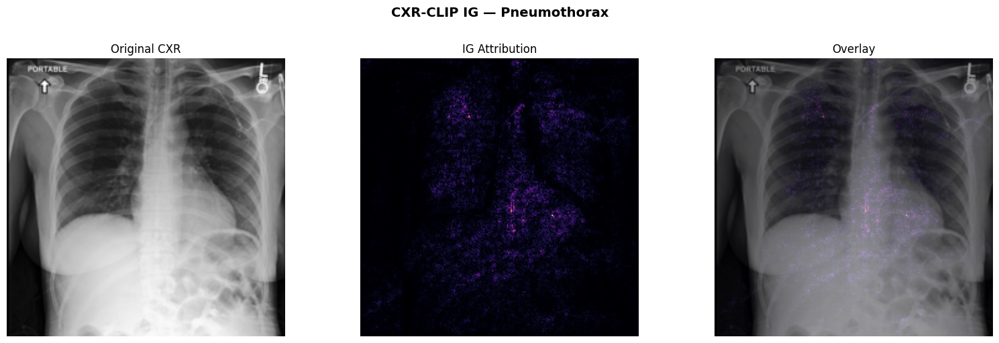

In [92]:
# ============================================================
# B. CXR-CLIP Integrated Gradients
# ============================================================
for label in EVAL_PATHOLOGIES:
    cxr_ig_df, cxr_ig_results = run_cxr_clip_integrated_gradients(
        pipeline=pipeline,
        test_df=results["test_df"],
        cxr_clip_samples=cxr_clip_samples,
        label=label,
        num_samples=5,
        seed=42,
        n_steps=50,
    )
    display(cxr_ig_df)

    for i, r in enumerate(cxr_ig_results[:2]):
        plot_ig_result(
            r["image_tensor"], r["heatmap"],
            title=f"CXR-CLIP IG — {label}",
            save_path=str(SAVE_DIR / f"cxr_clip_ig_{label.lower().replace(' ', '_')}_{i}.png"),
        )


In [93]:
print([name for name, _ in pipeline["model"].named_children()])
print(hasattr(pipeline["model"], "image_projection"))
print(type(pipeline["model"].image_projection))

['image_encoder', 'text_encoder', 'image_projection', 'text_projection']
True
<class 'cxrclip.model.modules.projection.LinearProjectionHead'>


In [94]:
# ============================================================
# C. BioViL-T Heatmap Faithfulness (cross-modal attention)
# ============================================================
def biovil_cross_modal_heatmap_builder(sample, image_tensor, model, tokenizer, **kwargs):
    """Build heatmap from precomputed patch projections."""
    patch_proj = sample["image_patch_proj"].float()
    text_emb = sample["text_emb"].float()
    patch_emb = patch_proj / patch_proj.norm(dim=-1, keepdim=True).clamp_min(1e-8)
    query = text_emb / text_emb.norm(dim=-1, keepdim=True).clamp_min(1e-8)
    sim = patch_emb @ query
    grid_size = int(sim.numel() ** 0.5)
    heat = sim.view(grid_size, grid_size).detach().cpu()
    from evaluation.faithfulness import normalize_heatmap
    return normalize_heatmap(heat)

biovil_faith_df, biovil_faith_results = run_biovilt_faithfulness(
    model=model,
    tokenizer=tokenizer,
    image_loader=load_grayscale_image_tensor,
    matched_samples=matched_single_samples,
    heatmap_builder=biovil_cross_modal_heatmap_builder,
    method_name="BioViL-T Cross-Modal",
    num_samples=15,
    seed=42,
    image_loader_kwargs={"image_processor": image_processor},
)
display(biovil_faith_df)

,subject_id,study_id,method,deletion_auc,insertion_auc,saliency_mask_drop,random_mask_drop,saliency_blur_drop,random_blur_drop,mask_beats_random,blur_beats_random
0,12410764,55151770,BioViL-T Cross-Modal,0.152039,0.210033,0.124798,0.275771,0.578111,-0.079963,False,True
1,10541043,50169121,BioViL-T Cross-Modal,0.004335,0.444914,0.560409,0.768167,0.832141,0.022614,False,True
2,16199548,51470102,BioViL-T Cross-Modal,-0.021824,0.347352,0.819241,1.055010,1.090896,-0.019852,False,True
3,15514336,56866308,BioViL-T Cross-Modal,-0.174173,0.177587,0.876628,0.779969,0.802035,0.150411,True,True
4,15020654,54698051,BioViL-T Cross-Modal,0.047283,0.469683,0.504885,0.852974,-0.070074,0.066137,False,False
5,13058887,56665046,BioViL-T Cross-Modal,0.003206,0.469080,0.653237,0.700026,-0.187380,0.083263,False,False
6,12196601,53711044,BioViL-T Cross-Modal,0.053846,0.477553,0.580084,0.915524,0.541208,0.367849,False,True
7,19050905,58044544,BioViL-T Cross-Modal,0.187857,0.673366,0.566170,0.777081,0.240303,0.121273,False,True
8,11885477,50827723,BioViL-T Cross-Modal,-0.021271,0.314203,0.833741,0.996359,0.377644,0.037858,False,True
9,12376697,58910139,BioViL-T Cross-Modal,-0.065994,0.698201,0.668253,1.158763,0.586701,0.021279,False,True


In [95]:
# ============================================================
# D. CXR-CLIP Heatmap Faithfulness (similarity relevance)
# ============================================================
def cxr_clip_sim_heatmap_builder(pipeline, image_tensor, label, **kwargs):
    hmap = generate_similarity_relevance_map(
        pipeline=pipeline, image_tensor=image_tensor, label=label, use_margin=True,
    )
    return torch.tensor(hmap, dtype=torch.float32)

all_cxr_clip_faith = []
for label in EVAL_PATHOLOGIES:
    cxr_faith_df, cxr_faith_results = run_cxr_clip_faithfulness(
        pipeline=pipeline,
        test_df=results["test_df"],
        cxr_clip_samples=cxr_clip_samples,
        label=label,
        method_name=f"CXR-CLIP Sim ({label})",
        heatmap_builder=cxr_clip_sim_heatmap_builder,
        num_samples=10,
        seed=42,
    )
    all_cxr_clip_faith.append(cxr_faith_df)
    display(cxr_faith_df)

cxr_clip_faith_combined = pd.concat(all_cxr_clip_faith, ignore_index=True)
cxr_clip_faith_combined["method"] = "CXR-CLIP Similarity"

,subject_id,label,method,deletion_auc,insertion_auc,saliency_mask_drop,random_mask_drop,saliency_blur_drop,random_blur_drop,mask_beats_random,blur_beats_random
0,tensor(19858208),Cardiomegaly,CXR-CLIP Sim (Cardiomegaly),0.061025,0.219969,0.138723,0.184873,0.011173,0.125801,False,False
1,tensor(11665864),Cardiomegaly,CXR-CLIP Sim (Cardiomegaly),0.063860,0.248007,0.069858,0.129555,-0.074113,0.071967,False,False
2,tensor(10380837),Cardiomegaly,CXR-CLIP Sim (Cardiomegaly),0.100632,0.263409,0.136139,0.260084,-0.045305,0.208620,False,False
3,tensor(14642362),Cardiomegaly,CXR-CLIP Sim (Cardiomegaly),-0.163004,0.132616,0.208288,0.016056,-0.004729,0.052013,True,False
4,tensor(14092441),Cardiomegaly,CXR-CLIP Sim (Cardiomegaly),0.019110,0.109317,0.004847,0.034054,0.041225,0.106946,False,False
5,tensor(13707062),Cardiomegaly,CXR-CLIP Sim (Cardiomegaly),0.046526,0.303309,0.185271,0.264273,0.057356,0.110955,False,False
6,tensor(13356814),Cardiomegaly,CXR-CLIP Sim (Cardiomegaly),0.062176,0.147270,0.051643,0.048605,-0.143753,0.016672,True,False
7,tensor(11990968),Cardiomegaly,CXR-CLIP Sim (Cardiomegaly),0.037551,0.222003,0.185138,0.150769,-0.076887,0.117929,True,False
8,tensor(10149287),Cardiomegaly,CXR-CLIP Sim (Cardiomegaly),-0.108407,0.161552,0.302105,0.102729,0.146968,0.088390,True,True
9,tensor(11560685),Cardiomegaly,CXR-CLIP Sim (Cardiomegaly),-0.067734,0.129659,0.067948,0.027612,-0.027314,0.015862,True,False


,subject_id,label,method,deletion_auc,insertion_auc,saliency_mask_drop,random_mask_drop,saliency_blur_drop,random_blur_drop,mask_beats_random,blur_beats_random
0,tensor(18439312),Pleural Effusion,CXR-CLIP Sim (Pleural Effusion),-0.169880,0.059477,-0.009863,-0.140493,0.011561,-0.180694,True,True
1,tensor(11476787),Pleural Effusion,CXR-CLIP Sim (Pleural Effusion),0.001826,0.077793,0.070340,0.066039,0.100782,-0.041036,True,True
2,tensor(10348831),Pleural Effusion,CXR-CLIP Sim (Pleural Effusion),-0.073009,0.063595,0.003331,-0.047826,0.006387,-0.047511,True,True
3,tensor(19777120),Pleural Effusion,CXR-CLIP Sim (Pleural Effusion),-0.044809,0.071337,-0.061232,-0.034790,0.042161,-0.135996,False,True
4,tensor(13296814),Pleural Effusion,CXR-CLIP Sim (Pleural Effusion),-0.159046,0.010269,0.025564,-0.109659,0.043976,-0.277322,True,True
5,tensor(12989304),Pleural Effusion,CXR-CLIP Sim (Pleural Effusion),-0.102329,0.078915,0.095500,-0.016192,0.096429,-0.106504,True,True
6,tensor(12766096),Pleural Effusion,CXR-CLIP Sim (Pleural Effusion),-0.126597,0.097255,0.068721,-0.043481,0.058960,-0.152603,True,True
7,tensor(11724294),Pleural Effusion,CXR-CLIP Sim (Pleural Effusion),-0.056940,0.014972,0.049189,-0.013475,-0.005719,-0.125691,True,True
8,tensor(19699616),Pleural Effusion,CXR-CLIP Sim (Pleural Effusion),-0.004339,0.138641,0.053471,0.069394,0.099609,-0.018157,False,True
9,tensor(11281825),Pleural Effusion,CXR-CLIP Sim (Pleural Effusion),-0.059203,0.057345,0.008945,-0.034107,0.050330,-0.115133,True,True


,subject_id,label,method,deletion_auc,insertion_auc,saliency_mask_drop,random_mask_drop,saliency_blur_drop,random_blur_drop,mask_beats_random,blur_beats_random
0,tensor(16883904),Pneumothorax,CXR-CLIP Sim (Pneumothorax),0.016371,0.050714,0.064160,0.043310,0.051429,-0.010382,True,True
1,tensor(10979566),Pneumothorax,CXR-CLIP Sim (Pneumothorax),-0.034793,0.026054,0.000550,-0.054195,0.009112,-0.044270,True,True
2,tensor(10242353),Pneumothorax,CXR-CLIP Sim (Pneumothorax),-0.043948,0.062112,0.083029,0.068623,0.038748,0.055686,True,False
3,tensor(17919687),Pneumothorax,CXR-CLIP Sim (Pneumothorax),0.034836,0.114209,0.053040,0.079912,0.072487,0.071943,False,True
4,tensor(12948096),Pneumothorax,CXR-CLIP Sim (Pneumothorax),0.004915,0.118893,0.083331,0.100438,0.066475,0.079282,False,False
5,tensor(12544783),Pneumothorax,CXR-CLIP Sim (Pneumothorax),0.009771,0.073114,0.063122,0.092004,0.022260,0.019317,False,True
6,tensor(12112476),Pneumothorax,CXR-CLIP Sim (Pneumothorax),-0.032209,0.106387,0.091741,0.072322,0.076600,0.077898,True,False
7,tensor(11272213),Pneumothorax,CXR-CLIP Sim (Pneumothorax),-0.002528,0.093477,0.065172,0.069426,0.048249,0.037734,False,True
8,tensor(17763712),Pneumothorax,CXR-CLIP Sim (Pneumothorax),0.010890,0.059998,0.045566,0.055543,0.015282,0.042478,False,False
9,tensor(10920214),Pneumothorax,CXR-CLIP Sim (Pneumothorax),-0.034251,0.013088,0.066942,-0.026025,-0.019665,-0.009183,True,False


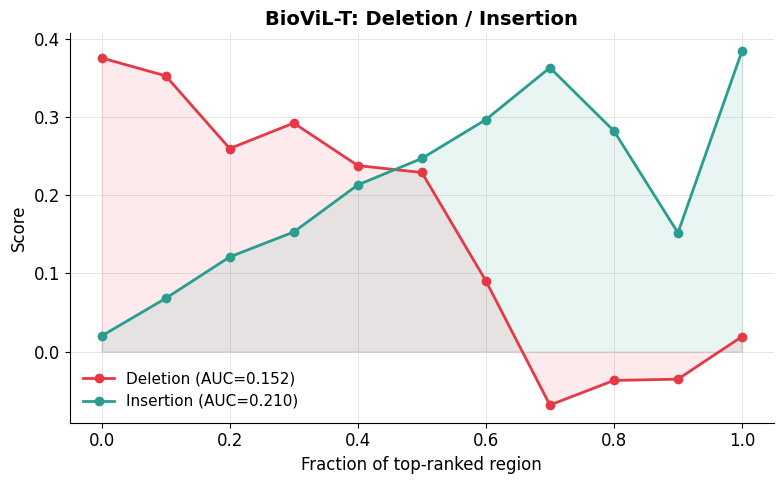

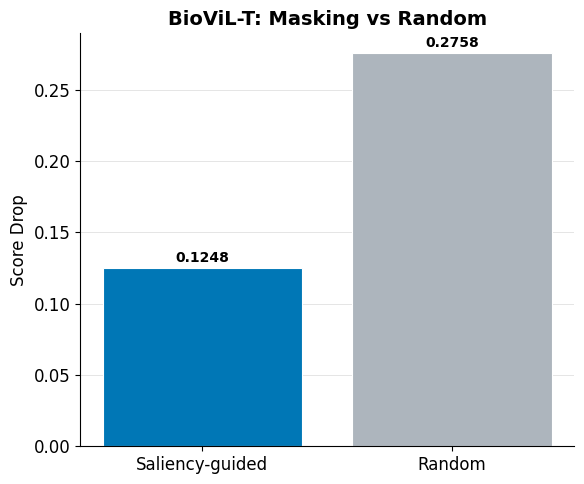

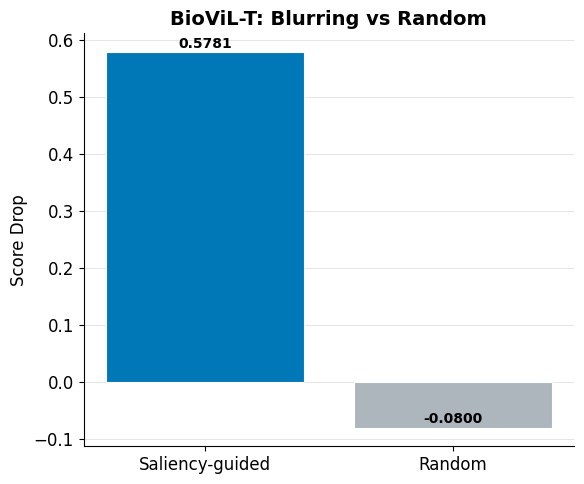

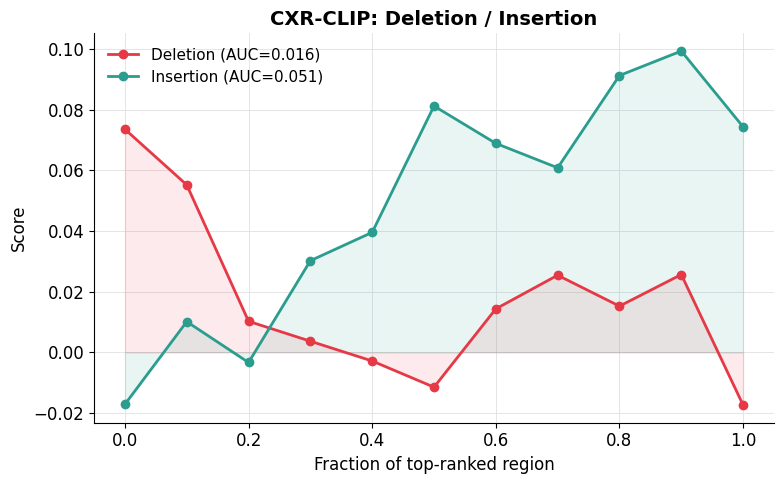

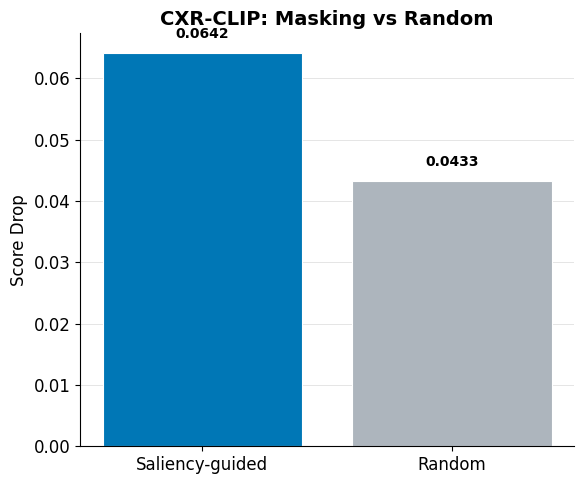

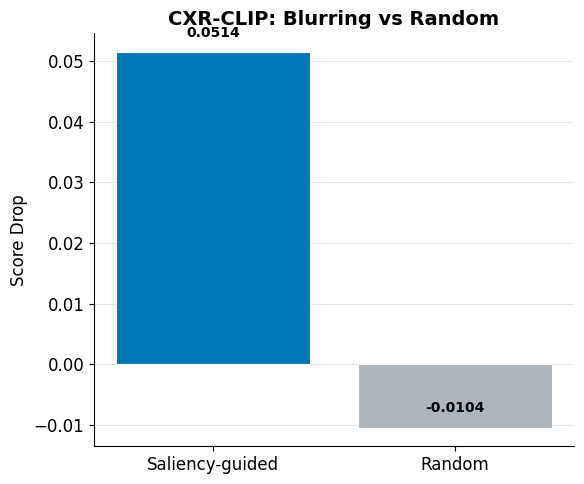

In [96]:
# ============================================================
# E. Per-sample visualisations
# ============================================================
# BioViL-T example
r = biovil_faith_results[0]
plot_deletion_insertion(
    r["faithfulness"]["deletion_result"],
    title="BioViL-T: Deletion / Insertion",
    save_path=str(SAVE_DIR / "biovil_t_deletion_insertion.png"),
)
plot_masking_comparison(
    r["faithfulness"]["masking_result"],
    title="BioViL-T: Masking vs Random",
    save_path=str(SAVE_DIR / "biovil_t_masking_vs_random.png"),
)
plot_masking_comparison(
    r["faithfulness"]["blurring_result"],
    title="BioViL-T: Blurring vs Random",
    save_path=str(SAVE_DIR / "biovil_t_blurring_vs_random.png"),
)

# CXR-CLIP example
r2 = cxr_faith_results[0]
plot_deletion_insertion(
    r2["faithfulness"]["deletion_result"],
    title="CXR-CLIP: Deletion / Insertion",
    save_path=str(SAVE_DIR / "cxr_clip_deletion_insertion.png"),
)
plot_masking_comparison(
    r2["faithfulness"]["masking_result"],
    title="CXR-CLIP: Masking vs Random",
    save_path=str(SAVE_DIR / "cxr_clip_masking_vs_random.png"),
)
plot_masking_comparison(
    r2["faithfulness"]["blurring_result"],
    title="CXR-CLIP: Blurring vs Random",
    save_path=str(SAVE_DIR / "cxr_clip_blurring_vs_random.png"),
)

,method,deletion_auc,insertion_auc,saliency_mask_drop,random_mask_drop,saliency_blur_drop,random_blur_drop,mask_beats_random,blur_beats_random
0,BioViL-T Cross-Modal,0.028129,0.416274,0.602256,0.812118,0.498911,0.064922,0.066667,0.866667


,method,deletion_auc,insertion_auc,saliency_mask_drop,random_mask_drop,saliency_blur_drop,random_blur_drop,mask_beats_random,blur_beats_random
0,CXR-CLIP Similarity,-0.027118,0.110825,0.075686,0.047179,0.025669,0.001167,0.6,0.533333


Saved: outputs/run_20260429_012236/faithfulness/faithfulness_comparison_table.png


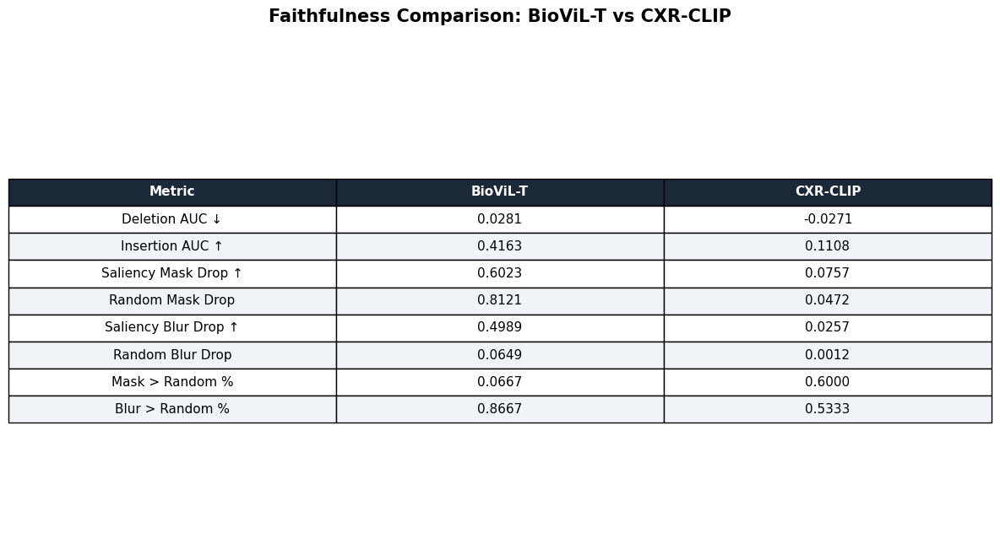

,Metric,BioViL-T,CXR-CLIP
0,Deletion AUC ↓,0.0281,-0.0271
1,Insertion AUC ↑,0.4163,0.1108
2,Saliency Mask Drop ↑,0.6023,0.0757
3,Random Mask Drop,0.8121,0.0472
4,Saliency Blur Drop ↑,0.4989,0.0257
5,Random Blur Drop,0.0649,0.0012
6,Mask > Random %,0.0667,0.6000
7,Blur > Random %,0.8667,0.5333


In [97]:
# ============================================================
# F. Comparison summary table
# ============================================================
biovil_summary = summarize_faithfulness(biovil_faith_df)
cxr_clip_summary = summarize_faithfulness(cxr_clip_faith_combined)

display(biovil_summary)
display(cxr_clip_summary)

plot_faithfulness_comparison_table(
    biovil_summary_df=biovil_summary,
    cxr_clip_summary_df=cxr_clip_summary,
    title="Faithfulness Comparison: BioViL-T vs CXR-CLIP",
    save_path=str(SAVE_DIR / "faithfulness_comparison_table.png"),
)

## Clinical Plausibility (CP)

In [98]:
EVAL_PATHOLOGIES = ["Cardiomegaly", "Pleural Effusion", "Pneumothorax"]
SAVE_DIR = OUTPUT_ROOT / "clinical_plausibility"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

In [99]:
# ============================================================
# A. BioViL-T: Artefact checks on cross-modal attention heatmaps
# ============================================================
biovil_heatmaps = []
biovil_sample_ids = []
biovil_panel_data = []

for s in matched_single_samples[:60]:
    patch_proj = s["image_patch_proj"].float()
    text_emb = s["text_emb"].float()
    patch_emb = patch_proj / patch_proj.norm(dim=-1, keepdim=True).clamp_min(1e-8)
    query = text_emb / text_emb.norm(dim=-1, keepdim=True).clamp_min(1e-8)
    sim = patch_emb @ query
    grid_size = int(sim.numel() ** 0.5)
    heat = sim.view(grid_size, grid_size).detach().cpu()
    heat = heat - heat.min()
    heat = heat / (heat.max() + 1e-8)

    biovil_heatmaps.append(heat)
    biovil_sample_ids.append(str(s["metadata"].get("subject_id", "N/A")))
    
    positives = [k for k, v in (s.get("labels") or {}).items() if float(v) == 1.0]
    biovil_panel_data.append({
        "image_path": s["metadata"]["image_path"],
        "heatmap": heat,
        "ground_truth": positives,
    })

biovil_artefact_df = evaluate_artefact_checks_batch(
    heatmaps=biovil_heatmaps,
    sample_ids=biovil_sample_ids,
    method_name="BioViL-T Cross-Modal",
)
biovil_artefact_summary = summarize_artefact_checks(biovil_artefact_df)
display(biovil_artefact_summary)


,Check,Pass Rate,Passed,Total
0,border_focus,96.7%,58,60
1,rib_overfocus,100.0%,60,60
2,centre_bias,0.0%,0,60
3,activation_spread,100.0%,60,60


Saved: outputs/run_20260429_012236/clinical_plausibility/biovil_t_artefact_summary.png


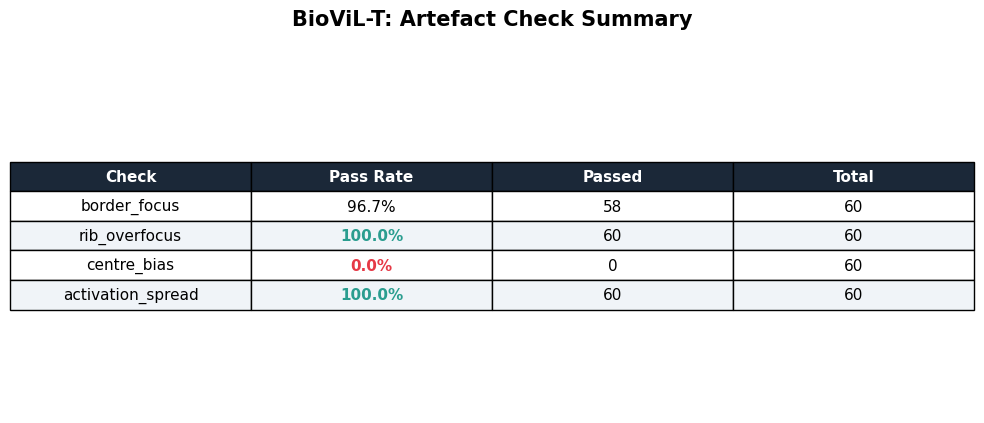

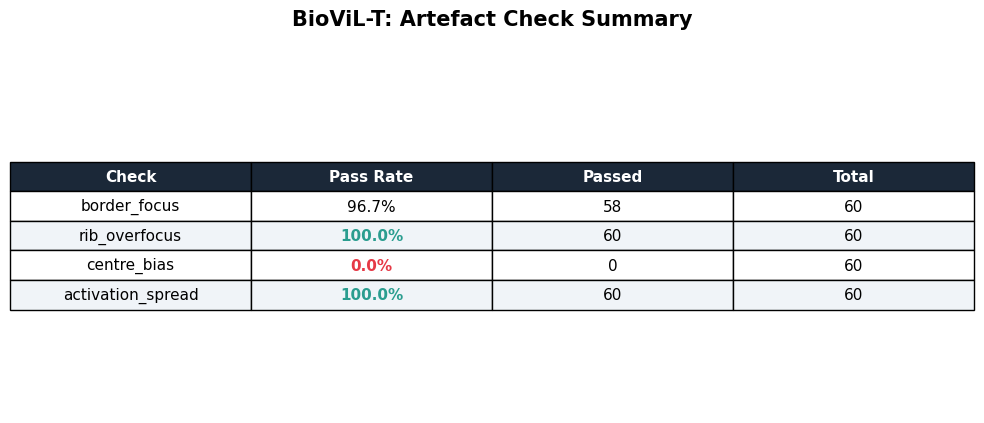

In [100]:
plot_artefact_summary_table(
    biovil_artefact_summary,
    title="BioViL-T: Artefact Check Summary",
    save_path=str(SAVE_DIR / "biovil_t_artefact_summary.png"),
)

In [101]:
# ============================================================
# B. CXR-CLIP: Artefact checks on similarity relevance heatmaps
# ============================================================
cxr_clip_heatmaps = []
cxr_clip_sample_ids = []
cxr_clip_panel_data = []

test_df = results["test_df"]

for label in EVAL_PATHOLOGIES:
    pos_samples = [s for s in cxr_clip_samples if s["labels"].get(label, 0) == 1.0][:20]

    for s in pos_samples:
        img_path = s["metadata"]["image_path"]
        sample_df = test_df[test_df["image_path"] == img_path].reset_index(drop=True)
        if len(sample_df) == 0:
            continue

        dataset = CXRClipInferenceDataset(sample_df, transform=pipeline["preprocess"])
        sample = dataset[0]

        heatmap = generate_similarity_relevance_map(
            pipeline=pipeline,
            image_tensor=sample["image"],
            label=label,
            use_margin=True,
        )
        heat = torch.tensor(heatmap, dtype=torch.float32)

        cxr_clip_heatmaps.append(heat)
        cxr_clip_sample_ids.append(str(s["metadata"].get("subject_id", "N/A")))
        
        positives = [k for k, v in s["labels"].items() if float(v) == 1.0]
        cxr_clip_panel_data.append({
            "image_path": img_path,
            "heatmap": heat,
            "ground_truth": positives,
            "label": label,
        })

cxr_clip_artefact_df = evaluate_artefact_checks_batch(
    heatmaps=cxr_clip_heatmaps,
    sample_ids=cxr_clip_sample_ids,
    method_name="CXR-CLIP Similarity",
)
cxr_clip_artefact_summary = summarize_artefact_checks(cxr_clip_artefact_df)
display(cxr_clip_artefact_summary)

,Check,Pass Rate,Passed,Total
0,border_focus,61.7%,37,60
1,rib_overfocus,100.0%,60,60
2,centre_bias,0.0%,0,60
3,activation_spread,98.3%,59,60


Saved: outputs/run_20260429_012236/clinical_plausibility/cxr_clip_artefact_summary.png


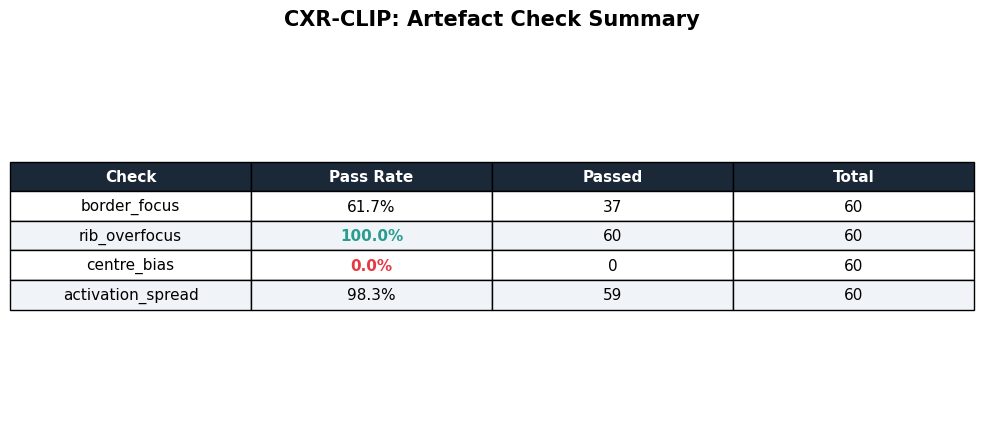

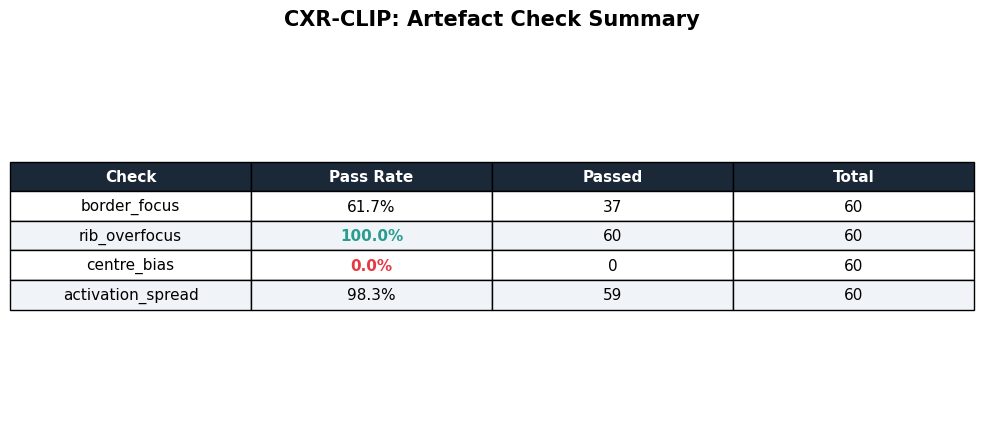

In [102]:
plot_artefact_summary_table(
    cxr_clip_artefact_summary,
    title="CXR-CLIP: Artefact Check Summary",
    save_path=str(SAVE_DIR / "cxr_clip_artefact_summary.png"),
)

Saved: outputs/run_20260429_012236/clinical_plausibility/artefact_comparison.png


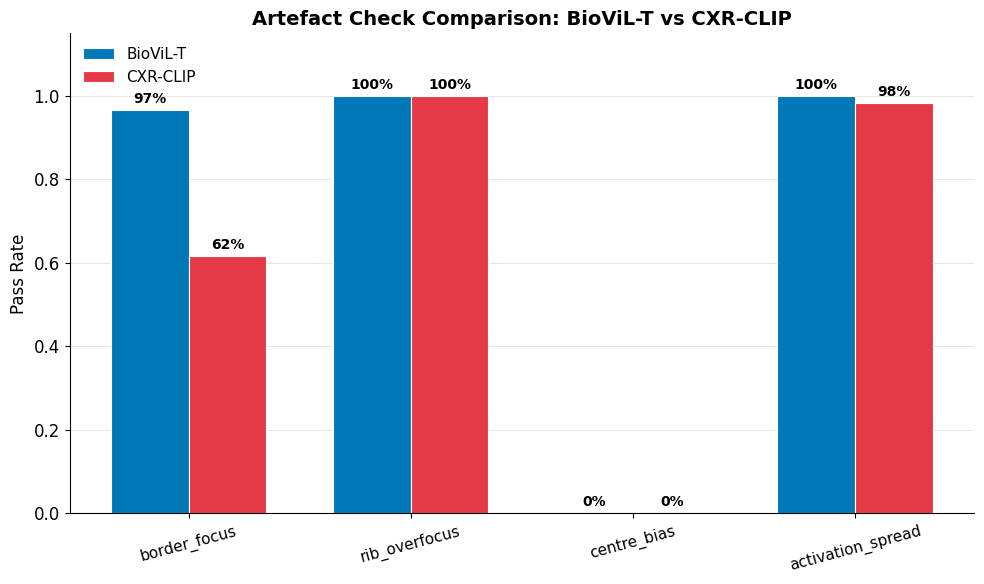

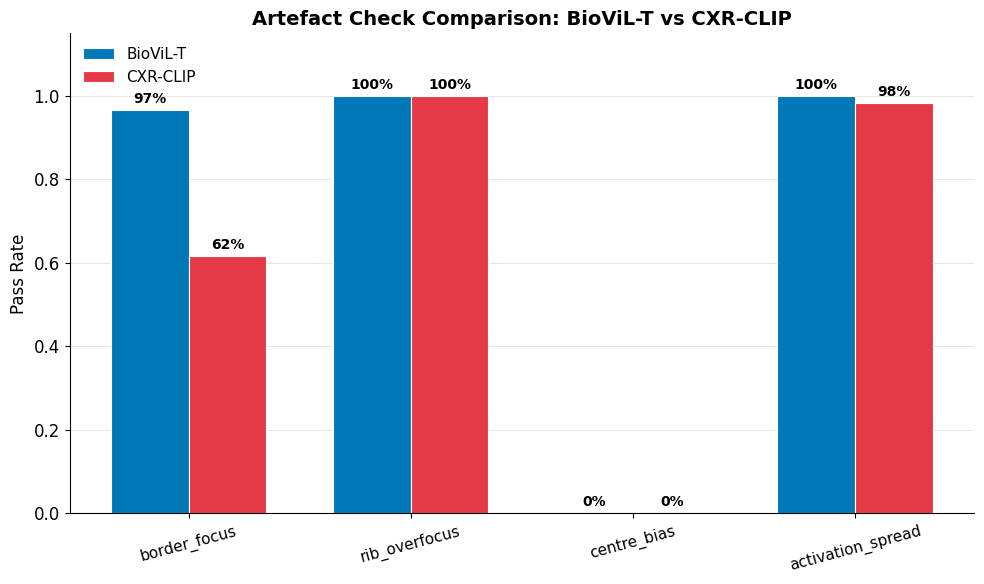

In [103]:
# ============================================================
# C. Comparison
# ============================================================
plot_artefact_comparison(
    biovil_summary=biovil_artefact_summary,
    cxr_clip_summary=cxr_clip_artefact_summary,
    title="Artefact Check Comparison: BioViL-T vs CXR-CLIP",
    save_path=str(SAVE_DIR / "artefact_comparison.png"),
)

Saved: outputs/run_20260429_012236/clinical_plausibility/biovil_t_panel_0.png


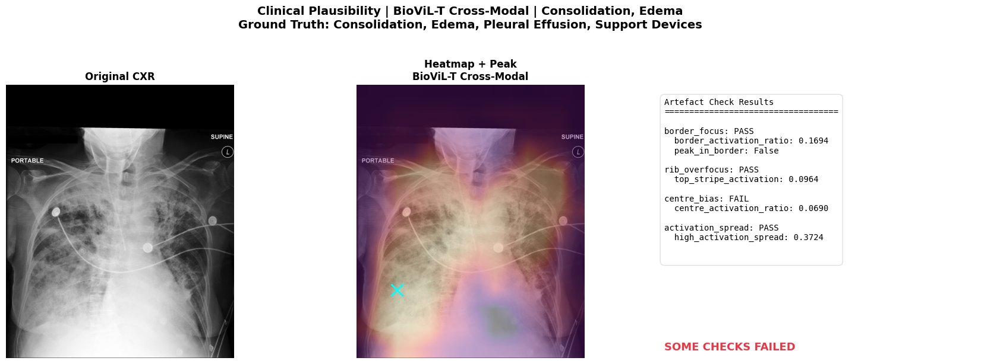

Saved: outputs/run_20260429_012236/clinical_plausibility/biovil_t_panel_1.png


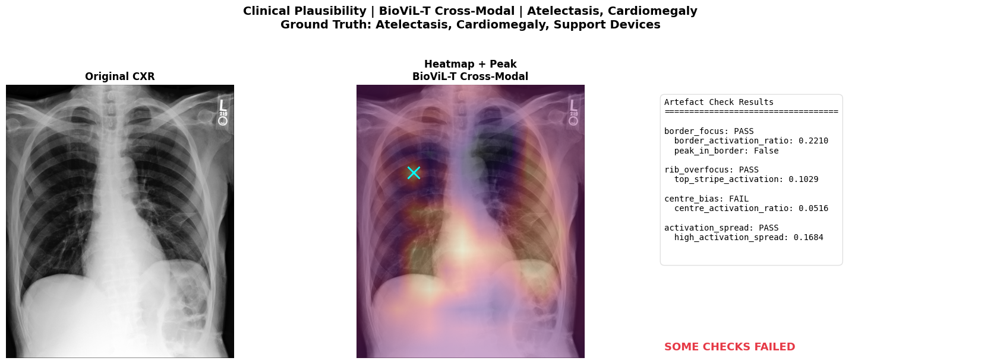

Saved: outputs/run_20260429_012236/clinical_plausibility/biovil_t_panel_2.png


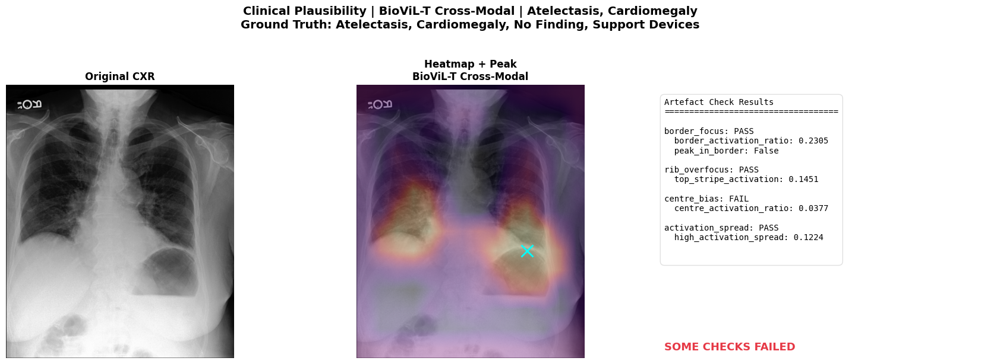

In [104]:
# ============================================================
# D. Qualitative inspection panels (3 per model)
# ============================================================
rng = random.Random(42)

# BioViL-T panels
for i, data in enumerate(rng.sample(biovil_panel_data, min(3, len(biovil_panel_data)))):
    checks = run_all_artefact_checks(data["heatmap"])
    plot_clinical_plausibility_panel(
        image_path=data["image_path"],
        heatmap=data["heatmap"],
        artefact_results=checks,
        method_name="BioViL-T Cross-Modal",
        pathology=", ".join(data["ground_truth"][:2]),
        ground_truth=data["ground_truth"],
        save_path=str(SAVE_DIR / f"biovil_t_panel_{i}.png"),
    )


Saved: outputs/run_20260429_012236/clinical_plausibility/cxr_clip_panel_0.png


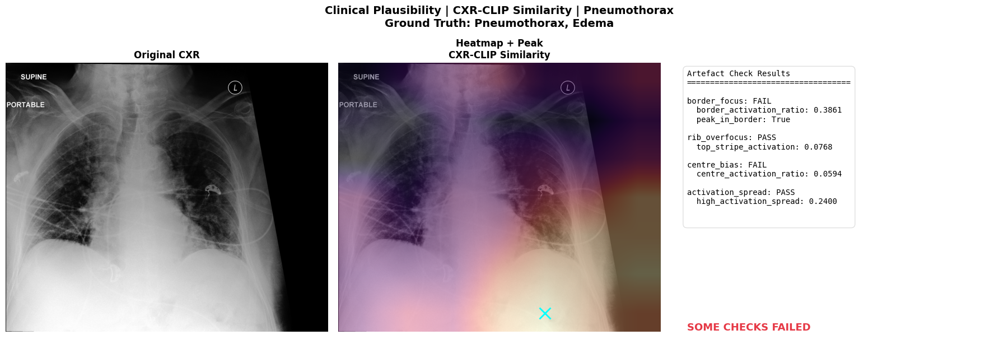

Saved: outputs/run_20260429_012236/clinical_plausibility/cxr_clip_panel_1.png


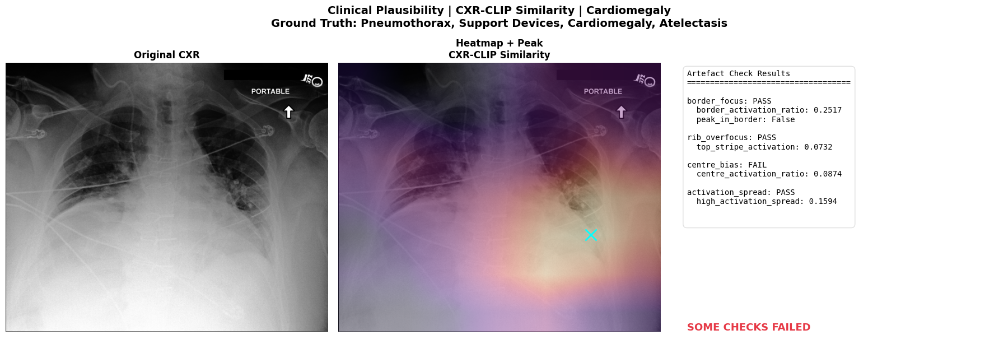

Saved: outputs/run_20260429_012236/clinical_plausibility/cxr_clip_panel_2.png


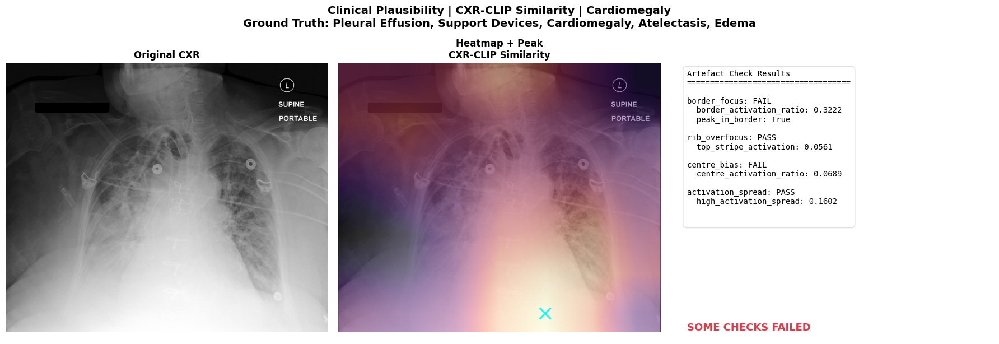

In [105]:
# CXR-CLIP panels
for i, data in enumerate(rng.sample(cxr_clip_panel_data, min(3, len(cxr_clip_panel_data)))):
    checks = run_all_artefact_checks(data["heatmap"])
    plot_clinical_plausibility_panel(
        image_path=data["image_path"],
        heatmap=data["heatmap"],
        artefact_results=checks,
        method_name="CXR-CLIP Similarity",
        pathology=data.get("label", ""),
        ground_truth=data["ground_truth"],
        save_path=str(SAVE_DIR / f"cxr_clip_panel_{i}.png"),
    )
